# Predicting Firm Profitability from ΓΕΜΗ Panel Data
Next-year ROA of Greek SMEs. Part I: forecastability against a ladder of persistence and ROA-history benchmarks. Part II: data quality and selection.

## 1. Environment, Configuration and Analysis Plan
Feature-year split: train ≤ 2022, validation 2023, test 2024 (descriptive). Primary evidence: nested rolling-origin evaluation, ratios against the ROA history. Plan and results are written to `results/`.

In [1]:
import os, sys, json, warnings, time, re
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

PROJECT_DIR = "."
if os.path.isdir(PROJECT_DIR):
    os.chdir(PROJECT_DIR)
print("Working directory:", os.getcwd())

sns.set_theme(style="ticks", context="paper", font_scale=1.05)
PALETTE = {"blue": "#4C72B0", "green": "#55A868", "red": "#C44E52",
           "purple": "#8172B2", "gold": "#CCB974", "cyan": "#64B5CD"}
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="An input array is constant")
warnings.filterwarnings("ignore", message=".*IProgress.*")
warnings.filterwarnings("ignore", message="X has feature names")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ----------------------------------------------------------------------------
# CENTRAL CONFIG: every path, cutoff and choice lives here
# ----------------------------------------------------------------------------
RAW_CSV = "data/gemi_dataset_2k_final_v4.csv"                       # raw file, never modified
MANUAL_VALIDATION_CSV = "data/manual_validation_sample_completed.csv"
POPULATION_REF_CSV = None      # optional: CSV with columns year, NP, TA for a broader firm population
N_FIRMS = 2000
YEARS = list(range(2016, 2026))
LAST_PANEL_YEAR = max(YEARS)

# Split, expressed in FEATURE years (target year = feature year + 1)
TRAIN_END_YEAR = 2022            # training rows: feature year <= 2022  (targets ROA <= 2023)
VALID_FEATURE_YEAR = 2023        # selection set: feature year 2023      (target ROA 2024)
TEST_FEATURE_YEARS = [2024]      # test set: feature year 2024           (target ROA 2025)
assert all(y + 1 <= LAST_PANEL_YEAR for y in TEST_FEATURE_YEARS), \
    "A test feature year needs a realised year+1 target inside the panel."
assert TRAIN_END_YEAR < VALID_FEATURE_YEAR < min(TEST_FEATURE_YEARS)

TARGET_RAW = "ROA_t1_raw"        # ROA(t+1), TA-floored, not winsorised
TARGET = "ROA_t1"                # ROA(t+1), winsorised at TRAIN-target quantiles (primary target)
TA_FLOOR = 1_000                 # EUR; ROA is undefined below this TA (parsing / shell-company region)
TA_FLOOR_SENSITIVITY = 10_000    # EUR; used by the sensitivity arm in the robustness section
WINSOR_Q = (0.01, 0.99)

# Tuning / selection
CV_VAL_YEARS = [2019, 2020, 2021, 2022]          # expanding-window validation years inside the training period
SEARCH_N_ITER = {"rf": 20, "xgb": 40}
N_JOBS = -1
SELECTION_METRIC = "RMSE"
MIN_CAT_TRAIN = 30                                # categories with fewer training rows are collapsed to "other"

# Inference
BOOT_N = 2000
MIN_DELTA = {"RMSE": 0.005, "MAE": 0.003}         # smallest difference treated as material
CLEAN_TIERS = ["pdfplumber", "manual_verified"]   # extraction tiers treated as machine-readable / verified
EXCLUDE_TIERS = ["scan_unprocessed"]              # tiers dropped from the modelling sample (at year t or t+1)

# Nested rolling-origin evaluation (feature years scored; hyper-parameters tuned only on earlier years)
NESTED_YEARS = [2019, 2020, 2021, 2022, 2023, 2024]
NESTED_INNER_FOLDS = 3
NESTED_SEARCH_N_ITER = 20

# Loss prediction
LOSS_THRESHOLD = 0.0             # a "loss" is ROA(t+1) below this value (raw target)
MIN_DELTA_AUC = 0.01

# Post-stratified manual-validation estimates
MIN_STRATUM_N = 15               # smaller strata are excluded from the weighted estimate and reported as a bound
LOSS_THRESHOLDS = [0.0, -0.05, -0.10]   # loss definitions used in the threshold-sensitivity table

# Disk cache for the expensive steps (hyper-parameter searches and nested predictions). An entry is reused only if the data,
# configuration, feature sets and library versions are unchanged. Bump SEARCH_SPACE_TAG whenever a search space is edited.
RESULTS_DIR = "results"
PRIMARY_HISTORY_SET = "5"         # strictest benchmark for the headline: ROA history of up to five years
USE_CACHE = True
REFRESH_CACHE = False            # True recomputes and overwrites everything
CACHE_DIR = "cache"
CACHE_VERSION = "v9"
SEARCH_SPACE_TAG = "spaces-v1"

# Walk-forward (years are FEATURE years; the forecast target year is the feature year + 1)
WF_YEARS = [2019, 2020, 2021, 2022, 2023, 2024]
ROLLING_WINDOW_YEARS = 3
# COVID and post-COVID windows are defined on TARGET years, because the shock hits the ROA being forecast
COVID_TARGET_YEARS = {2020, 2021}
POST_COVID_TARGET_YEARS = {2022, 2023, 2024, 2025}

PLAN = {
    "target": "ROA(t+1) = NP(t+1)/TA(t+1); winsorised at quantiles of the TRAIN target only",
    "split_feature_years": {"train_end": TRAIN_END_YEAR, "valid": VALID_FEATURE_YEAR, "test": TEST_FEATURE_YEARS},
    "tuning": {"cv": "expanding window by feature year", "cv_val_years": CV_VAL_YEARS, "n_iter": SEARCH_N_ITER},
    "selection": {"set": f"feature year {VALID_FEATURE_YEAR}", "metric": SELECTION_METRIC,
                  "eligible": "tuned models (Ridge / RF / XGBoost, feature sets A and C)"},
    "benchmarks": ["Mean", "Persistence", "AR1", "AR1_LAD", "AR1_SECTOR", "nonlinear ROA-only XGBoost"],
    "primary_benchmark": "AR1",
    "primary_metrics": ["RMSE", "MAE"],
    "min_delta": MIN_DELTA,
    "inference": f"paired bootstrap clustered by firm, {BOOT_N} draws, 95% percentile interval",
    "verdict_rule": "better only if BOTH metrics have CI < 0 and point difference <= -MIN_DELTA",
    "primary_comparisons": ["C vs AR1", "C vs Persistence", "C vs AR1_LAD", "C vs AR1_SECTOR", "C vs R", "A vs AR1", "A vs Mean", "C vs A"],
    "families": {"ENS_C": "tree learners on ratios plus ROA_t", "ENS_A": "tree learners on ratios", "ENS_R": "nonlinear ROA-only learners"},
    "main_evidence": {"nested_rolling_origin": {"years": NESTED_YEARS, "inner_folds": NESTED_INNER_FOLDS, "n_iter": NESTED_SEARCH_N_ITER}},
    "framing_rule": "framing_from(): INCREMENTAL_INFORMATION if C beats AR1 and R on both metrics; SMALL_INCREMENTAL_INFORMATION if C beats AR1 and is better than R "
                    "on both metrics with intervals excluding 0 (at least one difference below MIN_DELTA); NONLINEAR_PERSISTENCE if C beats AR1 but not R; "
                    "RECONSTRUCTED_PERSISTENCE if only A beats Mean; otherwise BOUNDED_PREDICTABILITY",
    "sample_exclusions": {"extraction_tiers": EXCLUDE_TIERS, "applies_to": "feature year t or target year t+1"},
    "restricted_check": "primary comparisons repeated on test rows with an observed ROA_t",
    "primary_evidence": "nested rolling-origin evaluation, ratios against the ROA history (feature sets C5 vs R5); the single test year is descriptive",
    "primary_hypotheses": ["H1 ratios add to the ROA history for the level of next-year ROA (nested, MAE and RMSE)",
                           "H2 ratios add to the ROA history for the loss event (nested, AUC)",
                           "H3 the gain over Persistence is larger where the lag is noisy (nested, clustered CI)",
                           "H4 forecasts hold for firms not seen in training (test year, paired)"],
    "multiple_comparisons": "Holm adjustment of the Diebold-Mariano p-values of the primary comparisons; every other table is descriptive, and effect sizes "
                            "with firm-clustered intervals are reported whatever the p-value",
    "bootstrap_draws": {"paired_delta": BOOT_N, "auc_test_year": 1000, "auc_pooled_clustered": 500},
    "status": "exploratory: the test year was inspected in earlier notebook versions and the design was revised afterwards",
    "test_policy": "test year used once for final scoring; robustness and ablation arms are descriptive and never feed back into selection",
    "created": datetime.now().isoformat(timespec="seconds"),
}
os.makedirs(RESULTS_DIR, exist_ok=True)
with open(os.path.join(RESULTS_DIR, "analysis_plan.json"), "w", encoding="utf-8") as f:
    json.dump(PLAN, f, indent=2, ensure_ascii=False)

print(f"Panel design: {N_FIRMS} firms x {len(YEARS)} years = {N_FIRMS*len(YEARS)} firm-years")
print(f"Train: feature years <= {TRAIN_END_YEAR} (target years <= {TRAIN_END_YEAR+1})")
print(f"Valid: feature year {VALID_FEATURE_YEAR} (target year {VALID_FEATURE_YEAR+1})")
print(f"Test : feature year(s) {TEST_FEATURE_YEARS} (target year(s) {[y+1 for y in TEST_FEATURE_YEARS]})")
print(f"Analysis plan saved to {RESULTS_DIR}/analysis_plan.json")

Working directory: .
Panel design: 2000 firms x 10 years = 20000 firm-years
Train: feature years <= 2022 (target years <= 2023)
Valid: feature year 2023 (target year 2024)
Test : feature year(s) [2024] (target year(s) [2025])
Analysis plan saved to results/analysis_plan.json


### Utilities

In [2]:
from scipy import stats
from scipy.stats import spearmanr, chi2_contingency, kruskal, levene, skew, kurtosis, loguniform, uniform, randint
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, QuantileRegressor, Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor


def value_at_year_offset(df, col, k):
    # Value of `col` for the same firm at year + k (NaN when that firm-year is absent).
    # Explicit merge, so it stays correct for panels with gaps.
    src = df[["gemh_id", "year", col]].copy()
    src["year"] = src["year"] - k
    tag = f"__{col}_at_{k:+d}"
    src = src.rename(columns={col: tag})
    out = df[["gemh_id", "year"]].merge(src, on=["gemh_id", "year"], how="left")
    return out[tag].values


def rmse(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return float(np.sqrt(np.mean((y - p) ** 2)))


def mae(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return float(np.mean(np.abs(y - p)))


def ev(y_true, y_pred, ref_mean, name=None):
    # Full metric set. R2_oos benchmarks against a fixed reference mean (the training mean).
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    err = y_true - y_pred
    rho = np.nan if (np.ptp(y_true) == 0 or np.ptp(y_pred) == 0) else spearmanr(y_true, y_pred)[0]
    out = {
        "RMSE": float(np.sqrt(np.mean(err ** 2))),
        "MAE": float(np.mean(np.abs(err))),
        "MedAE": float(np.median(np.abs(err))),
        "R2": float(r2_score(y_true, y_pred)),
        "R2_oos": float(1 - np.sum(err ** 2) / np.sum((y_true - ref_mean) ** 2)),
        "Spearman": float(rho),
        "SignAcc": float(np.mean(np.sign(y_true) == np.sign(y_pred))),
    }
    return {"Model": name, **out} if name is not None else out


def paired_delta_ci(y, p_model, p_ref, groups, n_boot=BOOT_N, seed=RANDOM_STATE, alpha=0.05):
    # Difference in RMSE and MAE (model minus reference; negative = model better), with a
    # percentile bootstrap interval that resamples FIRMS (clusters), keeping each firm's rows together.
    y, pm, pr = (np.asarray(a, float) for a in (y, p_model, p_ref))
    g = np.asarray(groups)
    ok = np.isfinite(y) & np.isfinite(pm) & np.isfinite(pr)
    codes, uniq = pd.factorize(pd.Series(g[ok]).astype(str))
    G = len(uniq)
    cnt = np.bincount(codes, minlength=G).astype(float)

    def agg(p):
        e = y[ok] - p[ok]
        return (np.bincount(codes, weights=e ** 2, minlength=G),
                np.bincount(codes, weights=np.abs(e), minlength=G))

    sq_m, ab_m = agg(pm)
    sq_r, ab_r = agg(pr)
    n = cnt.sum()
    point = {"RMSE": np.sqrt(sq_m.sum() / n) - np.sqrt(sq_r.sum() / n),
             "MAE": ab_m.sum() / n - ab_r.sum() / n}
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, G, size=(n_boot, G))
    c = cnt[idx].sum(axis=1)
    boot = {"RMSE": np.sqrt(sq_m[idx].sum(axis=1) / c) - np.sqrt(sq_r[idx].sum(axis=1) / c),
            "MAE": ab_m[idx].sum(axis=1) / c - ab_r[idx].sum(axis=1) / c}
    lo_q, hi_q = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {m: (float(point[m]), float(np.percentile(boot[m], lo_q)), float(np.percentile(boot[m], hi_q)))
            for m in ("RMSE", "MAE")}


def metric_label(point, lo, hi, min_delta):
    # better / worse: interval excludes 0 and the difference reaches min_delta.
    # slightly better / slightly worse: interval excludes 0 but the difference is below min_delta.
    if hi < 0 and point <= -min_delta:
        return "better"
    if lo > 0 and point >= min_delta:
        return "worse"
    if hi < 0:
        return "slightly better"
    if lo > 0:
        return "slightly worse"
    if lo > -min_delta and hi < min_delta:
        return "equivalent"          # interval includes 0 and lies inside +/- MIN_DELTA: no effect of material size
    return "indistinguishable"


def verdict(deltas):
    labels = {m: metric_label(*deltas[m], MIN_DELTA[m]) for m in ("RMSE", "MAE")}
    if labels["RMSE"] == labels["MAE"]:
        return labels["RMSE"]
    return f"mixed (RMSE: {labels['RMSE']}, MAE: {labels['MAE']})"


import hashlib, joblib, types


def _sig(*parts):
    h = hashlib.sha256()
    for part in parts:
        h.update(repr(part).encode("utf-8", errors="ignore"))
    return h.hexdigest()[:16]


def cached(name, parts, fn):
    # Compute fn() once and store it on disk; the key covers CACHE_VERSION and every element of `parts`.
    key = _sig(CACHE_VERSION, *parts)
    path = os.path.join(CACHE_DIR, f"{name}_{key}.joblib")
    if USE_CACHE and not REFRESH_CACHE and os.path.exists(path):
        try:
            obj = joblib.load(path)
            print(f"[cache] {name}: loaded")
            return obj
        except Exception as e:
            print(f"[cache] {name}: could not be loaded ({type(e).__name__}), recomputing")
    obj = fn()
    if USE_CACHE:
        os.makedirs(CACHE_DIR, exist_ok=True)
        joblib.dump(obj, path, compress=3)
    return obj


def to_result(search, seconds=None):
    # Compact, picklable stand-in for a fitted search object (keeps only what the notebook uses).
    keep = {k: search.cv_results_[k] for k in ("mean_test_score", "std_test_score", "rank_test_score") if k in search.cv_results_}
    return types.SimpleNamespace(best_estimator_=search.best_estimator_, best_params_=search.best_params_, best_score_=search.best_score_,
                                 best_index_=search.best_index_, cv_results_=keep, seconds=seconds)


def pair_labels(d):
    return {m: metric_label(*d[m], MIN_DELTA[m]) for m in ("RMSE", "MAE")}


def framing_from(d_C_AR1, d_C_R, d_A_Mean=None):
    # Mechanical headline framing from paired differences (each a dict metric -> (point, lo, hi)).
    lr = pair_labels(d_C_R)
    positive = all(l in ("better", "slightly better") for l in lr.values())
    if verdict(d_C_AR1) == "better" and lr["RMSE"] == "better" and lr["MAE"] == "better":
        return "INCREMENTAL_INFORMATION"
    if verdict(d_C_AR1) == "better" and positive:
        return "SMALL_INCREMENTAL_INFORMATION"
    if verdict(d_C_AR1) == "better":
        return "NONLINEAR_PERSISTENCE"
    if d_A_Mean is not None and verdict(d_A_Mean) == "better":
        return "RECONSTRUCTED_PERSISTENCE"
    return "BOUNDED_PREDICTABILITY"


def framing_history(d_C_AR1, d_C_R):
    # Same rule, named for the case where R is a model of the ROA history: a null means the history explains the gain.
    key = framing_from(d_C_AR1, d_C_R)
    return {"INCREMENTAL_INFORMATION": "RATIOS_ADD_BEYOND_HISTORY", "SMALL_INCREMENTAL_INFORMATION": "SMALL_RATIO_CONTRIBUTION_BEYOND_HISTORY",
            "NONLINEAR_PERSISTENCE": "HISTORY_EXPLAINS_GAIN"}.get(key, key)


FRAMING_TEXTS = {
    "INCREMENTAL_INFORMATION": ("The tree learners on ratios plus lagged ROA (family ENS_C) beat both the linear AR(1) benchmark and the "
                                "nonlinear ROA-only family (ENS_R) on both metrics: balance-sheet ratios and firm characteristics add "
                                "out-of-sample information beyond lagged ROA, including its nonlinear use."),
    "SMALL_INCREMENTAL_INFORMATION": ("The family ENS_C beats the linear AR(1) benchmark and is better than the nonlinear ROA-only family on both "
                                      "metrics with intervals that exclude zero, but on at least one metric the difference is below MIN_DELTA: the "
                                      "other predictors add a small but detectable amount of information beyond the nonlinear use of lagged ROA."),
    "NONLINEAR_PERSISTENCE": ("The family ENS_C beats the linear AR(1) benchmark but is not clearly better than the nonlinear ROA-only family: "
                              "the gain comes from a nonlinear use of lagged ROA (for example mean reversion of extreme values), not from "
                              "independent information in the other predictors."),
    "RECONSTRUCTED_PERSISTENCE": ("Ratios alone forecast better than the mean, but once lagged ROA is available the AR(1) benchmark is not "
                                  "beaten: the ratios mostly proxy profit persistence rather than add independent information."),
    "BOUNDED_PREDICTABILITY": ("Out-of-sample predictability of next-year ROA is limited: neither feature set clearly improves on a "
                               "persistence-type benchmark. Measurement noise in TA and NP (Sections 28-29) bounds what any model can achieve."),
}


def gap_diff_ci(d, noisy, clean, groups, n_boot=BOOT_N, seed=RANDOM_STATE):
    # d: per-row loss difference (model minus reference). Returns the mean of d on noisy rows, on clean rows and their difference
    # (noisy minus clean) with a percentile interval from resampling firms as clusters.
    d = np.asarray(d, float)
    noisy, clean = np.asarray(noisy, bool), np.asarray(clean, bool)
    g = np.asarray(groups)
    ok = np.isfinite(d) & (noisy | clean)
    codes, uniq = pd.factorize(pd.Series(g[ok]).astype(str))
    G = len(uniq)
    dn = np.bincount(codes, weights=np.where(noisy[ok], d[ok], 0.0), minlength=G)
    nn = np.bincount(codes, weights=noisy[ok].astype(float), minlength=G)
    dc = np.bincount(codes, weights=np.where(clean[ok], d[ok], 0.0), minlength=G)
    nc = np.bincount(codes, weights=clean[ok].astype(float), minlength=G)
    if nn.sum() == 0 or nc.sum() == 0:
        return dict(noisy=np.nan, clean=np.nan, diff=np.nan, lo=np.nan, hi=np.nan, n_noisy=int(nn.sum()), n_clean=int(nc.sum()))
    point_n, point_c = dn.sum() / nn.sum(), dc.sum() / nc.sum()
    idx = np.random.default_rng(seed).integers(0, G, size=(n_boot, G))
    with np.errstate(divide="ignore", invalid="ignore"):
        boot = dn[idx].sum(1) / nn[idx].sum(1) - dc[idx].sum(1) / nc[idx].sum(1)
    boot = boot[np.isfinite(boot)]
    return dict(noisy=float(point_n), clean=float(point_c), diff=float(point_n - point_c),
                lo=float(np.percentile(boot, 2.5)), hi=float(np.percentile(boot, 97.5)),
                n_noisy=int(nn.sum()), n_clean=int(nc.sum()))


def group_mean_ci(d, mask, groups, n_boot=BOOT_N, seed=RANDOM_STATE):
    # Mean of d on the rows in `mask` with a percentile interval from resampling firms as clusters.
    d = np.asarray(d, float)
    mask = np.asarray(mask, bool)
    g = np.asarray(groups)
    ok = np.isfinite(d) & mask
    if ok.sum() == 0:
        return dict(mean=np.nan, lo=np.nan, hi=np.nan, n=0)
    codes, uniq = pd.factorize(pd.Series(g[ok]).astype(str))
    G = len(uniq)
    s = np.bincount(codes, weights=d[ok], minlength=G)
    n = np.bincount(codes, minlength=G).astype(float)
    idx = np.random.default_rng(seed).integers(0, G, size=(n_boot, G))
    boot = s[idx].sum(1) / n[idx].sum(1)
    return dict(mean=float(s.sum() / n.sum()), lo=float(np.percentile(boot, 2.5)), hi=float(np.percentile(boot, 97.5)), n=int(n.sum()))


def holm_adjust(pvals):
    p_ = np.asarray(pvals, float)
    order = np.argsort(p_)
    adj = np.empty_like(p_)
    running = 0.0
    m = len(p_)
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * p_[i])
        adj[i] = min(1.0, running)
    return adj


def epsilon_squared(h_stat, n, k):
    # effect size of a Kruskal-Wallis test
    return float((h_stat - k + 1) / (n - k))


def _v_bias_corrected(obs, r0, k0):
    # Bias-corrected Cramer's V of a contingency table whose dimensions r0 x k0 are fixed (empty rows or columns stay in the table).
    obs = np.asarray(obs, float)
    n = obs.sum()
    if n <= 1:
        return np.nan
    exp = np.outer(obs.sum(axis=1), obs.sum(axis=0)) / n
    ok = exp > 0
    chi2 = float(((obs[ok] - exp[ok]) ** 2 / exp[ok]).sum())
    phi2c = max(0.0, chi2 / n - (k0 - 1) * (r0 - 1) / (n - 1))
    rc, kc = r0 - (r0 - 1) ** 2 / (n - 1), k0 - (k0 - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2c / max(min(kc - 1, rc - 1), 1e-12)))


def cramers_v_ci(a, b, n_boot=500, seed=RANDOM_STATE):
    # Bootstrap interval that keeps the table dimensions fixed: a resample that misses a rare category must not change the denominator.
    a = np.asarray(pd.Series(np.asarray(a)).astype(str))
    b = np.asarray(pd.Series(np.asarray(b)).astype(str))
    cats_a, cats_b = np.unique(a), np.unique(b)
    ia, ib = np.searchsorted(cats_a, a), np.searchsorted(cats_b, b)
    r0, k0 = len(cats_a), len(cats_b)
    def v(idx):
        tab = np.zeros((r0, k0))
        np.add.at(tab, (ia[idx], ib[idx]), 1)
        return _v_bias_corrected(tab, r0, k0)
    point = v(np.arange(len(a)))
    rng = np.random.default_rng(seed)
    boots = np.array([v(rng.integers(0, len(a), len(a))) for _ in range(n_boot)])
    boots = boots[np.isfinite(boots)]
    if len(boots) == 0:
        return float(point), np.nan, np.nan
    return float(point), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


def cramers_v(ct):
    # Bias-corrected Cramer's V (Bergsma, 2013); chi-square statistic, p-value and degrees of freedom are the classical ones.
    ct = ct.loc[ct.sum(axis=1) > 0, ct.sum(axis=0) > 0]
    chi2, p, dof, _ = chi2_contingency(ct.values, correction=False)
    n = float(ct.values.sum())
    r, k = ct.shape
    phi2c = max(0.0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    denom = max(min(kc - 1, rc - 1), 1e-12)
    return float(np.sqrt(phi2c / denom)), float(chi2), float(p), int(dof)


def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return (c - h, c + h)


class QuantileClipper(BaseEstimator, TransformerMixin):
    # Clips each non-binary column to its training-fold [lower, upper] quantiles; infinite values are clipped too.
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        A = np.asarray(X, dtype=float)
        self.lo_ = np.full(A.shape[1], -np.inf)
        self.hi_ = np.full(A.shape[1], np.inf)
        for j in range(A.shape[1]):
            col = A[:, j]
            col = col[np.isfinite(col)]
            if col.size and np.unique(col).size > 2:
                self.lo_[j], self.hi_[j] = np.quantile(col, [self.lower, self.upper])
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)


def make_imputer():
    try:
        return SimpleImputer(strategy="median", keep_empty_features=True)
    except TypeError:
        return SimpleImputer(strategy="median")


class PersistenceModel(BaseEstimator, RegressorMixin):
    # y_hat = ROA_t; missing ROA_t is replaced by the training median.
    def __init__(self, col="ROA_t"):
        self.col = col

    def fit(self, X, y=None):
        self.fill_ = float(np.nanmedian(np.asarray(X[self.col], float)))
        return self

    def predict(self, X):
        v = np.asarray(X[self.col], float)
        return np.where(np.isnan(v), self.fill_, v)


print("Utilities loaded.")

Utilities loaded.


## 2. Data Loading

In [3]:
raw_df = pd.read_csv(RAW_CSV, low_memory=False, dtype={"gemh_id": str, "afm": str, "primary_kad": str})
print("raw_df shape:", raw_df.shape)
print("Unique firms:", raw_df["gemh_id"].nunique())
print("Year range:", raw_df["year"].min(), "-", raw_df["year"].max())
assert not raw_df.duplicated(["gemh_id", "year"]).any(), "duplicate firm-year rows"

ml_df = raw_df.copy()
assert ml_df is not raw_df

raw_df shape: (20000, 117)
Unique firms: 2000
Year range: 2016 - 2025


### Scale-error correction (gemini_vision tier)
A value is treated as a scale error when it differs from the same firm's other years by a power of ten and returns to the usual level in the neighbouring years. Whole-statement errors rescale every monetary field of the row; single-field errors are corrected only when the accounting identity improves (TA, TL, EQ) or under a stricter tolerance (Sales, NP, EBIT). Ratios are adjusted exactly where the corrected field enters as a factor and set to missing otherwise. `raw_df` keeps the original values.

In [4]:
# Scale-error correction for the gemini_vision tier (runs before any derived column is built)
SCALE_FIELDS = ["TA", "TL", "EQ", "Sales", "NP", "EBIT"]          # fields screened for scale errors
SCALE_BALANCE = ["TA", "TL", "EQ"]                                  # corrected alone only if the identity improves
SCALE_MONETARY = [c for c in ["TA", "INV", "REC", "CASH", "STL", "LTL", "TL", "EQ", "SC", "RE", "Sales", "COGS", "GP_acc",
                              "SGA_admin", "SGA_selling", "InvInc", "EBIT", "IntInc", "IntExp", "GP", "NP",
                              "FA_tangible", "FA_intangible", "PROV"] if c in ml_df.columns]
SCALE_CORRECT_TIERS = ["gemini_vision"]   # other tiers are only reported
SCALE_TOL = 0.20          # |log10(value / firm reference) - k| allowed, k = +-1, +-2, +-3
SCALE_TOL_NEIGHBOUR = 0.30
SCALE_TOL_STRICT = 0.10   # flow fields corrected on their own
SCALE_MIN_OTHER = 4       # other non-zero years needed for the firm reference
SCALE_MIN_REF = 1_000     # EUR
TA_ABS_REVIEW = 1e9       # EUR; TA above this is listed for review

for c in SCALE_MONETARY:
    ml_df[c] = pd.to_numeric(ml_df[c], errors="coerce")

def detect_spikes(df, field):
    # Leave-one-out median of the firm's other years as the reference (the mean would be pulled by the spike itself).
    rows = []
    for _, sub in df[["gemh_id", "year", field]].groupby("gemh_id", sort=False):
        vals = sub[field].abs().where(sub[field].abs() > 0).to_numpy(float)
        yrs, idx = sub["year"].to_numpy(), sub.index.to_numpy()
        for j, v in enumerate(vals):
            if not np.isfinite(v):
                continue
            other = np.delete(vals, j)
            other = other[np.isfinite(other)]
            if len(other) < SCALE_MIN_OTHER:
                continue
            ref = float(np.median(other))
            if ref < SCALE_MIN_REF and v < SCALE_MIN_REF:
                continue
            lr = np.log10(v / ref)
            k = int(np.round(lr))
            if k == 0 or abs(k) > 3 or abs(lr - k) > SCALE_TOL:
                continue
            n_nb, nb_ok = 0, True
            for dy in (-1, 1):
                m = np.flatnonzero(yrs == yrs[j] + dy)
                if len(m) and np.isfinite(vals[m[0]]):
                    n_nb += 1
                    nb_ok &= abs(np.log10(v / vals[m[0]]) - k) <= SCALE_TOL_NEIGHBOUR
            if n_nb and nb_ok:          # an isolated spike, not a level shift
                rows.append((idx[j], field, k, lr - k, n_nb, ref))
    return pd.DataFrame(rows, columns=["row", "field", "k", "dev", "n_neighbours", "ref"])

def identity_rel(ta, tl, eq, prov):
    return abs(ta - tl - eq - (0 if pd.isna(prov) else prov)) / ta if (pd.notna(ta) and ta != 0 and pd.notna(tl) and pd.notna(eq)) else np.nan

cand = pd.concat([detect_spikes(ml_df, f) for f in SCALE_FIELDS if f in ml_df.columns], ignore_index=True)
cand["gemh_id"] = ml_df.loc[cand["row"], "gemh_id"].values
cand["year"] = ml_df.loc[cand["row"], "year"].values
cand["tier"] = ml_df.loc[cand["row"], "extraction_tier"].values

# Whole-statement error: at least two screened fields of the row show the same power of ten
_same_k = cand.groupby(["row", "k"])["field"].nunique()
row_level = _same_k[_same_k >= 2].reset_index()[["row", "k"]].drop_duplicates("row")
cand["type"] = np.where(cand["row"].isin(row_level["row"]), "whole statement", "single field")

def accept_single(r):
    x = ml_df.loc[r.row]
    if r.field in SCALE_BALANCE:
        before = identity_rel(x["TA"], x["TL"], x["EQ"], x.get("PROV"))
        new = {f: x[f] for f in ("TA", "TL", "EQ")}
        new[r.field] = x[r.field] / 10 ** r.k
        after = identity_rel(new["TA"], new["TL"], new["EQ"], x.get("PROV"))
        if np.isfinite(before) and np.isfinite(after):
            return after <= 0.02 or after < 0.5 * before
        return abs(r.dev) <= SCALE_TOL_STRICT and r.n_neighbours == 2
    if r.field == "NP" and pd.notna(x["TA"]) and x["TA"] > 0:
        if abs(x["NP"] / x["TA"]) > 1 and abs(x["NP"] / 10 ** r.k / x["TA"]) <= 1:
            return True
    return abs(r.dev) <= SCALE_TOL_STRICT and r.n_neighbours == 2

single = cand[cand["type"] == "single field"].copy()
single["accepted"] = [accept_single(r) for r in single.itertuples()] if len(single) else []
cand = cand.merge(single[["row", "field", "accepted"]], on=["row", "field"], how="left")
cand["accepted"] = cand["accepted"].fillna(cand["type"].eq("whole statement"))
cand["in_correct_tier"] = cand["tier"].isin(SCALE_CORRECT_TIERS)
cand["applied"] = cand["accepted"] & cand["in_correct_tier"]

print(f"Scale-error candidates: {len(cand):,} field values in {cand['row'].nunique():,} firm-years")
if len(cand):
    display(pd.crosstab([cand["tier"], cand["type"]], cand["accepted"].map({True: "accepted", False: "rejected"}), margins=True))

# Ratio exponents of each corrected field (None: the field enters a sum, the ratio is set to missing)
RATIO_EXP = {
    "TA": {"X1": -1, "X2": -1, "X3": -1, "X6": -1, "X7": -1, "X9": -1, "X10": -1, "X11": -1, "X14": -1, "X17": 1, "X18": -1,
           "X22": -1, "X24": -1, "X25": -1, "X35": -1, "X36": -1, "X38": -1, "X51": -1},
    "TL": {"X2": 1, "X8": -1, "X17": -1, "X30": None, "X34": -1, "X50": -1},
    "EQ": {"X8": 1, "X10": 1, "X25": None, "X38": None, "X53": 1, "X54": None, "X59": -1},
    "Sales": {"X9": 1, "X19": -1, "X20": -1, "X23": -1, "X30": -1, "X31": -1, "X36": 1, "X39": -1, "X42": -1, "X43": -1, "X44": -1,
              "X56": -1, "X58": -1, "X60": 1, "X61": 1, "X62": -1, "X63": 1, "X64": 1},
    "NP": {"X1": 1, "X23": 1, "X45": 1},
    "EBIT": {"X7": 1, "X22": None, "X27": None, "X35": None, "X39": None, "X42": None},
}
X_COLS_PRESENT = [c for c in ml_df.columns if re.fullmatch(r"X\d+", c)]
for c in X_COLS_PRESENT:
    ml_df[c] = pd.to_numeric(ml_df[c], errors="coerce")

# Self-checks of the two ratios that are rebuilt rather than rescaled
_x29_ok = np.isclose(ml_df["X29"], np.log(ml_df["TA"].where(ml_df["TA"] > 0)), rtol=1e-4, equal_nan=True).mean() if "X29" in ml_df else 0
_sales_prev = value_at_year_offset(ml_df, "Sales", -1)
_x21_ok = (np.isclose(ml_df["X21"], ml_df["Sales"] / pd.Series(_sales_prev).replace(0, np.nan).values, rtol=1e-3, equal_nan=True).mean()
           if "X21" in ml_df else 0)
print(f"X29 = ln(TA) holds for {100*_x29_ok:.1f}% of rows; X21 = Sales(t)/Sales(t-1) for {100*_x21_ok:.1f}%")

key_index = {(g, y): i for i, g, y in zip(ml_df.index, ml_df["gemh_id"], ml_df["year"])}
def row_at(r, dy):
    return key_index.get((ml_df.at[r, "gemh_id"], ml_df.at[r, "year"] + dy))

def scale_ratio(r, col, factor):
    if col in ml_df.columns and r is not None and pd.notna(ml_df.at[r, col]):
        ml_df.at[r, col] = ml_df.at[r, col] * factor

def blank_ratio(r, col):
    if col in ml_df.columns and r is not None:
        ml_df.at[r, col] = np.nan

log_rows = []
ml_df["scale_fix_k"] = 0
ml_df["scale_fix_type"] = ""
applied = cand[cand["applied"]]

# Whole-statement corrections
for r, k in applied[applied["type"] == "whole statement"].groupby("row")["k"].first().items():
    c = 10.0 ** (-k)
    for f in SCALE_MONETARY:
        if pd.notna(ml_df.at[r, f]):
            log_rows.append((ml_df.at[r, "gemh_id"], ml_df.at[r, "year"], f, k, "whole statement", ml_df.at[r, f], ml_df.at[r, f] * c))
            ml_df.at[r, f] = ml_df.at[r, f] * c
    if "X29" in ml_df.columns and pd.notna(ml_df.at[r, "X29"]):
        ml_df.at[r, "X29"] = ml_df.at[r, "X29"] + np.log(c) if _x29_ok > 0.95 else np.nan
    scale_ratio(r, "X55", c)
    scale_ratio(r, "X21", c) if _x21_ok > 0.95 else blank_ratio(r, "X21")
    scale_ratio(row_at(r, 1), "X21", 1 / c) if _x21_ok > 0.95 else blank_ratio(row_at(r, 1), "X21")
    for dy in (0, 1, 2):
        blank_ratio(row_at(r, dy), "X24")
    ml_df.at[r, "scale_fix_k"], ml_df.at[r, "scale_fix_type"] = k, "whole statement"

# Single-field corrections
for t in applied[applied["type"] == "single field"].itertuples():
    r, f, k = t.row, t.field, t.k
    c = 10.0 ** (-k)
    log_rows.append((t.gemh_id, t.year, f, k, "single field", ml_df.at[r, f], ml_df.at[r, f] * c))
    ml_df.at[r, f] = ml_df.at[r, f] * c
    for col, e in RATIO_EXP.get(f, {}).items():
        scale_ratio(r, col, c ** e) if e is not None else blank_ratio(r, col)
    if f == "TA" and "X29" in ml_df.columns and pd.notna(ml_df.at[r, "X29"]):
        ml_df.at[r, "X29"] = ml_df.at[r, "X29"] + np.log(c) if _x29_ok > 0.95 else np.nan
    if f == "Sales":
        scale_ratio(r, "X21", c) if _x21_ok > 0.95 else blank_ratio(r, "X21")
        scale_ratio(row_at(r, 1), "X21", 1 / c) if _x21_ok > 0.95 else blank_ratio(row_at(r, 1), "X21")
    ml_df.at[r, "scale_fix_k"] = k
    ml_df.at[r, "scale_fix_type"] = (ml_df.at[r, "scale_fix_type"] + "; " if ml_df.at[r, "scale_fix_type"] else "") + f

SCALE_LOG = pd.DataFrame(log_rows, columns=["gemh_id", "year", "field", "k", "type", "value_before", "value_after"])
os.makedirs(RESULTS_DIR, exist_ok=True)
SCALE_LOG.to_csv(os.path.join(RESULTS_DIR, "scale_corrections.csv"), index=False)
_n_fixed = int((ml_df["scale_fix_k"] != 0).sum())
print(f"Corrected firm-years: {_n_fixed:,} ({100*_n_fixed/len(ml_df):.2f}% of rows); "
      f"by type: {ml_df.loc[ml_df['scale_fix_k'] != 0, 'scale_fix_type'].str.split('; ').explode().value_counts().to_dict()}")

# Review list: candidates not corrected, and TA above the absolute threshold after correction
review = cand[~cand["applied"]][["gemh_id", "year", "tier", "field", "k", "type", "accepted"]].assign(reason="candidate not corrected")
big_ta = ml_df.loc[ml_df["TA"] > TA_ABS_REVIEW, ["gemh_id", "year", "extraction_tier", "TA"]]
review = pd.concat([review, big_ta.rename(columns={"extraction_tier": "tier"}).assign(field="TA", reason=f"TA > {TA_ABS_REVIEW:,.0f}")],
                   ignore_index=True)
SCALE_REVIEW = review
review.to_csv(os.path.join(RESULTS_DIR, "scale_review.csv"), index=False)
print(f"Listed for manual review or re-extraction: {len(review):,} entries ({review['gemh_id'].nunique():,} firms); "
      f"TA > {TA_ABS_REVIEW:,.0f} EUR after correction: {len(big_ta)} rows")

# The supervisor's example
_ex = ml_df[ml_df["gemh_id"] == "10034353000"]
if len(_ex):
    print("\nExample firm 10034353000 (raw versus corrected):")
    display(raw_df.loc[_ex.index, ["year", "extraction_tier", "TA", "TL", "EQ"]]
            .join(_ex[["TA", "TL", "EQ", "scale_fix_type"]], rsuffix="_corrected"))

# Check against the manual audit: do the corrections move the parser values towards the verified values?
if os.path.exists(MANUAL_VALIDATION_CSV) and len(SCALE_LOG):
    _mv = pd.read_csv(MANUAL_VALIDATION_CSV, low_memory=False, dtype={"gemh_id": str})
    if "year" in _mv.columns:
        _rows = []
        for t in SCALE_LOG.itertuples():
            m = _mv[(_mv["gemh_id"] == t.gemh_id) & (_mv["year"] == t.year)]
            if len(m) and f"{t.field}_manual" in m.columns and pd.notna(m[f"{t.field}_manual"].iloc[0]):
                man = float(m[f"{t.field}_manual"].iloc[0])
                _rows.append((t.field, abs(t.value_before - man) <= 5.0, abs(t.value_after - man) <= 5.0))
        if _rows:
            _a = pd.DataFrame(_rows, columns=["field", "correct_before", "correct_after"])
            print(f"\nCorrected values that are in the manual audit: {len(_a)}; correct before {int(_a['correct_before'].sum())}, "
                  f"correct after {int(_a['correct_after'].sum())}")
        else:
            print("\nNo corrected value falls in the manual audit sample.")


Scale-error candidates: 2,447 field values in 1,547 firm-years


accepted                          accepted  rejected   All
tier             type                                     
gemini_vision    single field          114       443   557
                 whole statement      1183         0  1183
pdfplumber       single field          140       380   520
                 whole statement       185         0   185
scan_unprocessed single field            1         1     2
All                                   1623       824  2447

X29 = ln(TA) holds for 99.5% of rows; X21 = Sales(t)/Sales(t-1) for 89.6%
Corrected firm-years: 534 (2.67% of rows); by type: {'whole statement': 424, 'Sales': 39, 'NP': 28, 'TL': 20, 'TA': 11, 'EQ': 8, 'EBIT': 8}
Listed for manual review or re-extraction: 1,157 entries (779 firms); TA > 1,000,000,000 EUR after correction: 7 rows

Example firm 10034353000 (raw versus corrected):


,year,extraction_tier,TA,TL,EQ,TA_corrected,TL_corrected,EQ_corrected,scale_fix_type
0,2016,gemini_vision,1438408.00,165627.00,1272780.00,1438408.00,165627.00,1272780.00,
1,2017,gemini_vision,1524782.99,168190.88,1356592.11,1524782.99,168190.88,1356592.11,
2,2018,gemini_vision,1513116.00,176454.00,1336662.00,1513116.00,176454.00,1336662.00,
3,2019,gemini_vision,1480514.00,157770.00,1322743.00,1480514.00,157770.00,1322743.00,
4,2020,gemini_vision,1344532.60,117556.71,1226975.89,1344532.60,117556.71,1226975.89,
5,2021,gemini_vision,1625445.00,210860.00,1414585.00,1625445.00,210860.00,1414585.00,
6,2022,gemini_vision,1661144.27,145409.13,1515735.14,1661144.27,145409.13,1515735.14,
7,2023,gemini_vision,1670653.95,1555514.00,1515139.95,1670653.95,155551.40,1515139.95,TL
8,2024,gemini_vision,1642540.25,138728.94,1503811.31,1642540.25,138728.94,1503811.31,
9,2025,gemini_vision,1702801.00,165279.00,1537522.00,1702801.00,165279.00,1537522.00,



No corrected value falls in the manual audit sample.


In [5]:
# Scale-error correction for the pdfplumber tier (same rule, re-detected after the gemini_vision corrections)
SCALE_CORRECT_TIERS_2 = ["pdfplumber", "manual_verified"]

cand2 = pd.concat([detect_spikes(ml_df, f) for f in SCALE_FIELDS if f in ml_df.columns], ignore_index=True)
cand2["gemh_id"] = ml_df.loc[cand2["row"], "gemh_id"].values
cand2["year"] = ml_df.loc[cand2["row"], "year"].values
cand2["tier"] = ml_df.loc[cand2["row"], "extraction_tier"].values
cand2 = cand2[cand2["tier"].isin(SCALE_CORRECT_TIERS_2) & (ml_df.loc[cand2["row"], "scale_fix_k"].values == 0)].reset_index(drop=True)

_same_k2 = cand2.groupby(["row", "k"])["field"].nunique()
_whole2 = set(_same_k2[_same_k2 >= 2].reset_index()["row"])
cand2["type"] = np.where(cand2["row"].isin(_whole2), "whole statement", "single field")
cand2["accepted"] = [True if t.type == "whole statement" else accept_single(t) for t in cand2.itertuples()]
print(f"pdfplumber candidates after the gemini_vision step: {len(cand2):,} field values in {cand2['row'].nunique():,} firm-years")
if len(cand2):
    display(pd.crosstab(cand2["type"], cand2["accepted"].map({True: "accepted", False: "rejected"}), margins=True))

log2 = []
for r, k in cand2[cand2["accepted"] & (cand2["type"] == "whole statement")].groupby("row")["k"].first().items():
    c = 10.0 ** (-k)
    for f in SCALE_MONETARY:
        if pd.notna(ml_df.at[r, f]):
            log2.append((ml_df.at[r, "gemh_id"], ml_df.at[r, "year"], f, k, "whole statement", ml_df.at[r, f], ml_df.at[r, f] * c))
            ml_df.at[r, f] = ml_df.at[r, f] * c
    if "X29" in ml_df.columns and pd.notna(ml_df.at[r, "X29"]):
        ml_df.at[r, "X29"] = ml_df.at[r, "X29"] + np.log(c) if _x29_ok > 0.95 else np.nan
    scale_ratio(r, "X55", c)
    scale_ratio(r, "X21", c) if _x21_ok > 0.95 else blank_ratio(r, "X21")
    scale_ratio(row_at(r, 1), "X21", 1 / c) if _x21_ok > 0.95 else blank_ratio(row_at(r, 1), "X21")
    for dy in (0, 1, 2):
        blank_ratio(row_at(r, dy), "X24")
    ml_df.at[r, "scale_fix_k"], ml_df.at[r, "scale_fix_type"] = k, "whole statement"

for t in cand2[cand2["accepted"] & (cand2["type"] == "single field")].itertuples():
    r, f, k = t.row, t.field, t.k
    c = 10.0 ** (-k)
    log2.append((t.gemh_id, t.year, f, k, "single field", ml_df.at[r, f], ml_df.at[r, f] * c))
    ml_df.at[r, f] = ml_df.at[r, f] * c
    for col, e in RATIO_EXP.get(f, {}).items():
        scale_ratio(r, col, c ** e) if e is not None else blank_ratio(r, col)
    if f == "TA" and "X29" in ml_df.columns and pd.notna(ml_df.at[r, "X29"]):
        ml_df.at[r, "X29"] = ml_df.at[r, "X29"] + np.log(c) if _x29_ok > 0.95 else np.nan
    if f == "Sales":
        scale_ratio(r, "X21", c) if _x21_ok > 0.95 else blank_ratio(r, "X21")
        scale_ratio(row_at(r, 1), "X21", 1 / c) if _x21_ok > 0.95 else blank_ratio(row_at(r, 1), "X21")
    ml_df.at[r, "scale_fix_k"] = k
    ml_df.at[r, "scale_fix_type"] = (ml_df.at[r, "scale_fix_type"] + "; " if ml_df.at[r, "scale_fix_type"] else "") + f

_log2 = pd.DataFrame(log2, columns=SCALE_LOG.columns)
SCALE_LOG = pd.concat([SCALE_LOG.assign(step="gemini_vision"), _log2.assign(step="pdfplumber")], ignore_index=True)
SCALE_LOG.to_csv(os.path.join(RESULTS_DIR, "scale_corrections.csv"), index=False)

_fixed_tier = ml_df.loc[ml_df["scale_fix_k"] != 0, "extraction_tier"].value_counts()
print(f"Corrected firm-years by tier: {_fixed_tier.to_dict()} "
      f"(total {int((ml_df['scale_fix_k'] != 0).sum()):,}, {100*(ml_df['scale_fix_k'] != 0).mean():.2f}% of rows)")

# Validation: does the identity hold better on the corrected rows, by tier?
def _rel_id(df):
    d = df[["TA", "TL", "EQ", "PROV"]].apply(pd.to_numeric, errors="coerce")
    return (d["TA"] - d["TL"] - d["EQ"] - d["PROV"].fillna(0)).abs() / d["TA"].replace(0, np.nan)
for tier, idx in ml_df[ml_df["scale_fix_k"] != 0].groupby("extraction_tier").groups.items():
    rb, ra = _rel_id(raw_df.loc[idx]), _rel_id(ml_df.loc[idx])
    print(f"  {tier:<15} {len(idx):>4} rows: identity within 0.1% before {100*(rb <= 0.001).mean():5.1f}%, after {100*(ra <= 0.001).mean():5.1f}%; "
          f"within 2% before {100*(rb <= 0.02).mean():5.1f}%, after {100*(ra <= 0.02).mean():5.1f}%")

pdfplumber candidates after the gemini_vision step: 705 field values in 590 firm-years


accepted,accepted,rejected,All
type,,,
single field,142,377,519
whole statement,186,0,186
All,328,377,705


Corrected firm-years by tier: {'gemini_vision': 534, 'pdfplumber': 225} (total 759, 3.79% of rows)
  gemini_vision    534 rows: identity within 0.1% before  60.7%, after  61.6%; within 2% before  63.7%, after  65.5%
  pdfplumber       225 rows: identity within 0.1% before  64.4%, after  68.9%; within 2% before  68.0%, after  76.4%


Firm-years with TA above €1 billion cannot be corrected by the power-of-ten rule when a firm's scale is wrong in several years. Upward rescaling above this threshold is undone, and the remaining firm-years above it are set to missing and listed for re-extraction.

In [6]:
# Implausible total assets: no upward rescaling above the threshold, and TA above EUR 1 billion is treated as missing
TA_IMPLAUSIBLE = TA_ABS_REVIEW          # EUR 1 billion
_pdf_ta = pd.to_numeric(raw_df.loc[raw_df["extraction_tier"] == "pdfplumber", "TA"], errors="coerce")
print(f"Largest TA in the pdfplumber tier (raw): {_pdf_ta.max():,.0f} EUR; rows above {TA_IMPLAUSIBLE:,.0f}: {int((_pdf_ta > TA_IMPLAUSIBLE).sum())}")

# (a) undo upward corrections (k < 0) that pushed TA above the threshold: the firm's other years are then the suspect ones
_up = ml_df.index[(ml_df["scale_fix_k"] < 0) & (ml_df["TA"] > TA_IMPLAUSIBLE)]
_restore_cols = [c for c in SCALE_MONETARY + X_COLS_PRESENT if c in raw_df.columns]
for r in _up:
    ml_df.loc[r, _restore_cols] = raw_df.loc[r, _restore_cols].apply(pd.to_numeric, errors="coerce").values
    ml_df.at[r, "scale_fix_k"], ml_df.at[r, "scale_fix_type"] = 0, ""
print(f"Upward corrections undone because TA would exceed the threshold: {len(_up)}")

# (b) firm-years with TA above the threshold: the whole statement is set to missing (not corrected, listed for re-extraction)
_imp = ml_df.index[ml_df["TA"] > TA_IMPLAUSIBLE]
IMPLAUSIBLE_TA = ml_df.loc[_imp, ["gemh_id", "year", "extraction_tier", "TA"]].copy()
_ratio_cols = [c for c in X_COLS_PRESENT if c in ml_df.columns]
ml_df.loc[_imp, SCALE_MONETARY + _ratio_cols] = np.nan
ml_df.loc[_imp, "scale_fix_type"] = "implausible TA, set to missing"
IMPLAUSIBLE_TA.to_csv(os.path.join(RESULTS_DIR, "implausible_ta.csv"), index=False)
print(f"Firm-years with TA above {TA_IMPLAUSIBLE:,.0f} EUR set to missing: {len(_imp)} "
      f"(firms: {IMPLAUSIBLE_TA['gemh_id'].nunique()}; tiers: {IMPLAUSIBLE_TA['extraction_tier'].value_counts().to_dict()})")
display(IMPLAUSIBLE_TA.sort_values(["gemh_id", "year"]))
print(f"Largest remaining TA: {ml_df['TA'].max():,.0f} EUR")
_fixed_tier = ml_df.loc[ml_df["scale_fix_k"] != 0, "extraction_tier"].value_counts()
print(f"Corrected firm-years after this step, by tier: {_fixed_tier.to_dict()} (total {int((ml_df['scale_fix_k'] != 0).sum()):,})")


Largest TA in the pdfplumber tier (raw): 65,022,900 EUR; rows above 1,000,000,000: 0
Upward corrections undone because TA would exceed the threshold: 1
Firm-years with TA above 1,000,000,000 EUR set to missing: 6 (firms: 6; tiers: {'gemini_vision': 6})


,gemh_id,year,extraction_tier,TA
267,112884308000,2023,gemini_vision,1.980968e+09
1125,120613027000,2021,gemini_vision,1.664346e+09
10304,24599141000,2020,gemini_vision,2.157272e+09
15374,58032004000,2020,gemini_vision,1.179625e+09
17711,7481401000,2017,gemini_vision,1.199148e+09
19789,9361301000,2025,gemini_vision,3.513411e+09


Largest remaining TA: 778,826,270 EUR
Corrected firm-years after this step, by tier: {'gemini_vision': 533, 'pdfplumber': 225} (total 758)


### Region unification (Attica)

In [7]:
UNKNOWN = "Άγνωστο"
ATTICA_MARKERS = ["ΑΤΤΙΚ", "ΑΘΗΝΩΝ", "ΠΕΙΡΑΙ"]

def unify_attica(pref):
    if pd.isna(pref):
        return UNKNOWN
    p = str(pref).upper()
    return "ΑΤΤΙΚΗΣ" if any(m in p for m in ATTICA_MARKERS) else pref

if "region_group" in ml_df.columns:
    _before = ml_df["region_group"].nunique(dropna=False)
    ml_df["region_group"] = ml_df["region_group"].apply(unify_attica)
    _after = ml_df["region_group"].nunique(dropna=False)
    print(f"region_group: {_before} distinct values before unification -> {_after} after.")
    print(ml_df["region_group"].value_counts(dropna=False).head(10))
else:
    print("WARNING: 'region_group' not found; check the column name.")

# Size category: missing values are kept as an explicit group for every breakdown.
ml_df["size_grp"] = ml_df["size_category"].fillna("unknown")

region_group: 51 distinct values before unification -> 51 after.
region_group
ΑΤΤΙΚΗΣ         10100
Άγνωστο          1900
ΘΕΣΣΑΛΟΝΙΚΗΣ     1800
ΔΩΔΕΚΑΝΗΣΟΥ       750
ΑΧΑΙΑΣ            640
ΗΡΑΚΛΕΙΟΥ         540
ΚΥΚΛΑΔΩΝ          380
ΧΑΝΙΩΝ            280
ΙΩΑΝΝΙΝΩΝ         240
ΛΑΡΙΣΑΣ           180
Name: count, dtype: int64


## 3. Panel Structure Diagnostics

In [8]:
def panel_diagnostics(df, id_col="gemh_id", year_col="year"):
    n_obs = len(df)
    n_firms = df[id_col].nunique()
    years_per_firm = df.groupby(id_col)[year_col].nunique()
    obs_per_year = df.groupby(year_col).size()
    dup_firm_year = df.duplicated(subset=[id_col, year_col]).sum()
    full_years = set(df[year_col].unique())
    balanced_firms = int((years_per_firm == len(full_years)).sum())

    print(f"Firm-year observations: {n_obs:,}")
    print(f"Unique firms: {n_firms:,}")
    print(f"Years span: {df[year_col].min()}-{df[year_col].max()} ({len(full_years)} years)")
    print(f"Duplicate firm-year rows: {dup_firm_year}")
    print(f"Balanced (all {len(full_years)} years present): {balanced_firms} firms ({100*balanced_firms/n_firms:.1f}%)")
    print(f"Firms with only 1 observation: {(years_per_firm==1).sum()}")
    print(f"Mean years per firm: {years_per_firm.mean():.2f}  |  median: {years_per_firm.median():.0f}")
    print("\nObservations per year:")
    print(obs_per_year.to_string())
    return years_per_firm, obs_per_year, balanced_firms == n_firms

years_per_firm, obs_per_year, FULLY_BALANCED = panel_diagnostics(raw_df)

Firm-year observations: 20,000
Unique firms: 2,000
Years span: 2016-2025 (10 years)
Duplicate firm-year rows: 0
Balanced (all 10 years present): 2000 firms (100.0%)
Firms with only 1 observation: 0
Mean years per firm: 10.00  |  median: 10

Observations per year:
year
2016    2000
2017    2000
2018    2000
2019    2000
2020    2000
2021    2000
2022    2000
2023    2000
2024    2000
2025    2000


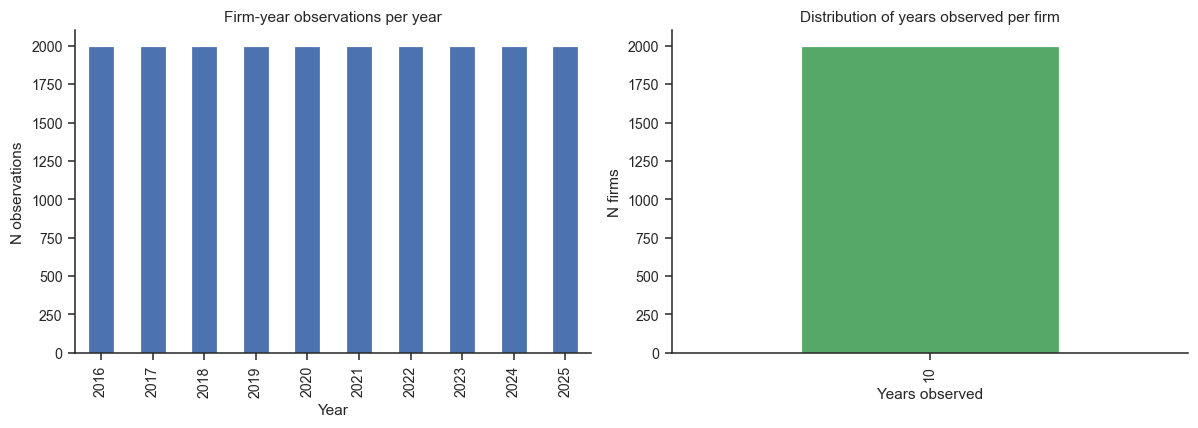

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
obs_per_year.plot(kind="bar", ax=axes[0], color=PALETTE["blue"])
axes[0].set_title("Firm-year observations per year")
axes[0].set_xlabel("Year"); axes[0].set_ylabel("N observations")
years_per_firm.value_counts().sort_index().plot(kind="bar", ax=axes[1], color=PALETTE["green"])
axes[1].set_title("Distribution of years observed per firm")
axes[1].set_xlabel("Years observed"); axes[1].set_ylabel("N firms")
plt.tight_layout(); plt.show()

## 4. Target Construction: ROA(t+1)

In [10]:
ml_df = ml_df.sort_values(["gemh_id", "year"]).reset_index(drop=True)
assert not ml_df.duplicated(["gemh_id", "year"]).any()

ml_df["ROA_unfloored"] = ml_df["NP"] / ml_df["TA"].replace(0, np.nan)

extreme = ml_df[ml_df["ROA_unfloored"].abs() > 5]
print(f"Rows with |ROA| > 5 before the TA floor: {len(extreme)} ({100*len(extreme)/len(ml_df):.2f}%)")
if len(extreme):
    print(extreme[["gemh_id", "year", "TA", "NP", "ROA_unfloored"]]
          .sort_values("ROA_unfloored", key=abs, ascending=False).head(10).to_string(index=False))

ml_df["ROA_raw"] = ml_df["ROA_unfloored"].where(ml_df["TA"] >= TA_FLOOR)          # floored, not winsorised
ml_df[TARGET_RAW] = value_at_year_offset(ml_df, "ROA_raw", +1)
ml_df["TA_t1"] = value_at_year_offset(ml_df, "TA", +1)
ml_df["NP_t1"] = value_at_year_offset(ml_df, "NP", +1)
ml_df["has_t1_row"] = value_at_year_offset(ml_df.assign(_one=1.0), "_one", +1) == 1.0

train_target = ml_df.loc[(ml_df["year"] <= TRAIN_END_YEAR) & ml_df[TARGET_RAW].notna(), TARGET_RAW]
ROA_LO, ROA_HI = (float(v) for v in train_target.quantile(list(WINSOR_Q)))
print(f"\nWinsorisation bounds (train target, {WINSOR_Q[0]:.0%}/{WINSOR_Q[1]:.0%}): [{ROA_LO:.4f}, {ROA_HI:.4f}]  "
      f"(fitted on {len(train_target):,} training targets)")

ml_df["ROA"] = ml_df["ROA_raw"].clip(ROA_LO, ROA_HI)
ml_df[TARGET] = ml_df[TARGET_RAW].clip(ROA_LO, ROA_HI)
ml_df["ROA_t"] = ml_df["ROA"]          # lagged-target feature used only by feature set C and the benchmarks

print(f"\nROA (winsorised):\n{ml_df['ROA'].describe().round(4).to_string()}")

# Why do rows lose their target?
n_rows = len(ml_df)
possible = ml_df["has_t1_row"]
reasons = pd.Series({
    "no year+1 row in panel (last panel year)": int((~possible).sum()),
    "NP(t+1) missing": int((possible & ml_df["NP_t1"].isna()).sum()),
    "TA(t+1) missing": int((possible & ml_df["TA_t1"].isna()).sum()),
    f"TA(t+1) < {TA_FLOOR:,} EUR": int((possible & (ml_df["TA_t1"] < TA_FLOOR)).sum()),
})
n_with_target = int(ml_df[TARGET].notna().sum())
print(f"\nRows with a valid {TARGET}: {n_with_target:,} / {n_rows:,} ({100*n_with_target/n_rows:.1f}%)")
print("Rows without a target, by reason (reasons can overlap):")
print(reasons.to_string())

print("\nTA-floor sensitivity (rows with 0 < TA < floor):")
for fl in (1_000, 5_000, 10_000):
    m = (ml_df["TA"] > 0) & (ml_df["TA"] < fl)
    print(f"  floor {fl:>6,} EUR: {int(m.sum()):>5} rows ({100*m.mean():.2f}%)")

Rows with |ROA| > 5 before the TA floor: 239 (1.20%)
     gemh_id  year    TA         NP  ROA_unfloored
140446530000  2021  0.02    6345.39  317269.500000
  2605401000  2019  1.00  129099.67  129099.670000
 74989058000  2022  2.00  148282.19   74141.095000
   753701000  2016  0.94  -61684.41  -65621.712766
126981201000  2025  0.49   27496.12   56114.530612
  6990501000  2017  0.97   48994.39   50509.680412
123546201000  2018  1.00  -44689.27  -44689.270000
   240701000  2021 58.59 2330259.88   39772.314047
123546201000  2017  1.00  -23841.05  -23841.050000
 30212113000  2024 21.56  422732.26   19607.247681

Winsorisation bounds (train target, 1%/99%): [-1.3428, 0.8268]  (fitted on 11,398 training targets)

ROA (winsorised):
count    16286.0000
mean         0.0316
std          0.2510
min         -1.3428
25%         -0.0145
50%          0.0233
75%          0.0995
max          0.8268

Rows with a valid ROA_t1: 14,685 / 20,000 (73.4%)
Rows without a target, by reason (reasons can overlap):

## 5. Feature Dictionary, Lagged-Target Family and Time-Window Audit

In [11]:
FEATURE_ORDER = [1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 12, 14, 17, 18, 19, 20, 21, 22, 23, 24, 25,
                 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 42, 43, 44, 45, 46,
                 47, 50, 51, 52, 53, 54, 55, 56, 58, 59, 60, 61, 62, 63, 64]
X_FIELDS = [f"X{i}" for i in FEATURE_ORDER]
BASE_FIELDS = ["TA", "INV", "REC", "CASH", "STL", "LTL", "TL", "EQ", "SC", "RE",
               "Sales", "COGS", "GP_acc", "SGA_admin", "SGA_selling", "InvInc",
               "EBIT", "IntInc", "IntExp", "GP", "NP", "FA_tangible", "FA_intangible"]

FEATURE_DICTIONARY = pd.DataFrame([
    ("X1",  "NP / TA",                       "Profitability", "ROA, same family as the target itself"),
    ("X2",  "TL / TA",                       "Leverage", ""),
    ("X3",  "WC / TA",                       "Liquidity", "WC = CA - STL"),
    ("X4",  "CA / STL",                      "Liquidity", "current ratio"),
    ("X6",  "RE / TA",                       "Leverage", "retained earnings as % of assets (stock, not flow)"),
    ("X7",  "EBIT / TA",                     "Profitability", "operating ROA"),
    ("X8",  "EQ / TL",                       "Leverage", ""),
    ("X9",  "Sales / TA",                    "Profitability", "asset turnover; duplicate of X36"),
    ("X10", "EQ / TA",                       "Leverage", ""),
    ("X11", "(GP + IntExp) / TA",            "Profitability", "GP = profit before tax"),
    ("X12", "GP / STL",                      "Profitability", "GP = profit before tax"),
    ("X14", "(GP + IntInc) / TA",            "Profitability", "GP = profit before tax"),
    ("X17", "TA / TL",                       "Leverage", "reciprocal of X2; dropped"),
    ("X18", "GP / TA",                       "Profitability", "GP = profit before tax"),
    ("X19", "GP / Sales",                    "Profitability", "GP = profit before tax"),
    ("X20", "INV x 365 / Sales",             "Efficiency", "days inventory (Sales-based)"),
    ("X21", "Sales(t) / Sales(t-1)",         "Growth", "YoY sales growth"),
    ("X22", "OpProfit / TA",                 "Profitability", "OpProfit = EBIT - InvInc; duplicate of X35"),
    ("X23", "NP / Sales",                    "Profitability", "net margin, same family as target"),
    ("X24", "sum(GP, last 3 yrs) / TA",      "Profitability", "GP = profit before tax; trailing three-year window"),
    ("X25", "(EQ - SC) / TA",                "Leverage", "equals X6 only if EQ = SC + RE holds; dropped only when the identity check in this section passes"),
    ("X27", "OpProfit / IntExp",             "Profitability", "interest coverage; profit-adjacent, Spec B group"),
    ("X28", "WC / FA",                       "Liquidity", ""),
    ("X29", "log(TA)",                       "Size", "nominal; the modelling copy is deflated (X29_real)"),
    ("X30", "(TL - CASH) / Sales",           "Leverage", ""),
    ("X31", "(GP + IntInc) / Sales",         "Profitability", "GP = profit before tax"),
    ("X32", "STL x 365 / COGS",              "Efficiency", "duplicate of X52"),
    ("X33", "(COGS + SGA) / STL",            "Efficiency", ""),
    ("X34", "(COGS + SGA) / TL",             "Efficiency", ""),
    ("X35", "OpProfit / TA",                 "Profitability", "duplicate of X22"),
    ("X36", "Sales / TA",                    "Profitability", "duplicate of X9"),
    ("X37", "(CA - INV) / LTL",              "Liquidity", "quick assets / long-term liabilities"),
    ("X38", "(EQ + LTL) / TA",               "Leverage", "constant capital / TA"),
    ("X39", "OpProfit / Sales",              "Profitability", "duplicate of X42"),
    ("X40", "(CA - INV - REC) / STL",        "Liquidity", "cash ratio-like"),
    ("X42", "OpProfit / Sales",              "Profitability", "duplicate of X39"),
    ("X43", "X20 + REC x 365/Sales",         "Efficiency", "cash conversion cycle proxy"),
    ("X44", "REC x 365 / Sales",             "Efficiency", "days receivables"),
    ("X45", "NP / INV",                      "Profitability", "contains NP, same family as target"),
    ("X46", "(CA - INV) / STL",              "Liquidity", "quick ratio"),
    ("X47", "INV x 365 / COGS",              "Efficiency", "days inventory (COGS-based)"),
    ("X50", "CA / TL",                       "Liquidity", ""),
    ("X51", "STL / TA",                      "Leverage", ""),
    ("X52", "STL x 365 / COGS",              "Efficiency", "duplicate of X32"),
    ("X53", "EQ / FA",                       "Leverage", ""),
    ("X54", "(EQ + LTL) / FA",               "Leverage", "constant capital / fixed assets; equals X28 + 1 only if PROV = 0; dropped only when the identity check in this section passes"),
    ("X55", "WC (absolute, EUR)",            "Liquidity", "nominal; the modelling copy is deflated (X55_real)"),
    ("X56", "GP_acc / Sales",                "Profitability", "accounting gross margin; profit-adjacent, Spec B group"),
    ("X58", "(COGS + SGA) / Sales",          "Efficiency", "equals 1 minus the operating margin before other items; Spec B group"),
    ("X59", "LTL / EQ",                      "Leverage", ""),
    ("X60", "Sales / INV",                   "Efficiency", "inventory turnover; reciprocal of X20 up to the factor 365; dropped"),
    ("X61", "Sales / REC",                   "Efficiency", "receivables turnover; reciprocal of X44 up to the factor 365; dropped"),
    ("X62", "STL x 365 / Sales",             "Efficiency", ""),
    ("X63", "Sales / STL",                   "Efficiency", "reciprocal of X62 up to the factor 365; dropped"),
    ("X64", "Sales / FA",                    "Efficiency", "fixed-asset turnover"),
], columns=["Variable", "Formula", "Category", "Notes"])
pd.set_option("display.max_rows", 70)
display(FEATURE_DICTIONARY)

,Variable,Formula,Category,Notes
0,X1,NP / TA,Profitability,"ROA, same family as the target itself"
1,X2,TL / TA,Leverage,
2,X3,WC / TA,Liquidity,WC = CA - STL
3,X4,CA / STL,Liquidity,current ratio
4,X6,RE / TA,Leverage,"retained earnings as % of assets (stock, not f..."
5,X7,EBIT / TA,Profitability,operating ROA
6,X8,EQ / TL,Leverage,
7,X9,Sales / TA,Profitability,asset turnover; duplicate of X36
8,X10,EQ / TA,Leverage,
9,X11,(GP + IntExp) / TA,Profitability,GP = profit before tax


In [12]:
# Correlation of each ratio with the target, TRAINING rows only.
train_rows = ml_df[(ml_df["year"] <= TRAIN_END_YEAR) & ml_df[TARGET].notna()]
corr_with_target = (train_rows[X_FIELDS].replace([np.inf, -np.inf], np.nan)
                    .corrwith(train_rows[TARGET]).sort_values(key=abs, ascending=False))
print("Top 15 |correlation| with ROA(t+1) (training rows):")
print(corr_with_target.head(15).round(4).to_string())

# Lagged-target family: numerator is NP, EBIT or GP (profit before tax).
EXCLUDE_LAG_TARGET_FAMILY = ["X1", "X7", "X11", "X12", "X14", "X18", "X19", "X22", "X23", "X24", "X31", "X39", "X45"]
# Profit-adjacent (interest coverage, gross margin, complement of the operating margin); excluded from A, added back in Spec B.
EXCLUDE_MODERATE_A_ONLY = ["X27", "X56", "X58"]
# Duplicates: exact copies (X9/X36, X22/X35, X39/X42, X32/X52) and exact reciprocals (X2/X17, X20/X60, X44/X61, X62/X63);
# the first-named ratio is kept. Identity-based twins (X6/X25, X28/X54) are added only if the identity holds in most rows.
EXCLUDE_DUPLICATES = ["X36", "X35", "X42", "X52", "X17", "X60", "X61", "X63"]
TWIN_MIN_SHARE = 0.90

def identity_share(diff, tol=0.01):
    d = pd.to_numeric(diff, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    return (float((d.abs() <= tol).mean()) if len(d) else np.nan), int(len(d))

IDENTITY_TWIN_CHECK = []
_num = lambda c: pd.to_numeric(ml_df[c], errors="coerce")
for keep, twin, diff in (("X6", "X25", _num("X25") - _num("X6")),
                         ("X28", "X54", _num("X54") - _num("X28") - 1)):
    share, n_chk = identity_share(diff)
    dropped = bool(np.isfinite(share) and share >= TWIN_MIN_SHARE)
    IDENTITY_TWIN_CHECK.append(dict(kept=keep, twin=twin, share_rows_identity_holds=round(share, 4), n_checked=n_chk,
                                    twin_dropped=dropped))
    if dropped:
        EXCLUDE_DUPLICATES.append(twin)
display(pd.DataFrame(IDENTITY_TWIN_CHECK).set_index("twin"))
print(f"An identity-based twin is dropped only if the identity holds (tolerance 0.01) in at least {TWIN_MIN_SHARE:.0%} of the rows checked.")

print("\nDuplicate-pair rank correlation check (|value| near 1; identity-based pairs depend on data quality, reciprocals are negative):")
for a, b in [("X9", "X36"), ("X22", "X35"), ("X39", "X42"), ("X32", "X52"), ("X6", "X25"), ("X28", "X54"),
             ("X2", "X17"), ("X20", "X60"), ("X44", "X61"), ("X62", "X63")]:
    ra = train_rows[a].replace([np.inf, -np.inf], np.nan)
    rb = train_rows[b].replace([np.inf, -np.inf], np.nan)
    print(f"  {a} <-> {b}: Spearman = {ra.corr(rb, method='spearman'):+.4f}")

FEATURE_COLS_SPEC_A = [x for x in X_FIELDS
                       if x not in EXCLUDE_LAG_TARGET_FAMILY + EXCLUDE_DUPLICATES + EXCLUDE_MODERATE_A_ONLY]
FEATURE_COLS_SPEC_B = FEATURE_COLS_SPEC_A + EXCLUDE_MODERATE_A_ONLY
print(f"\nSpec A ratio count: {len(FEATURE_COLS_SPEC_A)}   Spec B ratio count: {len(FEATURE_COLS_SPEC_B)}")

Top 15 |correlation| with ROA(t+1) (training rows):
X29    0.0803
X23    0.0659
X56    0.0650
X39    0.0450
X42    0.0450
X20    0.0440
X43    0.0429
X44    0.0402
X19    0.0311
X31    0.0303
X27    0.0210
X45    0.0163
X55    0.0153
X1     0.0143
X35    0.0140


,kept,share_rows_identity_holds,n_checked,twin_dropped
twin,,,,
X25,X6,0.2868,11398,False
X54,X28,0.7765,14351,False


An identity-based twin is dropped only if the identity holds (tolerance 0.01) in at least 90% of the rows checked.

Duplicate-pair rank correlation check (|value| near 1; identity-based pairs depend on data quality, reciprocals are negative):
  X9 <-> X36: Spearman = +1.0000
  X22 <-> X35: Spearman = +1.0000
  X39 <-> X42: Spearman = +1.0000
  X32 <-> X52: Spearman = +1.0000
  X6 <-> X25: Spearman = +0.5893
  X28 <-> X54: Spearman = +0.9279
  X2 <-> X17: Spearman = -0.9647
  X20 <-> X60: Spearman = -0.9597
  X44 <-> X61: Spearman = -0.9451
  X62 <-> X63: Spearman = -0.9566

Spec A ratio count: 31   Spec B ratio count: 34


### Time-window audit of growth and multi-year ratios

In [13]:
def match_rate(a, b, rtol=1e-3, atol=1e-6):
    a, b = pd.Series(a), pd.Series(b)
    m = a.notna() & b.notna() & np.isfinite(a.astype(float)) & np.isfinite(b.astype(float))
    if m.sum() == 0:
        return np.nan, 0
    return float(np.isclose(a[m].astype(float), b[m].astype(float), rtol=rtol, atol=atol).mean()), int(m.sum())

sales = ml_df["Sales"]
sales_prev = pd.Series(value_at_year_offset(ml_df, "Sales", -1))
sales_next = pd.Series(value_at_year_offset(ml_df, "Sales", +1))
x21_variants = {
    "trailing  Sales(t)/Sales(t-1)": sales / sales_prev.replace(0, np.nan),
    "forward   Sales(t+1)/Sales(t)": sales_next / sales.replace(0, np.nan),
}
gp = ml_df["GP"]
gp_m1 = pd.Series(value_at_year_offset(ml_df, "GP", -1)); gp_m2 = pd.Series(value_at_year_offset(ml_df, "GP", -2))
gp_p1 = pd.Series(value_at_year_offset(ml_df, "GP", +1)); gp_p2 = pd.Series(value_at_year_offset(ml_df, "GP", +2))
ta_nz = ml_df["TA"].replace(0, np.nan)
x24_variants = {
    "trailing  GP(t-2..t)":   (gp + gp_m1 + gp_m2) / ta_nz,
    "centred   GP(t-1..t+1)": (gp_m1 + gp + gp_p1) / ta_nz,
    "forward   GP(t..t+2)":   (gp + gp_p1 + gp_p2) / ta_nz,
}
audit_rows = []
for col, variants in (("X21", x21_variants), ("X24", x24_variants)):
    for name, series in variants.items():
        rate, n = match_rate(ml_df[col], series)
        audit_rows.append(dict(ratio=col, window=name, match_rate=rate, n_compared=n))
audit_df = pd.DataFrame(audit_rows)
display(audit_df.round(4))

for col in ("X21", "X24"):
    sub = audit_df[audit_df["ratio"] == col].set_index("window")["match_rate"]
    trailing = sub[[i for i in sub.index if i.startswith("trailing")][0]]
    others = sub[[i for i in sub.index if not i.startswith("trailing")]]
    if np.isfinite(others.max()) and others.max() > 0.5 and others.max() > (trailing if np.isfinite(trailing) else 0):
        raise AssertionError(f"{col} matches a non-trailing window better than the trailing one; "
                             "the ratio appears to use future information.")
    if not np.isfinite(sub.max()) or sub.max() < 0.5:
        print(f"NOTE: no window reproduces {col} closely (max match {sub.max():.2f}); "
              "compare against recompute_features.py before relying on the timing of this ratio.")

,ratio,window,match_rate,n_compared
0,X21,trailing Sales(t)/Sales(t-1),0.9054,13353
1,X21,forward Sales(t+1)/Sales(t),0.0447,11510
2,X24,trailing GP(t-2..t),0.6421,11966
3,X24,centred GP(t-1..t+1),0.0159,11922
4,X24,forward GP(t..t+2),0.0101,11542


## 6. Dataset Overview and Data Dictionary

In [14]:
KEY_COLS = ["gemh_id", "year", "extraction_tier", "size_category", "TA", "Sales", "NP", "TL", "EQ", "ROA", TARGET]
print("First 10 rows (key columns):")
display(ml_df[KEY_COLS].head(10))
print("\nLast 10 rows (key columns):")
display(ml_df[KEY_COLS].tail(10))
print(f"\nObservations: {len(ml_df):,} | Firms: {ml_df['gemh_id'].nunique():,} | "
      f"Years: {ml_df['year'].nunique()} | Columns: {ml_df.shape[1]}")

First 10 rows (key columns):


,gemh_id,year,extraction_tier,size_category,TA,Sales,NP,TL,EQ,ROA,ROA_t1
0,10034353000,2016,gemini_vision,small,1438408.00,452800.00,279876.00,165627.00,1272780.00,0.194573,0.173718
1,10034353000,2017,gemini_vision,small,1524782.99,454258.64,264882.99,168190.88,1356592.11,0.173718,0.190436
2,10034353000,2018,gemini_vision,small,1513116.00,463694.00,288152.00,176454.00,1336662.00,0.190436,0.214332
3,10034353000,2019,gemini_vision,small,1480514.00,475398.00,317321.00,157770.00,1322743.00,0.214332,0.163642
4,10034353000,2020,gemini_vision,small,1344532.60,342674.72,220022.07,117556.71,1226975.89,0.163642,0.163990
5,10034353000,2021,gemini_vision,small,1625445.00,262108.00,266557.00,210860.00,1414585.00,0.163990,0.241490
6,10034353000,2022,gemini_vision,small,1661144.27,453546.97,401149.50,145409.13,1515735.14,0.241490,0.209143
7,10034353000,2023,gemini_vision,small,1670653.95,505731.12,349404.81,155551.40,1515139.95,0.209143,0.206188
8,10034353000,2024,gemini_vision,small,1642540.25,499011.12,338671.36,138728.94,1503811.31,0.206188,0.234737
9,10034353000,2025,gemini_vision,small,1702801.00,505998.00,399710.00,165279.00,1537522.00,0.234737,NaN



Last 10 rows (key columns):


,gemh_id,year,extraction_tier,size_category,TA,Sales,NP,TL,EQ,ROA,ROA_t1
19990,9955253000,2016,pdfplumber,small,2722778.76,441111.00,-54027.23,2413392.50,309386.26,-0.019843,0.079246
19991,9955253000,2017,pdfplumber,small,2848170.49,1679762.24,225705.57,2313078.66,535091.83,0.079246,-0.067444
19992,9955253000,2018,pdfplumber,small,2818821.97,275938.31,-190113.27,2473843.41,344978.56,-0.067444,0.008953
19993,9955253000,2019,pdfplumber,small,2546537.82,810459.68,22799.31,2178759.95,367777.87,0.008953,-0.067659
19994,9955253000,2020,pdfplumber,small,2533173.06,477424.12,-171390.78,2336785.97,196387.09,-0.067659,-0.082467
19995,9955253000,2021,pdfplumber,small,2811370.66,121309.75,-231844.58,1223543.36,1587827.30,-0.082467,0.011435
19996,9955253000,2022,pdfplumber,small,2468335.27,463412.21,28225.97,852282.00,1616053.27,0.011435,NaN
19997,9955253000,2023,pdfplumber,NaN,NaN,22002233.00,NaN,NaN,NaN,NaN,NaN
19998,9955253000,2024,pdfplumber,NaN,NaN,22002244.00,NaN,NaN,NaN,NaN,NaN
19999,9955253000,2025,pdfplumber,NaN,NaN,136466.40,NaN,NaN,NaN,NaN,NaN



Observations: 20,000 | Firms: 2,000 | Years: 10 | Columns: 129


In [15]:
def build_data_dictionary(df, cols):
    rows = []
    for c in cols:
        s = df[c]
        is_num = pd.api.types.is_numeric_dtype(s)
        rows.append(dict(
            Variable=c, Type=str(s.dtype), Missing_pct=round(100 * s.isna().mean(), 2),
            Mean=round(s.mean(), 3) if is_num else None, Median=round(s.median(), 3) if is_num else None,
            Std=round(s.std(), 3) if is_num else None, Min=round(s.min(), 3) if is_num else None,
            Max=round(s.max(), 3) if is_num else None))
    return pd.DataFrame(rows)

DATA_DICTIONARY = build_data_dictionary(ml_df.replace([np.inf, -np.inf], np.nan),
                                        BASE_FIELDS + X_FIELDS[:15] + ["ROA", TARGET])
display(DATA_DICTIONARY.set_axis(DATA_DICTIONARY.index + 1))

,Variable,Type,Missing_pct,Mean,Median,Std,Min,Max
1,TA,float64,6.02,5.571368e+06,759851.020,2.776534e+07,-1.559921e+08,7.788263e+08
2,INV,float64,8.06,5.244683e+05,0.000,5.192097e+06,-7.710000e+03,3.261126e+08
3,REC,float64,39.84,2.274957e+07,115743.125,1.591546e+09,-4.923387e+07,1.289255e+11
4,CASH,float64,40.00,1.163365e+06,80742.000,9.923248e+06,-4.218800e+04,7.495552e+08
5,STL,float64,13.39,2.316527e+06,165709.495,1.744034e+07,-2.807274e+07,9.076801e+08
6,LTL,float64,15.44,8.329320e+05,0.000,8.805270e+06,-1.937817e+08,4.737691e+08
7,TL,float64,6.25,2.872919e+06,243839.350,1.914637e+07,-3.082994e+07,7.704086e+08
8,EQ,float64,8.56,3.233596e+06,308475.630,2.404395e+07,-1.697358e+08,8.007825e+08
9,SC,float64,20.06,1.872961e+06,165060.000,1.410993e+07,-1.051583e+08,7.502111e+08
10,RE,float64,40.88,1.426507e+05,2957.770,1.118702e+07,-3.301975e+08,4.700770e+08


## 7. Constructing the ML Dataset

In [16]:
COLUMN_CLASSIFICATION = pd.DataFrame([
    ("gemh_id", "Firm identifier", "Kept for panel joins; never a feature"),
    ("afm", "Firm identifier (tax ID)", "Kept for panel joins; never a feature"),
    ("company_name", "Free text", "Dropped"),
    ("coNamesEn_json", "JSON / scraping metadata", "Dropped"),
    ("municipality", "Granular location", "Dropped (quasi-identifying)"),
    ("city", "Granular location", "Dropped"),
    ("gemiOffice", "Registry administrative", "Dropped"),
    ("autoRegistered", "Registry administrative", "Dropped"),
    ("lastStatusChange", "Registry administrative", "Dropped"),
    ("status", "Registry administrative", "Dropped (near-constant)"),
    ("isActive", "Registry administrative", "Dropped (near-constant)"),
    ("isBranch", "Firm characteristic (static in file)", "Feature (structural); ablation without static characteristics"),
    ("prefecture", "Geographic", "Superseded by region_group"),
    ("region_group", "Geographic (Attica unified, static in file)", "Feature (categorical, rare levels collapsed on training rows); ablation without static characteristics"),
    ("legalType", "Firm characteristic (static in file)", "Feature (categorical, rare levels collapsed on training rows); ablation without static characteristics"),
    ("primary_kad", "Sector code (KAD)", "NACE division (first two digits) used by the sector benchmark and ablation arms; static in file"),
    ("incorporationDate", "Firm characteristic", "Transformed to firm age at year t"),
    ("n_persons", "Registry snapshot (static in file)", "Excluded from primary sets; static registry ablation arm"),
    ("n_activities", "Registry snapshot (static in file)", "Excluded from primary sets; static registry ablation arm"),
    ("meets_threshold", "Registry snapshot / administrative flag (static in file)", "Excluded from primary sets; static registry ablation arm"),
    ("size_category", "Registry size class (EU thresholds), varies over time", "Grouping variable; own ablation arm; provenance unverified"),
    ("financial_statement_obligated", "Administrative flag", "Not used"),
    ("n_years_covered", "Extraction metadata", "Dropped"),
    ("extraction_tier", "Data-quality metadata", "Kept for quality subgroups; never a feature"),
    ("accounting_identity_check", "Data-quality flag", "Kept for audits; never a feature"),
    ("requires_review", "Data-quality flag", "Kept for audits; never a feature"),
    ("imputed_zero_fields", "Data-quality metadata", "Dropped"),
    ("scale_corrected", "Data-quality metadata", "Kept for audits; never a feature"),
    ("scale_correction_factor", "Data-quality metadata", "Dropped"),
    ("manual_override", "Data-quality metadata", "Dropped"),
    ("outlier_flag", "Data-quality flag", "Kept for audits; never a feature"),
    ("outlier_reason", "Data-quality metadata", "Dropped"),
    ("identity_check_failed", "Data-quality flag", "Kept for audits; never a feature"),
    ("PROV", "Accounting component", "Enters the TA = TL + EQ + PROV identity only"),
    ("balance_sheet_template", "Extraction metadata", "Dropped"),
    ("income_statement_template", "Extraction metadata", "Dropped"),
    ("gemini_scale_suspect", "Data-quality flag", "Kept for audits; never a feature"),
], columns=["Column", "Category", "Decision"])
display(COLUMN_CLASSIFICATION)

DROP_COLS = [
    "company_name", "coNamesEn_json", "municipality", "city", "gemiOffice",
    "autoRegistered", "lastStatusChange", "status", "isActive",
    "n_years_covered", "imputed_zero_fields",
    "scale_correction_factor", "manual_override", "outlier_reason",
    "balance_sheet_template", "income_statement_template",
]
n_cols_before = ml_df.shape[1]
ml_df = ml_df.drop(columns=DROP_COLS, errors="ignore")
assert ml_df is not raw_df
print(f"raw_df: {raw_df.shape} (untouched) | ml_df: {ml_df.shape} "
      f"({n_cols_before - ml_df.shape[1]} columns removed, derived columns added)")

,Column,Category,Decision
0,gemh_id,Firm identifier,Kept for panel joins; never a feature
1,afm,Firm identifier (tax ID),Kept for panel joins; never a feature
2,company_name,Free text,Dropped
3,coNamesEn_json,JSON / scraping metadata,Dropped
4,municipality,Granular location,Dropped (quasi-identifying)
5,city,Granular location,Dropped
6,gemiOffice,Registry administrative,Dropped
7,autoRegistered,Registry administrative,Dropped
8,lastStatusChange,Registry administrative,Dropped
9,status,Registry administrative,Dropped (near-constant)


raw_df: (20000, 117) (untouched) | ml_df: (20000, 113) (16 columns removed, derived columns added)


## 8. Data Quality Audit and Missingness

In [17]:
print("Structural checks")
print("-" * 40)
print("Shape:", ml_df.shape)
print("Duplicate firm-year pairs:", ml_df.duplicated(subset=["gemh_id", "year"]).sum())
print("Impossible years:", ((ml_df["year"] < 2000) | (ml_df["year"] > 2026)).sum())
print("size_category values:", ml_df["size_category"].value_counts(dropna=False).to_dict())

missing_by_var = ml_df.isna().mean().sort_values(ascending=False) * 100
print("\nTop 10 variables by missingness %:")
print(missing_by_var.head(10).round(2).to_string())

missing_by_year = ml_df.drop(columns="year").isna().groupby(ml_df["year"]).mean().mean(axis=1) * 100
print(f"\nMean overall missingness by year: range {missing_by_year.min():.1f}% to {missing_by_year.max():.1f}%")

Structural checks
----------------------------------------
Shape: (20000, 113)
Duplicate firm-year pairs: 0
Impossible years: 0
size_category values: {'small': 8979, 'micro': 6192, nan: 2494, 'medium': 1300, 'large': 1035}

Top 10 variables by missingness %:
gemini_scale_suspect    88.30
PROV                    72.74
InvInc                  67.94
X45                     65.89
X60                     63.42
X37                     62.74
X33                     58.04
X52                     57.39
X47                     57.39
X32                     57.39

Mean overall missingness by year: range 20.3% to 23.8%


### Formal missingness-mechanism checks (MCAR versus MAR)

In [18]:
def loglik(y_true, p):
    p = np.clip(p, 1e-10, 1 - 1e-10)
    return float(np.sum(y_true * np.log(p) + (1 - y_true) * np.log(1 - p)))

def missingness_lr_test(y, X, C=1.0):
    y = np.asarray(y).astype(int)
    if len(np.unique(y)) < 2:
        return None
    ll_null = loglik(y, np.full(len(y), y.mean()))
    clf = LogisticRegression(C=C, max_iter=3000).fit(X, y)
    ll_full = loglik(y, clf.predict_proba(X)[:, 1])
    lr_stat = 2 * (ll_full - ll_null)
    df_diff = X.shape[1]
    clf.pseudo_r2_ = float(1 - ll_full / ll_null) if ll_null != 0 else np.nan
    return lr_stat, float(stats.chi2.sf(max(lr_stat, 0), df_diff)), clf

cov = ml_df[["year", "size_grp", "extraction_tier"]].astype(str)
X_cov = pd.get_dummies(cov, drop_first=True, dtype=float)

rows = []
for var in ["InvInc", "IntInc", "IntExp", "PROV", "gemini_scale_suspect", "NP", "TA"]:
    if var not in ml_df.columns:
        continue
    y = ml_df[var].isna().astype(int).values
    res = missingness_lr_test(y, X_cov)
    if res is None:
        rows.append(dict(variable=var, missing_pct=round(100 * y.mean(), 1), lr_stat=None, p_value=None,
                         verdict="no variation, skipped"))
        continue
    lr_stat, p, clf_v = res
    rows.append(dict(variable=var, missing_pct=round(100 * y.mean(), 1), lr_stat=round(lr_stat, 1), p_value=p, pseudo_R2=round(clf_v.pseudo_r2_, 4),
                     verdict="reject MCAR (MAR working assumption)" if p < 0.05 else "consistent with MCAR"))

# Target availability: among rows whose year+1 exists in the panel, is a missing target related to observables,
# including the row's own ROA_t and log(TA)?
elig = ml_df[ml_df["has_t1_row"]].copy()
elig["target_missing"] = elig[TARGET_RAW].isna().astype(int)
med_roa = elig["ROA_t"].median()
Xa = pd.get_dummies(elig[["year", "size_grp", "extraction_tier"]].astype(str), drop_first=True, dtype=float)
Xa["ROA_t"] = elig["ROA_t"].fillna(med_roa).values
Xa["logTA"] = np.log(elig["TA"].where(elig["TA"] > 0)).fillna(np.log(elig["TA"].where(elig["TA"] > 0)).median()).values
Xa = (Xa - Xa.mean()) / Xa.std(ddof=0).replace(0, 1)
res = missingness_lr_test(elig["target_missing"].values, Xa)
if res is not None:
    lr_stat, p, clf = res
    rows.append(dict(variable="target availability (ROA_t1 missing)", missing_pct=round(100 * elig["target_missing"].mean(), 1),
                     lr_stat=round(lr_stat, 1), p_value=p, pseudo_R2=round(clf.pseudo_r2_, 4),
                     verdict="reject MCAR (MAR working assumption)" if p < 0.05 else "consistent with MCAR"))
mcar_results_df = pd.DataFrame(rows)
display(mcar_results_df)

print("\nDoes losing the target select on observables? (rows whose year+1 exists in the panel)")
sel_tbl = elig.groupby("target_missing").agg(n=("gemh_id", "size"), mean_ROA_t=("ROA_t", "mean"),
                                              median_logTA=("TA", lambda s: np.log(s.where(s > 0)).median()))
sel_tbl.index = sel_tbl.index.map({0: "target observed", 1: "target missing"})
display(sel_tbl.round(4))
print("Missing-target share by extraction tier (%):")
print((elig.groupby("extraction_tier")["target_missing"].mean() * 100).round(1).to_string())
print("Missing-target share by year (%):")
print((elig.groupby("year")["target_missing"].mean() * 100).round(1).to_string())
m_obs = float(sel_tbl.loc["target observed", "mean_ROA_t"])
m_mis = float(sel_tbl.loc["target missing", "mean_ROA_t"])
tilt = "more" if m_mis < m_obs else "less"
print(f"\nRows whose target is missing have a {'lower' if m_mis < m_obs else 'higher'} mean ROA_t ({m_mis:.4f} versus {m_obs:.4f}), "
      f"so the modelling sample is tilted toward {tilt} profitable observations.")
print("Effect size: McFadden pseudo-R2 in the table; with this many rows every likelihood-ratio test rejects.")

,variable,missing_pct,lr_stat,p_value,pseudo_R2,verdict
0,InvInc,67.9,7093.9,0.000000e+00,0.2827,reject MCAR (MAR working assumption)
1,IntInc,38.3,2485.4,0.000000e+00,0.0933,reject MCAR (MAR working assumption)
2,IntExp,26.4,1869.4,0.000000e+00,0.0810,reject MCAR (MAR working assumption)
3,PROV,72.7,741.1,2.310682e-147,0.0316,reject MCAR (MAR working assumption)
4,gemini_scale_suspect,88.3,7302.0,0.000000e+00,0.5060,reject MCAR (MAR working assumption)
5,NP,13.1,2475.2,0.000000e+00,0.1590,reject MCAR (MAR working assumption)
6,TA,6.0,5625.2,0.000000e+00,0.6185,reject MCAR (MAR working assumption)
7,target availability (ROA_t1 missing),18.4,1542.6,0.000000e+00,0.0897,reject MCAR (MAR working assumption)



Does losing the target select on observables? (rows whose year+1 exists in the panel)


,n,mean_ROA_t,median_logTA
target_missing,,,
target observed,14685,0.0296,13.5382
target missing,3315,0.0153,13.4116


Missing-target share by extraction tier (%):
extraction_tier
gemini_vision       13.2
manual_verified      0.0
pdfplumber          20.5
scan_unprocessed    44.4
Missing-target share by year (%):
year
2016    18.8
2017    18.6
2018    19.0
2019    18.7
2020    17.5
2021    18.8
2022    18.6
2023    18.9
2024    16.8

Rows whose target is missing have a lower mean ROA_t (0.0153 versus 0.0296), so the modelling sample is tilted toward more profitable observations.
Effect size: McFadden pseudo-R2 in the table; with this many rows every likelihood-ratio test rejects.


### Negative values and expense-sign consistency

Fields that should rarely be negative:


,field,n_negative,n_non_null,pct_negative
6,SC,802,15988,5.016
4,LTL,222,16911,1.313
5,TL,145,18749,0.773
3,STL,86,17322,0.496
8,REC,46,12032,0.382
10,FA_intangible,21,18411,0.114
7,Sales,15,18666,0.080
9,FA_tangible,8,17907,0.045
1,INV,5,18387,0.027
0,TA,5,18797,0.027



Expense-sign consistency (expected non-negative after upstream normalisation):
  COGS: 0 negative of 10828 (0.00%)
  SGA_admin: 0 negative of 10465 (0.00%)
  SGA_selling: 0 negative of 9465 (0.00%)


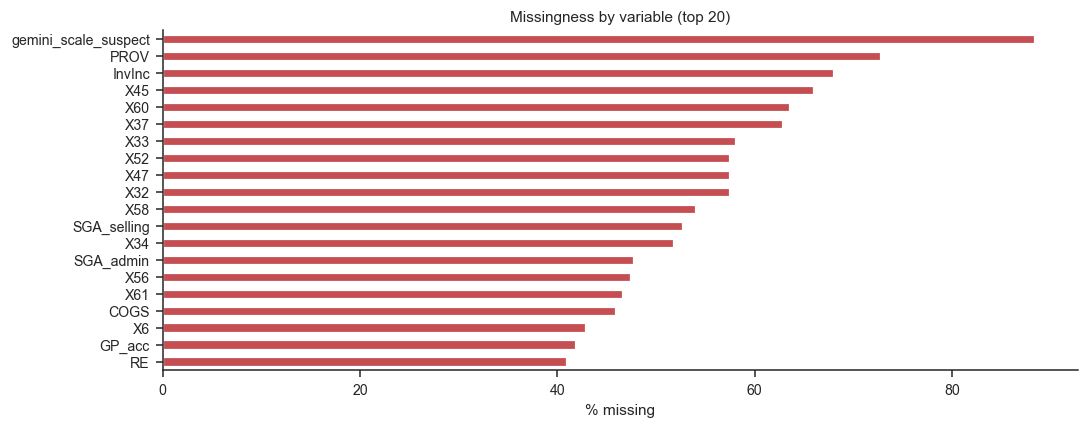

In [19]:
NEVER_NEGATIVE = ["TA", "INV", "CASH", "STL", "LTL", "TL", "SC", "Sales", "REC", "FA_tangible", "FA_intangible"]
neg_summary = []
for field in NEVER_NEGATIVE:
    if field not in ml_df.columns:
        continue
    n_neg = int((ml_df[field] < 0).sum())
    n_tot = int(ml_df[field].notna().sum())
    neg_summary.append((field, n_neg, n_tot, 100 * n_neg / n_tot if n_tot else 0))
neg_df = pd.DataFrame(neg_summary, columns=["field", "n_negative", "n_non_null", "pct_negative"]) \
    .sort_values("pct_negative", ascending=False)
print("Fields that should rarely be negative:")
display(neg_df.round(3))

print("\nExpense-sign consistency (expected non-negative after upstream normalisation):")
for field in ["COGS", "SGA_admin", "SGA_selling"]:
    if field in ml_df.columns:
        vals = ml_df[field].dropna()
        print(f"  {field}: {(vals < 0).sum()} negative of {len(vals)} ({100*(vals<0).mean() if len(vals) else 0:.2f}%)")

fig, ax = plt.subplots(figsize=(10, 4))
missing_by_var[missing_by_var > 0].head(20).plot(kind="barh", ax=ax, color=PALETTE["red"])
ax.set_xlabel("% missing"); ax.set_title("Missingness by variable (top 20)")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

In [20]:
# Share capital sign check: EQ = SC + RE should hold when the components are read correctly.
n_neg_total = int((ml_df["SC"] < 0).sum())
sc_rows = ml_df[ml_df["SC"].notna() & ml_df["RE"].notna() & ml_df["EQ"].notna() & ml_df["TA"].notna()].copy()
tol = 0.01 * sc_rows["TA"].abs().clip(lower=1)
sc_rows["fits_EQ_minus_SC"] = (sc_rows["EQ"] - sc_rows["SC"] - sc_rows["RE"]).abs() <= tol
sc_rows["fits_EQ_plus_SC"] = (sc_rows["EQ"] + sc_rows["SC"] - sc_rows["RE"]).abs() <= tol
neg = sc_rows["SC"] < 0
print(f"Rows with negative SC: {n_neg_total} in total; {int(neg.sum())} of them can be checked (SC, RE, EQ and TA all present)")
if neg.sum():
    s_minus = 100 * sc_rows.loc[neg, "fits_EQ_minus_SC"].mean()
    s_plus = 100 * sc_rows.loc[neg, "fits_EQ_plus_SC"].mean()
    s_none = 100 * (~(sc_rows.loc[neg, "fits_EQ_minus_SC"] | sc_rows.loc[neg, "fits_EQ_plus_SC"])).mean()
    print(f"  EQ = SC + RE holds in {s_minus:.1f}% of them, EQ = RE - SC holds in {s_plus:.1f}%, neither holds in {s_none:.1f}%")
    base_share = IDENTITY_TWIN_CHECK[0]["share_rows_identity_holds"]
    print(f"  For comparison, EQ = SC + RE holds within tolerance in {100*base_share:.1f}% of ALL rows where the components are present: "
          "equity has other components (reserves, share premium), so failing this identity is common and is not evidence of a parsing error.")
    if s_minus >= s_plus:
        print("  Negative SC values fit EQ = SC + RE as signed numbers, so they are not sign flips.")
    else:
        print("  Negative SC behaves like a contra-equity item (for example unpaid capital) that enters equity with the opposite sign.")
    print(f"  The other {n_neg_total - int(neg.sum())} negative-SC rows cannot be checked because RE, EQ or TA is missing. "
          "By extraction tier (% of checkable negative-SC rows):")
    print(sc_rows.loc[neg].groupby("extraction_tier").size().div(neg.sum()).mul(100).round(1).to_string())
print(f"X25 is {'dropped' if 'X25' in EXCLUDE_DUPLICATES else 'kept'} in the feature sets (identity check in Section 5).")

# Extreme-value scan of the monetary fields (SME balance sheets should not reach billions of euros).
scan_fields = ["TA", "INV", "REC", "CASH", "STL", "LTL", "TL", "EQ", "Sales", "NP"]
scan_rows = []
for c in scan_fields:
    s = ml_df[c].dropna().abs()
    scan_rows.append(dict(field=c, median_abs=s.median(), p99_9=s.quantile(0.999), max_abs=s.max(),
                          max_over_median=s.max() / max(s.median(), 1), n_above_1e9=int((s > 1e9).sum())))
display(pd.DataFrame(scan_rows).set_index("field").round(1))
np_no_ta = ml_df["NP"].notna() & ml_df["TA"].isna()
print(f"Rows with NP present but TA missing: {int(np_no_ta.sum())}; of these |NP| > 1e7: {int((np_no_ta & (ml_df['NP'].abs() > 1e7)).sum())}")

Rows with negative SC: 802 in total; 140 of them can be checked (SC, RE, EQ and TA all present)
  EQ = SC + RE holds in 59.3% of them, EQ = RE - SC holds in 0.7%, neither holds in 40.0%
  For comparison, EQ = SC + RE holds within tolerance in 28.7% of ALL rows where the components are present: equity has other components (reserves, share premium), so failing this identity is common and is not evidence of a parsing error.
  Negative SC values fit EQ = SC + RE as signed numbers, so they are not sign flips.
  The other 662 negative-SC rows cannot be checked because RE, EQ or TA is missing. By extraction tier (% of checkable negative-SC rows):
extraction_tier
gemini_vision     4.3
pdfplumber       95.7
X25 is kept in the feature sets (identity check in Section 5).


,median_abs,p99_9,max_abs,max_over_median,n_above_1e9
field,,,,,
TA,760286.7,377435757.1,7.788263e+08,1024.4,0
INV,0.0,80771368.5,3.261126e+08,326112638.0,0
REC,116405.7,236561962.1,1.289255e+11,1107553.5,2
CASH,80742.0,91262940.0,7.495552e+08,9283.3,0
STL,166323.9,184591674.3,9.076801e+08,5457.3,0
LTL,0.0,124566845.9,4.737691e+08,473769093.0,0
TL,245616.4,244757012.9,7.704086e+08,3136.6,0
EQ,354374.0,316401063.2,8.007825e+08,2259.7,0
Sales,246970.8,438846439.3,1.287041e+10,52113.1,3


Rows with NP present but TA missing: 858; of these |NP| > 1e7: 13


## 9. Accounting Consistency and Data-Reliability Class

In [21]:
def accounting_identity_residual(df):
    predicted_ta = df["TL"] + df["EQ"] + df["PROV"].fillna(0)
    resid = df["TA"] - predicted_ta
    rel_resid = (resid / df["TA"].replace(0, np.nan)).abs()
    return resid, rel_resid

resid, rel_resid = accounting_identity_residual(ml_df)
ml_df["accounting_identity_residual"] = resid
ml_df["accounting_identity_rel_discrepancy"] = rel_resid

def quality_class(rel):
    if pd.isna(rel): return "Unknown"
    if rel <= 0.001: return "High confidence"
    if rel <= 0.02:  return "Moderate confidence"
    if rel <= 0.20:  return "Low confidence"
    return "Severe inconsistency"

ml_df["data_reliability_class"] = ml_df["accounting_identity_rel_discrepancy"].apply(quality_class)
REL_ORDER = ["High confidence", "Moderate confidence", "Low confidence", "Severe inconsistency", "Unknown"]
print(ml_df["data_reliability_class"].value_counts().reindex(REL_ORDER).to_string())
print(f"\nIdentity pass rate (relative discrepancy <= 0.1%): {(ml_df['accounting_identity_rel_discrepancy'] <= 0.001).mean()*100:.1f}%")
print("Rows failing the identity are retained with a flag, never dropped.")

ml_df["identity_pass"] = ml_df["accounting_identity_rel_discrepancy"] <= 0.001
print("\nIdentity pass rate by extraction_tier (%):")
print((ml_df.groupby("extraction_tier")["identity_pass"].mean() * 100).round(1).to_string())

# Reliability / tier / anomaly information of the NEXT year, aligned to each row (used by the robustness arms).
ml_df["rel_class_t1"] = value_at_year_offset(ml_df.assign(_r=ml_df["data_reliability_class"].map({k: i for i, k in enumerate(REL_ORDER)})), "_r", +1)
ml_df["rel_class_t1"] = pd.Series(ml_df["rel_class_t1"]).map(dict(enumerate(REL_ORDER)))
_tier_code = {k: i for i, k in enumerate(sorted(ml_df["extraction_tier"].dropna().unique()))}
_tier_inv = {v: k for k, v in _tier_code.items()}
ml_df["extraction_tier_t1"] = pd.Series(
    value_at_year_offset(ml_df.assign(_t=ml_df["extraction_tier"].map(_tier_code)), "_t", +1)).map(_tier_inv)

data_reliability_class
High confidence         14135
Moderate confidence       743
Low confidence           1096
Severe inconsistency     1863
Unknown                  2163

Identity pass rate (relative discrepancy <= 0.1%): 70.7%
Rows failing the identity are retained with a flag, never dropped.

Identity pass rate by extraction_tier (%):
extraction_tier
gemini_vision        72.6
manual_verified     100.0
pdfplumber           70.1
scan_unprocessed      0.0


## 10. Parsing Quality, Firm Size and Selection

In [22]:
ml_df["rel_group"] = np.select(
    [ml_df["data_reliability_class"] == "High confidence",
     ml_df["data_reliability_class"].isin(["Low confidence", "Severe inconsistency"])],
    ["Reliable (High)", "Unreliable (Low + Severe)"], default="Other (Moderate / Unknown)")

cmp_rows = []
for g, sub in ml_df.groupby("rel_group"):
    cmp_rows.append(dict(group=g, n=len(sub), median_TA=sub["TA"].median(), mean_ROA=sub["ROA"].mean(),
                         share_clean_tier=100 * sub["extraction_tier"].isin(CLEAN_TIERS).mean()))
display(pd.DataFrame(cmp_rows).set_index("group").round(4))

print("\nSize mix (% of group) by reliability group:")
mix = pd.crosstab(ml_df["size_grp"], ml_df["rel_group"], normalize="columns").mul(100).round(1)
display(mix)

ct_size_rel = pd.crosstab(ml_df["size_grp"], ml_df["data_reliability_class"]).reindex(columns=REL_ORDER, fill_value=0)
print("Share of rows in each reliability class, by size group (% of size group):")
display(ct_size_rel.div(ct_size_rel.sum(axis=1), axis=0).mul(100).round(1))
v, chi2, p, dof = cramers_v(ct_size_rel)
print(f"size x reliability class (5 classes): Cramer's V = {v:.3f}  (chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e})")
v_k, chi2_k, p_k, dof_k = cramers_v(ct_size_rel.drop(index="unknown", errors="ignore"))
print(f"same, excluding the 'unknown' size group: Cramer's V = {v_k:.3f}  (chi2 = {chi2_k:.1f}, dof = {dof_k}, p = {p_k:.2e})")
if "unknown" in ct_size_rel.index:
    share_unk = 100 * ct_size_rel.loc["unknown", "Unknown"] / ct_size_rel.loc["unknown"].sum()
    print(f"Rows of the 'unknown' size group whose reliability class is 'Unknown' (financials missing): {share_unk:.1f}%; "
          "this group drives most of the five-class association.")

ct_bin = pd.crosstab(ml_df["size_grp"], ml_df["rel_group"]).drop(columns="Other (Moderate / Unknown)", errors="ignore")
v, chi2, p, dof = cramers_v(ct_bin)
_rb = ml_df[ml_df["rel_group"] != "Other (Moderate / Unknown)"]
v_pt, v_lo, v_hi = cramers_v_ci(_rb["size_grp"], _rb["rel_group"])
print(f"Cramer's V size x (reliable vs unreliable) with bootstrap 95% CI: {v_pt:.3f} [{v_lo:.3f}, {v_hi:.3f}]")
share_unrel = (ct_bin["Unreliable (Low + Severe)"] / ct_bin.sum(axis=1) * 100).round(1)
print(f"size x (reliable vs unreliable): Cramer's V = {v:.3f}  (chi2 = {chi2:.1f}, p = {p:.2e})")
print("Unreliable share among High + Low + Severe rows (%), by size group:")
print(share_unrel.to_string())

sizes_with_disc = [g for g, s in ml_df.dropna(subset=["accounting_identity_rel_discrepancy"]).groupby("size_grp") if len(s) > 20]
groups = [np.log10(ml_df.loc[(ml_df["size_grp"] == g) & ml_df["accounting_identity_rel_discrepancy"].notna(),
                             "accounting_identity_rel_discrepancy"] + 1e-6) for g in sizes_with_disc]
if len(groups) > 1:
    h, p_kw = kruskal(*groups)
    n_kw = sum(len(g) for g in groups)
    print(f"\nKruskal-Wallis on log10 relative identity discrepancy across size groups: H = {h:.1f}, p = {p_kw:.2e}, "
          f"epsilon-squared = {epsilon_squared(h, n_kw, len(groups)):.3f}")

ct_size_tier = pd.crosstab(ml_df["size_grp"], ml_df["extraction_tier"])
print("\nExtraction tier mix by size group (% of size group):")
display(ct_size_tier.div(ct_size_tier.sum(axis=1), axis=0).mul(100).round(1))
v, chi2, p, dof = cramers_v(ct_size_tier)
v_pt, v_lo, v_hi = cramers_v_ci(ml_df["size_grp"], ml_df["extraction_tier"])
print(f"size x extraction tier: Cramer's V = {v:.3f}  (bootstrap 95% CI [{v_lo:.3f}, {v_hi:.3f}]; chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e})")

ct_tier_rel = pd.crosstab(ml_df["extraction_tier"], ml_df["data_reliability_class"]).reindex(columns=REL_ORDER, fill_value=0)
print("\nReliability class mix by extraction tier (% of tier):")
display(ct_tier_rel.div(ct_tier_rel.sum(axis=1), axis=0).mul(100).round(1))


,n,median_TA,mean_ROA,share_clean_tier
group,,,,
Other (Moderate / Unknown),2906,1084353.72,0.0353,71.5072
Reliable (High),14135,738595.01,0.0301,71.4821
Unreliable (Low + Severe),2959,715541.49,0.0382,75.7350



Size mix (% of group) by reliability group:


rel_group,Other (Moderate / Unknown),Reliable (High),Unreliable (Low + Severe)
size_grp,,,
large,4.0,5.1,6.9
medium,5.1,6.5,7.8
micro,14.5,33.6,34.7
small,27.0,48.6,44.8
unknown,49.5,6.2,5.8


Share of rows in each reliability class, by size group (% of size group):


data_reliability_class,High confidence,Moderate confidence,Low confidence,Severe inconsistency,Unknown
size_grp,,,,,
large,69.1,5.2,7.1,12.7,6.0
medium,70.9,5.9,6.7,11.1,5.4
micro,76.6,2.9,4.6,12.0,3.9
small,76.5,4.5,6.6,8.2,4.2
unknown,35.4,1.0,2.5,4.5,56.7


size x reliability class (5 classes): Cramer's V = 0.282  (chi2 = 6372.9, dof = 16, p = 0.00e+00)
same, excluding the 'unknown' size group: Cramer's V = 0.052  (chi2 = 155.9, dof = 12, p = 3.65e-27)
Rows of the 'unknown' size group whose reliability class is 'Unknown' (financials missing): 56.7%; this group drives most of the five-class association.
Cramer's V size x (reliable vs unreliable) with bootstrap 95% CI: 0.039 [0.024, 0.058]
size x (reliable vs unreliable): Cramer's V = 0.039  (chi2 = 30.3, p = 4.25e-06)
Unreliable share among High + Low + Severe rows (%), by size group:
size_grp
large      22.2
medium     20.0
micro      17.8
small      16.2
unknown    16.4

Kruskal-Wallis on log10 relative identity discrepancy across size groups: H = 25.0, p = 5.05e-05, epsilon-squared = 0.001

Extraction tier mix by size group (% of size group):


extraction_tier,gemini_vision,manual_verified,pdfplumber,scan_unprocessed
size_grp,,,,
large,97.5,0.0,2.5,0.0
medium,47.2,0.0,52.8,0.1
micro,19.1,0.0,80.9,0.0
small,24.3,0.0,75.7,0.0
unknown,22.9,0.0,76.3,0.8


size x extraction tier: Cramer's V = 0.231  (bootstrap 95% CI [0.225, 0.237]; chi2 = 3204.9, dof = 12, p = 0.00e+00)

Reliability class mix by extraction tier (% of tier):


data_reliability_class,High confidence,Moderate confidence,Low confidence,Severe inconsistency,Unknown
extraction_tier,,,,,
gemini_vision,72.6,3.8,5.0,7.9,10.7
manual_verified,100.0,0.0,0.0,0.0,0.0
pdfplumber,70.1,3.7,5.7,9.9,10.7
scan_unprocessed,0.0,0.0,0.0,4.8,95.2


## 11. OCR / Extraction Error Diagnostics

In [23]:
ml_df["TA_prev"] = value_at_year_offset(ml_df, "TA", -1)
ml_df["TA_yoy_ratio"] = ml_df["TA"] / ml_df["TA_prev"]
ml_df["ocr_anomaly_flag"] = ((ml_df["TA_yoy_ratio"] > 8) | (ml_df["TA_yoy_ratio"] < 0.125)).fillna(False).astype(bool)
ml_df["ocr_flag_t1"] = pd.Series(
    value_at_year_offset(ml_df.assign(_f=ml_df["ocr_anomaly_flag"].astype(float)), "_f", +1)).fillna(0).astype(bool).values

print(f"Rows flagged as possible scale anomalies: {int(ml_df['ocr_anomaly_flag'].sum())} "
      f"({100*ml_df['ocr_anomaly_flag'].mean():.2f}%)")
print("\nBy size group (%):")
print(ml_df.groupby("size_grp")["ocr_anomaly_flag"].mean().mul(100).round(2).to_string())
print("\nBy extraction tier (%):")
print(ml_df.groupby("extraction_tier")["ocr_anomaly_flag"].mean().mul(100).round(2).to_string())
print("\nBy year (%):")
print(ml_df.groupby("year")["ocr_anomaly_flag"].mean().mul(100).round(2).to_string())
print("\nSize group x extraction tier (% flagged):")
display(ml_df.pivot_table(index="size_grp", columns="extraction_tier", values="ocr_anomaly_flag", aggfunc="mean").mul(100).round(1))

Rows flagged as possible scale anomalies: 1366 (6.83%)

By size group (%):
size_grp
large      26.18
medium     11.38
micro       7.12
small       4.50
unknown     4.09

By extraction tier (%):
extraction_tier
gemini_vision        14.43
manual_verified     100.00
pdfplumber            3.90
scan_unprocessed      0.00

By year (%):
year
2016     0.00
2017    10.30
2018     9.35
2019     7.50
2020     6.70
2021     8.15
2022     7.05
2023     6.75
2024     6.15
2025     6.35

Size group x extraction tier (% flagged):


extraction_tier,gemini_vision,manual_verified,pdfplumber,scan_unprocessed
size_grp,,,,
large,26.9,NaN,0.0,NaN
medium,20.7,NaN,3.1,0.0
micro,13.7,NaN,5.6,NaN
small,8.9,NaN,3.1,NaN
unknown,8.2,100.0,2.8,0.0


## 12. Survivorship and Filing-Selection Analysis

In [24]:
balanced_ids = years_per_firm[years_per_firm == len(YEARS)].index
last_year_per_firm = ml_df.groupby("gemh_id")["year"].max()
first_year_per_firm = ml_df.groupby("gemh_id")["year"].min()
exited_before_end = last_year_per_firm[last_year_per_firm < LAST_PANEL_YEAR].index
entered_after_start = first_year_per_firm[first_year_per_firm > min(YEARS)].index

print(f"Full sample: {ml_df['gemh_id'].nunique()} firms, {len(ml_df)} obs")
print(f"Balanced panel: {len(balanced_ids)} firms")
print(f"Firms exiting before {LAST_PANEL_YEAR}: {len(exited_before_end)}   Firms entering after {min(YEARS)}: {len(entered_after_start)}")
print(f"Panel fully balanced: {FULLY_BALANCED}")
n_firms_with_target = ml_df.loc[ml_df[TARGET].notna(), "gemh_id"].nunique()
print(f"Firms with at least one usable target: {n_firms_with_target} of {ml_df['gemh_id'].nunique()}")

if POPULATION_REF_CSV and os.path.exists(POPULATION_REF_CSV):
    pop = pd.read_csv(POPULATION_REF_CSV)
    pop["ROA"] = (pop["NP"] / pop["TA"].where(pop["TA"] >= TA_FLOOR)).clip(ROA_LO, ROA_HI)
    q = [0.05, 0.25, 0.5, 0.75, 0.95]
    comp = pd.concat({"panel": ml_df.groupby("year")["ROA"].quantile(q).unstack(),
                      "reference": pop.groupby("year")["ROA"].quantile(q).unstack()}, axis=1)
    print("\nROA quantiles by year: panel versus external reference sample")
    display(comp.round(4))
else:
    print("\nNo external reference sample configured (POPULATION_REF_CSV): the direction of the survivorship bias is "
          "argued above but its size is not estimated.")

Full sample: 2000 firms, 20000 obs
Balanced panel: 2000 firms
Firms exiting before 2025: 0   Firms entering after 2016: 0
Panel fully balanced: True
Firms with at least one usable target: 1926 of 2000

No external reference sample configured (POPULATION_REF_CSV): the direction of the survivorship bias is argued above but its size is not estimated.


## 13. Inflation Adjustment (Deflation)

In [25]:
HICP_GREECE = pd.Series({
    2016: 100.02, 2017: 101.15, 2018: 101.94, 2019: 102.46, 2020: 101.17,
    2021: 101.75, 2022: 111.21, 2023: 115.84, 2024: 119.31, 2025: 122.75,
})
BASE_YEAR = 2016
MONETARY_COLS = ["TA", "INV", "REC", "CASH", "STL", "LTL", "TL", "EQ", "SC", "RE", "Sales", "COGS",
                 "GP_acc", "SGA_admin", "SGA_selling", "InvInc", "EBIT", "IntInc", "IntExp", "GP", "NP",
                 "FA_tangible", "FA_intangible"]
deflator = HICP_GREECE / HICP_GREECE.loc[BASE_YEAR]
defl_row = ml_df["year"].map(deflator)
assert defl_row.notna().all(), "HICP series does not cover every panel year"

real_cols = {f"{c}_real": ml_df[c] / defl_row for c in MONETARY_COLS}
ml_df = pd.concat([ml_df, pd.DataFrame(real_cols, index=ml_df.index)], axis=1)
ml_df["X29_real"] = pd.to_numeric(ml_df["X29"], errors="coerce") - np.log(defl_row)
ml_df["X55_real"] = pd.to_numeric(ml_df["X55"], errors="coerce") / defl_row

print(f"Deflated {len(MONETARY_COLS)} monetary variables to {BASE_YEAR} EUR; X29_real and X55_real created.")
print("Deflator by year:", deflator.round(3).to_dict())

Deflated 23 monetary variables to 2016 EUR; X29_real and X55_real created.
Deflator by year: {2016: 1.0, 2017: 1.011, 2018: 1.019, 2019: 1.024, 2020: 1.011, 2021: 1.017, 2022: 1.112, 2023: 1.158, 2024: 1.193, 2025: 1.227}


## 14. Outlier Analysis

,skew,kurtosis
TA,13.720,270.303
Sales,117.551,15175.938
ROA_raw,117.448,14504.775
ROA,-1.888,11.965


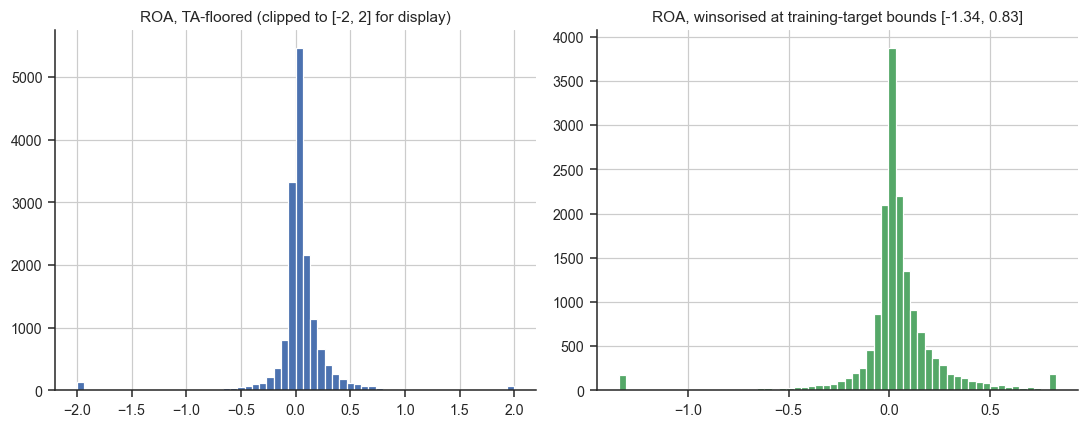

Share of targets beyond the training winsorisation bounds (%), by split:


,at_lower,at_upper
split,,
test,1.26,1.26
train,1.00,1.00
valid,1.36,0.86


In [26]:
outlier_summary = pd.DataFrame({
    "skew": ml_df[["TA", "Sales", "ROA_raw", "ROA"]].apply(lambda s: skew(s.dropna())),
    "kurtosis": ml_df[["TA", "Sales", "ROA_raw", "ROA"]].apply(lambda s: kurtosis(s.dropna())),
})
display(outlier_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ml_df["ROA_raw"].clip(-2, 2).hist(bins=60, ax=axes[0], color=PALETTE["blue"])
axes[0].set_title("ROA, TA-floored (clipped to [-2, 2] for display)")
ml_df["ROA"].hist(bins=60, ax=axes[1], color=PALETTE["green"])
axes[1].set_title(f"ROA, winsorised at training-target bounds [{ROA_LO:.2f}, {ROA_HI:.2f}]")
plt.tight_layout(); plt.show()

split_label = np.select([ml_df["year"] <= TRAIN_END_YEAR, ml_df["year"] == VALID_FEATURE_YEAR,
                         ml_df["year"].isin(TEST_FEATURE_YEARS)], ["train", "valid", "test"], default="unused")
tgt = ml_df[TARGET_RAW]
at_bound = pd.DataFrame({"split": split_label, "at_lower": tgt <= ROA_LO, "at_upper": tgt >= ROA_HI, "has_target": tgt.notna()})
at_bound = at_bound[at_bound["has_target"]].groupby("split")[["at_lower", "at_upper"]].mean().mul(100).round(2)
print("Share of targets beyond the training winsorisation bounds (%), by split:")
display(at_bound)


## 15. Target Analysis and the Persistence Ceiling

count    14685.0000
mean         0.0353
std          0.2506
min         -1.3428
25%         -0.0126
50%          0.0256
75%          0.1037
max          0.8268
Skew: -1.880 | Kurtosis: 12.032

Corr(ROA_t, ROA_t+1): all rows 0.480 | training rows 0.458
AR(1) on training rows: ROA_t+1 = 0.0200 + 0.460 * ROA_t  ->  in-sample R2 = rho^2 = 0.210

Corr(ROA_t, ROA_t+1) by feature year:
2016    0.451
2017    0.405
2018    0.492
2019    0.513
2020    0.401
2021    0.436
2022    0.504
2023    0.550
2024    0.541


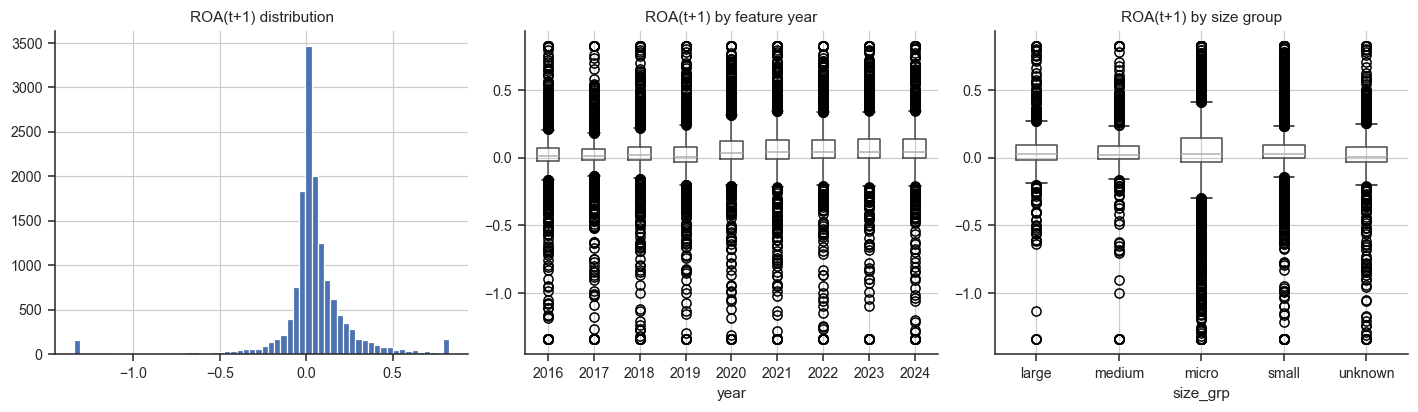

In [27]:
target_df = ml_df[ml_df[TARGET].notna()]
print(target_df[TARGET].describe().round(4).to_string())
print(f"Skew: {skew(target_df[TARGET]):.3f} | Kurtosis: {kurtosis(target_df[TARGET]):.3f}")

both = target_df.dropna(subset=["ROA_t"])
rho_all = both["ROA_t"].corr(both[TARGET])
tr = both[both["year"] <= TRAIN_END_YEAR]
rho_tr = tr["ROA_t"].corr(tr[TARGET])
slope, intercept = np.polyfit(tr["ROA_t"], tr[TARGET], 1)
print(f"\nCorr(ROA_t, ROA_t+1): all rows {rho_all:.3f} | training rows {rho_tr:.3f}")
print(f"AR(1) on training rows: ROA_t+1 = {intercept:.4f} + {slope:.3f} * ROA_t  ->  in-sample R2 = rho^2 = {rho_tr**2:.3f}")
print("\nCorr(ROA_t, ROA_t+1) by feature year:")
print(pd.Series({y: g["ROA_t"].corr(g[TARGET]) for y, g in both.groupby("year")}).round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
target_df[TARGET].hist(bins=60, ax=axes[0], color=PALETTE["blue"]); axes[0].set_title("ROA(t+1) distribution")
target_df.boxplot(column=TARGET, by="year", ax=axes[1]); axes[1].set_title("ROA(t+1) by feature year"); plt.suptitle("")
target_df.boxplot(column=TARGET, by="size_grp", ax=axes[2]); axes[2].set_title("ROA(t+1) by size group"); plt.suptitle("")
plt.tight_layout(); plt.show()

## 16. Feature Engineering and Feature Sets

In [28]:
# Numeric hygiene for every ratio column that can enter a feature set.
ratio_sources = sorted(set(FEATURE_COLS_SPEC_B) | {"X29_real", "X55_real"})
ml_df[ratio_sources] = (ml_df[ratio_sources].apply(pd.to_numeric, errors="coerce")
                        .replace([np.inf, -np.inf], np.nan).astype(float))

RATIO_A = [{"X29": "X29_real", "X55": "X55_real"}.get(x, x) for x in FEATURE_COLS_SPEC_A]

# Firm characteristics
BOOL_MAP = {True: 1.0, False: 0.0, "True": 1.0, "False": 0.0, "TRUE": 1.0, "FALSE": 0.0, "true": 1.0, "false": 0.0, "1": 1.0, "0": 0.0}
def to_binary(s):
    if pd.api.types.is_numeric_dtype(s) or pd.api.types.is_bool_dtype(s):
        return s.astype(float)
    return pd.to_numeric(s.map(BOOL_MAP), errors="coerce")

ml_df["firm_age"] = (ml_df["year"] - pd.to_datetime(ml_df["incorporationDate"], errors="coerce").dt.year).clip(lower=0)
ml_df["isBranch"] = to_binary(ml_df["isBranch"])
ml_df["meets_threshold"] = to_binary(ml_df["meets_threshold"])
for c in ("n_persons", "n_activities"):
    ml_df[c] = pd.to_numeric(ml_df[c], errors="coerce")

# Sector: NACE division (first two digits of the 8-digit KAD code of the primary activity)
def kad_division(v):
    if pd.isna(v):
        return np.nan
    s = re.sub(r"\D", "", re.sub(r"\.0+$", "", str(v).strip()))
    if len(s) == 7:
        s = "0" + s
    return s[:2] if len(s) >= 2 else np.nan

ml_df["kad_division"] = ml_df["primary_kad"].apply(kad_division)
ml_df["sector"] = ml_df["kad_division"]
print(f"Sector (KAD division) available for {100*ml_df['sector'].notna().mean():.1f}% of rows; "
      f"{ml_df['sector'].nunique()} divisions; top divisions (% of rows):")
print(ml_df["sector"].value_counts(normalize=True).mul(100).round(1).head(8).to_string())

# Are the registry attributes time-varying? Share of firms whose value changes across years.
rows = []
for c in ["size_category", "n_persons", "n_activities", "meets_threshold", "isBranch", "legalType", "region_group", "sector"]:
    nun = ml_df.groupby("gemh_id")[c].nunique(dropna=True)
    rows.append(dict(attribute=c, share_of_firms_with_any_change=round(float((nun > 1).mean()), 4)))
static_check = pd.DataFrame(rows).set_index("attribute")
display(static_check)
static_attrs = static_check.index[static_check["share_of_firms_with_any_change"] < 0.01].tolist()
varying_attrs = static_check.index[static_check["share_of_firms_with_any_change"] >= 0.01].tolist()
print(f"Static within firm (one snapshot repeated over all years): {static_attrs}")
print(f"Time-varying: {varying_attrs}")

# Categorical dummies (levels chosen on training-year rows only)
train_row_mask = ml_df["year"] <= TRAIN_END_YEAR
def sanitize(name):
    return re.sub(r"[\[\]<>\s]+", "_", str(name))

def collapse_rare(s, fit_mask, min_n):
    s = s.astype("object").where(s.notna(), "unknown").astype(str)
    counts = s[fit_mask].value_counts()
    keep = set(counts[counts >= min_n].index) | {"unknown"}
    return s.where(s.isin(keep), "other")

def dummies_for(col):
    cat = collapse_rare(ml_df[col], train_row_mask, MIN_CAT_TRAIN)
    d = pd.get_dummies(cat, prefix=col, dtype=float)
    d.columns = [sanitize(c) for c in d.columns]
    return d

dummy_frames = [dummies_for(c) for c in ("legalType", "region_group", "size_category", "sector")]
new_cols = pd.concat(dummy_frames, axis=1)
assert not (set(new_cols.columns) & set(ml_df.columns)), "dummy column name collides with an existing column"
ml_df = pd.concat([ml_df, new_cols], axis=1)

LEGAL_DUMMIES = [c for c in ml_df.columns if c.startswith("legalType_")]
REGION_DUMMIES = [c for c in ml_df.columns if c.startswith("region_group_")]
SIZE_DUMMIES = [c for c in ml_df.columns if c.startswith("size_category_")]
SECTOR_DUMMIES = [c for c in ml_df.columns if c.startswith("sector_")]
# Year-level state variable: cross-sectional median ROA of the feature year (known at forecast time, extrapolates to new years)
ml_df["ROA_med_t"] = ml_df.groupby("year")["ROA"].transform("median")

# Multi-year profit history (winsorised ROA of years t-1 and t-2; mean and minimum of the available values of t-2..t, at least two)
ml_df["ROA_lag1"] = value_at_year_offset(ml_df, "ROA", -1)
ml_df["ROA_lag2"] = value_at_year_offset(ml_df, "ROA", -2)
_hist = ml_df[["ROA_t", "ROA_lag1", "ROA_lag2"]]
_enough = _hist.notna().sum(axis=1) >= 2
ml_df["ROA_mean3"] = _hist.mean(axis=1).where(_enough)
ml_df["ROA_min3"] = _hist.min(axis=1).where(_enough)
HISTORY_COLS = ["ROA_lag1", "ROA_lag2", "ROA_mean3", "ROA_min3"]

# Longer history: years t-3 and t-4, and mean, minimum and standard deviation over the available values of t-4..t (at least three)
ml_df["ROA_lag3"] = value_at_year_offset(ml_df, "ROA", -3)
ml_df["ROA_lag4"] = value_at_year_offset(ml_df, "ROA", -4)
_hist5 = ml_df[["ROA_t", "ROA_lag1", "ROA_lag2", "ROA_lag3", "ROA_lag4"]]
_enough5 = _hist5.notna().sum(axis=1) >= 3
ml_df["ROA_mean5"] = _hist5.mean(axis=1).where(_enough5)
ml_df["ROA_min5"] = _hist5.min(axis=1).where(_enough5)
ml_df["ROA_std5"] = _hist5.std(axis=1, ddof=0).where(_enough5)
HISTORY5_EXTRA = ["ROA_lag3", "ROA_lag4", "ROA_mean5", "ROA_min5", "ROA_std5"]
print("Rows with the full ROA history (t, t-1, t-2 all observed): "
      f"{100*ml_df[['ROA_t', 'ROA_lag1', 'ROA_lag2']].notna().all(axis=1).mean():.1f}% of all rows")

CHAR_SAFE = ["firm_age", "isBranch"] + LEGAL_DUMMIES + REGION_DUMMIES
STATIC_REGISTRY_COLS = ["n_persons", "n_activities", "meets_threshold"]

FEATURE_SETS = {
    "A": RATIO_A + CHAR_SAFE,
    "C": RATIO_A + CHAR_SAFE + ["ROA_t"],
    "B": RATIO_A + EXCLUDE_MODERATE_A_ONLY + CHAR_SAFE,
    "A+static": RATIO_A + CHAR_SAFE + STATIC_REGISTRY_COLS,
    "A+size": RATIO_A + CHAR_SAFE + SIZE_DUMMIES,
    "A+macro": RATIO_A + CHAR_SAFE + ["ROA_med_t"],
    "A-nochar": RATIO_A + ["firm_age"],
    "A+sector": RATIO_A + CHAR_SAFE + SECTOR_DUMMIES,
    "C+B": RATIO_A + EXCLUDE_MODERATE_A_ONLY + CHAR_SAFE + ["ROA_t"],
    "C+sector": RATIO_A + CHAR_SAFE + ["ROA_t"] + SECTOR_DUMMIES,
    "C-nochar": RATIO_A + ["firm_age", "ROA_t"],
    "S": ["ROA_t"] + SECTOR_DUMMIES,
    "R": ["ROA_t"],
    "R3": ["ROA_t"] + HISTORY_COLS,
    "C3": RATIO_A + CHAR_SAFE + ["ROA_t"] + HISTORY_COLS,
    "C-noRE": [c for c in RATIO_A + CHAR_SAFE + ["ROA_t"] if c not in ("X6", "X25")],
    "R5": ["ROA_t"] + HISTORY_COLS + HISTORY5_EXTRA,
    "C5": RATIO_A + CHAR_SAFE + ["ROA_t"] + HISTORY_COLS + HISTORY5_EXTRA,
}

FORBIDDEN = {TARGET, TARGET_RAW, "TA_t1", "NP_t1", "ROA_raw", "ROA_unfloored", "ROA"}
for name, cols in FEATURE_SETS.items():
    assert len(cols) == len(set(cols)), f"duplicate columns in feature set {name}"
    missing = [c for c in cols if c not in ml_df.columns]
    assert not missing, f"missing columns in set {name}: {missing}"
    assert not (set(cols) & FORBIDDEN), f"target-derived column in feature set {name}"
    assert not (set(cols) & {"gemh_id", "afm", "year"}), f"identifier in feature set {name}"
    ml_df[cols] = ml_df[cols].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).astype(float)
print({k: len(v) for k, v in FEATURE_SETS.items()})

Sector (KAD division) available for 91.0% of rows; 67 divisions; top divisions (% of rows):
sector
46    16.3
55    10.3
68     7.5
35     7.1
41     4.3
47     4.3
71     3.1
69     3.0


,share_of_firms_with_any_change
attribute,
size_category,0.5435
n_persons,0.0000
n_activities,0.0000
meets_threshold,0.0000
isBranch,0.0000
legalType,0.0000
region_group,0.0000
sector,0.0000


Static within firm (one snapshot repeated over all years): ['n_persons', 'n_activities', 'meets_threshold', 'isBranch', 'legalType', 'region_group', 'sector']
Time-varying: ['size_category']
Rows with the full ROA history (t, t-1, t-2 all observed): 56.2% of all rows
{'A': 75, 'C': 76, 'B': 78, 'A+static': 78, 'A+size': 80, 'A+macro': 76, 'A-nochar': 32, 'A+sector': 127, 'C+B': 79, 'C+sector': 128, 'C-nochar': 33, 'S': 53, 'R': 1, 'R3': 5, 'C3': 80, 'C-noRE': 74, 'R5': 10, 'C5': 85}


## 17. Train / Validation / Test Design

In [29]:
has_target = ml_df[TARGET].notna()
excluded_tier = ml_df["extraction_tier"].isin(EXCLUDE_TIERS) | ml_df["extraction_tier_t1"].isin(EXCLUDE_TIERS)
print(f"Rows with a target: {int(has_target.sum()):,}; excluded because the tier is in {EXCLUDE_TIERS} at t or t+1: "
      f"{int((has_target & excluded_tier).sum()):,}")
model_df = ml_df[has_target & ~excluded_tier].reset_index(drop=True)
TRAIN_DF = model_df[model_df["year"] <= TRAIN_END_YEAR].reset_index(drop=True)
VALID_DF = model_df[model_df["year"] == VALID_FEATURE_YEAR].reset_index(drop=True)
TRVAL_DF = model_df[model_df["year"] <= VALID_FEATURE_YEAR].reset_index(drop=True)
TEST_DF = model_df[model_df["year"].isin(TEST_FEATURE_YEARS)].reset_index(drop=True)

assert len(TRAIN_DF) + len(VALID_DF) + len(TEST_DF) == len(model_df), \
    "every row with a target must belong to exactly one of train / validation / test"
assert TEST_DF["year"].max() + 1 <= LAST_PANEL_YEAR
assert TEST_DF[TARGET_RAW].notna().all()
assert TRAIN_DF["year"].max() < VALID_DF["year"].min() <= VALID_DF["year"].max() < TEST_DF["year"].min()

print(f"Train : feature years <= {TRAIN_END_YEAR}      -> {len(TRAIN_DF):>6,} rows, {TRAIN_DF['gemh_id'].nunique():,} firms")
print(f"Valid : feature year {VALID_FEATURE_YEAR}          -> {len(VALID_DF):>6,} rows, {VALID_DF['gemh_id'].nunique():,} firms")
print(f"Test  : feature year(s) {TEST_FEATURE_YEARS}    -> {len(TEST_DF):>6,} rows, {TEST_DF['gemh_id'].nunique():,} firms "
      f"(target year(s) {[y+1 for y in TEST_FEATURE_YEARS]})")
print(f"Test feature years actually present: {sorted(TEST_DF['year'].unique().tolist())}")
print(f"Rows outside the modelling sample: {len(ml_df) - len(model_df):,} "
      f"(no target, incl. all {int((ml_df['year'] == LAST_PANEL_YEAR).sum()):,} rows of feature year {LAST_PANEL_YEAR} which have no year+1, "
      f"or excluded extraction tier)")

def temporal_folds(df, cv_years):
    # Expanding-window folds: train on feature years <= y-1, validate on feature year y.
    yr = df["year"].values
    idx = np.arange(len(df))
    folds = []
    for y in cv_years:
        tr, va = idx[yr <= y - 1], idx[yr == y]
        if len(tr) and len(va):
            folds.append((tr, va))
    return folds

CV_FOLDS = temporal_folds(TRAIN_DF, CV_VAL_YEARS)
print("\nTemporal CV folds inside the training period (train rows -> validation rows):")
for (tr, va), y in zip(CV_FOLDS, CV_VAL_YEARS):
    print(f"  validate feature year {y}: train on {len(tr):>5,} rows (years <= {y-1}), validate on {len(va):>5,} rows")

import sklearn as _sk, xgboost as _xg
NEW_SETS = ("R5", "C5")     # added after the first cached run; excluded from the signature so earlier cache entries stay valid
_sig_sets = {k: v for k, v in FEATURE_SETS.items() if k not in NEW_SETS}
_all_feature_cols = sorted(set(c for cols in _sig_sets.values() for c in cols))
_data_hash = int(pd.util.hash_pandas_object(model_df[_all_feature_cols + [TARGET, TARGET_RAW, "year", "gemh_id"]], index=False).sum())
CACHE_SIG = (_data_hash, TRAIN_END_YEAR, VALID_FEATURE_YEAR, tuple(TEST_FEATURE_YEARS), tuple(CV_VAL_YEARS), RANDOM_STATE, tuple(WINSOR_Q),
             TA_FLOOR, tuple(EXCLUDE_TIERS), MIN_CAT_TRAIN, _sk.__version__, _xg.__version__, SEARCH_SPACE_TAG,
             tuple((k, tuple(v)) for k, v in _sig_sets.items()))
print(f"\nCache signature {_sig(*CACHE_SIG)} (data hash, split, configuration, feature sets and library versions); cache directory: {CACHE_DIR}")

Rows with a target: 14,685; excluded because the tier is in ['scan_unprocessed'] at t or t+1: 11
Train : feature years <= 2022      -> 11,390 rows, 1,906 firms
Valid : feature year 2023          ->  1,622 rows, 1,622 firms
Test  : feature year(s) [2024]    ->  1,662 rows, 1,662 firms (target year(s) [2025])
Test feature years actually present: [2024]
Rows outside the modelling sample: 5,326 (no target, incl. all 2,000 rows of feature year 2025 which have no year+1, or excluded extraction tier)

Temporal CV folds inside the training period (train rows -> validation rows):
  validate feature year 2019: train on 4,871 rows (years <= 2018), validate on 1,626 rows
  validate feature year 2020: train on 6,497 rows (years <= 2019), validate on 1,646 rows
  validate feature year 2021: train on 8,143 rows (years <= 2020), validate on 1,621 rows
  validate feature year 2022: train on 9,764 rows (years <= 2021), validate on 1,626 rows

Cache signature 8ac401613659685f (data hash, split, configura

## 18. Benchmarks and Model Pipelines

In [30]:
def build_benchmarks():
    return {
        "Mean": DummyRegressor(strategy="mean"),
        "Persistence": PersistenceModel(),
        "AR1": Pipeline([("sel", ColumnTransformer([("roa", "passthrough", ["ROA_t"])])),
                         ("imp", make_imputer()),
                         ("lr", LinearRegression())]),
        "AR1_LAD": Pipeline([("sel", ColumnTransformer([("roa", "passthrough", ["ROA_t"])])),
                             ("imp", make_imputer()),
                             ("lr", QuantileRegressor(quantile=0.5, alpha=0.0, solver="highs"))]),
        # AR(1) with sector effects: the standard "persistence plus industry" benchmark of the profitability literature
        "AR1_SECTOR": Pipeline([("imp", make_imputer()), ("lr", Ridge(alpha=1.0))]),
    }

def build_ridge():
    return Pipeline([("clip", QuantileClipper(*WINSOR_Q)), ("imp", make_imputer()),
                     ("sc", StandardScaler()), ("model", Ridge())])

def build_rf():
    return Pipeline([("imp", make_imputer()),
                     ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))])

def build_xgb(objective):
    return Pipeline([("model", XGBRegressor(objective=objective, tree_method="hist", n_jobs=1,
                                            random_state=RANDOM_STATE, verbosity=0))])

RIDGE_SPACE = {"model__alpha": np.logspace(-2, 4, 13)}
RF_SPACE = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [6, 10, 14, None],
    "model__min_samples_leaf": [5, 10, 20, 50],
    "model__max_features": [0.2, 0.33, 0.5, 1.0],
    "model__max_samples": [0.5, 0.8, None],
}
XGB_SPACE = {
    "model__n_estimators": randint(100, 801),
    "model__learning_rate": loguniform(0.01, 0.15),
    "model__max_depth": randint(2, 7),
    "model__min_child_weight": loguniform(3, 100),
    "model__subsample": uniform(0.5, 0.5),
    "model__colsample_bytree": uniform(0.3, 0.7),
    "model__reg_lambda": loguniform(1, 100),
    "model__reg_alpha": loguniform(1e-3, 10),
    "model__gamma": uniform(0, 5),
}
XGB_HUBER_SPACE = {**XGB_SPACE, "model__huber_slope": [0.1, 0.3, 1.0]}

MODEL_SPECS = {}
for _fs in ("A", "C"):
    MODEL_SPECS[f"Ridge_{_fs}"]      = dict(kind="ridge",     feats=_fs, scoring="neg_root_mean_squared_error")
    MODEL_SPECS[f"RF_{_fs}"]         = dict(kind="rf",        feats=_fs, scoring="neg_root_mean_squared_error")
    MODEL_SPECS[f"XGB_L2_{_fs}"]     = dict(kind="xgb_l2",    feats=_fs, scoring="neg_root_mean_squared_error")
    MODEL_SPECS[f"XGB_Huber_{_fs}"]  = dict(kind="xgb_huber", feats=_fs, scoring="neg_mean_absolute_error")
# Nonlinear persistence: XGBoost on ROA_t alone (benchmark learners, never eligible for BEST)
MODEL_SPECS["XGB_L2_R"]    = dict(kind="xgb_l2",    feats="R", scoring="neg_root_mean_squared_error")
MODEL_SPECS["XGB_Huber_R"] = dict(kind="xgb_huber", feats="R", scoring="neg_mean_absolute_error")
# Profit-history controls: ROA history only (R3) and ratios plus ROA history (C3); XGBoost learners only
for _fs in ("R3", "C3", "R5", "C5"):
    MODEL_SPECS[f"XGB_L2_{_fs}"]    = dict(kind="xgb_l2",    feats=_fs, scoring="neg_root_mean_squared_error")
    MODEL_SPECS[f"XGB_Huber_{_fs}"] = dict(kind="xgb_huber", feats=_fs, scoring="neg_mean_absolute_error")
BENCH_NAMES = ["Mean", "Persistence", "AR1", "AR1_LAD", "AR1_SECTOR"]
BENCH_COLS = {"AR1_SECTOR": FEATURE_SETS["S"]}          # every other benchmark uses ROA_t only
# Families: fixed averages of the tree learners of each feature set. The headline claims use the families, so they do not
# depend on which single learner happens to win the validation year.
ENSEMBLES = {"ENS_C": ["RF_C", "XGB_L2_C", "XGB_Huber_C"],
             "ENS_A": ["RF_A", "XGB_L2_A", "XGB_Huber_A"],
             "ENS_R": ["XGB_L2_R", "XGB_Huber_R"],
             "ENS_R3": ["XGB_L2_R3", "XGB_Huber_R3"],
             "ENS_C3": ["XGB_L2_C3", "XGB_Huber_C3"],
             "ENS_R5": ["XGB_L2_R5", "XGB_Huber_R5"],
             "ENS_C5": ["XGB_L2_C5", "XGB_Huber_C5"]}
FAM_C, FAM_A, FAM_R = "ENS_C", "ENS_A", "ENS_R"
print("Tuned models:", list(MODEL_SPECS))
print("Benchmarks  :", BENCH_NAMES)
print("Feature-set sizes:", {k: len(v) for k, v in FEATURE_SETS.items() if k in ('A', 'C', 'R')})

Tuned models: ['Ridge_A', 'RF_A', 'XGB_L2_A', 'XGB_Huber_A', 'Ridge_C', 'RF_C', 'XGB_L2_C', 'XGB_Huber_C', 'XGB_L2_R', 'XGB_Huber_R', 'XGB_L2_R3', 'XGB_Huber_R3', 'XGB_L2_C3', 'XGB_Huber_C3', 'XGB_L2_R5', 'XGB_Huber_R5', 'XGB_L2_C5', 'XGB_Huber_C5']
Benchmarks  : ['Mean', 'Persistence', 'AR1', 'AR1_LAD', 'AR1_SECTOR']
Feature-set sizes: {'A': 75, 'C': 76, 'R': 1}


## 19. Hyper-Parameter Search and Model Selection

In [31]:
def run_search(name, spec):
    cols = FEATURE_SETS[spec["feats"]]
    kind = spec["kind"]
    if kind == "ridge":
        s = GridSearchCV(build_ridge(), RIDGE_SPACE, cv=CV_FOLDS, scoring=spec["scoring"], n_jobs=N_JOBS, refit=True, error_score="raise")
    elif kind == "rf":
        s = RandomizedSearchCV(build_rf(), RF_SPACE, n_iter=SEARCH_N_ITER["rf"], cv=CV_FOLDS, scoring=spec["scoring"],
                               n_jobs=N_JOBS, random_state=RANDOM_STATE, refit=True, error_score="raise")
    elif kind == "xgb_l2":
        s = RandomizedSearchCV(build_xgb("reg:squarederror"), XGB_SPACE, n_iter=SEARCH_N_ITER["xgb"], cv=CV_FOLDS,
                               scoring=spec["scoring"], n_jobs=N_JOBS, random_state=RANDOM_STATE, refit=True, error_score="raise")
    elif kind == "xgb_huber":
        s = RandomizedSearchCV(build_xgb("reg:pseudohubererror"), XGB_HUBER_SPACE, n_iter=SEARCH_N_ITER["xgb"],
                               cv=CV_FOLDS, scoring=spec["scoring"], n_jobs=N_JOBS, random_state=RANDOM_STATE, refit=True, error_score="raise")
    else:
        raise ValueError(kind)
    s.fit(TRAIN_DF[cols], TRAIN_DF[TARGET])
    return s

TUNED = {}
tuning_rows = []
for name, spec in MODEL_SPECS.items():
    t0 = time.time()
    TUNED[name] = cached(f"tuned_{name}", (CACHE_SIG, name, spec, SEARCH_N_ITER),
                         lambda: to_result(run_search(name, spec), round(time.time() - t0, 1)))
    s = TUNED[name]
    metric = "RMSE" if "root_mean_squared" in spec["scoring"] else "MAE"
    tuning_rows.append(dict(Model=name, features=spec["feats"], cv_metric=metric, cv_score=-s.best_score_,
                            cv_std_over_folds=s.cv_results_["std_test_score"][s.best_index_],
                            seconds=getattr(s, "seconds", None) or round(time.time() - t0, 1),
                            best_params={k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v)
                                         for k, v in s.best_params_.items()}))
    print(f"{name:<15s} temporal-CV {metric} = {-s.best_score_:.4f}  ({time.time()-t0:.0f}s)")
tuning_df = pd.DataFrame(tuning_rows).set_index("Model")
display(tuning_df)
tuning_df.to_csv(os.path.join(RESULTS_DIR, "tuning_results.csv"))

Ridge_A         temporal-CV RMSE = 0.2393  (15s)
RF_A            temporal-CV RMSE = 0.2277  (658s)
XGB_L2_A        temporal-CV RMSE = 0.2296  (59s)
XGB_Huber_A     temporal-CV MAE = 0.1238  (54s)
Ridge_C         temporal-CV RMSE = 0.2218  (2s)
RF_C            temporal-CV RMSE = 0.2165  (670s)
XGB_L2_C        temporal-CV RMSE = 0.2174  (59s)
XGB_Huber_C     temporal-CV MAE = 0.1108  (56s)
XGB_L2_R        temporal-CV RMSE = 0.2211  (14s)
XGB_Huber_R     temporal-CV MAE = 0.1128  (15s)
XGB_L2_R3       temporal-CV RMSE = 0.2150  (17s)
XGB_Huber_R3    temporal-CV MAE = 0.1069  (17s)
XGB_L2_C3       temporal-CV RMSE = 0.2145  (63s)
XGB_Huber_C3    temporal-CV MAE = 0.1066  (58s)
XGB_L2_R5       temporal-CV RMSE = 0.2151  (21s)
XGB_Huber_R5    temporal-CV MAE = 0.1069  (20s)
XGB_L2_C5       temporal-CV RMSE = 0.2145  (62s)
XGB_Huber_C5    temporal-CV MAE = 0.1064  (61s)


,features,cv_metric,cv_score,cv_std_over_folds,seconds,best_params
Model,,,,,,
Ridge_A,A,RMSE,0.239250,0.012034,15.0,{'alpha': 316.2278}
RF_A,A,RMSE,0.227662,0.011264,656.7,"{'n_estimators': 400, 'min_samples_leaf': 10, ..."
XGB_L2_A,A,RMSE,0.229619,0.010968,58.6,"{'colsample_bytree': 0.4306, 'gamma': 0.2039, ..."
XGB_Huber_A,A,MAE,0.123752,0.007763,53.8,"{'colsample_bytree': 0.5698, 'gamma': 0.0798, ..."
Ridge_C,C,RMSE,0.221777,0.013337,2.3,{'alpha': 316.2278}
RF_C,C,RMSE,0.216507,0.013858,668.1,"{'n_estimators': 400, 'min_samples_leaf': 10, ..."
XGB_L2_C,C,RMSE,0.217374,0.012799,58.9,"{'colsample_bytree': 0.6146, 'gamma': 0.4771, ..."
XGB_Huber_C,C,MAE,0.110768,0.007212,55.6,"{'colsample_bytree': 0.811, 'gamma': 0.2386, '..."
XGB_L2_R,R,RMSE,0.221115,0.014077,14.1,"{'colsample_bytree': 0.6146, 'gamma': 0.4771, ..."


In [32]:
# Boundary check: a winner on the edge of its search space means the space was not wide enough in that direction.
# Log-uniform parameters are judged on the log scale, list parameters by their extreme values.
def boundary_report(name):
    s = TUNED[name]
    kind = MODEL_SPECS[name]["kind"]
    space = {"ridge": RIDGE_SPACE, "rf": RF_SPACE, "xgb_l2": XGB_SPACE, "xgb_huber": XGB_HUBER_SPACE}[kind]
    out = []
    for p_, dist in space.items():
        v = s.best_params_[p_]
        short = p_.replace("model__", "")
        if isinstance(dist, (list, np.ndarray)):
            vals = [x for x in dist if x is not None]
            if v is not None and len(vals) > 2:
                if v == min(vals):
                    out.append(f"{short}={v} (lowest value tried)")
                elif v == max(vals):
                    out.append(f"{short}={v} (highest value tried)")
        else:
            lo, hi = dist.support()
            is_log = getattr(getattr(dist, "dist", None), "name", "") == "loguniform"
            x, a, b = (np.log(v), np.log(lo), np.log(hi)) if is_log else (v, lo, hi)
            span = b - a
            if span > 0 and x <= a + 0.03 * span:
                out.append(f"{short}={v:.4g} (lower edge of [{lo:.3g}, {hi:.3g}])")
            elif span > 0 and x >= b - 0.03 * span:
                out.append(f"{short}={v:.4g} (upper edge of [{lo:.3g}, {hi:.3g}])")
    return out

print("Best configurations on or near the edge of the search space:")
for name in MODEL_SPECS:
    b = boundary_report(name)
    print(f"  {name:<15s} {'; '.join(b) if b else 'interior'}")

Best configurations on or near the edge of the search space:
  Ridge_A         interior
  RF_A            interior
  XGB_L2_A        interior
  XGB_Huber_A     gamma=0.07983 (lower edge of [0, 5])
  Ridge_C         interior
  RF_C            interior
  XGB_L2_C        max_depth=6 (upper edge of [2, 6])
  XGB_Huber_C     max_depth=6 (upper edge of [2, 6])
  XGB_L2_R        max_depth=6 (upper edge of [2, 6])
  XGB_Huber_R     gamma=0.07983 (lower edge of [0, 5])
  XGB_L2_R3       interior
  XGB_Huber_R3    gamma=0.07983 (lower edge of [0, 5])
  XGB_L2_C3       interior
  XGB_Huber_C3    gamma=0.07983 (lower edge of [0, 5])
  XGB_L2_R5       max_depth=2 (lower edge of [2, 6]); gamma=0.07728 (lower edge of [0, 5])
  XGB_Huber_R5    gamma=0.09038 (lower edge of [0, 5])
  XGB_L2_C5       interior
  XGB_Huber_C5    interior


In [33]:
# Validation-year predictions: every tuned model is the search's refit on the FULL training period.
def fit_predict(est, cols, fit_df, pred_df):
    m = clone(est).fit(fit_df[cols], fit_df[TARGET])
    return m, m.predict(pred_df[cols])

ref_mean_valid = TRAIN_DF[TARGET].mean()
bench = build_benchmarks()
VALID_PRED = {}
for b in BENCH_NAMES:
    _, VALID_PRED[b] = fit_predict(bench[b], BENCH_COLS.get(b, ["ROA_t"]), TRAIN_DF, VALID_DF)
for name, spec in MODEL_SPECS.items():
    VALID_PRED[name] = TUNED[name].best_estimator_.predict(VALID_DF[FEATURE_SETS[spec["feats"]]])
for ens, members in ENSEMBLES.items():
    VALID_PRED[ens] = np.mean([VALID_PRED[m] for m in members], axis=0)

valid_table = pd.DataFrame([ev(VALID_DF[TARGET], VALID_PRED[n], ref_mean_valid, n) for n in BENCH_NAMES + list(MODEL_SPECS) + list(ENSEMBLES)]) \
    .set_index("Model")
print(f"Validation year (feature year {VALID_FEATURE_YEAR}, n = {len(VALID_DF):,}):")
display(valid_table.sort_values(SELECTION_METRIC).round(4))

ELIGIBLE = [n for n in MODEL_SPECS if n.endswith("_A") or n.endswith("_C")]
BEST_NAME = min(ELIGIBLE, key=lambda n: valid_table.loc[n, SELECTION_METRIC])
BEST_A_NAME = min([n for n in ELIGIBLE if n.endswith("_A")], key=lambda n: valid_table.loc[n, SELECTION_METRIC])
BEST_C_NAME = min([n for n in ELIGIBLE if n.endswith("_C")], key=lambda n: valid_table.loc[n, SELECTION_METRIC])
BEST_R_NAME = min([n for n in MODEL_SPECS if n.endswith("_R")], key=lambda n: valid_table.loc[n, SELECTION_METRIC])
BEST_COLS = FEATURE_SETS[MODEL_SPECS[BEST_NAME]["feats"]]

ranked = valid_table.loc[ELIGIBLE, SELECTION_METRIC].sort_values()
margin = ranked.iloc[1] - ranked.iloc[0]
print(f"\nSelected on validation {SELECTION_METRIC}: BEST = {BEST_NAME}  (best A: {BEST_A_NAME}, best C: {BEST_C_NAME}, "
      f"best nonlinear ROA-only: {BEST_R_NAME})")
print(f"Margin to the runner-up ({ranked.index[1]}): {margin:.4f}  "
      f"({'above' if margin >= MIN_DELTA[SELECTION_METRIC] else 'below'} MIN_DELTA = {MIN_DELTA[SELECTION_METRIC]})")
d_sel = paired_delta_ci(VALID_DF[TARGET].values, VALID_PRED[ranked.index[0]], VALID_PRED[ranked.index[1]], VALID_DF["gemh_id"].values)
print(f"Validation-year paired difference, best minus runner-up: RMSE {d_sel['RMSE'][0]:+.4f} "
      f"[{d_sel['RMSE'][1]:+.4f}, {d_sel['RMSE'][2]:+.4f}]  MAE {d_sel['MAE'][0]:+.4f} [{d_sel['MAE'][1]:+.4f}, {d_sel['MAE'][2]:+.4f}]")

Validation year (feature year 2023, n = 1,622):


,RMSE,MAE,MedAE,R2,R2_oos,Spearman,SignAcc
Model,,,,,,,
XGB_Huber_C3,0.2083,0.0992,0.0406,0.3503,0.3566,0.6678,0.8181
ENS_C5,0.2084,0.0995,0.0409,0.3498,0.3561,0.6705,0.8274
XGB_L2_C5,0.2084,0.1006,0.0418,0.3497,0.3560,0.6667,0.8305
ENS_C3,0.2085,0.0998,0.0414,0.3491,0.3555,0.6647,0.8249
XGB_L2_R5,0.2087,0.0994,0.0402,0.3480,0.3543,0.6812,0.8243
XGB_Huber_C5,0.2090,0.0991,0.0406,0.3460,0.3524,0.6707,0.8231
ENS_R5,0.2093,0.0991,0.0395,0.3444,0.3508,0.6809,0.8292
XGB_L2_C3,0.2098,0.1016,0.0410,0.3414,0.3479,0.6598,0.8249
XGB_Huber_R3,0.2100,0.1004,0.0418,0.3398,0.3462,0.6576,0.8237



Selected on validation RMSE: BEST = XGB_Huber_C  (best A: RF_A, best C: XGB_Huber_C, best nonlinear ROA-only: XGB_Huber_R)
Margin to the runner-up (RF_C): 0.0002  (below MIN_DELTA = 0.005)
Validation-year paired difference, best minus runner-up: RMSE -0.0002 [-0.0029, +0.0026]  MAE -0.0024 [-0.0038, -0.0009]


## 20. Final Fit and Single Test Scoring

In [34]:
ref_mean_test = TRVAL_DF[TARGET].mean()
FINAL, TEST_PRED = {}, {}
bench = build_benchmarks()
for b in BENCH_NAMES:
    FINAL[b], TEST_PRED[b] = fit_predict(bench[b], BENCH_COLS.get(b, ["ROA_t"]), TRVAL_DF, TEST_DF)
for name, spec in MODEL_SPECS.items():
    cols = FEATURE_SETS[spec["feats"]]
    FINAL[name], TEST_PRED[name] = fit_predict(TUNED[name].best_estimator_, cols, TRVAL_DF, TEST_DF)
for ens, members in ENSEMBLES.items():
    TEST_PRED[ens] = np.mean([TEST_PRED[m] for m in members], axis=0)

y_test = TEST_DF[TARGET].values
y_test_raw = TEST_DF[TARGET_RAW].values
groups_test = TEST_DF["gemh_id"].values
ALL_NAMES = BENCH_NAMES + list(MODEL_SPECS) + list(ENSEMBLES)

test_table = pd.DataFrame([ev(y_test, TEST_PRED[n], ref_mean_test, n) for n in ALL_NAMES]).set_index("Model")
print(f"TEST, descriptive (single feature year {TEST_FEATURE_YEARS} -> target year {[y+1 for y in TEST_FEATURE_YEARS]}, n = {len(TEST_DF):,}); "
      f"target: winsorised ROA(t+1)")
display(test_table.sort_values("RMSE").round(4))

raw_cols = ["MAE", "MedAE", "Spearman", "SignAcc"]
test_table_raw = pd.DataFrame([{**ev(y_test_raw, TEST_PRED[n], ref_mean_test), "Model": n} for n in ALL_NAMES]) \
    .set_index("Model")[raw_cols]
print("\nSame predictions scored against the UN-winsorised target (RMSE omitted: a single extreme ROA dominates it):")
display(test_table_raw.sort_values("MAE").round(4))
print(f"\nSelected model (validation): {BEST_NAME}")

TEST, descriptive (single feature year [2024] -> target year [2025], n = 1,662); target: winsorised ROA(t+1)


,RMSE,MAE,MedAE,R2,R2_oos,Spearman,SignAcc
Model,,,,,,,
XGB_L2_C5,0.2097,0.1017,0.0420,0.3630,0.3697,0.6665,0.8255
ENS_C5,0.2100,0.1007,0.0394,0.3612,0.3679,0.6714,0.8237
RF_C,0.2104,0.1034,0.0410,0.3587,0.3655,0.6493,0.8093
ENS_C3,0.2108,0.1000,0.0392,0.3564,0.3631,0.6724,0.8225
XGB_Huber_C3,0.2113,0.0993,0.0389,0.3536,0.3604,0.6754,0.8219
XGB_Huber_C5,0.2113,0.1006,0.0391,0.3536,0.3604,0.6736,0.8183
XGB_L2_C3,0.2115,0.1020,0.0416,0.3523,0.3591,0.6664,0.8243
ENS_C,0.2116,0.1024,0.0384,0.3520,0.3588,0.6513,0.8165
XGB_L2_R5,0.2126,0.1027,0.0398,0.3455,0.3523,0.6639,0.8117



Same predictions scored against the UN-winsorised target (RMSE omitted: a single extreme ROA dominates it):


,MAE,MedAE,Spearman,SignAcc
Model,,,,
XGB_Huber_C3,0.1577,0.0389,0.6754,0.8219
ENS_C3,0.1584,0.0392,0.6724,0.8225
XGB_Huber_C5,0.1590,0.0391,0.6735,0.8183
ENS_C5,0.1591,0.0394,0.6714,0.8237
XGB_Huber_R3,0.1592,0.0387,0.6671,0.8153
XGB_Huber_R5,0.1599,0.0392,0.6725,0.8183
ENS_R5,0.1600,0.0397,0.6705,0.8207
XGB_L2_C5,0.1600,0.0420,0.6665,0.8255
ENS_R3,0.1602,0.0391,0.6644,0.8195



Selected model (validation): XGB_Huber_C


In [35]:
def compare(model_a, model_b):
    return paired_delta_ci(y_test, TEST_PRED[model_a], TEST_PRED[model_b], groups_test)

def fmt_ci(t):
    return f"{t[0]:+.4f} [{t[1]:+.4f}, {t[2]:+.4f}]"

PRIMARY_COMPARISONS = [
    ("C vs AR1",         FAM_C, "AR1"),
    ("C vs Persistence", FAM_C, "Persistence"),
    ("C vs AR1_LAD",     FAM_C, "AR1_LAD"),
    ("C vs AR1_SECTOR",  FAM_C, "AR1_SECTOR"),
    ("C vs R",           FAM_C, FAM_R),
    ("A vs AR1",         FAM_A, "AR1"),
    ("A vs Mean",        FAM_A, "Mean"),
    ("C vs A",           FAM_C, FAM_A),
]
SECONDARY_COMPARISONS = [
    ("BEST_C vs AR1",    BEST_C_NAME, "AR1"),
    ("BEST_C vs BEST_R", BEST_C_NAME, BEST_R_NAME),
    ("BEST_A vs AR1",    BEST_A_NAME, "AR1"),
    ("BEST_A vs Mean",   BEST_A_NAME, "Mean"),
]
comp_rows, PRIMARY_DELTAS = [], {}
for label, a, b in PRIMARY_COMPARISONS:
    d = compare(a, b)
    PRIMARY_DELTAS[label] = d
    comp_rows.append({"comparison": label, "model": a, "reference": b,
                      "dRMSE [95% CI]": fmt_ci(d["RMSE"]), "dMAE [95% CI]": fmt_ci(d["MAE"]), "verdict": verdict(d)})
primary_table = pd.DataFrame(comp_rows).set_index("comparison")
print("PRIMARY COMPARISONS (families; difference = model minus reference; negative = model better; firm-clustered bootstrap):")
display(primary_table)

sec_rows, SECONDARY_DELTAS = [], {}
for label, a, b in SECONDARY_COMPARISONS:
    d = compare(a, b)
    SECONDARY_DELTAS[label] = d
    sec_rows.append({"comparison": label, "model": a, "reference": b,
                     "dRMSE [95% CI]": fmt_ci(d["RMSE"]), "dMAE [95% CI]": fmt_ci(d["MAE"]), "verdict": verdict(d)})
secondary_table = pd.DataFrame(sec_rows).set_index("comparison")
print("\nSECONDARY: the single learners selected on the validation year")
display(secondary_table)
SECONDARY_FRAMING_KEY = framing_from(SECONDARY_DELTAS["BEST_C vs AR1"], SECONDARY_DELTAS["BEST_C vs BEST_R"], SECONDARY_DELTAS["BEST_A vs Mean"])

print("\nEvery model against the AR(1) benchmark (descriptive; the primary claims are the rows above):")
all_rows = []
for n in ALL_NAMES:
    if n == "AR1":
        continue
    d = compare(n, "AR1")
    all_rows.append({"model": n, "dRMSE [95% CI]": fmt_ci(d["RMSE"]), "dMAE [95% CI]": fmt_ci(d["MAE"]), "verdict vs AR1": verdict(d)})
vs_ar1_table = pd.DataFrame(all_rows).set_index("model")
display(vs_ar1_table)

# Diebold-Mariano on squared errors as a cross-check (independent rows within one test year; interpret with care).
def dm_test(y_true, p1, p2):
    d = (np.asarray(y_true) - np.asarray(p1)) ** 2 - (np.asarray(y_true) - np.asarray(p2)) ** 2
    if d.var(ddof=1) == 0:
        return 0.0, 1.0
    stat = d.mean() / np.sqrt(d.var(ddof=1) / len(d))
    return float(stat), float(2 * (1 - stats.norm.cdf(abs(stat))))

dm_rows = []
for label, a, b in PRIMARY_COMPARISONS:
    s_, p_ = dm_test(y_test, TEST_PRED[a], TEST_PRED[b])
    dm_rows.append({"comparison": label, "DM statistic": s_, "p (raw)": p_})
dm_table = pd.DataFrame(dm_rows).set_index("comparison")
dm_table["p (Holm)"] = holm_adjust(dm_table["p (raw)"].values)
print("\nDiebold-Mariano cross-check on the primary comparisons (squared-error loss; negative = first model better), Holm-adjusted:")
display(dm_table.round(4))
print("Single test year: intervals describe sampling variation across firms, not across years.")

PRIMARY COMPARISONS (families; difference = model minus reference; negative = model better; firm-clustered bootstrap):


,model,reference,dRMSE [95% CI],dMAE [95% CI],verdict
comparison,,,,,
C vs AR1,ENS_C,AR1,"-0.0146 [-0.0231, -0.0063]","-0.0119 [-0.0151, -0.0089]",better
C vs Persistence,ENS_C,Persistence,"-0.0405 [-0.0619, -0.0193]","-0.0089 [-0.0158, -0.0023]",better
C vs AR1_LAD,ENS_C,AR1_LAD,"-0.0153 [-0.0269, -0.0038]","-0.0079 [-0.0116, -0.0043]",better
C vs AR1_SECTOR,ENS_C,AR1_SECTOR,"-0.0133 [-0.0215, -0.0046]","-0.0123 [-0.0156, -0.0092]",better
C vs R,ENS_C,ENS_R,"-0.0119 [-0.0192, -0.0046]","-0.0053 [-0.0079, -0.0026]",better
A vs AR1,ENS_A,AR1,"+0.0027 [-0.0082, +0.0131]","+0.0073 [+0.0030, +0.0115]","mixed (RMSE: indistinguishable, MAE: worse)"
A vs Mean,ENS_A,Mean,"-0.0353 [-0.0456, -0.0251]","-0.0207 [-0.0250, -0.0163]",better
C vs A,ENS_C,ENS_A,"-0.0173 [-0.0239, -0.0111]","-0.0192 [-0.0228, -0.0155]",better



SECONDARY: the single learners selected on the validation year


,model,reference,dRMSE [95% CI],dMAE [95% CI],verdict
comparison,,,,,
BEST_C vs AR1,XGB_Huber_C,AR1,"-0.0127 [-0.0220, -0.0041]","-0.0120 [-0.0155, -0.0088]",better
BEST_C vs BEST_R,XGB_Huber_C,XGB_Huber_R,"-0.0098 [-0.0176, -0.0021]","-0.0047 [-0.0075, -0.0019]",better
BEST_A vs AR1,RF_A,AR1,"+0.0008 [-0.0099, +0.0110]","+0.0065 [+0.0023, +0.0106]","mixed (RMSE: indistinguishable, MAE: worse)"
BEST_A vs Mean,RF_A,Mean,"-0.0372 [-0.0477, -0.0270]","-0.0214 [-0.0261, -0.0167]",better



Every model against the AR(1) benchmark (descriptive; the primary claims are the rows above):


,dRMSE [95% CI],dMAE [95% CI],verdict vs AR1
model,,,
Mean,"+0.0380 [+0.0256, +0.0501]","+0.0279 [+0.0228, +0.0330]",worse
Persistence,"+0.0258 [+0.0096, +0.0424]","-0.0030 [-0.0090, +0.0032]","mixed (RMSE: worse, MAE: indistinguishable)"
AR1_LAD,"+0.0007 [-0.0045, +0.0062]","-0.0040 [-0.0060, -0.0019]","mixed (RMSE: indistinguishable, MAE: better)"
AR1_SECTOR,"-0.0013 [-0.0029, +0.0002]","+0.0004 [-0.0009, +0.0016]",equivalent
Ridge_A,"+0.0227 [+0.0114, +0.0338]","+0.0250 [+0.0201, +0.0298]",worse
RF_A,"+0.0008 [-0.0099, +0.0110]","+0.0065 [+0.0023, +0.0106]","mixed (RMSE: indistinguishable, MAE: worse)"
XGB_L2_A,"+0.0057 [-0.0054, +0.0167]","+0.0105 [+0.0060, +0.0151]","mixed (RMSE: indistinguishable, MAE: worse)"
XGB_Huber_A,"+0.0051 [-0.0066, +0.0159]","+0.0078 [+0.0034, +0.0121]","mixed (RMSE: indistinguishable, MAE: worse)"
Ridge_C,"-0.0027 [-0.0060, +0.0007]","+0.0022 [+0.0007, +0.0038]","mixed (RMSE: indistinguishable, MAE: slightly ..."



Diebold-Mariano cross-check on the primary comparisons (squared-error loss; negative = first model better), Holm-adjusted:


,DM statistic,p (raw),p (Holm)
comparison,,,
C vs AR1,-3.3524,0.0008,0.0040
C vs Persistence,-3.5214,0.0004,0.0026
C vs AR1_LAD,-2.5454,0.0109,0.0218
C vs AR1_SECTOR,-3.1048,0.0019,0.0064
C vs R,-3.1549,0.0016,0.0064
A vs AR1,0.4861,0.6269,0.6269
A vs Mean,-6.1354,0.0000,0.0000
C vs A,-5.1447,0.0000,0.0000


Single test year: intervals describe sampling variation across firms, not across years.


### Framing implied by the stated decision rule

In [36]:
v = {label: verdict(PRIMARY_DELTAS[label]) for label in PRIMARY_DELTAS}
FRAMING_KEY = framing_from(PRIMARY_DELTAS["C vs AR1"], PRIMARY_DELTAS["C vs R"], PRIMARY_DELTAS["A vs Mean"])
FRAMING_TEXT = FRAMING_TEXTS[FRAMING_KEY]
print(f"FRAMING (families): {FRAMING_KEY}")
print(FRAMING_TEXT)
print(f"\nFRAMING of the single selected learner ({BEST_C_NAME}): {SECONDARY_FRAMING_KEY}")
print("\nSupporting verdicts:")
for label in PRIMARY_DELTAS:
    print(f"  {label:<18s} {v[label]}")
vC_A = v["C vs A"]
if vC_A == "better":
    print("\nAdding lagged ROA to the ratios improves the forecast: profit persistence is a material part of the signal.")

FRAMING (families): INCREMENTAL_INFORMATION
The tree learners on ratios plus lagged ROA (family ENS_C) beat both the linear AR(1) benchmark and the nonlinear ROA-only family (ENS_R) on both metrics: balance-sheet ratios and firm characteristics add out-of-sample information beyond lagged ROA, including its nonlinear use.

FRAMING of the single selected learner (XGB_Huber_C): INCREMENTAL_INFORMATION

Supporting verdicts:
  C vs AR1           better
  C vs Persistence   better
  C vs AR1_LAD       better
  C vs AR1_SECTOR    better
  C vs R             better
  A vs AR1           mixed (RMSE: indistinguishable, MAE: worse)
  A vs Mean          better
  C vs A             better

Adding lagged ROA to the ratios improves the forecast: profit persistence is a material part of the signal.


### Where does the gain come from?

In [37]:
abs_roa_t = TEST_DF["ROA_t"].abs()
q50, q90 = abs_roa_t.quantile([0.5, 0.9])
bucket = pd.Series("ROA_t missing", index=TEST_DF.index)
ok = abs_roa_t.notna()
bucket[ok & (abs_roa_t <= q50)] = "typical (|ROA_t| in the bottom 50%)"
bucket[ok & (abs_roa_t > q50) & (abs_roa_t <= q90)] = "middle (50% to 90%)"
bucket[ok & (abs_roa_t > q90)] = "extreme (top 10%)"

p_fam = TEST_PRED[FAM_C]
gain_total = np.sum((y_test - TEST_PRED["AR1"]) ** 2 - (y_test - p_fam) ** 2)
tail_rows = []
for g in ["typical (|ROA_t| in the bottom 50%)", "middle (50% to 90%)", "extreme (top 10%)", "ROA_t missing"]:
    m = (bucket == g).values
    if m.sum() == 0:
        continue
    gain = np.sum((y_test[m] - TEST_PRED["AR1"][m]) ** 2 - (y_test[m] - p_fam[m]) ** 2)
    tail_rows.append({"bucket": g, "n": int(m.sum()),
                      f"MAE {FAM_C}": mae(y_test[m], p_fam[m]),
                      "MAE Persistence": mae(y_test[m], TEST_PRED["Persistence"][m]),
                      "MAE AR1": mae(y_test[m], TEST_PRED["AR1"][m]),
                      f"MedAE {FAM_C}": float(np.median(np.abs(y_test[m] - p_fam[m]))),
                      "MedAE Persistence": float(np.median(np.abs(y_test[m] - TEST_PRED["Persistence"][m]))),
                      "share of squared-error gain over AR1 (%)": 100 * gain / gain_total if gain_total != 0 else np.nan})
tail_table = pd.DataFrame(tail_rows).set_index("bucket")
display(tail_table.round(4))
print(f"Overall median absolute error: {FAM_C} {np.median(np.abs(y_test - p_fam)):.4f}, "
      f"Persistence {np.median(np.abs(y_test - TEST_PRED['Persistence'])):.4f}, "
      f"AR1 {np.median(np.abs(y_test - TEST_PRED['AR1'])):.4f}, AR1_LAD {np.median(np.abs(y_test - TEST_PRED['AR1_LAD'])):.4f}")

,n,MAE ENS_C,MAE Persistence,MAE AR1,MedAE ENS_C,MedAE Persistence,share of squared-error gain over AR1 (%)
bucket,,,,,,,
typical (|ROA_t| in the bottom 50%),775,0.0510,0.0490,0.0528,0.0206,0.0160,0.9786
middle (50% to 90%),619,0.1133,0.1201,0.1245,0.0565,0.0535,16.0818
extreme (top 10%),155,0.2846,0.3532,0.3509,0.1988,0.1784,61.3767
ROA_t missing,113,0.1455,0.1587,0.1567,0.0688,0.0777,21.5629


Overall median absolute error: ENS_C 0.0384, Persistence 0.0353, AR1 0.0447, AR1_LAD 0.0404


### Restricted check: rows with an observed lag

In [38]:
obs = TEST_DF["ROA_t"].notna().values
print(f"Test rows with an observed ROA_t: {int(obs.sum()):,} of {len(obs):,} ({100*obs.mean():.1f}%)")
res_rows, RESTRICTED_VERDICT, RESTRICTED_DELTAS = [], {}, {}
for label, a, b in PRIMARY_COMPARISONS:
    d = paired_delta_ci(y_test[obs], TEST_PRED[a][obs], TEST_PRED[b][obs], groups_test[obs])
    RESTRICTED_DELTAS[label] = d
    RESTRICTED_VERDICT[label] = verdict(d)
    res_rows.append({"comparison": label, "model": a, "reference": b,
                     "dRMSE [95% CI]": fmt_ci(d["RMSE"]), "dMAE [95% CI]": fmt_ci(d["MAE"]), "verdict": RESTRICTED_VERDICT[label],
                     "verdict, all rows": v[label]})
restricted_table = pd.DataFrame(res_rows).set_index("comparison")
display(restricted_table)
RESTRICTED_FRAMING_KEY = framing_from(RESTRICTED_DELTAS["C vs AR1"], RESTRICTED_DELTAS["C vs R"], RESTRICTED_DELTAS["A vs Mean"])
print(f"Framing on rows with an observed lag: {RESTRICTED_FRAMING_KEY} (all rows: {FRAMING_KEY})")

Test rows with an observed ROA_t: 1,549 of 1,662 (93.2%)


,model,reference,dRMSE [95% CI],dMAE [95% CI],verdict,"verdict, all rows"
comparison,,,,,,
C vs AR1,ENS_C,AR1,"-0.0126 [-0.0211, -0.0043]","-0.0120 [-0.0152, -0.0087]",better,better
C vs Persistence,ENS_C,Persistence,"-0.0409 [-0.0646, -0.0190]","-0.0086 [-0.0158, -0.0019]",better,better
C vs AR1_LAD,ENS_C,AR1_LAD,"-0.0134 [-0.0258, -0.0019]","-0.0076 [-0.0115, -0.0037]",better,better
C vs AR1_SECTOR,ENS_C,AR1_SECTOR,"-0.0118 [-0.0201, -0.0036]","-0.0128 [-0.0162, -0.0095]",better,better
C vs R,ENS_C,ENS_R,"-0.0096 [-0.0160, -0.0031]","-0.0048 [-0.0075, -0.0021]",better,better
A vs AR1,ENS_A,AR1,"+0.0075 [-0.0027, +0.0168]","+0.0088 [+0.0046, +0.0128]","mixed (RMSE: indistinguishable, MAE: worse)","mixed (RMSE: indistinguishable, MAE: worse)"
A vs Mean,ENS_A,Mean,"-0.0341 [-0.0441, -0.0243]","-0.0212 [-0.0256, -0.0170]",better,better
C vs A,ENS_C,ENS_A,"-0.0201 [-0.0266, -0.0133]","-0.0208 [-0.0246, -0.0168]",better,better


Framing on rows with an observed lag: INCREMENTAL_INFORMATION (all rows: INCREMENTAL_INFORMATION)


### Do the conclusions depend on which learner of feature set C is called BEST?

In [39]:
c_rows, c_pass, c_small = [], [], []
for n in [m for m in ELIGIBLE if m.endswith("_C")]:
    d_ar, d_r, d_p, d_s = compare(n, "AR1"), compare(n, FAM_R), compare(n, "Persistence"), compare(n, "AR1_SECTOR")
    key = framing_from(d_ar, d_r, PRIMARY_DELTAS["A vs Mean"])
    if key in ("RECONSTRUCTED_PERSISTENCE", "BOUNDED_PREDICTABILITY"):
        key = "NO_GAIN_OVER_BENCHMARKS"      # the family-level labels for ratios-only or bounded results do not describe a single learner with the lag
    c_rows.append({"model": n, "val RMSE": valid_table.loc[n, "RMSE"], "test RMSE": rmse(y_test, TEST_PRED[n]),
                   "test MAE": mae(y_test, TEST_PRED[n]), "vs AR1": verdict(d_ar), "vs Persistence": verdict(d_p),
                   "vs AR1_SECTOR": verdict(d_s), "vs ENS_R": verdict(d_r), "framing": key,
                   "dRMSE vs ENS_R [95% CI]": fmt_ci(d_r["RMSE"]), "dMAE vs ENS_R [95% CI]": fmt_ci(d_r["MAE"])})
    if key == "INCREMENTAL_INFORMATION":
        c_pass.append(n)
    elif key == "SMALL_INCREMENTAL_INFORMATION":
        c_small.append(n)
c_table = pd.DataFrame(c_rows).set_index("model").sort_values("val RMSE")
display(c_table.round(4))
print(f"Learners of feature set C with framing INCREMENTAL_INFORMATION: {c_pass if c_pass else 'none'}; "
      f"with SMALL_INCREMENTAL_INFORMATION: {c_small if c_small else 'none'}")
print(f"Family framing: {FRAMING_KEY}. Selected single learner: {BEST_C_NAME} ({SECONDARY_FRAMING_KEY}).")

,val RMSE,test RMSE,test MAE,vs AR1,vs Persistence,vs AR1_SECTOR,vs ENS_R,framing,dRMSE vs ENS_R [95% CI],dMAE vs ENS_R [95% CI]
model,,,,,,,,,,
XGB_Huber_C,0.2113,0.2134,0.1023,better,better,better,better,INCREMENTAL_INFORMATION,"-0.0100 [-0.0180, -0.0023]","-0.0054 [-0.0082, -0.0026]"
RF_C,0.2115,0.2104,0.1034,better,better,better,better,INCREMENTAL_INFORMATION,"-0.0130 [-0.0203, -0.0061]","-0.0043 [-0.0070, -0.0015]"
XGB_L2_C,0.2130,0.2130,0.1041,better,better,better,better,INCREMENTAL_INFORMATION,"-0.0104 [-0.0172, -0.0033]","-0.0036 [-0.0062, -0.0010]"
Ridge_C,0.2218,0.2235,0.1166,"mixed (RMSE: indistinguishable, MAE: slightly ...","mixed (RMSE: better, MAE: indistinguishable)","mixed (RMSE: equivalent, MAE: indistinguishable)","mixed (RMSE: equivalent, MAE: worse)",NO_GAIN_OVER_BENCHMARKS,"+0.0000 [-0.0044, +0.0048]","+0.0089 [+0.0068, +0.0111]"


Learners of feature set C with framing INCREMENTAL_INFORMATION: ['RF_C', 'XGB_L2_C', 'XGB_Huber_C']; with SMALL_INCREMENTAL_INFORMATION: none
Family framing: INCREMENTAL_INFORMATION. Selected single learner: XGB_Huber_C (INCREMENTAL_INFORMATION).


## 20b. Data Quality and Forecast Error: Where Does the Noise Enter?

In [40]:
lag_clean = ((TEST_DF["data_reliability_class"] == "High confidence") & (~TEST_DF["ocr_anomaly_flag"].astype(bool))).values
tgt_clean = ((TEST_DF["rel_class_t1"] == "High confidence") & (~TEST_DF["ocr_flag_t1"].astype(bool))).values
lag_obs = TEST_DF["ROA_t"].notna().values
p_fam = TEST_PRED[FAM_C]
sse_total = np.sum((y_test - p_fam) ** 2)
gain_total = np.sum((y_test - TEST_PRED["AR1"]) ** 2 - (y_test - p_fam) ** 2)
dq_rows = []
cells = [("lag clean, target clean", lag_obs & lag_clean & tgt_clean),
         ("lag clean, target noisy", lag_obs & lag_clean & ~tgt_clean),
         ("lag noisy, target clean", lag_obs & ~lag_clean & tgt_clean),
         ("lag noisy, target noisy", lag_obs & ~lag_clean & ~tgt_clean),
         ("lag missing", ~lag_obs)]
for label, m in cells:
    if m.sum() == 0:
        continue
    gain = np.sum((y_test[m] - TEST_PRED["AR1"][m]) ** 2 - (y_test[m] - p_fam[m]) ** 2)
    dq_rows.append({"cell": label, "n": int(m.sum()), "share of rows (%)": 100 * m.mean(),
                    "share of squared error (%)": 100 * np.sum((y_test[m] - p_fam[m]) ** 2) / sse_total,
                    f"MAE {FAM_C}": mae(y_test[m], p_fam[m]), "MAE Persistence": mae(y_test[m], TEST_PRED["Persistence"][m]),
                    "MAE AR1": mae(y_test[m], TEST_PRED["AR1"][m]),
                    "share of squared-error gain over AR1 (%)": 100 * gain / gain_total if gain_total != 0 else np.nan})
dq_table = pd.DataFrame(dq_rows).set_index("cell")
display(dq_table.round(4))
if gain_total <= 0:
    print("NOTE: the family has no squared-error gain over AR(1) in this sample, so the gain shares above are not interpretable.")

def _gap(mask):
    return mae(y_test[mask], p_fam[mask]) - mae(y_test[mask], TEST_PRED["Persistence"][mask])
noisy_lag_rows = lag_obs & ~lag_clean
clean_lag_rows = lag_obs & lag_clean
if noisy_lag_rows.sum() >= 30 and clean_lag_rows.sum() >= 30:
    print(f"MAE of {FAM_C} minus MAE of Persistence: noisy-lag rows {_gap(noisy_lag_rows):+.4f} (n = {int(noisy_lag_rows.sum())}), "
          f"clean-lag rows {_gap(clean_lag_rows):+.4f} (n = {int(clean_lag_rows.sum())}). A much more negative value on noisy-lag rows "
          "means that part of the gain over Persistence is the correction of noisy lagged values.")
print("Share of noisy rows in the test year: lag noisy "
      f"{100*(lag_obs & ~lag_clean).sum()/len(TEST_DF):.1f}%, target noisy {100*(~tgt_clean).mean():.1f}%.")

# Is the gain over Persistence different between noisy-lag and clean-lag rows? Firm-clustered intervals (one row per firm here).
d_abs = np.abs(y_test - p_fam) - np.abs(y_test - TEST_PRED["Persistence"])
d_sq = (y_test - p_fam) ** 2 - (y_test - TEST_PRED["Persistence"]) ** 2
flag_defs = {
    "any flag at t (identity not High, or scale-anomaly flag)": ~lag_clean,
    "identity class not High at t": (TEST_DF["data_reliability_class"] != "High confidence").values,
    "scale-anomaly flag at t": TEST_DF["ocr_anomaly_flag"].astype(bool).values,
}
gap_rows = []
for name, noisy_def in flag_defs.items():
    for restrict, rmask in (("all targets", np.ones(len(TEST_DF), bool)), ("clean target only", tgt_clean)):
        noisy_m, clean_m = lag_obs & noisy_def & rmask, lag_obs & ~noisy_def & rmask
        r_abs = gap_diff_ci(d_abs, noisy_m, clean_m, groups_test)
        r_sq = gap_diff_ci(d_sq, noisy_m, clean_m, groups_test)
        c_n, c_c = group_mean_ci(d_abs, noisy_m, groups_test), group_mean_ci(d_abs, clean_m, groups_test)
        gap_rows.append({"noisy-lag definition": name, "rows": restrict, "n noisy / clean": f"{r_abs['n_noisy']} / {r_abs['n_clean']}",
                         "MAE gap, noisy": r_abs["noisy"], "MAE gap, clean": r_abs["clean"],
                         "MAE gap, noisy [95% CI]": f"{c_n['mean']:+.4f} [{c_n['lo']:+.4f}, {c_n['hi']:+.4f}]",
                         "MAE gap, clean [95% CI]": f"{c_c['mean']:+.4f} [{c_c['lo']:+.4f}, {c_c['hi']:+.4f}]",
                         "clean_lo": c_c["lo"], "clean_hi": c_c["hi"],
                         "difference in MAE gap [95% CI]": f"{r_abs['diff']:+.4f} [{r_abs['lo']:+.4f}, {r_abs['hi']:+.4f}]",
                         "difference in squared-error gap [95% CI]": f"{r_sq['diff']:+.4f} [{r_sq['lo']:+.4f}, {r_sq['hi']:+.4f}]"})
gap_table = pd.DataFrame(gap_rows)
print(f"\nGain of {FAM_C} over Persistence (model minus Persistence, negative = model better), noisy-lag rows versus clean-lag rows:")
display(gap_table.drop(columns=["clean_lo", "clean_hi"]).round(4))
NOISE_GAP = gap_table

,n,share of rows (%),share of squared error (%),MAE ENS_C,MAE Persistence,MAE AR1,share of squared-error gain over AR1 (%)
cell,,,,,,,
"lag clean, target clean",1006,60.5295,49.0980,0.0885,0.0893,0.1007,35.9597
"lag clean, target noisy",135,8.1227,11.5610,0.1301,0.1381,0.1362,1.9255
"lag noisy, target clean",141,8.4838,3.7504,0.0803,0.1097,0.0962,21.8734
"lag noisy, target noisy",267,16.0650,24.8885,0.1346,0.1618,0.1466,18.6786
lag missing,113,6.7990,10.7021,0.1455,0.1587,0.1567,21.5629


MAE of ENS_C minus MAE of Persistence: noisy-lag rows -0.0280 (n = 408), clean-lag rows -0.0017 (n = 1141). A much more negative value on noisy-lag rows means that part of the gain over Persistence is the correction of noisy lagged values.
Share of noisy rows in the test year: lag noisy 24.5%, target noisy 25.8%.

Gain of ENS_C over Persistence (model minus Persistence, negative = model better), noisy-lag rows versus clean-lag rows:


,noisy-lag definition,rows,n noisy / clean,"MAE gap, noisy","MAE gap, clean","MAE gap, noisy [95% CI]","MAE gap, clean [95% CI]",difference in MAE gap [95% CI],difference in squared-error gap [95% CI]
0,"any flag at t (identity not High, or scale-ano...",all targets,408 / 1141,-0.0280,-0.0017,"-0.0280 [-0.0485, -0.0108]","-0.0017 [-0.0092, +0.0052]","-0.0263 [-0.0470, -0.0079]","-0.0410 [-0.0795, -0.0089]"
1,"any flag at t (identity not High, or scale-ano...",clean target only,141 / 1006,-0.0293,-0.0008,"-0.0293 [-0.0633, -0.0031]","-0.0008 [-0.0083, +0.0059]","-0.0285 [-0.0611, -0.0017]","-0.0435 [-0.1057, +0.0054]"
2,identity class not High at t,all targets,335 / 1214,-0.0298,-0.0027,"-0.0298 [-0.0528, -0.0090]","-0.0027 [-0.0096, +0.0040]","-0.0270 [-0.0503, -0.0063]","-0.0486 [-0.0935, -0.0116]"
3,identity class not High at t,clean target only,102 / 1045,-0.0401,-0.0008,"-0.0401 [-0.0825, -0.0056]","-0.0008 [-0.0082, +0.0062]","-0.0393 [-0.0811, -0.0055]","-0.0649 [-0.1492, +0.0014]"
4,scale-anomaly flag at t,all targets,98 / 1451,-0.0303,-0.0071,"-0.0303 [-0.0773, +0.0097]","-0.0071 [-0.0142, -0.0004]","-0.0232 [-0.0713, +0.0189]","-0.0566 [-0.1738, +0.0341]"
5,scale-anomaly flag at t,clean target only,45 / 1102,-0.0298,-0.0033,"-0.0298 [-0.1015, +0.0190]","-0.0033 [-0.0104, +0.0039]","-0.0265 [-0.0942, +0.0234]","-0.0617 [-0.2206, +0.0300]"


## 20c. Do the Ratios Add Information Beyond a Multi-Year Profit History?

In [41]:
HISTORY_COMPARISONS = [("C3 vs R3", "ENS_C3", "ENS_R3"), ("C3 vs AR1", "ENS_C3", "AR1"), ("C3 vs Persistence", "ENS_C3", "Persistence"),
                       ("R3 vs R (history alone)", "ENS_R3", "ENS_R"), ("R3 vs AR1", "ENS_R3", "AR1"),
                       ("C3 vs C", "ENS_C3", "ENS_C"), ("C vs R3", "ENS_C", "ENS_R3"),
                       ("C5 vs R5", "ENS_C5", "ENS_R5"), ("C5 vs AR1", "ENS_C5", "AR1"), ("R5 vs R3 (longer history)", "ENS_R5", "ENS_R3")]

def history_table(mask, label):
    rows, deltas = [], {}
    for lab, a, b in HISTORY_COMPARISONS:
        d = paired_delta_ci(y_test[mask], TEST_PRED[a][mask], TEST_PRED[b][mask], groups_test[mask])
        deltas[lab] = d
        rows.append({"comparison": lab, "dRMSE [95% CI]": fmt_ci(d["RMSE"]), "dMAE [95% CI]": fmt_ci(d["MAE"]), "verdict": verdict(d)})
    print(f"{label} (n = {int(mask.sum()):,}):")
    display(pd.DataFrame(rows).set_index("comparison"))
    return deltas

all_rows = np.ones(len(TEST_DF), bool)
HIST_DELTAS = history_table(all_rows, "History control, all test rows")
HIST_FRAMING_KEY = framing_history(HIST_DELTAS["C3 vs AR1"], HIST_DELTAS["C3 vs R3"])
HIST5_FRAMING_KEY = framing_history(HIST_DELTAS["C5 vs AR1"], HIST_DELTAS["C5 vs R5"])
print(f"Framing of the ratios against the five-year history (C5 vs R5), descriptive test year: {HIST5_FRAMING_KEY}")
print(f"Framing of the ratios against the profit history (C3 vs R3): {HIST_FRAMING_KEY}")
HIST_TEXTS = {
    "RATIOS_ADD_BEYOND_HISTORY": ("Ratios and firm characteristics add information beyond a multi-year profit history: ENS_C3 beats the AR(1) benchmark and "
                                  "the history-only family ENS_R3 on both metrics."),
    "SMALL_RATIO_CONTRIBUTION_BEYOND_HISTORY": ("ENS_C3 beats AR(1) and is better than the history-only family ENS_R3 on both metrics with intervals excluding zero, "
                                                "but at least one difference is below MIN_DELTA: a small but detectable contribution of the ratios."),
    "HISTORY_EXPLAINS_GAIN": ("ENS_C3 beats AR(1) but is not clearly better than the history-only family ENS_R3: the gain is explained by the profit history."),
    "BOUNDED_PREDICTABILITY": "Neither family with the profit history clearly beats AR(1).",
    "RECONSTRUCTED_PERSISTENCE": "Neither family with the profit history clearly beats AR(1).",
}
print(HIST_TEXTS[HIST_FRAMING_KEY])

hist_full = TEST_DF[["ROA_t", "ROA_lag1", "ROA_lag2"]].notna().all(axis=1).values
HIST_FULL_DELTAS = history_table(hist_full, "Same comparisons on test rows with the full ROA history (t, t-1, t-2 observed)")
HIST_FULL_FRAMING_KEY = framing_history(HIST_FULL_DELTAS["C3 vs AR1"], HIST_FULL_DELTAS["C3 vs R3"])
HIST5_FULL_FRAMING_KEY = framing_history(HIST_FULL_DELTAS["C5 vs AR1"], HIST_FULL_DELTAS["C5 vs R5"])
print(f"Framing on rows with the full history: {HIST_FULL_FRAMING_KEY}")

History control, all test rows (n = 1,662):


,dRMSE [95% CI],dMAE [95% CI],verdict
comparison,,,
C3 vs R3,"-0.0043 [-0.0087, -0.0002]","-0.0018 [-0.0033, -0.0003]",slightly better
C3 vs AR1,"-0.0153 [-0.0242, -0.0062]","-0.0143 [-0.0182, -0.0106]",better
C3 vs Persistence,"-0.0412 [-0.0629, -0.0194]","-0.0113 [-0.0186, -0.0045]",better
R3 vs R (history alone),"-0.0084 [-0.0145, -0.0022]","-0.0059 [-0.0088, -0.0030]",better
R3 vs AR1,"-0.0111 [-0.0181, -0.0040]","-0.0126 [-0.0160, -0.0092]",better
C3 vs C,"-0.0007 [-0.0047, +0.0030]","-0.0024 [-0.0045, -0.0003]","mixed (RMSE: equivalent, MAE: slightly better)"
C vs R3,"-0.0035 [-0.0097, +0.0027]","+0.0006 [-0.0021, +0.0033]",indistinguishable
C5 vs R5,"-0.0029 [-0.0070, +0.0009]","-0.0009 [-0.0025, +0.0006]","mixed (RMSE: indistinguishable, MAE: equivalent)"
C5 vs AR1,"-0.0161 [-0.0251, -0.0068]","-0.0137 [-0.0175, -0.0099]",better


Framing of the ratios against the five-year history (C5 vs R5), descriptive test year: HISTORY_EXPLAINS_GAIN
Framing of the ratios against the profit history (C3 vs R3): SMALL_RATIO_CONTRIBUTION_BEYOND_HISTORY
ENS_C3 beats AR(1) and is better than the history-only family ENS_R3 on both metrics with intervals excluding zero, but at least one difference is below MIN_DELTA: a small but detectable contribution of the ratios.
Same comparisons on test rows with the full ROA history (t, t-1, t-2 observed) (n = 1,378):


,dRMSE [95% CI],dMAE [95% CI],verdict
comparison,,,
C3 vs R3,"-0.0017 [-0.0048, +0.0016]","-0.0013 [-0.0029, +0.0001]",equivalent
C3 vs AR1,"-0.0133 [-0.0228, -0.0037]","-0.0140 [-0.0180, -0.0100]",better
C3 vs Persistence,"-0.0356 [-0.0582, -0.0145]","-0.0090 [-0.0164, -0.0021]",better
R3 vs R (history alone),"-0.0090 [-0.0166, -0.0019]","-0.0054 [-0.0087, -0.0023]",better
R3 vs AR1,"-0.0116 [-0.0199, -0.0033]","-0.0127 [-0.0164, -0.0091]",better
C3 vs C,"-0.0009 [-0.0055, +0.0036]","-0.0019 [-0.0041, +0.0003]",indistinguishable
C vs R3,"-0.0007 [-0.0066, +0.0049]","+0.0005 [-0.0025, +0.0032]",indistinguishable
C5 vs R5,"-0.0008 [-0.0039, +0.0027]","-0.0007 [-0.0023, +0.0009]",equivalent
C5 vs AR1,"-0.0141 [-0.0239, -0.0042]","-0.0133 [-0.0175, -0.0091]",better


Framing on rows with the full history: HISTORY_EXPLAINS_GAIN


In [42]:
# Decomposition of the apparent gain of ratios plus a one-year lag over the one-year lag alone
DECOMP_STEPS = [("total: C vs R (ratios and one-year lag against one-year lag)", "ENS_C", "ENS_R"),
                ("history part: R3 vs R", "ENS_R3", "ENS_R"),
                ("ratio part beyond 3-year history: C3 vs R3", "ENS_C3", "ENS_R3"),
                ("longer history: R5 vs R3", "ENS_R5", "ENS_R3"),
                ("ratio part beyond 5-year history: C5 vs R5", "ENS_C5", "ENS_R5")]
decomp_rows = []
for lab, a, b in DECOMP_STEPS:
    d = paired_delta_ci(y_test, TEST_PRED[a], TEST_PRED[b], groups_test)
    decomp_rows.append({"step": lab, "dRMSE [95% CI]": fmt_ci(d["RMSE"]), "dMAE [95% CI]": fmt_ci(d["MAE"]), "verdict": verdict(d)})
decomp_test = pd.DataFrame(decomp_rows).set_index("step")
print("Decomposition, descriptive test year (negative = first model better):")
display(decomp_test)

Decomposition, descriptive test year (negative = first model better):


,dRMSE [95% CI],dMAE [95% CI],verdict
step,,,
total: C vs R (ratios and one-year lag against one-year lag),"-0.0119 [-0.0192, -0.0046]","-0.0053 [-0.0079, -0.0026]",better
history part: R3 vs R,"-0.0084 [-0.0145, -0.0022]","-0.0059 [-0.0088, -0.0030]",better
ratio part beyond 3-year history: C3 vs R3,"-0.0043 [-0.0087, -0.0002]","-0.0018 [-0.0033, -0.0003]",slightly better
longer history: R5 vs R3,"-0.0022 [-0.0046, +0.0005]","-0.0002 [-0.0014, +0.0011]",equivalent
ratio part beyond 5-year history: C5 vs R5,"-0.0029 [-0.0070, +0.0009]","-0.0009 [-0.0025, +0.0006]","mixed (RMSE: indistinguishable, MAE: equivalent)"


## 21. Ablation Arms

In [43]:
BASE_ABL = "XGB_L2_A"
base_est = TUNED[BASE_ABL].best_estimator_
base_pred = TEST_PRED[BASE_ABL]

def fit_arm(cols, imputed=False):
    if imputed:
        est = Pipeline([("imp", make_imputer()), ("model", clone(base_est.named_steps["model"]))])
    else:
        est = clone(base_est)
    m = est.fit(TRVAL_DF[cols], TRVAL_DF[TARGET])
    return m.predict(TEST_DF[cols])

def describe_delta(d):
    parts = []
    for m in ("RMSE", "MAE"):
        pt, lo, hi = d[m]
        excludes = (hi < 0) or (lo > 0)
        material = abs(pt) >= MIN_DELTA[m]
        parts.append(f"{m} {pt:+.4f} [{lo:+.4f}, {hi:+.4f}] ({'CI excludes 0' if excludes else 'CI includes 0'}, "
                     f"{'at least' if material else 'below'} MIN_DELTA)")
    return "; ".join(parts)

ABLATIONS = [
    ("Spec B (+X27, +X56, +X58)",             "B",        False),
    ("+ static registry attributes",          "A+static", False),
    ("+ size class (time-varying)",           "A+size",   False),
    ("+ macro state (median ROA_t)",          "A+macro",  False),
    ("without structural characteristics",    "A-nochar", False),
    ("+ sector (NACE division)",              "A+sector", False),
    ("median-imputed inputs",                 "A",        True),
]
abl_rows, ABL_PRED, ABL_VERDICT, ABL_DELTA = [], {}, {}, {}
for label, fs, imputed in ABLATIONS:
    p = fit_arm(FEATURE_SETS[fs], imputed)
    ABL_PRED[label] = p
    d = paired_delta_ci(y_test, p, base_pred, groups_test)
    ABL_DELTA[label] = d
    ABL_VERDICT[label] = verdict(d)
    abl_rows.append({"arm": label, "n_features": len(FEATURE_SETS[fs]), "RMSE": rmse(y_test, p), "MAE": mae(y_test, p),
                     "dRMSE vs base [95% CI]": fmt_ci(d["RMSE"]), "dMAE vs base [95% CI]": fmt_ci(d["MAE"]),
                     "verdict (arm vs base)": ABL_VERDICT[label]})
abl_table = pd.DataFrame(
    [{"arm": f"BASE: {BASE_ABL}", "n_features": len(FEATURE_SETS["A"]), "RMSE": rmse(y_test, base_pred), "MAE": mae(y_test, base_pred),
      "dRMSE vs base [95% CI]": "", "dMAE vs base [95% CI]": "", "verdict (arm vs base)": ""}] + abl_rows).set_index("arm")
display(abl_table.round(4))

print("\nArm by arm (negative differences mean the arm is better than the base):")
for label, _, _ in ABLATIONS:
    print(f"  {label}: {ABL_VERDICT[label]}\n      {describe_delta(ABL_DELTA[label])}")

lab_B, lab_S, lab_Z, lab_N = ("Spec B (+X27, +X56, +X58)", "+ static registry attributes",
                              "+ size class (time-varying)", "without structural characteristics")
if ABL_VERDICT[lab_B] == "better":
    print("\nSpec B improves materially on A: X27 / X56 / X58 behave like profitability-family information. "
          "Spec A stays the primary set (as configured) and B is reported as a finding.")
elif "mixed" in ABL_VERDICT[lab_B]:
    print("\nSpec B is borderline (one metric clears the threshold, the other does not): report it as such, do not round it to yes or no.")
else:
    print("\nSpec B does not improve materially on A under the stated decision rule.")
if ABL_VERDICT[lab_S] == "better":
    print("WARNING: static registry attributes improve the forecast materially. They are constant within firm and dated at "
          "collection time, so this gain may reflect look-ahead; keep them out of the primary sets.")
if ABL_VERDICT[lab_Z] == "better":
    print("The time-varying size class improves the forecast materially; verify how it is computed before promoting it to a feature.")
if "worse" in ABL_VERDICT[lab_N] or "mixed" in ABL_VERDICT[lab_N]:
    print("Removing the structural characteristics changes accuracy, so they carry signal or act as a firm fingerprint (see Section 22).")

,n_features,RMSE,MAE,dRMSE vs base [95% CI],dMAE vs base [95% CI],verdict (arm vs base)
arm,,,,,,
BASE: XGB_L2_A,75,0.2319,0.1249,,,
"Spec B (+X27, +X56, +X58)",78,0.2258,0.1185,"-0.0061 [-0.0094, -0.0030]","-0.0064 [-0.0083, -0.0043]",better
+ static registry attributes,78,0.2303,0.1241,"-0.0016 [-0.0042, +0.0008]","-0.0007 [-0.0019, +0.0004]",equivalent
+ size class (time-varying),80,0.2323,0.1259,"+0.0004 [-0.0018, +0.0027]","+0.0010 [-0.0001, +0.0021]",equivalent
+ macro state (median ROA_t),76,0.2300,0.1248,"-0.0019 [-0.0038, -0.0000]","-0.0000 [-0.0012, +0.0011]","mixed (RMSE: slightly better, MAE: equivalent)"
without structural characteristics,32,0.2301,0.1241,"-0.0018 [-0.0051, +0.0011]","-0.0008 [-0.0021, +0.0004]","mixed (RMSE: indistinguishable, MAE: equivalent)"
+ sector (NACE division),127,0.2279,0.1226,"-0.0040 [-0.0066, -0.0015]","-0.0023 [-0.0036, -0.0009]",slightly better
median-imputed inputs,75,0.2310,0.1251,"-0.0009 [-0.0030, +0.0011]","+0.0002 [-0.0009, +0.0013]",equivalent



Arm by arm (negative differences mean the arm is better than the base):
  Spec B (+X27, +X56, +X58): better
      RMSE -0.0061 [-0.0094, -0.0030] (CI excludes 0, at least MIN_DELTA); MAE -0.0064 [-0.0083, -0.0043] (CI excludes 0, at least MIN_DELTA)
  + static registry attributes: equivalent
      RMSE -0.0016 [-0.0042, +0.0008] (CI includes 0, below MIN_DELTA); MAE -0.0007 [-0.0019, +0.0004] (CI includes 0, below MIN_DELTA)
  + size class (time-varying): equivalent
      RMSE +0.0004 [-0.0018, +0.0027] (CI includes 0, below MIN_DELTA); MAE +0.0010 [-0.0001, +0.0021] (CI includes 0, below MIN_DELTA)
  + macro state (median ROA_t): mixed (RMSE: slightly better, MAE: equivalent)
      RMSE -0.0019 [-0.0038, -0.0000] (CI excludes 0, below MIN_DELTA); MAE -0.0000 [-0.0012, +0.0011] (CI includes 0, below MIN_DELTA)
  without structural characteristics: mixed (RMSE: indistinguishable, MAE: equivalent)
      RMSE -0.0018 [-0.0051, +0.0011] (CI includes 0, below MIN_DELTA); MAE -0.0008 [-0.00

In [44]:
BASE_ABL_C = "XGB_L2_C"
base_est_c = TUNED[BASE_ABL_C].best_estimator_
base_pred_c = TEST_PRED[BASE_ABL_C]
ABLATIONS_C = [("C + profit-adjacent ratios (X27, X56, X58)", "C+B"),
               ("C + sector (NACE division)",                 "C+sector"),
               ("C without structural characteristics",       "C-nochar"),
               ("C without accumulated earnings (X6, X25)",   "C-noRE")]
abl_c_rows, ABL_C_VERDICT, ABL_C_DELTA = [], {}, {}
for label, fs in ABLATIONS_C:
    m = clone(base_est_c).fit(TRVAL_DF[FEATURE_SETS[fs]], TRVAL_DF[TARGET])
    p_ = m.predict(TEST_DF[FEATURE_SETS[fs]])
    d = paired_delta_ci(y_test, p_, base_pred_c, groups_test)
    ABL_C_DELTA[label], ABL_C_VERDICT[label] = d, verdict(d)
    abl_c_rows.append({"arm": label, "n_features": len(FEATURE_SETS[fs]), "RMSE": rmse(y_test, p_), "MAE": mae(y_test, p_),
                       "dRMSE vs base [95% CI]": fmt_ci(d["RMSE"]), "dMAE vs base [95% CI]": fmt_ci(d["MAE"]),
                       "verdict (arm vs base)": ABL_C_VERDICT[label]})
abl_c_table = pd.DataFrame(
    [{"arm": f"BASE: {BASE_ABL_C}", "n_features": len(FEATURE_SETS["C"]), "RMSE": rmse(y_test, base_pred_c), "MAE": mae(y_test, base_pred_c),
      "dRMSE vs base [95% CI]": "", "dMAE vs base [95% CI]": "", "verdict (arm vs base)": ""}] + abl_c_rows).set_index("arm")
display(abl_c_table.round(4))
print("\nArm by arm on top of the lag model (negative differences mean the arm is better than the base):")
for label, _ in ABLATIONS_C:
    print(f"  {label}: {ABL_C_VERDICT[label]}\n      {describe_delta(ABL_C_DELTA[label])}")

,n_features,RMSE,MAE,dRMSE vs base [95% CI],dMAE vs base [95% CI],verdict (arm vs base)
arm,,,,,,
BASE: XGB_L2_C,76,0.2130,0.1041,,,
"C + profit-adjacent ratios (X27, X56, X58)",79,0.2120,0.1037,"-0.0011 [-0.0027, +0.0005]","-0.0003 [-0.0011, +0.0004]",equivalent
C + sector (NACE division),128,0.2117,0.1039,"-0.0013 [-0.0032, +0.0004]","-0.0001 [-0.0008, +0.0005]",equivalent
C without structural characteristics,33,0.2117,0.1038,"-0.0014 [-0.0027, -0.0000]","-0.0003 [-0.0009, +0.0003]","mixed (RMSE: slightly better, MAE: equivalent)"
"C without accumulated earnings (X6, X25)",74,0.2136,0.1043,"+0.0005 [-0.0020, +0.0031]","+0.0003 [-0.0007, +0.0013]",equivalent



Arm by arm on top of the lag model (negative differences mean the arm is better than the base):
  C + profit-adjacent ratios (X27, X56, X58): equivalent
      RMSE -0.0011 [-0.0027, +0.0005] (CI includes 0, below MIN_DELTA); MAE -0.0003 [-0.0011, +0.0004] (CI includes 0, below MIN_DELTA)
  C + sector (NACE division): equivalent
      RMSE -0.0013 [-0.0032, +0.0004] (CI includes 0, below MIN_DELTA); MAE -0.0001 [-0.0008, +0.0005] (CI includes 0, below MIN_DELTA)
  C without structural characteristics: mixed (RMSE: slightly better, MAE: equivalent)
      RMSE -0.0014 [-0.0027, -0.0000] (CI excludes 0, below MIN_DELTA); MAE -0.0003 [-0.0009, +0.0003] (CI includes 0, below MIN_DELTA)
  C without accumulated earnings (X6, X25): equivalent
      RMSE +0.0005 [-0.0020, +0.0031] (CI includes 0, below MIN_DELTA); MAE +0.0003 [-0.0007, +0.0013] (CI includes 0, below MIN_DELTA)


## 22. Firm-Aware Validation (Held-Out Firms)

In [45]:
def out_of_firm_predictions(template, cols, n_splits=5):
    rng = np.random.default_rng(RANDOM_STATE)
    firms = np.array(sorted(TEST_DF["gemh_id"].unique()))
    rng.shuffle(firms)
    pred = np.full(len(TEST_DF), np.nan)
    for hold in np.array_split(firms, n_splits):
        hold_set = set(hold.tolist())
        tr = TRVAL_DF[~TRVAL_DF["gemh_id"].isin(hold_set)]
        te_mask = TEST_DF["gemh_id"].isin(hold_set).values
        m = clone(template).fit(tr[cols], tr[TARGET])
        pred[te_mask] = m.predict(TEST_DF.loc[te_mask, cols])
    return pred

templates = {BEST_NAME: (TUNED[BEST_NAME].best_estimator_, BEST_COLS),
             "AR1": (build_benchmarks()["AR1"], ["ROA_t"])}
if BEST_A_NAME != BEST_NAME:
    templates[BEST_A_NAME] = (TUNED[BEST_A_NAME].best_estimator_, FEATURE_SETS["A"])

OOF_PRED, fa_rows, FA_DELTA = {}, [], {}
for name, (tmpl, cols) in templates.items():
    OOF_PRED[name] = out_of_firm_predictions(tmpl, cols)
    assert np.isfinite(OOF_PRED[name]).all()
    d = paired_delta_ci(y_test, OOF_PRED[name], TEST_PRED[name], groups_test)
    FA_DELTA[name] = d
    fa_rows.append({"model": name,
                    "RMSE known firms": rmse(y_test, TEST_PRED[name]), "RMSE unseen firms": rmse(y_test, OOF_PRED[name]),
                    "MAE known firms": mae(y_test, TEST_PRED[name]), "MAE unseen firms": mae(y_test, OOF_PRED[name]),
                    "dRMSE unseen-known [95% CI]": fmt_ci(d["RMSE"]), "dMAE unseen-known [95% CI]": fmt_ci(d["MAE"]),
                    "verdict (unseen vs known)": verdict(d)})
fa_table = pd.DataFrame(fa_rows).set_index("model")
display(fa_table.round(4))

def degradation_message(name):
    d = FA_DELTA[name]
    labels = {m: metric_label(*d[m], MIN_DELTA[m]) for m in ("RMSE", "MAE")}
    worse = [m for m, l in labels.items() if l == "worse"]
    detectable = [m for m in ("RMSE", "MAE") if d[m][1] > 0 and m not in worse]
    if worse:
        return (f"{name}: materially worse for unseen firms on {' and '.join(worse)} "
                f"(RMSE {d['RMSE'][0]:+.4f}, MAE {d['MAE'][0]:+.4f}).")
    if detectable:
        return (f"{name}: small but detectable degradation on {' and '.join(detectable)}, below MIN_DELTA "
                f"(RMSE {d['RMSE'][0]:+.4f}, MAE {d['MAE'][0]:+.4f}).")
    return f"{name}: no detectable degradation for unseen firms."

FIRM_HOLDOUT_VERDICT = fa_table.loc[BEST_NAME, "verdict (unseen vs known)"]
print()
for name in templates:
    if name != "AR1":
        print(degradation_message(name))

d_ar = paired_delta_ci(y_test, OOF_PRED[BEST_NAME], OOF_PRED["AR1"], groups_test)
d_pe = paired_delta_ci(y_test, OOF_PRED[BEST_NAME], TEST_PRED["Persistence"], groups_test)
print(f"\nUnseen firms, {BEST_NAME} minus AR1:         RMSE {fmt_ci(d_ar['RMSE'])}, MAE {fmt_ci(d_ar['MAE'])} -> {verdict(d_ar)}")
print(f"Unseen firms, {BEST_NAME} minus Persistence: RMSE {fmt_ci(d_pe['RMSE'])}, MAE {fmt_ci(d_pe['MAE'])} -> {verdict(d_pe)}")

,RMSE known firms,RMSE unseen firms,MAE known firms,MAE unseen firms,dRMSE unseen-known [95% CI],dMAE unseen-known [95% CI],verdict (unseen vs known)
model,,,,,,,
XGB_Huber_C,0.2134,0.2178,0.1023,0.1038,"+0.0043 [+0.0008, +0.0080]","+0.0015 [-0.0001, +0.0031]","mixed (RMSE: slightly worse, MAE: indistinguis..."
AR1,0.2262,0.2267,0.1144,0.1145,"+0.0006 [+0.0001, +0.0011]","+0.0001 [-0.0001, +0.0004]","mixed (RMSE: slightly worse, MAE: equivalent)"
RF_A,0.2270,0.2385,0.1209,0.1296,"+0.0116 [+0.0077, +0.0154]","+0.0087 [+0.0070, +0.0105]",worse



XGB_Huber_C: small but detectable degradation on RMSE, below MIN_DELTA (RMSE +0.0043, MAE +0.0015).
RF_A: materially worse for unseen firms on RMSE and MAE (RMSE +0.0116, MAE +0.0087).

Unseen firms, XGB_Huber_C minus AR1:         RMSE -0.0090 [-0.0179, -0.0001], MAE -0.0107 [-0.0138, -0.0075] -> better
Unseen firms, XGB_Huber_C minus Persistence: RMSE -0.0342 [-0.0567, -0.0123], MAE -0.0075 [-0.0149, -0.0004] -> better


## 23. Walk-Forward Validation and the COVID Window


Expanding window (rows are labelled by the target year being forecast):


,target_year,feature_year,n_train,n_test,RMSE XGB_Huber_C,MAE XGB_Huber_C,R2_oos XGB_Huber_C,RMSE AR1,MAE AR1,R2_oos AR1
0,2020,2019,4871,1626,0.1953,0.0998,0.2767,0.2006,0.1043,0.2373
1,2021,2020,6497,1646,0.2275,0.1159,0.1765,0.2314,0.1216,0.1478
2,2022,2021,8143,1621,0.2304,0.1183,0.2456,0.2388,0.1256,0.1899
3,2023,2022,9764,1626,0.2186,0.1090,0.2385,0.2187,0.1152,0.2379
4,2024,2023,11390,1622,0.2113,0.1005,0.3381,0.2226,0.1115,0.2653
5,2025,2024,13012,1662,0.2134,0.1023,0.3473,0.2262,0.1144,0.2671



Rolling window (rows are labelled by the target year being forecast):


,target_year,feature_year,n_train,n_test,RMSE XGB_Huber_C,MAE XGB_Huber_C,R2_oos XGB_Huber_C,RMSE AR1,MAE AR1,R2_oos AR1
0,2020,2019,4871,1626,0.1953,0.0998,0.2767,0.2006,0.1043,0.2373
1,2021,2020,4875,1646,0.2255,0.1148,0.1881,0.2312,0.1215,0.1467
2,2022,2021,4893,1621,0.2315,0.1197,0.2315,0.2381,0.1249,0.1865
3,2023,2022,4893,1626,0.2218,0.1115,0.2057,0.2182,0.1151,0.2319
4,2024,2023,4893,1622,0.2172,0.1043,0.2941,0.2226,0.1130,0.2582
5,2025,2024,4869,1662,0.2107,0.1021,0.3570,0.2253,0.1139,0.2648


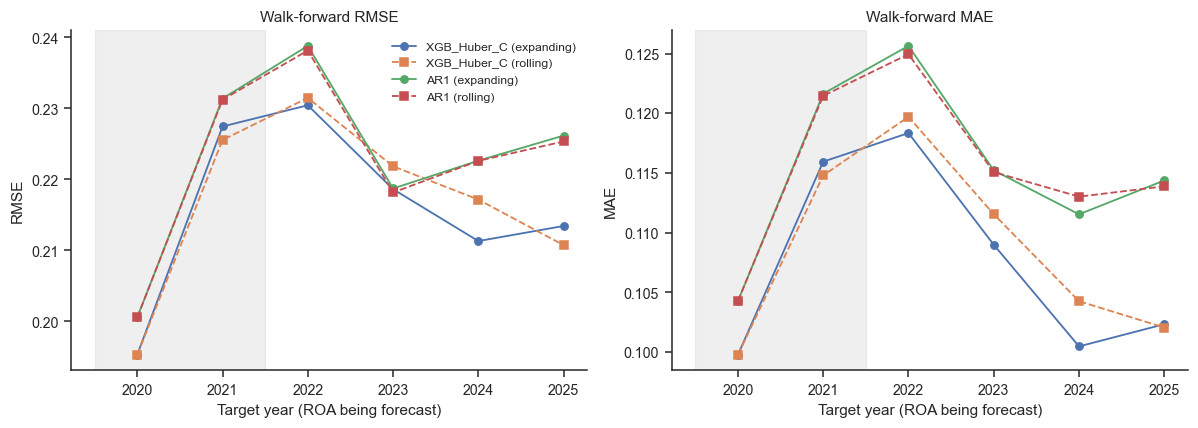


Year-by-year, XGB_Huber_C minus AR1 (expanding window):


,n,dRMSE vs AR1 [95% CI],dMAE vs AR1 [95% CI],verdict
target_year,,,,
2020,1626,"-0.0053 [-0.0125, +0.0028]","-0.0045 [-0.0069, -0.0018]","mixed (RMSE: indistinguishable, MAE: better)"
2021,1646,"-0.0039 [-0.0108, +0.0029]","-0.0057 [-0.0086, -0.0028]","mixed (RMSE: indistinguishable, MAE: better)"
2022,1621,"-0.0084 [-0.0141, -0.0024]","-0.0073 [-0.0099, -0.0047]",better
2023,1626,"-0.0001 [-0.0079, +0.0077]","-0.0062 [-0.0096, -0.0032]","mixed (RMSE: indistinguishable, MAE: better)"
2024,1622,"-0.0113 [-0.0192, -0.0038]","-0.0111 [-0.0138, -0.0082]",better
2025,1662,"-0.0127 [-0.0220, -0.0041]","-0.0120 [-0.0155, -0.0088]",better


Years in which the selected model beats AR(1) under the stated decision rule: 3 of 6.


In [46]:
def walk_forward(template, cols, mode):
    rows, resid = [], []
    for y in WF_YEARS:
        if mode == "expanding":
            tr_mask = model_df["year"] <= y - 1
        else:
            tr_mask = (model_df["year"] >= y - ROLLING_WINDOW_YEARS) & (model_df["year"] <= y - 1)
            if model_df.loc[tr_mask, "year"].nunique() < ROLLING_WINDOW_YEARS:
                continue
        te_mask = model_df["year"] == y
        tr, te = model_df[tr_mask], model_df[te_mask]
        if len(tr) < 200 or len(te) < 20:
            continue
        m = clone(template).fit(tr[cols], tr[TARGET])
        p = m.predict(te[cols])
        e = te[TARGET].values - p
        rows.append(dict(target_year=y + 1, feature_year=y, n_train=len(tr), n_test=len(te),
                         RMSE=float(np.sqrt(np.mean(e ** 2))), MAE=float(np.mean(np.abs(e))),
                         R2_oos=float(1 - np.sum(e ** 2) / np.sum((te[TARGET].values - tr[TARGET].mean()) ** 2))))
        resid.append(pd.DataFrame({"gemh_id": te["gemh_id"].values, "feature_year": y, "target_year": y + 1,
                                   "y": te[TARGET].values, "pred": p}))
    empty = pd.DataFrame(columns=["gemh_id", "feature_year", "target_year", "y", "pred"])
    return pd.DataFrame(rows), (pd.concat(resid, ignore_index=True) if resid else empty)

WF = {}
for label, (tmpl, cols) in {BEST_NAME: (TUNED[BEST_NAME].best_estimator_, BEST_COLS),
                            "AR1": (build_benchmarks()["AR1"], ["ROA_t"])}.items():
    for mode in ("expanding", "rolling"):
        WF[(label, mode)] = walk_forward(tmpl, cols, mode)

for mode in ("expanding", "rolling"):
    tbl = WF[(BEST_NAME, mode)][0].merge(WF[("AR1", mode)][0][["target_year", "RMSE", "MAE", "R2_oos"]],
                                         on="target_year", suffixes=(f" {BEST_NAME}", " AR1"))
    print(f"\n{mode.capitalize()} window (rows are labelled by the target year being forecast):")
    display(tbl.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ("RMSE", "MAE")):
    for (label, mode), (df_, _) in WF.items():
        ax.plot(df_["target_year"], df_[metric], marker="o" if mode == "expanding" else "s",
                ls="-" if mode == "expanding" else "--", label=f"{label} ({mode})")
    ax.axvspan(min(COVID_TARGET_YEARS) - 0.5, max(COVID_TARGET_YEARS) + 0.5, alpha=0.12, color="gray")
    ax.set_xlabel("Target year (ROA being forecast)"); ax.set_ylabel(metric); ax.set_title(f"Walk-forward {metric}")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

# Year-by-year paired comparison with AR(1), expanding window
res_b, res_a = WF[(BEST_NAME, "expanding")][1], WF[("AR1", "expanding")][1]
yr_rows = []
for ty in sorted(res_b["target_year"].unique()):
    b, a = res_b[res_b["target_year"] == ty], res_a[res_a["target_year"] == ty]
    d = paired_delta_ci(b["y"].values, b["pred"].values, a["pred"].values, b["gemh_id"].values)
    yr_rows.append({"target_year": ty, "n": len(b), "dRMSE vs AR1 [95% CI]": fmt_ci(d["RMSE"]),
                    "dMAE vs AR1 [95% CI]": fmt_ci(d["MAE"]), "verdict": verdict(d)})
yr_table = pd.DataFrame(yr_rows).set_index("target_year")
print(f"\nYear-by-year, {BEST_NAME} minus AR1 (expanding window):")
display(yr_table)
n_better = int((yr_table["verdict"] == "better").sum())
print(f"Years in which the selected model beats AR(1) under the stated decision rule: {n_better} of {len(yr_table)}.")

In [47]:
def covid_gap(resid_df, n_boot=BOOT_N, seed=RANDOM_STATE):
    # RMSE(COVID target years) minus RMSE(post-COVID target years) on rolling-window forecasts.
    # Firms are resampled as clusters because the same firms appear in both windows.
    r = resid_df[resid_df["target_year"].isin(COVID_TARGET_YEARS | POST_COVID_TARGET_YEARS)].copy()
    r["err"] = r["y"] - r["pred"]
    r["covid"] = r["target_year"].isin(COVID_TARGET_YEARS)
    codes, uniq = pd.factorize(r["gemh_id"].astype(str))
    G = len(uniq)
    def sums(mask):
        return (np.bincount(codes[mask], weights=r["err"].values[mask] ** 2, minlength=G),
                np.bincount(codes[mask], minlength=G).astype(float))
    sq_c, n_c = sums(r["covid"].values)
    sq_p, n_p = sums(~r["covid"].values)
    point = np.sqrt(sq_c.sum() / n_c.sum()) - np.sqrt(sq_p.sum() / n_p.sum())
    idx = np.random.default_rng(seed).integers(0, G, size=(n_boot, G))
    boot = np.sqrt(sq_c[idx].sum(1) / n_c[idx].sum(1)) - np.sqrt(sq_p[idx].sum(1) / n_p[idx].sum(1))
    return float(point), float(np.percentile(boot, 2.5)), float(np.percentile(boot, 97.5)), int(n_c.sum()), int(n_p.sum())

print(f"COVID target years {sorted(COVID_TARGET_YEARS)} versus post-COVID target years {sorted(POST_COVID_TARGET_YEARS)}, "
      "rolling-window forecasts (RMSE gap = COVID minus post-COVID):")
for label in (BEST_NAME, "AR1"):
    resid_df = WF[(label, "rolling")][1]
    if len(resid_df) == 0:
        continue
    pt, lo, hi, n_c, n_p = covid_gap(resid_df)
    verdict_txt = "distinguishable" if (lo > 0 or hi < 0) else "not distinguishable from noise"
    print(f"  {label:<14s} gap = {pt:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  (n COVID = {n_c:,}, n post = {n_p:,}) -> {verdict_txt}")

COVID target years [2020, 2021] versus post-COVID target years [2022, 2023, 2024, 2025], rolling-window forecasts (RMSE gap = COVID minus post-COVID):
  XGB_Huber_C    gap = -0.0093  95% CI [-0.0268, +0.0086]  (n COVID = 3,272, n post = 6,531) -> not distinguishable from noise
  AR1            gap = -0.0096  95% CI [-0.0267, +0.0076]  (n COVID = 3,272, n post = 6,531) -> not distinguishable from noise


## 23b. Nested Rolling-Origin Evaluation (Main Evidence)

In [48]:
NESTED_MODELS_V9 = {"XGB_L2_C": ("xgb_l2", "C"), "XGB_Huber_C": ("xgb_huber", "C"),
                    "XGB_L2_R": ("xgb_l2", "R"), "XGB_Huber_R": ("xgb_huber", "R"),
                    "XGB_L2_R3": ("xgb_l2", "R3"), "XGB_Huber_R3": ("xgb_huber", "R3"),
                    "XGB_L2_C3": ("xgb_l2", "C3"), "XGB_Huber_C3": ("xgb_huber", "C3")}
NESTED_MODELS_NEW = {"XGB_L2_R5": ("xgb_l2", "R5"), "XGB_Huber_R5": ("xgb_huber", "R5"),
                     "XGB_L2_C5": ("xgb_l2", "C5"), "XGB_Huber_C5": ("xgb_huber", "C5")}
NESTED_MODELS = {**NESTED_MODELS_V9, **NESTED_MODELS_NEW}

def nested_tune(kind, cols, tr, folds):
    if kind == "xgb_l2":
        est, space, scoring = build_xgb("reg:squarederror"), XGB_SPACE, "neg_root_mean_squared_error"
    else:
        est, space, scoring = build_xgb("reg:pseudohubererror"), XGB_HUBER_SPACE, "neg_mean_absolute_error"
    s = RandomizedSearchCV(est, space, n_iter=NESTED_SEARCH_N_ITER, cv=folds, scoring=scoring, n_jobs=N_JOBS,
                           random_state=RANDOM_STATE, refit=True, error_score="raise")
    s.fit(tr[cols], tr[TARGET])
    return s.best_estimator_

def nested_year_frame(y, models, with_base=True):
    tr = model_df[model_df["year"] <= y - 1].reset_index(drop=True)
    te = model_df[model_df["year"] == y].reset_index(drop=True)
    inner_years = [t for t in range(y - NESTED_INNER_FOLDS, y) if t - 1 >= min(YEARS)]
    folds = temporal_folds(tr, inner_years)
    if len(te) == 0 or len(folds) < 2:
        return None
    out = {"gemh_id": te["gemh_id"].values, "feature_year": y}
    if with_base:
        out.update({"target_year": y + 1, "y": te[TARGET].values, "y_raw": te[TARGET_RAW].values})
        bnch = build_benchmarks()
        for b in BENCH_NAMES:
            cols_b = BENCH_COLS.get(b, ["ROA_t"])
            out[b] = clone(bnch[b]).fit(tr[cols_b], tr[TARGET]).predict(te[cols_b])
    for name, (kind, fs) in models.items():
        cols_m = FEATURE_SETS[fs]
        out[name] = nested_tune(kind, cols_m, tr, folds).predict(te[cols_m])
    return pd.DataFrame(out)

nested_frames = []
for y in NESTED_YEARS:
    t0 = time.time()
    frame = cached(f"nested_reg_{y}", (CACHE_SIG, "nested_reg", y, NESTED_INNER_FOLDS, NESTED_SEARCH_N_ITER,
                                       tuple(NESTED_MODELS_V9.items()), tuple(BENCH_NAMES)), lambda: nested_year_frame(y, NESTED_MODELS_V9))
    if frame is None:
        print(f"feature year {y}: skipped")
        continue
    extra = cached(f"nested_reg_new_{y}", (CACHE_SIG, "nested_reg_new", y, NESTED_INNER_FOLDS, NESTED_SEARCH_N_ITER, tuple(NESTED_MODELS_NEW.items())),
                   lambda: nested_year_frame(y, NESTED_MODELS_NEW, with_base=False))
    frame = frame.merge(extra, on=["gemh_id", "feature_year"], how="left", validate="one_to_one")
    nested_frames.append(frame)
    print(f"feature year {y} (target {y+1}): {len(frame):,} test rows, {time.time()-t0:.0f}s")

NESTED_DF = pd.concat(nested_frames, ignore_index=True)
for fam, members in {"NEST_C": ["XGB_L2_C", "XGB_Huber_C"], "NEST_R": ["XGB_L2_R", "XGB_Huber_R"], "NEST_C3": ["XGB_L2_C3", "XGB_Huber_C3"],
                     "NEST_R3": ["XGB_L2_R3", "XGB_Huber_R3"], "NEST_C5": ["XGB_L2_C5", "XGB_Huber_C5"], "NEST_R5": ["XGB_L2_R5", "XGB_Huber_R5"]}.items():
    NESTED_DF[fam] = NESTED_DF[members].mean(axis=1)

show = ["Persistence", "AR1", "AR1_LAD", "AR1_SECTOR", "NEST_R", "NEST_R3", "NEST_R5", "NEST_C", "NEST_C3", "NEST_C5"]
yr_rows = []
for ty, g in NESTED_DF.groupby("target_year"):
    row = {"target_year": ty, "n": len(g)}
    for n in show:
        row[f"RMSE {n}"] = rmse(g["y"], g[n])
    for n in show:
        row[f"MAE {n}"] = mae(g["y"], g[n])
    yr_rows.append(row)
nested_year_table = pd.DataFrame(yr_rows).set_index("target_year")
print("\nNested rolling-origin results by target year:")
display(nested_year_table.round(4))

feature year 2019 (target 2020): 1,626 test rows, 97s
feature year 2020 (target 2021): 1,646 test rows, 138s
feature year 2021 (target 2022): 1,621 test rows, 168s
feature year 2022 (target 2023): 1,626 test rows, 198s
feature year 2023 (target 2024): 1,622 test rows, 226s
feature year 2024 (target 2025): 1,662 test rows, 257s

Nested rolling-origin results by target year:


,n,RMSE Persistence,RMSE AR1,RMSE AR1_LAD,RMSE AR1_SECTOR,RMSE NEST_R,RMSE NEST_R3,RMSE NEST_R5,RMSE NEST_C,RMSE NEST_C3,RMSE NEST_C5,MAE Persistence,MAE AR1,MAE AR1_LAD,MAE AR1_SECTOR,MAE NEST_R,MAE NEST_R3,MAE NEST_R5,MAE NEST_C,MAE NEST_C3,MAE NEST_C5
target_year,,,,,,,,,,,,,,,,,,,,,
2020,1626,0.2302,0.2006,0.2010,0.1984,0.2010,0.1932,0.1932,0.1950,0.1916,0.1926,0.1090,0.1043,0.1025,0.1047,0.1021,0.0983,0.0980,0.0996,0.0972,0.0972
2021,1646,0.2623,0.2314,0.2338,0.2331,0.2285,0.2286,0.2291,0.2252,0.2261,0.2271,0.1294,0.1216,0.1210,0.1254,0.1182,0.1137,0.1140,0.1163,0.1130,0.1127
2022,1621,0.2706,0.2388,0.2407,0.2382,0.2378,0.2242,0.2232,0.2301,0.2225,0.2230,0.1275,0.1256,0.1231,0.1265,0.1222,0.1139,0.1128,0.1195,0.1132,0.1130
2023,1626,0.2532,0.2187,0.2211,0.2189,0.2168,0.2128,0.2144,0.2160,0.2136,0.2144,0.1234,0.1152,0.1146,0.1167,0.1101,0.1040,0.1045,0.1090,0.1050,0.1057
2024,1622,0.2450,0.2226,0.2218,0.2213,0.2201,0.2101,0.2092,0.2124,0.2085,0.2077,0.1088,0.1115,0.1072,0.1120,0.1056,0.1011,0.0995,0.1019,0.0998,0.0986
2025,1662,0.2520,0.2262,0.2269,0.2249,0.2235,0.2147,0.2137,0.2117,0.2108,0.2102,0.1113,0.1144,0.1103,0.1147,0.1077,0.1010,0.1006,0.1026,0.0996,0.1002


In [49]:
def ndelta(a, b, frame=None):
    f = NESTED_DF if frame is None else frame
    return paired_delta_ci(f["y"].values, f[a].values, f[b].values, f["gemh_id"].values)

NESTED_COMPARISONS = [("NEST_C vs AR1", "NEST_C", "AR1"), ("NEST_C vs Persistence", "NEST_C", "Persistence"),
                      ("NEST_C vs AR1_LAD", "NEST_C", "AR1_LAD"), ("NEST_C vs AR1_SECTOR", "NEST_C", "AR1_SECTOR"),
                      ("NEST_C vs NEST_R", "NEST_C", "NEST_R"), ("NEST_R vs AR1", "NEST_R", "AR1"),
                      ("NEST_C3 vs NEST_R3", "NEST_C3", "NEST_R3"), ("NEST_C3 vs AR1", "NEST_C3", "AR1"),
                      ("NEST_C3 vs Persistence", "NEST_C3", "Persistence"), ("NEST_R3 vs NEST_R (history alone)", "NEST_R3", "NEST_R"),
                      ("NEST_C3 vs NEST_C", "NEST_C3", "NEST_C"), ("NEST_C vs NEST_R3", "NEST_C", "NEST_R3"),
                      ("NEST_C5 vs NEST_R5", "NEST_C5", "NEST_R5"), ("NEST_C5 vs AR1", "NEST_C5", "AR1"),
                      ("NEST_C5 vs Persistence", "NEST_C5", "Persistence"), ("NEST_R5 vs NEST_R3 (longer history)", "NEST_R5", "NEST_R3")]
n_rows, NESTED_DELTAS = [], {}
for label, a, b in NESTED_COMPARISONS:
    d = ndelta(a, b)
    NESTED_DELTAS[label] = d
    n_rows.append({"comparison": label, "dRMSE [95% CI]": fmt_ci(d["RMSE"]), "dMAE [95% CI]": fmt_ci(d["MAE"]), "verdict": verdict(d)})
nested_table = pd.DataFrame(n_rows).set_index("comparison")
print(f"POOLED over {len(NESTED_YEARS)} forecast years ({len(NESTED_DF):,} firm-years; bootstrap resamples firms across years):")
display(nested_table)
NESTED_FRAMING_KEY = framing_from(NESTED_DELTAS["NEST_C vs AR1"], NESTED_DELTAS["NEST_C vs NEST_R"])
NESTED_HIST_FRAMING_KEY = framing_history(NESTED_DELTAS["NEST_C3 vs AR1"], NESTED_DELTAS["NEST_C3 vs NEST_R3"])
NESTED_H5_FRAMING_KEY = framing_history(NESTED_DELTAS["NEST_C5 vs AR1"], NESTED_DELTAS["NEST_C5 vs NEST_R5"])
FRAMING_PRIMARY_KEY = {"3": NESTED_HIST_FRAMING_KEY, "5": NESTED_H5_FRAMING_KEY}[PRIMARY_HISTORY_SET]
print(f"Framing, pooled nested: ratios against the one-year lag {NESTED_FRAMING_KEY}; against the 3-year history {NESTED_HIST_FRAMING_KEY}; "
      f"against the 5-year history {NESTED_H5_FRAMING_KEY}")
print(f"PRIMARY FRAMING (nested, ROA history of {PRIMARY_HISTORY_SET} years): {FRAMING_PRIMARY_KEY}")

DECOMP_NESTED = [("total: C vs R", "NEST_C", "NEST_R"), ("history part: R3 vs R", "NEST_R3", "NEST_R"),
                 ("ratio part beyond 3-year history: C3 vs R3", "NEST_C3", "NEST_R3"), ("longer history: R5 vs R3", "NEST_R5", "NEST_R3"),
                 ("ratio part beyond 5-year history: C5 vs R5", "NEST_C5", "NEST_R5")]
dn_rows = []
for lab, a, b in DECOMP_NESTED:
    d = NESTED_DELTAS.get({"total: C vs R": "NEST_C vs NEST_R", "history part: R3 vs R": "NEST_R3 vs NEST_R (history alone)",
                           "ratio part beyond 3-year history: C3 vs R3": "NEST_C3 vs NEST_R3", "longer history: R5 vs R3": "NEST_R5 vs NEST_R3 (longer history)",
                           "ratio part beyond 5-year history: C5 vs R5": "NEST_C5 vs NEST_R5"}[lab])
    dn_rows.append({"step": lab, "dRMSE [95% CI]": fmt_ci(d["RMSE"]), "dMAE [95% CI]": fmt_ci(d["MAE"]), "verdict": verdict(d)})
decomp_nested = pd.DataFrame(dn_rows).set_index("step")
print("\nDecomposition, pooled nested (negative = first model better):")
display(decomp_nested)

yr2 = []
for ty, g in NESTED_DF.groupby("target_year"):
    d1, d2 = ndelta("NEST_C", "AR1", g), ndelta("NEST_C", "NEST_R", g)
    d3, d4 = ndelta("NEST_C3", "AR1", g), ndelta("NEST_C3", "NEST_R3", g)
    d5, d6 = ndelta("NEST_C5", "AR1", g), ndelta("NEST_C5", "NEST_R5", g)
    yr2.append({"target_year": ty, "n": len(g), "framing (lag)": framing_from(d1, d2), "framing (3y history)": framing_history(d3, d4),
                "framing (5y history)": framing_history(d5, d6), "dMAE C5 vs R5 [95% CI]": fmt_ci(d6["MAE"])})
nested_year_verdicts = pd.DataFrame(yr2).set_index("target_year")
nested_year_verdicts["framing"] = nested_year_verdicts["framing (lag)"]
nested_year_verdicts["C3 vs R3"] = ""
display(nested_year_verdicts.drop(columns=["framing", "C3 vs R3"]))
for col in ("framing (lag)", "framing (3y history)", "framing (5y history)"):
    print(f"Years by {col}:", nested_year_verdicts[col].value_counts().to_dict())

POOLED over 6 forecast years (9,803 firm-years; bootstrap resamples firms across years):


,dRMSE [95% CI],dMAE [95% CI],verdict
comparison,,,
NEST_C vs AR1,"-0.0080 [-0.0110, -0.0048]","-0.0073 [-0.0087, -0.0059]",better
NEST_C vs Persistence,"-0.0372 [-0.0442, -0.0293]","-0.0101 [-0.0129, -0.0073]",better
NEST_C vs AR1_LAD,"-0.0092 [-0.0130, -0.0053]","-0.0050 [-0.0063, -0.0036]",better
NEST_C vs AR1_SECTOR,"-0.0075 [-0.0105, -0.0043]","-0.0085 [-0.0100, -0.0071]",better
NEST_C vs NEST_R,"-0.0062 [-0.0093, -0.0032]","-0.0028 [-0.0040, -0.0017]","mixed (RMSE: better, MAE: slightly better)"
NEST_R vs AR1,"-0.0018 [-0.0034, -0.0001]","-0.0045 [-0.0052, -0.0036]","mixed (RMSE: slightly better, MAE: better)"
NEST_C3 vs NEST_R3,"-0.0018 [-0.0034, -0.0001]","-0.0007 [-0.0014, +0.0000]","mixed (RMSE: slightly better, MAE: equivalent)"
NEST_C3 vs AR1,"-0.0109 [-0.0144, -0.0073]","-0.0108 [-0.0124, -0.0091]",better
NEST_C3 vs Persistence,"-0.0401 [-0.0470, -0.0323]","-0.0136 [-0.0163, -0.0108]",better


Framing, pooled nested: ratios against the one-year lag SMALL_INCREMENTAL_INFORMATION; against the 3-year history HISTORY_EXPLAINS_GAIN; against the 5-year history HISTORY_EXPLAINS_GAIN
PRIMARY FRAMING (nested, ROA history of 5 years): HISTORY_EXPLAINS_GAIN

Decomposition, pooled nested (negative = first model better):


,dRMSE [95% CI],dMAE [95% CI],verdict
step,,,
total: C vs R,"-0.0062 [-0.0093, -0.0032]","-0.0028 [-0.0040, -0.0017]","mixed (RMSE: better, MAE: slightly better)"
history part: R3 vs R,"-0.0073 [-0.0104, -0.0043]","-0.0057 [-0.0069, -0.0045]",better
ratio part beyond 3-year history: C3 vs R3,"-0.0018 [-0.0034, -0.0001]","-0.0007 [-0.0014, +0.0000]","mixed (RMSE: slightly better, MAE: equivalent)"
longer history: R5 vs R3,"-0.0001 [-0.0010, +0.0007]","-0.0004 [-0.0008, -0.0000]","mixed (RMSE: equivalent, MAE: slightly better)"
ratio part beyond 5-year history: C5 vs R5,"-0.0013 [-0.0031, +0.0004]","-0.0003 [-0.0011, +0.0004]",equivalent


,n,framing (lag),framing (3y history),framing (5y history),dMAE C5 vs R5 [95% CI]
target_year,,,,,
2020,1626,BOUNDED_PREDICTABILITY,HISTORY_EXPLAINS_GAIN,HISTORY_EXPLAINS_GAIN,"-0.0008 [-0.0023, +0.0008]"
2021,1646,NONLINEAR_PERSISTENCE,BOUNDED_PREDICTABILITY,BOUNDED_PREDICTABILITY,"-0.0014 [-0.0026, -0.0000]"
2022,1621,SMALL_INCREMENTAL_INFORMATION,HISTORY_EXPLAINS_GAIN,HISTORY_EXPLAINS_GAIN,"+0.0002 [-0.0011, +0.0016]"
2023,1626,BOUNDED_PREDICTABILITY,BOUNDED_PREDICTABILITY,BOUNDED_PREDICTABILITY,"+0.0012 [-0.0006, +0.0029]"
2024,1622,INCREMENTAL_INFORMATION,HISTORY_EXPLAINS_GAIN,HISTORY_EXPLAINS_GAIN,"-0.0009 [-0.0024, +0.0006]"
2025,1662,INCREMENTAL_INFORMATION,HISTORY_EXPLAINS_GAIN,HISTORY_EXPLAINS_GAIN,"-0.0004 [-0.0019, +0.0012]"


Years by framing (lag): {'BOUNDED_PREDICTABILITY': 2, 'INCREMENTAL_INFORMATION': 2, 'NONLINEAR_PERSISTENCE': 1, 'SMALL_INCREMENTAL_INFORMATION': 1}
Years by framing (3y history): {'HISTORY_EXPLAINS_GAIN': 4, 'BOUNDED_PREDICTABILITY': 2}
Years by framing (5y history): {'HISTORY_EXPLAINS_GAIN': 4, 'BOUNDED_PREDICTABILITY': 2}


### 23b.1 Main comparison on pdfplumber rows only
Robustness of the headline result to extraction quality. Two samples: rows with pdfplumber at t and t+1, and a strict sample in which every year of the five-year history (t-4..t) is also pdfplumber. Two designs: (a) the pooled nested predictions restricted to these rows; (b) the nested evaluation re-run from scratch, with tuning and training on the strict sample only.

In [50]:
# 23b.1 C5 vs R5 on pdfplumber rows only
PDF_TIER = "pdfplumber"
_tier = ml_df[["gemh_id", "year"]].assign(_pdf=(ml_df["extraction_tier"] == PDF_TIER).astype(float))
_off = {k: value_at_year_offset(_tier, "_pdf", k) for k in (-4, -3, -2, -1, 0, 1)}
_lenient = (_off[0] == 1) & (_off[1] == 1)
_strict = _lenient.copy()
for k in (-4, -3, -2, -1):
    _strict &= np.isnan(_off[k]) | (_off[k] == 1)      # a missing history year is allowed, a non-pdfplumber year is not
PDF_KEYS = ml_df[["gemh_id", "year"]].assign(pdf_lenient=_lenient, pdf_strict=_strict)

PDF_PAIRS = [("C5 vs R5 (ratios beyond the 5-year history)", "NEST_C5", "NEST_R5"),
             ("C3 vs R3 (ratios beyond the 3-year history)", "NEST_C3", "NEST_R3"),
             ("C5 vs Persistence", "NEST_C5", "Persistence")]

def pdf_rows(frame, label, a, b, sample):
    d = ndelta(a, b, frame)
    return {"design": label, "sample": sample, "comparison": a + " vs " + b, "firm-years": len(frame),
            "forecast years": frame["target_year"].nunique(),
            "dRMSE [95% CI]": fmt_ci(d["RMSE"]), "dMAE [95% CI]": fmt_ci(d["MAE"]), "verdict": verdict(d)}, d

# (a) pooled nested predictions, restricted to pdfplumber rows (no refitting)
_nd = NESTED_DF.merge(PDF_KEYS.rename(columns={"year": "feature_year"}), on=["gemh_id", "feature_year"], how="left")
pdf_out, PDF_DELTAS = [], {}
for sample, mask in [("all rows", np.ones(len(_nd), bool)), ("pdfplumber at t and t+1", _nd["pdf_lenient"].fillna(False).astype(bool).values),
                     ("pdfplumber over t-4..t+1", _nd["pdf_strict"].fillna(False).astype(bool).values)]:
    for lab, a, b in PDF_PAIRS:
        row, d = pdf_rows(_nd[mask], "(a) restricted scoring", a, b, sample)
        pdf_out.append(row); PDF_DELTAS[("a", sample, a, b)] = d

# (b) nested evaluation re-run on the strict pdfplumber sample: tuning, training and scoring use these rows only
PDF_MODELS = {k: NESTED_MODELS[k] for k in ("XGB_L2_R5", "XGB_Huber_R5", "XGB_L2_C5", "XGB_Huber_C5")}
pdf_model_df = model_df.merge(PDF_KEYS, on=["gemh_id", "year"], how="left")
pdf_model_df = pdf_model_df[pdf_model_df["pdf_strict"].fillna(False).astype(bool)].reset_index(drop=True)
print(f"Strict pdfplumber sample: {len(pdf_model_df):,} of {len(model_df):,} modelling rows "
      f"({100*len(pdf_model_df)/len(model_df):.1f}%), {pdf_model_df['gemh_id'].nunique():,} firms")

def nested_year_frame_pdf(y):
    tr = pdf_model_df[pdf_model_df["year"] <= y - 1].reset_index(drop=True)
    te = pdf_model_df[pdf_model_df["year"] == y].reset_index(drop=True)
    inner_years = [t for t in range(y - NESTED_INNER_FOLDS, y) if t - 1 >= min(YEARS)]
    folds = temporal_folds(tr, inner_years)
    if len(te) == 0 or len(folds) < 2:
        return None
    out = {"gemh_id": te["gemh_id"].values, "feature_year": y, "target_year": y + 1, "y": te[TARGET].values}
    bnch = build_benchmarks()
    out["Persistence"] = clone(bnch["Persistence"]).fit(tr[["ROA_t"]], tr[TARGET]).predict(te[["ROA_t"]])
    for name, (kind, fs) in PDF_MODELS.items():
        cols_m = FEATURE_SETS[fs]
        out[name] = nested_tune(kind, cols_m, tr, folds).predict(te[cols_m])
    return pd.DataFrame(out)

_pdf_sig = int(pd.util.hash_pandas_object(PDF_KEYS[["gemh_id", "year", "pdf_strict"]], index=False).sum())
pdf_frames = []
for y in NESTED_YEARS:
    t0 = time.time()
    fr = cached(f"nested_pdf_{y}", (CACHE_SIG, "nested_pdf", _pdf_sig, y, NESTED_INNER_FOLDS, NESTED_SEARCH_N_ITER,
                                    tuple(PDF_MODELS.items())), lambda: nested_year_frame_pdf(y))
    if fr is None:
        print(f"feature year {y}: skipped")
        continue
    pdf_frames.append(fr)
    print(f"feature year {y} (target {y+1}): {len(fr):,} test rows, {time.time()-t0:.0f}s")
NESTED_PDF_DF = pd.concat(pdf_frames, ignore_index=True)
NESTED_PDF_DF["NEST_C5"] = NESTED_PDF_DF[["XGB_L2_C5", "XGB_Huber_C5"]].mean(axis=1)
NESTED_PDF_DF["NEST_R5"] = NESTED_PDF_DF[["XGB_L2_R5", "XGB_Huber_R5"]].mean(axis=1)
for lab, a, b in [PDF_PAIRS[0], PDF_PAIRS[2]]:
    row, d = pdf_rows(NESTED_PDF_DF, "(b) re-run on pdfplumber rows", a, b, "pdfplumber over t-4..t+1")
    pdf_out.append(row); PDF_DELTAS[("b", a, b)] = d

PDF_TABLE = pd.DataFrame(pdf_out)
print("C5 versus R5 and related comparisons on pdfplumber rows (negative = first model better):")
display(PDF_TABLE.set_index(["design", "sample", "comparison"]))

_yr = []
for ty, g in NESTED_PDF_DF.groupby("target_year"):
    d = ndelta("NEST_C5", "NEST_R5", g)
    _yr.append({"target_year": ty, "n": len(g), "dMAE C5 vs R5 [95% CI]": fmt_ci(d["MAE"]),
                "dRMSE C5 vs R5 [95% CI]": fmt_ci(d["RMSE"]), "verdict": verdict(d)})
PDF_YEAR_TABLE = pd.DataFrame(_yr).set_index("target_year")
print("Re-run on pdfplumber rows, by forecast year:")
display(PDF_YEAR_TABLE)
PDF_TABLE.to_csv(os.path.join(RESULTS_DIR, "pdfplumber_robustness.csv"), index=False)


Strict pdfplumber sample: 7,465 of 14,674 modelling rows (50.9%), 1,288 firms
feature year 2019 (target 2020): 761 test rows, 24s
feature year 2020 (target 2021): 739 test rows, 39s
feature year 2021 (target 2022): 803 test rows, 42s
feature year 2022 (target 2023): 862 test rows, 48s
feature year 2023 (target 2024): 882 test rows, 55s
feature year 2024 (target 2025): 907 test rows, 58s
C5 versus R5 and related comparisons on pdfplumber rows (negative = first model better):


firm-years  forecast years              dRMSE [95% CI]               dMAE [95% CI]                                         verdict
design                        sample                   comparison                                                                                                                                                
(a) restricted scoring        all rows                 NEST_C5 vs NEST_R5            9803               6  -0.0013 [-0.0031, +0.0004]  -0.0003 [-0.0011, +0.0004]                                      equivalent
                                                       NEST_C3 vs NEST_R3            9803               6  -0.0018 [-0.0034, -0.0001]  -0.0007 [-0.0014, +0.0000]  mixed (RMSE: slightly better, MAE: equivalent)
                                                       NEST_C5 vs Persistence        9803               6  -0.0397 [-0.0468, -0.0319]  -0.0137 [-0.0163, -0.0109]                                          better
                              pdfplumber at t and t+1  NEST_C5 vs NEST_R5            6602               6  -0.0007 [-0.0026, +0.0011]  -0.0005 [-0.0015, +0.0004]                                      equivalent
                                                       NEST_C3 vs NEST_R3            6602               6  -0.0018 [-0.0038, +0.0001]  -0.0007 [-0.0017, +0.0001]                                      equivalent
                                                       NEST_C5 vs Persistence        6602               6  -0.0364 [-0.0451, -0.0275]  -0.0115 [-0.0147, -0.0084]                                          better
                              pdfplumber over t-4..t+1 NEST_C5 vs NEST_R5            4954               6  -0.0002 [-0.0025, +0.0020]  -0.0003 [-0.0014, +0.0008]                                      equivalent
                                                       NEST_C3 vs NEST_R3            4954               6  -0.0016 [-0.0039, +0.0005]  -0.0006 [-0.0017, +0.0004]                                      equivalent
                                                       NEST_C5 vs Persistence        4954               6  -0.0410 [-0.0505, -0.0309]  -0.0137 [-0.0171, -0.0101]                                          better
(b) re-run on pdfplumber rows pdfplumber over t-4..t+1 NEST_C5 vs NEST_R5            4954               6  -0.0001 [-0.0025, +0.0020]  +0.0001 [-0.0008, +0.0011]                                      equivalent
                                                       NEST_C5 vs Persistence        4954               6  -0.0400 [-0.0492, -0.0301]  -0.0124 [-0.0160, -0.0085]                                          better

Re-run on pdfplumber rows, by forecast year:


,n,dMAE C5 vs R5 [95% CI],dRMSE C5 vs R5 [95% CI],verdict
target_year,,,,
2020,761,"-0.0015 [-0.0042, +0.0012]","-0.0004 [-0.0072, +0.0064]",indistinguishable
2021,739,"-0.0041 [-0.0065, -0.0017]","-0.0098 [-0.0169, -0.0034]",better
2022,803,"+0.0013 [-0.0010, +0.0035]","+0.0045 [-0.0010, +0.0102]",indistinguishable
2023,862,"+0.0033 [+0.0011, +0.0056]","+0.0058 [+0.0014, +0.0105]",worse
2024,882,"-0.0000 [-0.0013, +0.0014]","-0.0018 [-0.0052, +0.0016]","mixed (RMSE: indistinguishable, MAE: equivalent)"
2025,907,"+0.0011 [-0.0004, +0.0025]","+0.0006 [-0.0027, +0.0039]",equivalent


### 23c. Noise and the gain over Persistence, on the pooled nested evaluation

In [51]:
flag_cols = ["gemh_id", "year", "data_reliability_class", "ocr_anomaly_flag", "rel_class_t1", "ocr_flag_t1", "ROA_t"]
ND = NESTED_DF.merge(model_df[flag_cols].rename(columns={"year": "feature_year"}), on=["gemh_id", "feature_year"],
                     how="left", validate="one_to_one")
n_lag_obs = ND["ROA_t"].notna().values
n_lag_clean = ((ND["data_reliability_class"] == "High confidence") & (~ND["ocr_anomaly_flag"].astype(bool))).values
n_tgt_clean = ((ND["rel_class_t1"] == "High confidence") & (~ND["ocr_flag_t1"].astype(bool))).values
yn = ND["y"].values
d_abs_n = np.abs(yn - ND["NEST_C"].values) - np.abs(yn - ND["Persistence"].values)
d_sq_n = (yn - ND["NEST_C"].values) ** 2 - (yn - ND["Persistence"].values) ** 2
n_flag_defs = {
    "any flag at t (identity not High, or scale-anomaly flag)": ~n_lag_clean,
    "identity class not High at t": (ND["data_reliability_class"] != "High confidence").values,
    "scale-anomaly flag at t": ND["ocr_anomaly_flag"].astype(bool).values,
}
ng_rows = []
for name, noisy_def in n_flag_defs.items():
    for restrict, rmask in (("all targets", np.ones(len(ND), bool)), ("clean target only", n_tgt_clean)):
        noisy_m, clean_m = n_lag_obs & noisy_def & rmask, n_lag_obs & ~noisy_def & rmask
        r_abs = gap_diff_ci(d_abs_n, noisy_m, clean_m, ND["gemh_id"].values)
        r_sq = gap_diff_ci(d_sq_n, noisy_m, clean_m, ND["gemh_id"].values)
        c_n, c_c = group_mean_ci(d_abs_n, noisy_m, ND["gemh_id"].values), group_mean_ci(d_abs_n, clean_m, ND["gemh_id"].values)
        ng_rows.append({"noisy-lag definition": name, "rows": restrict, "n noisy / clean": f"{r_abs['n_noisy']} / {r_abs['n_clean']}",
                        "MAE gap, noisy": r_abs["noisy"], "MAE gap, clean": r_abs["clean"],
                        "MAE gap, noisy [95% CI]": f"{c_n['mean']:+.4f} [{c_n['lo']:+.4f}, {c_n['hi']:+.4f}]",
                        "MAE gap, clean [95% CI]": f"{c_c['mean']:+.4f} [{c_c['lo']:+.4f}, {c_c['hi']:+.4f}]",
                        "clean_lo": c_c["lo"], "clean_hi": c_c["hi"],
                        "difference in MAE gap [95% CI]": f"{r_abs['diff']:+.4f} [{r_abs['lo']:+.4f}, {r_abs['hi']:+.4f}]",
                        "difference in squared-error gap [95% CI]": f"{r_sq['diff']:+.4f} [{r_sq['lo']:+.4f}, {r_sq['hi']:+.4f}]"})
nested_noise_gap = pd.DataFrame(ng_rows)
print("Gain of NEST_C over Persistence (model minus Persistence, negative = model better), noisy-lag versus clean-lag rows, pooled over the nested years:")
display(nested_noise_gap.drop(columns=["clean_lo", "clean_hi"]).round(4))

yr_gap = []
for ty in sorted(ND["target_year"].unique()):
    m = (ND["target_year"] == ty).values
    gy = ND.loc[m, "gemh_id"].values
    r = gap_diff_ci(d_abs_n[m], (n_lag_obs & ~n_lag_clean)[m], (n_lag_obs & n_lag_clean)[m], gy, n_boot=300)
    cc = group_mean_ci(d_abs_n[m], (n_lag_obs & n_lag_clean)[m], gy, n_boot=300)
    yr_gap.append({"target_year": ty, "MAE gap, noisy": r["noisy"], "MAE gap, clean": r["clean"],
                   "MAE gap, clean [95% CI]": f"{cc['mean']:+.4f} [{cc['lo']:+.4f}, {cc['hi']:+.4f}]",
                   "difference [95% CI]": f"{r['diff']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]"})
nested_noise_by_year = pd.DataFrame(yr_gap).set_index("target_year")
display(nested_noise_by_year.round(4))
main = nested_noise_gap.iloc[0]
print("Main definition (any flag at t, all targets): difference in MAE gap " + main["difference in MAE gap [95% CI]"] + ". "
      "Negative with an interval below zero means the gain over Persistence is larger in noisy-lag rows; the clean-lag gap and its interval show what remains on clean lags.")

Gain of NEST_C over Persistence (model minus Persistence, negative = model better), noisy-lag versus clean-lag rows, pooled over the nested years:


,noisy-lag definition,rows,n noisy / clean,"MAE gap, noisy","MAE gap, clean","MAE gap, noisy [95% CI]","MAE gap, clean [95% CI]",difference in MAE gap [95% CI],difference in squared-error gap [95% CI]
0,"any flag at t (identity not High, or scale-ano...",all targets,2408 / 6698,-0.0220,-0.0063,"-0.0220 [-0.0293, -0.0149]","-0.0063 [-0.0092, -0.0032]","-0.0157 [-0.0233, -0.0078]","-0.0283 [-0.0418, -0.0158]"
1,"any flag at t (identity not High, or scale-ano...",clean target only,833 / 5850,-0.0215,-0.0049,"-0.0215 [-0.0325, -0.0108]","-0.0049 [-0.0082, -0.0016]","-0.0166 [-0.0280, -0.0054]","-0.0188 [-0.0369, -0.0037]"
2,identity class not High at t,all targets,1946 / 7160,-0.0222,-0.0073,"-0.0222 [-0.0300, -0.0143]","-0.0073 [-0.0103, -0.0043]","-0.0149 [-0.0231, -0.0070]","-0.0299 [-0.0445, -0.0163]"
3,identity class not High at t,clean target only,574 / 6109,-0.0259,-0.0052,"-0.0259 [-0.0405, -0.0125]","-0.0052 [-0.0083, -0.0019]","-0.0206 [-0.0358, -0.0062]","-0.0258 [-0.0505, -0.0048]"
4,scale-anomaly flag at t,all targets,628 / 8478,-0.0351,-0.0086,"-0.0351 [-0.0531, -0.0174]","-0.0086 [-0.0116, -0.0055]","-0.0265 [-0.0448, -0.0095]","-0.0585 [-0.0985, -0.0233]"
5,scale-anomaly flag at t,clean target only,314 / 6369,-0.0166,-0.0065,"-0.0166 [-0.0338, -0.0008]","-0.0065 [-0.0099, -0.0033]","-0.0101 [-0.0267, +0.0061]","-0.0105 [-0.0373, +0.0110]"


,"MAE gap, noisy","MAE gap, clean","MAE gap, clean [95% CI]",difference [95% CI]
target_year,,,,
2020,-0.0227,-0.0055,"-0.0055 [-0.0127, +0.0010]","-0.0172 [-0.0343, -0.0021]"
2021,-0.0171,-0.0135,"-0.0135 [-0.0196, -0.0080]","-0.0036 [-0.0215, +0.0113]"
2022,-0.0258,-0.0014,"-0.0014 [-0.0073, +0.0044]","-0.0244 [-0.0468, -0.0067]"
2023,-0.0271,-0.0103,"-0.0103 [-0.0180, -0.0022]","-0.0168 [-0.0353, -0.0022]"
2024,-0.0107,-0.0058,"-0.0058 [-0.0138, +0.0013]","-0.0049 [-0.0210, +0.0119]"
2025,-0.0283,-0.0014,"-0.0014 [-0.0094, +0.0051]","-0.0269 [-0.0455, -0.0074]"


Main definition (any flag at t, all targets): difference in MAE gap -0.0157 [-0.0233, -0.0078]. Negative with an interval below zero means the gain over Persistence is larger in noisy-lag rows; the clean-lag gap and its interval show what remains on clean lags.


In [52]:
# Does the profit history explain the gain on clean lags? Same decomposition for the models that use the history.
def noise_row(label, y, pred, pers, lag_obs, lag_clean, groups):
    d = np.abs(y - pred) - np.abs(y - pers)
    noisy_m, clean_m = lag_obs & ~lag_clean, lag_obs & lag_clean
    r = gap_diff_ci(d, noisy_m, clean_m, groups)
    cn, cc = group_mean_ci(d, noisy_m, groups), group_mean_ci(d, clean_m, groups)
    return {"model": label, "MAE gap, noisy-lag rows [95% CI]": f"{cn['mean']:+.4f} [{cn['lo']:+.4f}, {cn['hi']:+.4f}]",
            "MAE gap, clean-lag rows [95% CI]": f"{cc['mean']:+.4f} [{cc['lo']:+.4f}, {cc['hi']:+.4f}]",
            "difference [95% CI]": f"{r['diff']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]"}

nm_test, nm_nested = [], []
lag_obs_t = TEST_DF["ROA_t"].notna().values
lag_clean_t = ((TEST_DF["data_reliability_class"] == "High confidence") & (~TEST_DF["ocr_anomaly_flag"].astype(bool))).values
for fam in ("ENS_C", "ENS_R3", "ENS_C3", "ENS_R5", "ENS_C5"):
    nm_test.append(noise_row(fam, y_test, TEST_PRED[fam], TEST_PRED["Persistence"], lag_obs_t, lag_clean_t, groups_test))
for fam in ("NEST_C", "NEST_R3", "NEST_C3", "NEST_R5", "NEST_C5"):
    nm_nested.append(noise_row(fam, ND["y"].values, ND[fam].values if fam in ND.columns else NESTED_DF[fam].values, ND["Persistence"].values,
                               n_lag_obs, n_lag_clean, ND["gemh_id"].values))
noise_models_test = pd.DataFrame(nm_test).set_index("model")
noise_models_nested = pd.DataFrame(nm_nested).set_index("model")
print("Gain over Persistence in MAE by lag quality (any flag at t), descriptive test year:")
display(noise_models_test)
print("Pooled nested:")
display(noise_models_nested)

Gain over Persistence in MAE by lag quality (any flag at t), descriptive test year:


,"MAE gap, noisy-lag rows [95% CI]","MAE gap, clean-lag rows [95% CI]",difference [95% CI]
model,,,
ENS_C,"-0.0280 [-0.0485, -0.0108]","-0.0017 [-0.0092, +0.0052]","-0.0263 [-0.0470, -0.0079]"
ENS_R3,"-0.0255 [-0.0448, -0.0096]","-0.0025 [-0.0102, +0.0044]","-0.0229 [-0.0437, -0.0044]"
ENS_C3,"-0.0281 [-0.0491, -0.0108]","-0.0036 [-0.0112, +0.0033]","-0.0245 [-0.0461, -0.0057]"
ENS_R5,"-0.0251 [-0.0451, -0.0085]","-0.0024 [-0.0100, +0.0051]","-0.0227 [-0.0440, -0.0043]"
ENS_C5,"-0.0264 [-0.0478, -0.0092]","-0.0030 [-0.0105, +0.0042]","-0.0235 [-0.0449, -0.0047]"


Pooled nested:


,"MAE gap, noisy-lag rows [95% CI]","MAE gap, clean-lag rows [95% CI]",difference [95% CI]
model,,,
NEST_C,"-0.0220 [-0.0293, -0.0149]","-0.0063 [-0.0092, -0.0032]","-0.0157 [-0.0233, -0.0078]"
NEST_R3,"-0.0259 [-0.0335, -0.0187]","-0.0083 [-0.0112, -0.0050]","-0.0176 [-0.0255, -0.0095]"
NEST_C3,"-0.0258 [-0.0335, -0.0183]","-0.0092 [-0.0120, -0.0061]","-0.0165 [-0.0245, -0.0085]"
NEST_R5,"-0.0263 [-0.0339, -0.0190]","-0.0086 [-0.0116, -0.0053]","-0.0177 [-0.0255, -0.0095]"
NEST_C5,"-0.0252 [-0.0329, -0.0178]","-0.0092 [-0.0121, -0.0061]","-0.0160 [-0.0238, -0.0080]"


### 23d. Error injection: extraction noise and the gain of ML

In [53]:
# 23d.1 Calibration of the error mix from the manual parser/manual pairs.
# ev_df is created later (Section 28), so the manual CSV is read again here with the same filter.
EI_FIELDS = ["TA", "Sales", "NP", "EQ", "TL", "EBIT"]
EI_TYPES = ["missing", "scale", "sign", "other"]
EI_TOL_EUR = 5.0
EI_SCALE_TOL = 0.05        # |log10(parser/manual) - integer| below this counts as a scale error
EI_MIN_TIER_ROWS = 10      # tiers with fewer sampled filings are pooled
EI_MIN_ERRORS = 20         # TA and NP error observations needed for the empirical mix
EI_MIN_ROWS_FIELDS = 10    # filings with a TA or NP error needed for the empirical field pattern
EI_MIN_SCALE_OBS, EI_MIN_OTHER_OBS = 3, 5

ei_pairs = None
if os.path.exists(MANUAL_VALIDATION_CSV):
    ei_pairs = pd.read_csv(MANUAL_VALIDATION_CSV, low_memory=False, dtype={"gemh_id": str})
    ei_pairs = ei_pairs[ei_pairs["TA_manual"].notna()].reset_index(drop=True)

def classify_error(parser_val, manual_val, tol=EI_TOL_EUR):
    if pd.isna(manual_val):
        return None, np.nan
    if pd.isna(parser_val):
        return "missing", np.nan
    if abs(parser_val - manual_val) <= tol:
        return "correct", np.nan
    if manual_val != 0 and abs(parser_val + manual_val) <= max(tol, 0.02 * abs(manual_val)):
        return "sign", np.nan
    if manual_val != 0 and parser_val != 0 and np.sign(parser_val) == np.sign(manual_val):
        k = np.log10(abs(parser_val / manual_val))
        kr = int(np.round(k))
        if kr != 0 and abs(kr) <= 3 and abs(k - kr) < EI_SCALE_TOL:
            return "scale", float(kr)
    rel = (parser_val - manual_val) / abs(manual_val) if manual_val != 0 else np.nan
    return "other", float(rel)

obs_rows = []
if ei_pairs is not None:
    for f in EI_FIELDS:
        for _, r in ei_pairs.iterrows():
            t, extra = classify_error(r.get(f"{f}_parser"), r.get(f"{f}_manual"))
            if t is None:
                continue
            obs_rows.append({"gemh_id": r["gemh_id"], "year": r["year"], "tier": r["extraction_tier"], "field": f, "type": t,
                             "k": extra if t == "scale" else np.nan, "rel": extra if t == "other" else np.nan})
EI_OBS = pd.DataFrame(obs_rows, columns=["gemh_id", "year", "tier", "field", "type", "k", "rel"])
if len(EI_OBS):
    tier_rows = ei_pairs["extraction_tier"].value_counts()
    small = set(tier_rows.index[tier_rows < EI_MIN_TIER_ROWS])
    EI_OBS["tier_pooled"] = np.where(EI_OBS["tier"].isin(small), "pooled small tiers", EI_OBS["tier"])

def type_table(df, by):
    t = pd.crosstab(df[by], df["type"]).reindex(columns=["correct"] + EI_TYPES, fill_value=0)
    t["n"] = t.sum(axis=1)
    t["error share"] = 1 - t["correct"] / t["n"]
    return t

if len(EI_OBS):
    ei_by_field = type_table(EI_OBS, "field")
    ei_by_tier_all = type_table(EI_OBS, "tier_pooled")
    ei_by_tier_tanp = type_table(EI_OBS[EI_OBS["field"].isin(["TA", "NP"])], "tier_pooled")
    print(f"Manual pairs: {len(ei_pairs)} filings; tiers pooled (fewer than {EI_MIN_TIER_ROWS} filings): {sorted(small) or 'none'}")
    print("Error types by field:"); display(ei_by_field.round(3))
    print("Error types by tier, all six fields:"); display(ei_by_tier_all.round(3))
    print("Error types by tier, TA and NP only:"); display(ei_by_tier_tanp.round(3))
else:
    print("No manual pairs available: the default error mix is used.")

# Empirical mix from TA and NP errors, or the documented default
EI_DEFAULT_TYPES = {"missing": 0.10, "scale": 0.40, "sign": 0.10, "other": 0.40}
EI_DEFAULT_K = {-3: 0.30, -2: 0.10, -1: 0.10, 1: 0.10, 2: 0.10, 3: 0.30}
EI_DEFAULT_FIELDS = {"TA": 1 / 3, "NP": 1 / 3, "both": 1 / 3}
_rng0 = np.random.default_rng(0)
EI_DEFAULT_REL = np.exp(_rng0.uniform(np.log(0.05), np.log(1.0), 200)) * _rng0.choice([-1.0, 1.0], 200)   # log-uniform 5% to 100%, random sign

errs = EI_OBS[EI_OBS["field"].isin(["TA", "NP"]) & EI_OBS["type"].isin(EI_TYPES)] if len(EI_OBS) else EI_OBS
EI_N_ERR = len(errs)
EI_EMPIRICAL_OK = EI_N_ERR >= EI_MIN_ERRORS

def _norm(d):
    s = float(sum(d.values()))
    return {k: v / s for k, v in d.items()}

types_main = _norm({t: float((errs["type"] == t).sum()) for t in EI_TYPES}) if EI_EMPIRICAL_OK else dict(EI_DEFAULT_TYPES)
sc = errs[errs["type"] == "scale"]["k"].dropna()
k_main = _norm({int(k): float((sc == k).sum()) for k in sc.unique()}) if (EI_EMPIRICAL_OK and len(sc) >= EI_MIN_SCALE_OBS) else dict(EI_DEFAULT_K)
oth = errs[errs["type"] == "other"]["rel"].dropna().to_numpy(float)
rel_main = oth if (EI_EMPIRICAL_OK and len(oth) >= EI_MIN_OTHER_OBS) else EI_DEFAULT_REL

fld = EI_OBS[EI_OBS["field"].isin(["TA", "NP"]) & (EI_OBS["type"] != "correct")] if len(EI_OBS) else EI_OBS
row_pat = fld.groupby(["gemh_id", "year"])["field"].agg(lambda s: "both" if set(s) == {"TA", "NP"} else s.iloc[0]) if len(fld) else pd.Series(dtype=object)
fields_main = _norm({k: float((row_pat == k).sum()) for k in ("TA", "NP", "both")}) if (EI_EMPIRICAL_OK and len(row_pat) >= EI_MIN_ROWS_FIELDS) else dict(EI_DEFAULT_FIELDS)

def _mix(types, k, rel, fields):
    return {"types": {t: float(types.get(t, 0.0)) for t in EI_TYPES}, "k": dict(k), "rel": np.asarray(rel, float), "fields": dict(fields)}

nonscale = _norm({t: v for t, v in types_main.items() if t != "scale"}) if sum(v for t, v in types_main.items() if t != "scale") > 0 else _norm({t: EI_DEFAULT_TYPES[t] for t in EI_DEFAULT_TYPES if t != "scale"})
EI_MAIN_SOURCE = "empirical" if EI_EMPIRICAL_OK else "default"
EI_MIXES = {"main": _mix(types_main, k_main, rel_main, fields_main),
            "scale_only": _mix({"scale": 1.0}, k_main, rel_main, fields_main),
            "non_scale_only": _mix(nonscale, k_main, rel_main, fields_main)}
if EI_EMPIRICAL_OK:
    EI_MIXES["alternative"] = _mix(EI_DEFAULT_TYPES, EI_DEFAULT_K, EI_DEFAULT_REL, EI_DEFAULT_FIELDS)
    EI_ALT_SOURCE = "documented default"
elif EI_N_ERR >= 5:
    _sc_alt, _oth_alt = errs[errs["type"] == "scale"]["k"].dropna(), errs[errs["type"] == "other"]["rel"].dropna().to_numpy(float)
    EI_MIXES["alternative"] = _mix(_norm({t: float((errs["type"] == t).sum()) for t in EI_TYPES}),
                                   _norm({int(k): float((_sc_alt == k).sum()) for k in _sc_alt.unique()}) if len(_sc_alt) else EI_DEFAULT_K,
                                   _oth_alt if len(_oth_alt) else EI_DEFAULT_REL,
                                   _norm({k: float((row_pat == k).sum()) for k in ("TA", "NP", "both")}) if len(row_pat) >= 3 else EI_DEFAULT_FIELDS)
    EI_ALT_SOURCE = "empirical from few observations"
else:
    EI_ALT_SOURCE = None
print(f"\nMain mix source: {EI_MAIN_SOURCE} ({EI_N_ERR} TA and NP error observations; threshold {EI_MIN_ERRORS}).")
print("  types:", {t: round(v, 3) for t, v in EI_MIXES['main']['types'].items()})
print("  scale exponent:", {int(k): round(v, 3) for k, v in sorted(EI_MIXES['main']['k'].items())})
print(f"  relative error of 'other' errors: {len(EI_MIXES['main']['rel'])} draws, median absolute {np.median(np.abs(EI_MIXES['main']['rel'])):.2f}")
print("  fields corrupted per firm-year:", {k: round(v, 3) for k, v in EI_MIXES['main']['fields'].items()})
print(f"  alternative mix for the sensitivity check: {EI_ALT_SOURCE}")

# Frequency of the panel's own scale-anomaly flag (lower bound for scale errors in TA)
_p = ml_df[ml_df["year"] > min(YEARS)]
ocr_by_tier_year = (_p.pivot_table(index="extraction_tier", columns="year", values="ocr_anomaly_flag", aggfunc="mean") * 100).round(1)
ocr_by_tier = pd.DataFrame({"firm-years": _p.groupby("extraction_tier").size(), "flagged (%)": (_p.groupby("extraction_tier")["ocr_anomaly_flag"].mean() * 100).round(2)})
EI_REAL_FLAG_RATE = float(_p["ocr_anomaly_flag"].mean())
print(f"\nocr_anomaly_flag (TA jump above 8x or below 1/8x): {100 * EI_REAL_FLAG_RATE:.2f}% of firm-years; an isolated scale error flags two consecutive "
      f"firm-years, so the frequency of TA scale errors is between {50 * EI_REAL_FLAG_RATE:.1f}% and {100 * EI_REAL_FLAG_RATE:.1f}% at least.")
display(ocr_by_tier); display(ocr_by_tier_year)

os.makedirs(RESULTS_DIR, exist_ok=True)
for name_, t_ in (("error_injection_calibration_by_field.csv", ei_by_field if len(EI_OBS) else pd.DataFrame()),
                  ("error_injection_calibration_by_tier.csv", ei_by_tier_all if len(EI_OBS) else pd.DataFrame()),
                  ("error_injection_ocr_flag_by_tier.csv", ocr_by_tier), ("error_injection_ocr_flag_by_tier_year.csv", ocr_by_tier_year)):
    t_.to_csv(os.path.join(RESULTS_DIR, name_))

Manual pairs: 50 filings; tiers pooled (fewer than 10 filings): ['manual_verified', 'scan_unprocessed']
Error types by field:


type,correct,missing,scale,sign,other,n,error share
field,,,,,,,
EBIT,27,6,4,0,13,50,0.46
EQ,31,7,5,0,7,50,0.38
NP,36,4,7,0,3,50,0.28
Sales,34,6,6,0,4,50,0.32
TA,35,4,4,0,7,50,0.30
TL,31,4,4,0,11,50,0.38


Error types by tier, all six fields:


type,correct,missing,scale,sign,other,n,error share
tier_pooled,,,,,,,
gemini_vision,30,6,30,0,18,84,0.643
pdfplumber,155,12,0,0,25,192,0.193
pooled small tiers,9,13,0,0,2,24,0.625


Error types by tier, TA and NP only:


type,correct,missing,scale,sign,other,n,error share
tier_pooled,,,,,,,
gemini_vision,10,1,11,0,6,28,0.643
pdfplumber,57,3,0,0,4,64,0.109
pooled small tiers,4,4,0,0,0,8,0.500



Main mix source: empirical (29 TA and NP error observations; threshold 20).
  types: {'missing': 0.276, 'scale': 0.379, 'sign': 0.0, 'other': 0.345}
  scale exponent: {2: 1.0}
  relative error of 'other' errors: 10 draws, median absolute 0.23
  fields corrupted per firm-year: {'TA': 0.176, 'NP': 0.118, 'both': 0.706}
  alternative mix for the sensitivity check: documented default

ocr_anomaly_flag (TA jump above 8x or below 1/8x): 7.59% of firm-years; an isolated scale error flags two consecutive firm-years, so the frequency of TA scale errors is between 3.8% and 7.6% at least.


,firm-years,flagged (%)
extraction_tier,,
gemini_vision,4801,16.70
manual_verified,1,100.00
pdfplumber,13179,4.27
scan_unprocessed,19,0.00


year,2017,2018,2019,2020,2021,2022,2023,2024,2025
extraction_tier,,,,,,,,,
gemini_vision,16.7,18.8,16.6,16.5,15.8,15.7,18.0,15.2,16.6
manual_verified,NaN,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pdfplumber,7.0,5.0,4.0,2.9,5.3,4.4,3.5,3.4,3.3
scan_unprocessed,0.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 23d.2 Frozen design (set before any run)

- Error share of firm-years (among firm-years with observed TA and NP): 0, 1, 2, 5, 10, 20%. Corrupted fields: TA, NP or both, with the calibrated pattern.
- Modes: noise in the lag only (features corrupted, target from the observed panel), in the target only (features observed, target corrupted), in both.
- Repetitions: 20 seeds for the main mix; 10 for the sensitivity mixes (scale only, non-scale only, alternative source of the mix; shares 5, 10, 20%), the reference panel variant and the filtering analysis (shares 5, 10, 20%); retuning check at 5%, 3 seeds.
- Models: Persistence, AR1, the best model on ROA history and the best model on history plus ratios (chosen on the validation year), cached hyperparameters.
- Metrics: MAE of a model minus MAE of Persistence; MAE of the model with ratios minus MAE of the history model, labelled against MIN_DELTA (paired firm bootstrap in every repetition); each evaluated against the noisy target and against the reference target.
- Change rule: the smallest share at which the modal label differs from the label at 0%.

In [54]:
EI_SHARES = [0.0, 0.01, 0.02, 0.05, 0.10, 0.20]
EI_MODES = ("lag", "target", "both")
EI_REPS, EI_REPS_SENS, EI_REPS_REF, EI_REPS_FILTER, EI_RETUNE_SEEDS = 20, 10, 10, 10, 3
EI_SENS_SHARES = [0.05, 0.10, 0.20]
EI_FILTER_SHARES = [0.05, 0.10, 0.20]
EI_RETUNE_SHARE = 0.05
EI_RETUNE_N_ITER = 20
EI_BOOT = 200
EI_SEED0 = 1000

EI_HIST_CANDIDATES = ["XGB_L2_R3", "XGB_Huber_R3", "XGB_L2_R5", "XGB_Huber_R5"]
EI_HC_CANDIDATES = ["XGB_L2_C3", "XGB_Huber_C3", "XGB_L2_C5", "XGB_Huber_C5"]
EI_HIST = min(EI_HIST_CANDIDATES, key=lambda n: valid_table.loc[n, "RMSE"])
EI_HC = min(EI_HC_CANDIDATES, key=lambda n: valid_table.loc[n, "RMSE"])

EI_PLAN = {"shares": EI_SHARES, "modes": list(EI_MODES), "reps": {"main": EI_REPS, "sensitivity": EI_REPS_SENS, "reference": EI_REPS_REF,
           "filter": EI_REPS_FILTER, "retune_seeds": EI_RETUNE_SEEDS}, "sensitivity_shares": EI_SENS_SHARES, "filter_shares": EI_FILTER_SHARES,
           "retune_share": EI_RETUNE_SHARE, "retune_n_iter": EI_RETUNE_N_ITER, "bootstrap_draws": EI_BOOT, "seed0": EI_SEED0,
           "models": {"history": EI_HIST, "history_plus_ratios": EI_HC}, "margin_MAE": MIN_DELTA["MAE"], "mix_source": EI_MAIN_SOURCE,
           "mixes": {k: {"types": v["types"], "k": {str(a): b for a, b in v["k"].items()}, "fields": v["fields"], "n_rel": int(len(v["rel"]))} for k, v in EI_MIXES.items()},
           "created": datetime.now().isoformat(timespec="seconds")}
with open(os.path.join(RESULTS_DIR, "error_injection_plan.json"), "w", encoding="utf-8") as f:
    json.dump(EI_PLAN, f, indent=2)
EI_PLAN_SIG = _sig(repr({k: v for k, v in EI_PLAN.items() if k != "created"}), repr(sorted((k, v["rel"].round(6).tolist()) for k, v in EI_MIXES.items())))
print(f"History model: {EI_HIST}; history plus ratios: {EI_HC}. Plan saved to {RESULTS_DIR}/error_injection_plan.json (signature {EI_PLAN_SIG}).")

History model: XGB_L2_R5; history plus ratios: XGB_Huber_C3. Plan saved to results/error_injection_plan.json (signature 842c935bf90a6bf5).


### 23d.3 Simulator

In [55]:
# There is no function in the notebook that builds the modelling features from raw fields: the ratios X1..X64 are read from the CSV
# (computed upstream), and ROA, its lags and its history are built by inline code in Sections 4 and 16.
# rebuild_roa_features repeats that inline code on any NP and TA arrays; ratios are NOT rebuilt (held at their observed values).
EI_KEYS = ml_df[["gemh_id", "year"]].reset_index(drop=True)
EI_ROA_COLS = ["ROA_t", "ROA_lag1", "ROA_lag2", "ROA_lag3", "ROA_lag4", "ROA_mean3", "ROA_min3", "ROA_mean5", "ROA_min5", "ROA_std5"]

def rebuild_roa_features(keys, np_arr, ta_arr):
    d = keys.copy()
    d["NP"], d["TA"] = np_arr, ta_arr
    d["ROA_raw"] = (d["NP"] / d["TA"].replace(0, np.nan)).where(d["TA"] >= TA_FLOOR)
    d[TARGET_RAW] = value_at_year_offset(d, "ROA_raw", +1)
    d["ROA"] = d["ROA_raw"].clip(ROA_LO, ROA_HI)
    d[TARGET] = d[TARGET_RAW].clip(ROA_LO, ROA_HI)
    d["ROA_t"] = d["ROA"]
    for k in (1, 2, 3, 4):
        d[f"ROA_lag{k}"] = value_at_year_offset(d, "ROA", -k)
    h3 = d[["ROA_t", "ROA_lag1", "ROA_lag2"]]
    ok3 = h3.notna().sum(axis=1) >= 2
    d["ROA_mean3"], d["ROA_min3"] = h3.mean(axis=1).where(ok3), h3.min(axis=1).where(ok3)
    h5 = d[["ROA_t", "ROA_lag1", "ROA_lag2", "ROA_lag3", "ROA_lag4"]]
    ok5 = h5.notna().sum(axis=1) >= 3
    d["ROA_mean5"], d["ROA_min5"], d["ROA_std5"] = h5.mean(axis=1).where(ok5), h5.min(axis=1).where(ok5), h5.std(axis=1, ddof=0).where(ok5)
    cols = ["ROA_raw", TARGET_RAW, TARGET] + EI_ROA_COLS
    return {c: d[c].to_numpy(float) for c in cols}

def flag_rules(keys, ta_arr, tl, eq, prov):
    # Same rules as the pipeline: identity class other than High confidence (relative discrepancy above 0.1% or undefined), and the TA jump flag.
    tmp = pd.DataFrame({"TA": ta_arr, "TL": tl, "EQ": eq, "PROV": prov})
    _, rel = accounting_identity_residual(tmp)
    ident = ~(rel <= 0.001).to_numpy()
    ta_prev = value_at_year_offset(keys.assign(TA=ta_arr), "TA", -1)
    ratio = ta_arr / ta_prev
    ocr = np.nan_to_num(((ratio > 8) | (ratio < 0.125)).astype(float), nan=0.0).astype(bool)
    return ident, ocr

EI_NP0, EI_TA0 = ml_df["NP"].to_numpy(float), ml_df["TA"].to_numpy(float)
EI_TL, EI_EQ, EI_PROV = ml_df["TL"].to_numpy(float), ml_df["EQ"].to_numpy(float), ml_df["PROV"].to_numpy(float)
EI_F0 = rebuild_roa_features(EI_KEYS, EI_NP0, EI_TA0)
for c in ["ROA_raw", TARGET_RAW, TARGET] + EI_ROA_COLS:
    assert np.allclose(ml_df[c].to_numpy(float), EI_F0[c], equal_nan=True), f"rebuild_roa_features does not reproduce the pipeline column {c}"
EI_IDENT0, EI_OCR0 = flag_rules(EI_KEYS, EI_TA0, EI_TL, EI_EQ, EI_PROV)
assert (EI_IDENT0 == (ml_df["data_reliability_class"] != "High confidence").to_numpy()).all(), "identity flag differs from the pipeline"
assert (EI_OCR0 == ml_df["ocr_anomaly_flag"].to_numpy()).all(), "ocr flag differs from the pipeline"
EI_FLAG0 = EI_IDENT0 | EI_OCR0
print("Self-checks passed: ROA, target, lags and history, the identity flag and the scale-anomaly flag are reproduced exactly on the observed panel.")

# Reference panel variant: firm-years with any quality flag are set to missing
EI_NP_REF, EI_TA_REF = np.where(EI_FLAG0, np.nan, EI_NP0), np.where(EI_FLAG0, np.nan, EI_TA0)
EI_F_REF = rebuild_roa_features(EI_KEYS, EI_NP_REF, EI_TA_REF)

# Model rows and their positions in the panel
_pos = model_df[["gemh_id", "year"]].merge(EI_KEYS.assign(pos=np.arange(len(EI_KEYS))), on=["gemh_id", "year"], how="left", validate="one_to_one")["pos"].to_numpy()
assert not np.isnan(_pos).any()
EI_POS = _pos.astype(int)

cols_hist, cols_hc = FEATURE_SETS[MODEL_SPECS[EI_HIST]["feats"]], FEATURE_SETS[MODEL_SPECS[EI_HC]["feats"]]
EI_X_COLS = sorted(set(cols_hist) | set(cols_hc) | {"ROA_t"})
def _obj(kind):
    return "reg:squarederror" if kind == "xgb_l2" else "reg:pseudohubererror"
EI_CTX = {
    "keys": EI_KEYS, "pos": EI_POS, "np0": EI_NP0, "ta0": EI_TA0, "np_ref": EI_NP_REF, "ta_ref": EI_TA_REF, "tl": EI_TL, "eq": EI_EQ, "prov": EI_PROV,
    "F0": EI_F0, "F_ref": EI_F_REF, "flag0": EI_FLAG0, "ident0": EI_IDENT0, "ocr0": EI_OCR0,
    "X_arr": model_df[EI_X_COLS].to_numpy(float), "X_cols": EI_X_COLS, "year": model_df["year"].to_numpy(), "gid": model_df["gemh_id"].to_numpy(),
    "cols_hist": cols_hist, "cols_hc": cols_hc, "est_hist": TUNED[EI_HIST].best_estimator_, "est_hc": TUNED[EI_HC].best_estimator_,
    "kind_hist": MODEL_SPECS[EI_HIST]["kind"], "kind_hc": MODEL_SPECS[EI_HC]["kind"], "mixes": EI_MIXES,
    "space": {"xgb_l2": XGB_SPACE, "xgb_huber": XGB_HUBER_SPACE},
    "scoring": {"xgb_l2": "neg_root_mean_squared_error", "xgb_huber": "neg_mean_absolute_error"},
    "ar1": build_benchmarks()["AR1"],
}

def apply_error(value, etype, k, rel):
    if etype == "missing":
        return np.nan
    if etype == "scale":
        return value * 10.0 ** k
    if etype == "sign":
        return -value
    return value * (1.0 + rel)

def draw_corruption(seed, share, mix, elig):
    rng = np.random.default_rng(seed)
    n = len(elig)
    hit = np.flatnonzero(elig & (rng.random(n) < share))
    pat = rng.choice(["TA", "NP", "both"], size=len(hit), p=[mix["fields"]["TA"], mix["fields"]["NP"], mix["fields"]["both"]])
    types, tp = list(mix["types"]), np.array(list(mix["types"].values()), float)
    ks, kp = np.array(list(mix["k"].keys()), float), np.array(list(mix["k"].values()), float)
    return hit, pat, rng, types, tp / tp.sum(), ks, kp / kp.sum()

def corrupt_panel(seed, share, mix, base_np, base_ta):
    elig = np.isfinite(base_np) & np.isfinite(base_ta)
    hit, pat, rng, types, tp, ks, kp = draw_corruption(seed, share, mix, elig)
    np_c, ta_c = base_np.copy(), base_ta.copy()
    ev = []
    for i, p in zip(hit, pat):
        for fld in (["TA", "NP"] if p == "both" else [p]):
            et = types[rng.choice(len(types), p=tp)]
            k = float(rng.choice(ks, p=kp)) if et == "scale" else np.nan
            rel = float(rng.choice(mix["rel"])) if et == "other" else np.nan
            if fld == "TA":
                ta_c[i] = apply_error(ta_c[i], et, k, rel)
            else:
                np_c[i] = apply_error(np_c[i], et, k, rel)
            ev.append((int(i), fld, et, str(p)))
    return np_c, ta_c, pd.DataFrame(ev, columns=["row", "field", "type", "pattern"])

Self-checks passed: ROA, target, lags and history, the identity flag and the scale-anomaly flag are reproduced exactly on the observed panel.


<temp>:32: RuntimeWarning: divide by zero encountered in divide
  ratio = ta_arr / ta_prev
<temp>:32: RuntimeWarning: invalid value encountered in divide
  ratio = ta_arr / ta_prev


In [56]:
def ei_metrics(y, ok, g, p_pers, p_ar1, p_hist, p_hc):
    yy, gg = y[ok], g[ok]
    out = {"n": int(ok.sum()), "mae_pers": mae(yy, p_pers[ok]), "mae_ar1": mae(yy, p_ar1[ok]), "mae_hist": mae(yy, p_hist[ok]), "mae_hc": mae(yy, p_hc[ok])}
    for name, a, b in (("hist_pers", p_hist, p_pers), ("hc_hist", p_hc, p_hist), ("hc_pers", p_hc, p_pers)):
        d = paired_delta_ci(yy, a[ok], b[ok], gg, n_boot=EI_BOOT)["MAE"]
        out[f"d_{name}"] = d
        out[f"lab_{name}"] = metric_label(*d, MIN_DELTA["MAE"])
    return out

def _fit_predict(ctx, X, ytr, tr_idx, te_idx, cols, base_est, kind, retune, yr):
    if retune:
        sub = tr_idx[yr[tr_idx] <= TRAIN_END_YEAR]
        folds = temporal_folds(pd.DataFrame({"year": yr[sub]}), CV_VAL_YEARS)
        s = RandomizedSearchCV(build_xgb(_obj(kind)), ctx["space"][kind], n_iter=EI_RETUNE_N_ITER, cv=folds, scoring=ctx["scoring"][kind],
                               n_jobs=1, random_state=RANDOM_STATE, refit=True)
        s.fit(X.iloc[sub][cols], ytr[np.searchsorted(tr_idx, sub)])
        base_est = s.best_estimator_
    m = clone(base_est).fit(X.iloc[tr_idx][cols], ytr)
    return m.predict(X.iloc[te_idx][cols])

def ei_worker(ctx, job):
    variant, mix_name, mode, share, seed = job["variant"], job["mix"], job["mode"], job["share"], job["seed"]
    filt, retune = job["filt"], job["retune"]
    keys, pos = ctx["keys"], ctx["pos"]
    if variant == "ref":
        base_np, base_ta, F_base, row_ok = ctx["np_ref"], ctx["ta_ref"], ctx["F_ref"], ~ctx["flag0"]
    else:
        base_np, base_ta, F_base, row_ok = ctx["np0"], ctx["ta0"], ctx["F0"], np.ones(len(keys), bool)
    events = pd.DataFrame(columns=["row", "field", "type", "pattern"])
    if share > 0:
        np_c, ta_c, events = corrupt_panel(seed, share, ctx["mixes"][mix_name], base_np, base_ta)
    else:
        np_c, ta_c = base_np.copy(), base_ta.copy()
    result = {"job": job, "n_events": int(len(events)), "eff_share": float(len(events["row"].unique()) / len(keys)) if len(events) else 0.0}
    det = None
    if mode == "both" and variant == "main" and mix_name == "main" and not filt and not retune and len(events):
        ident, ocr = flag_rules(keys, ta_c, ctx["tl"], ctx["eq"], ctx["prov"])
        rows = events["row"].to_numpy()
        det = events.assign(ident=ident[rows], ocr=ocr[rows], either=(ident | ocr)[rows], new_ident=ident[rows] & ~ctx["ident0"][rows],
                            new_ocr=ocr[rows] & ~ctx["ocr0"][rows], new_either=(ident | ocr)[rows] & ~ctx["flag0"][rows])
        clean = np.ones(len(keys), bool)
        clean[np.unique(rows)] = False
        result["baseline_flag_rate_clean_rows"] = float((ident | ocr)[clean].mean())
        result["baseline_flag_rate_observed"] = float(ctx["flag0"].mean())
    result["detection"] = det
    np_use, ta_use = np_c, ta_c
    if filt:
        ident, ocr = flag_rules(keys, ta_c, ctx["tl"], ctx["eq"], ctx["prov"])
        fl = ident | ocr
        np_use, ta_use = np.where(fl, np.nan, np_c), np.where(fl, np.nan, ta_c)
        row_ok = row_ok & ~fl
        result["dropped_share_firm_years"] = float(fl.mean())
    F_cor = rebuild_roa_features(keys, np_use, ta_use)
    feat = F_cor if mode in ("lag", "both") else F_base
    tgt = F_cor if mode in ("target", "both") else F_base
    X = pd.DataFrame(ctx["X_arr"].copy(), columns=ctx["X_cols"])
    for c in EI_ROA_COLS:
        X[c] = feat[c][pos]
    y_noisy, y_true = tgt[TARGET][pos], F_base[TARGET][pos]
    yr, ok_pos = ctx["year"], row_ok[pos]
    tr_idx = np.flatnonzero((yr <= VALID_FEATURE_YEAR) & np.isfinite(y_noisy) & ok_pos)
    te_idx = np.flatnonzero(np.isin(yr, TEST_FEATURE_YEARS) & ok_pos)
    ytr = y_noisy[tr_idx]
    result["n_train"], result["n_test"] = int(len(tr_idx)), int(len(te_idx))
    ar1 = clone(ctx["ar1"]).fit(X.iloc[tr_idx][["ROA_t"]], ytr)
    p_ar1 = ar1.predict(X.iloc[te_idx][["ROA_t"]])
    fill = float(np.nanmedian(X["ROA_t"].to_numpy()[tr_idx]))
    p_pers = np.where(np.isnan(X["ROA_t"].to_numpy()[te_idx]), fill, X["ROA_t"].to_numpy()[te_idx])
    p_hist = _fit_predict(ctx, X, ytr, tr_idx, te_idx, ctx["cols_hist"], ctx["est_hist"], ctx["kind_hist"], retune, yr)
    p_hc = _fit_predict(ctx, X, ytr, tr_idx, te_idx, ctx["cols_hc"], ctx["est_hc"], ctx["kind_hc"], retune, yr)
    g = ctx["gid"][te_idx]
    yn, yt = y_noisy[te_idx], y_true[te_idx]
    result["noisy"] = ei_metrics(yn, np.isfinite(yn), g, p_pers, p_ar1, p_hist, p_hc)
    result["ref"] = ei_metrics(yt, np.isfinite(yt), g, p_pers, p_ar1, p_hist, p_hc)
    return result

def ei_key(job):
    return _sig(CACHE_VERSION, CACHE_SIG, EI_PLAN_SIG, tuple(sorted(job.items())))

def ei_run_jobs(jobs):
    paths = {ei_key(j): os.path.join(CACHE_DIR, f"errinj_{ei_key(j)}.joblib") for j in jobs}
    got, todo = {}, []
    for j in jobs:
        k = ei_key(j)
        if USE_CACHE and not REFRESH_CACHE and os.path.exists(paths[k]):
            try:
                got[k] = joblib.load(paths[k])
                continue
            except Exception:
                pass
        todo.append(j)
    print(f"[cache] error injection: {len(jobs) - len(todo)} of {len(jobs)} chunks loaded, {len(todo)} to compute")
    if todo:
        res = joblib.Parallel(n_jobs=N_JOBS)(joblib.delayed(ei_worker)(EI_CTX, j) for j in todo)
        os.makedirs(CACHE_DIR, exist_ok=True)
        for j, r in zip(todo, res):
            got[ei_key(j)] = r
            if USE_CACHE:
                joblib.dump(r, paths[ei_key(j)], compress=3)
    return [got[ei_key(j)] for j in jobs]

def _job(variant, mix, mode, share, seed, filt=False, retune=False):
    return {"variant": variant, "mix": mix, "mode": mode, "share": float(share), "seed": int(seed), "filt": bool(filt), "retune": bool(retune)}

jobs = []
# main variant: observed panel plus noise; share 0 is deterministic and run once (mode both), then reused for the other modes
jobs.append(_job("main", "main", "both", 0.0, 0))
for mode in EI_MODES:
    for s in EI_SHARES[1:]:
        for r in range(EI_REPS):
            jobs.append(_job("main", "main", mode, s, EI_SEED0 + r))
for mix in [m for m in ("scale_only", "non_scale_only", "alternative") if m in EI_MIXES]:
    for s in EI_SENS_SHARES:
        for r in range(EI_REPS_SENS):
            jobs.append(_job("main", mix, "both", s, EI_SEED0 + r))
jobs.append(_job("ref", "main", "both", 0.0, 0))
for s in EI_SHARES[1:]:
    for r in range(EI_REPS_REF):
        jobs.append(_job("ref", "main", "both", s, EI_SEED0 + r))
jobs.append(_job("main", "main", "both", 0.0, 0, filt=True))
for s in EI_FILTER_SHARES:
    for r in range(EI_REPS_FILTER):
        jobs.append(_job("main", "main", "both", s, EI_SEED0 + r, filt=True))
for r in range(EI_RETUNE_SEEDS):
    jobs.append(_job("main", "main", "both", EI_RETUNE_SHARE, EI_SEED0 + r, retune=True))
t0 = time.time()
EI_RESULTS = ei_run_jobs(jobs)
print(f"Error injection: {len(jobs)} chunks in {time.time() - t0:.0f}s")

[cache] error injection: 0 of 476 chunks loaded, 476 to compute
Error injection: 476 chunks in 654s


### 23d.4 Gain of ML against the error share

Main mix, observed panel plus noise; means over repetitions with 2.5 to 97.5 percent range; labels are the modal label over repetitions.


reps  gap_hist  gap_hist_lo  gap_hist_hi  gap_hc  ratio_contrib   rc_lo   rc_hi      lab_hist_pers lab_hc_hist  share_hist_better  share_hc_equivalent
mode   eval  share                                                                                                                                                        
both   noisy 0.00      1   -0.0087      -0.0087      -0.0087 -0.0120        -0.0034 -0.0034 -0.0034             better      better               1.00                  0.0
             0.01     20   -0.0093      -0.0106      -0.0079 -0.0128        -0.0035 -0.0045 -0.0023             better      better               1.00                  0.0
             0.02     20   -0.0101      -0.0123      -0.0089 -0.0136        -0.0034 -0.0042 -0.0027             better      better               1.00                  0.0
             0.05     20   -0.0126      -0.0152      -0.0089 -0.0165        -0.0038 -0.0047 -0.0029             better      better               1.00                  0.0
             0.10     20   -0.0147      -0.0181      -0.0119 -0.0197        -0.0050 -0.0063 -0.0036             better      better               1.00                  0.0
             0.20     20   -0.0211      -0.0286      -0.0144 -0.0286        -0.0075 -0.0093 -0.0057             better      better               1.00                  0.0
       ref   0.00      1   -0.0087      -0.0087      -0.0087 -0.0120        -0.0034 -0.0034 -0.0034             better      better               1.00                  0.0
             0.01     20   -0.0093      -0.0104      -0.0084 -0.0128        -0.0035 -0.0045 -0.0024             better      better               1.00                  0.0
             0.02     20   -0.0101      -0.0122      -0.0092 -0.0135        -0.0035 -0.0042 -0.0027             better      better               1.00                  0.0
             0.05     20   -0.0125      -0.0147      -0.0096 -0.0163        -0.0038 -0.0047 -0.0029             better      better               1.00                  0.0
             0.10     20   -0.0150      -0.0182      -0.0113 -0.0200        -0.0050 -0.0062 -0.0039             better      better               1.00                  0.0
             0.20     20   -0.0217      -0.0280      -0.0151 -0.0293        -0.0075 -0.0089 -0.0058             better      better               1.00                  0.0
lag    noisy 0.00      1   -0.0087      -0.0087      -0.0087 -0.0120        -0.0034 -0.0034 -0.0034             better      better               1.00                  0.0
             0.01     20   -0.0093      -0.0102      -0.0086 -0.0127        -0.0034 -0.0041 -0.0027             better      better               1.00                  0.0
             0.02     20   -0.0102      -0.0126      -0.0090 -0.0137        -0.0034 -0.0042 -0.0026             better      better               1.00                  0.0
             0.05     20   -0.0132      -0.0155      -0.0104 -0.0166        -0.0034 -0.0045 -0.0021             better      better               1.00                  0.0
             0.10     20   -0.0168      -0.0199      -0.0135 -0.0204        -0.0035 -0.0044 -0.0026             better      better               1.00                  0.0
             0.20     20   -0.0262      -0.0326      -0.0190 -0.0302        -0.0040 -0.0054 -0.0029             better      better               1.00                  0.0
       ref   0.00      1   -0.0087      -0.0087      -0.0087 -0.0120        -0.0034 -0.0034 -0.0034             better      better               1.00                  0.0
             0.01     20   -0.0093      -0.0102      -0.0086 -0.0127        -0.0034 -0.0041 -0.0027             better      better               1.00                  0.0
             0.02     20   -0.0102      -0.0126      -0.0090 -0.0137        -0.0034 -0.0042 -0.0026             better      better               1.00                  0.0
             0.05     20   -0.0132      -0.0155      -0.0104 -0.0166        -0.0034 -0.

Change points (shares of firm-years; the real panel has 7.6% of firm-years with a scale-anomaly flag):


label at 0%: history model vs Persistence  first share where it changes label at 0%: ratios vs history first share where it changes 
mode   evaluated against                                                                                                                                     
both   noisy                                                better                           NaN                         better                          None
       ref                                                  better                           NaN                         better                          None
lag    noisy                                                better                           NaN                         better                          None
       ref                                                  better                           NaN                         better                          None
target noisy                                                better                           0.2                         better                          None
       ref                                                  better                           0.1                         better                          None

Apparent (noisy target) minus true (reference target) value of the two quantities, by mode and share:


gap: mean  gap: 2.5%  gap: 97.5%  ratio contribution: mean  ratio contribution: 2.5%  ratio contribution: 97.5%
mode   share                                                                                                                 
both   0.00      0.0000     0.0000      0.0000                    0.0000                    0.0000                     0.0000
       0.01     -0.0000    -0.0005      0.0007                    0.0000                   -0.0002                     0.0003
       0.02     -0.0001    -0.0011      0.0010                    0.0000                   -0.0002                     0.0002
       0.05     -0.0001    -0.0010      0.0011                   -0.0000                   -0.0003                     0.0003
       0.10      0.0003    -0.0013      0.0021                    0.0000                   -0.0007                     0.0008
       0.20      0.0007    -0.0025      0.0041                    0.0000                   -0.0008                     0.0012
lag    0.00      0.0000     0.0000      0.0000                    0.0000                    0.0000                     0.0000
       0.01      0.0000     0.0000      0.0000                    0.0000                    0.0000                     0.0000
       0.02      0.0000     0.0000      0.0000                    0.0000                    0.0000                     0.0000
       0.05      0.0000     0.0000      0.0000                    0.0000                    0.0000                     0.0000
       0.10      0.0000     0.0000      0.0000                    0.0000                    0.0000                     0.0000
       0.20      0.0000     0.0000      0.0000                    0.0000                    0.0000                     0.0000
target 0.00      0.0000     0.0000      0.0000                    0.0000                    0.0000                     0.0000
       0.01     -0.0000    -0.0005      0.0007                    0.0000                   -0.0002                     0.0003
       0.02     -0.0001    -0.0011      0.0010                    0.0000                   -0.0001                     0.0003
       0.05     -0.0001    -0.0014      0.0010                   -0.0001                   -0.0003                     0.0001
       0.10     -0.0001    -0.0015      0.0022                    0.0001                   -0.0006                     0.0009
       0.20     -0.0004    -0.0027      0.0009                    0.0003                   -0.0008                     0.0013

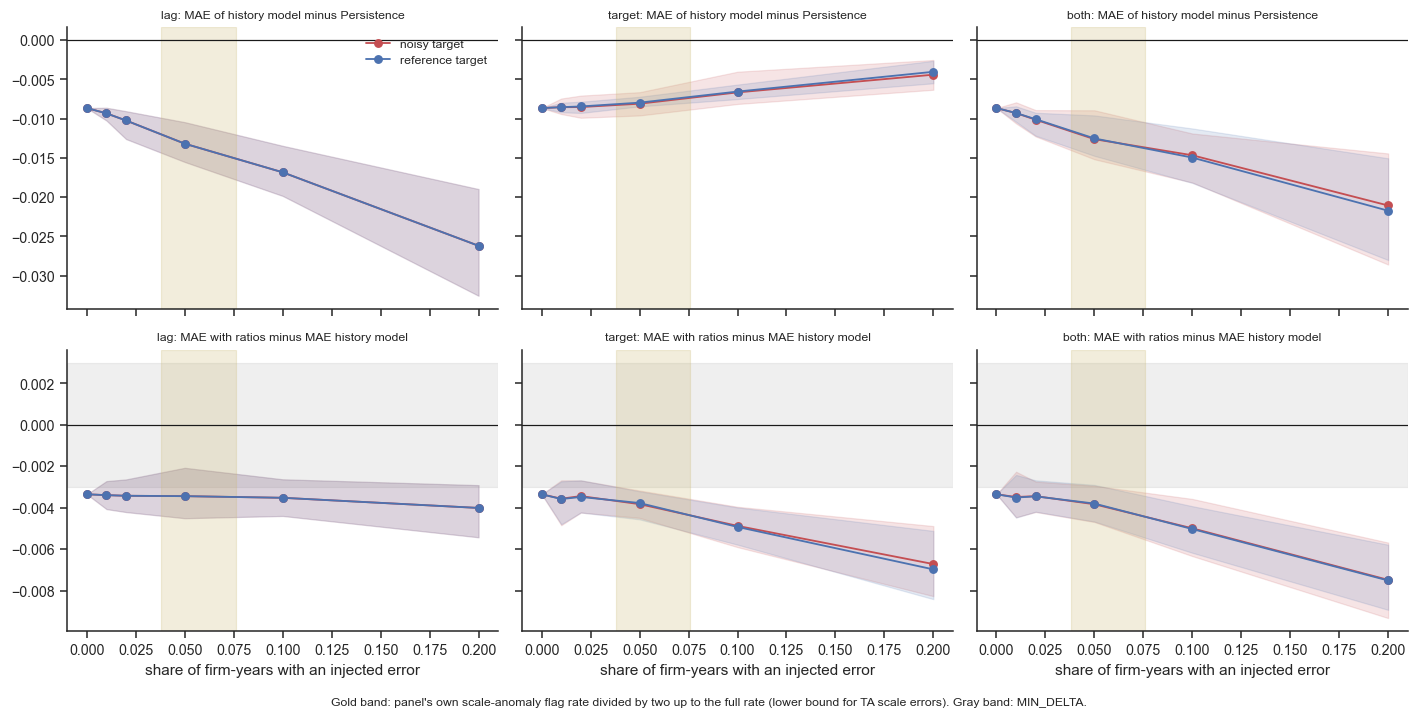

In [57]:
def _flat(res):
    rows = []
    for r in res:
        j = r["job"]
        for ev in ("noisy", "ref"):
            m = r[ev]
            rows.append({**j, "eval": ev, "n": m["n"], "eff_share": r["eff_share"], "n_train": r["n_train"], "gap_hist": m["mae_hist"] - m["mae_pers"],
                         "gap_hc": m["mae_hc"] - m["mae_pers"], "gap_ar1": m["mae_ar1"] - m["mae_pers"], "ratio_contrib": m["mae_hc"] - m["mae_hist"],
                         "lab_hist_pers": m["lab_hist_pers"], "lab_hc_hist": m["lab_hc_hist"], "lab_hc_pers": m["lab_hc_pers"],
                         "mae_pers": m["mae_pers"], "mae_hist": m["mae_hist"], "mae_hc": m["mae_hc"]})
    return pd.DataFrame(rows)

EI_DF = _flat(EI_RESULTS)
_base = EI_DF[(EI_DF["variant"] == "main") & (EI_DF["share"] == 0) & (~EI_DF["filt"]) & (~EI_DF["retune"])]
_ref_base = EI_DF[(EI_DF["variant"] == "ref") & (EI_DF["share"] == 0)]
# the deterministic 0% chunk stands for every mode
_extra = []
for mode in ("lag", "target"):
    _extra.append(_base.assign(mode=mode))
EI_DF = pd.concat([EI_DF] + _extra, ignore_index=True)
EI_MAIN = EI_DF[(EI_DF["variant"] == "main") & (EI_DF["mix"] == "main") & (~EI_DF["filt"]) & (~EI_DF["retune"])]

def modal(s):
    return s.value_counts().idxmax()

def summarize(df, keys):
    g = df.groupby(keys)
    out = g.agg(reps=("seed", "nunique"), gap_hist=("gap_hist", "mean"), gap_hist_lo=("gap_hist", lambda s: s.quantile(0.025)), gap_hist_hi=("gap_hist", lambda s: s.quantile(0.975)),
                gap_hc=("gap_hc", "mean"), ratio_contrib=("ratio_contrib", "mean"), rc_lo=("ratio_contrib", lambda s: s.quantile(0.025)), rc_hi=("ratio_contrib", lambda s: s.quantile(0.975)),
                lab_hist_pers=("lab_hist_pers", modal), lab_hc_hist=("lab_hc_hist", modal),
                share_hist_better=("lab_hist_pers", lambda s: (s == "better").mean()), share_hc_equivalent=("lab_hc_hist", lambda s: (s == "equivalent").mean()))
    return out

EI_SUM = summarize(EI_MAIN, ["mode", "eval", "share"])
print("Main mix, observed panel plus noise; means over repetitions with 2.5 to 97.5 percent range; labels are the modal label over repetitions.")
display(EI_SUM.round(4))

def change_points(summary):
    rows = []
    for (mode, ev), sub in summary.groupby(level=[0, 1]):
        sub = sub.droplevel([0, 1]).sort_index()
        b1, b2 = sub.loc[0.0, "lab_hist_pers"], sub.loc[0.0, "lab_hc_hist"]
        c1 = next((s for s in sub.index if s > 0 and sub.loc[s, "lab_hist_pers"] != b1), None)
        c2 = next((s for s in sub.index if s > 0 and sub.loc[s, "lab_hc_hist"] != b2), None)
        rows.append({"mode": mode, "evaluated against": ev, "label at 0%: history model vs Persistence": b1, "first share where it changes": c1,
                     "label at 0%: ratios vs history": b2, "first share where it changes ": c2})
    return pd.DataFrame(rows).set_index(["mode", "evaluated against"])
EI_CHANGE = change_points(EI_SUM)
print(f"Change points (shares of firm-years; the real panel has {100 * EI_REAL_FLAG_RATE:.1f}% of firm-years with a scale-anomaly flag):")
display(EI_CHANGE)

# apparent versus true gain, same repetition
_pv = EI_MAIN.pivot_table(index=["mode", "share", "seed"], columns="eval", values=["gap_hist", "ratio_contrib"])
_pv.columns = [f"{a}_{b}" for a, b in _pv.columns]
_pv["inflation_gap_hist"] = _pv["gap_hist_noisy"] - _pv["gap_hist_ref"]
_pv["inflation_ratio_contrib"] = _pv["ratio_contrib_noisy"] - _pv["ratio_contrib_ref"]
EI_INFLATION = _pv.groupby(["mode", "share"])[["inflation_gap_hist", "inflation_ratio_contrib"]].agg(["mean", lambda s: s.quantile(0.025), lambda s: s.quantile(0.975)]).round(4)
EI_INFLATION.columns = ["gap: mean", "gap: 2.5%", "gap: 97.5%", "ratio contribution: mean", "ratio contribution: 2.5%", "ratio contribution: 97.5%"]
print("Apparent (noisy target) minus true (reference target) value of the two quantities, by mode and share:")
display(EI_INFLATION)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True, sharey="row")
xs = EI_SHARES
for j, mode in enumerate(EI_MODES):
    for row, (col, title) in enumerate((("gap_hist", "MAE of history model minus Persistence"), ("ratio_contrib", "MAE with ratios minus MAE history model"))):
        ax = axes[row, j]
        for ev, color in (("noisy", PALETTE["red"]), ("ref", PALETTE["blue"])):
            sub = EI_SUM.loc[(mode, ev)].reindex(xs)
            mean = sub["gap_hist" if col == "gap_hist" else "ratio_contrib"]
            lo = sub["gap_hist_lo" if col == "gap_hist" else "rc_lo"]
            hi = sub["gap_hist_hi" if col == "gap_hist" else "rc_hi"]
            ax.plot(xs, mean, marker="o", color=color, label="noisy target" if ev == "noisy" else "reference target")
            ax.fill_between(xs, lo, hi, color=color, alpha=0.15)
        ax.axhline(0, color="k", lw=0.8)
        if col == "ratio_contrib":
            ax.axhspan(-MIN_DELTA["MAE"], MIN_DELTA["MAE"], color="gray", alpha=0.12)
        ax.axvspan(EI_REAL_FLAG_RATE / 2, EI_REAL_FLAG_RATE, color=PALETTE["gold"], alpha=0.25)
        ax.set_title(f"{mode}: {title}", fontsize=8)
        if row == 1:
            ax.set_xlabel("share of firm-years with an injected error")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.text(0.5, 0.005, "Gold band: panel's own scale-anomaly flag rate divided by two up to the full rate (lower bound for TA scale errors). Gray band: MIN_DELTA.", ha="center", fontsize=8)
plt.tight_layout(rect=(0, 0.02, 1, 1)); plt.show()

for name_, t_ in (("error_injection_summary_main.csv", EI_SUM), ("error_injection_change_points.csv", EI_CHANGE), ("error_injection_inflation.csv", EI_INFLATION),
                  ("error_injection_chunks_main.csv", EI_MAIN)):
    t_.to_csv(os.path.join(RESULTS_DIR, name_))

### 23d.5 Robustness of the design, detection and filtering

In [58]:
# Sensitivity to the error mix (mode both) and to the reference panel variant
_sens = EI_DF[(EI_DF["variant"] == "main") & (EI_DF["mode"] == "both") & (~EI_DF["filt"]) & (~EI_DF["retune"]) & (EI_DF["share"].isin([0.0] + EI_SENS_SHARES))]
EI_SENS = summarize(_sens, ["mix", "eval", "share"])
print("Sensitivity to the error mix (mode both; the 0% row belongs to the main mix only):")
display(EI_SENS.round(4))

_ref = EI_DF[(EI_DF["variant"] == "ref") & (~EI_DF["filt"]) & (~EI_DF["retune"])]
EI_REFVAR = summarize(_ref, ["eval", "share"])
print("Reference panel variant (firm-years with any quality flag set to missing), mode both:")
display(EI_REFVAR.round(4))

# Retuning check
_rt = EI_DF[(EI_DF["variant"] == "main") & (EI_DF["mix"] == "main") & (EI_DF["mode"] == "both") & (EI_DF["share"] == EI_RETUNE_SHARE) & (~EI_DF["filt"]) & (EI_DF["seed"] < EI_SEED0 + EI_RETUNE_SEEDS)]
_rt = _rt.assign(tuning=np.where(_rt["retune"], "retuned on the corrupted panel", "cached hyperparameters"))
EI_RETUNE = _rt.groupby(["tuning", "eval"]).agg(reps=("seed", "nunique"), gap_hist=("gap_hist", "mean"), ratio_contrib=("ratio_contrib", "mean"),
                                                lab_hist_pers=("lab_hist_pers", modal), lab_hc_hist=("lab_hc_hist", modal))
print(f"Retuning check at {100 * EI_RETUNE_SHARE:.0f}% (mode both):")
display(EI_RETUNE.round(4))

# Detection of the injected errors by the pipeline's own rules
det = pd.concat([r["detection"].assign(share=r["job"]["share"]) for r in EI_RESULTS if r["detection"] is not None], ignore_index=True)
def _rates(g):
    return g.agg(events=("row", "size"), identity_rule=("ident", "mean"), ta_jump_rule=("ocr", "mean"), either_rule=("either", "mean"), newly_flagged_either=("new_either", "mean"))
pure = det[det["pattern"] != "both"]          # one corrupted field per firm-year, so a flag can be attributed to that field
EI_DET_TYPE = _rates(pure.groupby("type"))
EI_DET_FIELD = _rates(pure.groupby("field"))
EI_DET_BOTH = _rates(pure.groupby(["field", "type"]))
EI_DET_PATTERN = _rates(det.drop_duplicates(["row", "share", "pattern"]).groupby("pattern"))
_bl = [r["baseline_flag_rate_clean_rows"] for r in EI_RESULTS if r.get("detection") is not None and "baseline_flag_rate_clean_rows" in r]
print(f"Baseline: {100 * EI_FLAG0.mean():.1f}% of firm-years in the observed panel are flagged by either rule; among uncorrupted firm-years of the simulated panels {100 * np.mean(_bl):.1f}%.")
print("Detection of a corrupted firm-year by the pipeline's own rules, main mix, pooled over shares 1 to 20%; firm-years with one corrupted field, by error type:"); display(EI_DET_TYPE.round(3))
print("By field:"); display(EI_DET_FIELD.round(3))
print("By field and type:"); display(EI_DET_BOTH.round(3))
print("By corruption pattern (firm-years); newly flagged for NP-only firm-years comes from TA errors of the neighbouring year, because the jump rule compares consecutive years:"); display(EI_DET_PATTERN.round(3))

# Dropping flagged firm-years: how much of the distortion of the gain is removed
_fu = EI_DF[(EI_DF["variant"] == "main") & (EI_DF["mix"] == "main") & (EI_DF["mode"] == "both") & (~EI_DF["retune"]) & (EI_DF["share"].isin([0.0] + EI_FILTER_SHARES))]
rows = []
for s in [0.0] + EI_FILTER_SHARES:
    row = {"share": s}
    for tag, sub in (("unfiltered", _fu[(~_fu["filt"]) & (_fu["share"] == s)]), ("filtered", _fu[(_fu["filt"]) & (_fu["share"] == s)])):
        pv = sub.pivot_table(index="seed", columns="eval", values=["gap_hist", "ratio_contrib"])
        pv.columns = [f"{a}_{b}" for a, b in pv.columns]
        row[f"{tag}: gap bias (noisy minus reference)"] = (pv["gap_hist_noisy"] - pv["gap_hist_ref"]).mean()
        row[f"{tag}: ratio contribution bias"] = (pv["ratio_contrib_noisy"] - pv["ratio_contrib_ref"]).mean()
        row[f"{tag}: gap on noisy target"] = pv["gap_hist_noisy"].mean()
        row[f"{tag}: test rows"] = sub[sub["eval"] == "noisy"]["n"].mean()
    rows.append(row)
EI_FILTER = pd.DataFrame(rows).set_index("share")
_b0 = EI_FILTER.loc[0.0]
EI_FILTER["drift of gap from the 0% run, unfiltered"] = EI_FILTER["unfiltered: gap on noisy target"] - _b0["unfiltered: gap on noisy target"]
EI_FILTER["drift of gap from the 0% run, filtered"] = EI_FILTER["filtered: gap on noisy target"] - _b0["filtered: gap on noisy target"]
_bu = EI_FILTER["unfiltered: gap bias (noisy minus reference)"] - _b0["unfiltered: gap bias (noisy minus reference)"]
_bf = EI_FILTER["filtered: gap bias (noisy minus reference)"] - _b0["filtered: gap bias (noisy minus reference)"]
EI_FILTER["gap bias net of the 0% run, unfiltered"], EI_FILTER["gap bias net of the 0% run, filtered"] = _bu, _bf
EI_FILTER["share of gap bias removed"] = np.where(_bu.abs() >= 1e-4, 1 - _bf.abs() / _bu.abs().replace(0, np.nan), np.nan)
EI_FILTER["firm-years dropped (%)"] = 100 * pd.Series({s: np.mean([r["dropped_share_firm_years"] for r in EI_RESULTS if r["job"]["filt"] and r["job"]["share"] == s]) for s in [0.0] + EI_FILTER_SHARES})
print("Dropping firm-years flagged by the identity rule or the TA jump rule (mode both). Bias is the apparent minus the reference-target value; "
      "net of the 0% run in the same setting; the share removed is left empty when the unfiltered bias is below 0.0001:")
display(EI_FILTER.round(4))

for name_, t_ in (("error_injection_sensitivity_mix.csv", EI_SENS), ("error_injection_reference_variant.csv", EI_REFVAR), ("error_injection_retune.csv", EI_RETUNE),
                  ("error_injection_detection_by_type.csv", EI_DET_TYPE), ("error_injection_detection_by_field.csv", EI_DET_FIELD),
                  ("error_injection_detection_by_field_type.csv", EI_DET_BOTH), ("error_injection_detection_by_pattern.csv", EI_DET_PATTERN),
                  ("error_injection_filtering.csv", EI_FILTER)):
    t_.to_csv(os.path.join(RESULTS_DIR, name_))

Sensitivity to the error mix (mode both; the 0% row belongs to the main mix only):


reps  gap_hist  gap_hist_lo  gap_hist_hi  gap_hc  ratio_contrib   rc_lo   rc_hi lab_hist_pers lab_hc_hist  share_hist_better  share_hc_equivalent
mix            eval  share                                                                                                                                                   
alternative    noisy 0.05     10   -0.0138      -0.0181      -0.0111 -0.0180        -0.0042 -0.0054 -0.0033        better      better                1.0                  0.0
                     0.10     10   -0.0178      -0.0215      -0.0142 -0.0233        -0.0055 -0.0066 -0.0047        better      better                1.0                  0.0
                     0.20     10   -0.0264      -0.0313      -0.0234 -0.0340        -0.0077 -0.0092 -0.0060        better      better                1.0                  0.0
               ref   0.05     10   -0.0136      -0.0176      -0.0106 -0.0179        -0.0042 -0.0055 -0.0032        better      better                1.0                  0.0
                     0.10     10   -0.0176      -0.0198      -0.0144 -0.0230        -0.0054 -0.0068 -0.0039        better      better                1.0                  0.0
                     0.20     10   -0.0270      -0.0319      -0.0234 -0.0346        -0.0076 -0.0098 -0.0062        better      better                1.0                  0.0
main           noisy 0.00      1   -0.0087      -0.0087      -0.0087 -0.0120        -0.0034 -0.0034 -0.0034        better      better                1.0                  0.0
                     0.05     20   -0.0126      -0.0152      -0.0089 -0.0165        -0.0038 -0.0047 -0.0029        better      better                1.0                  0.0
                     0.10     20   -0.0147      -0.0181      -0.0119 -0.0197        -0.0050 -0.0063 -0.0036        better      better                1.0                  0.0
                     0.20     20   -0.0211      -0.0286      -0.0144 -0.0286        -0.0075 -0.0093 -0.0057        better      better                1.0                  0.0
               ref   0.00      1   -0.0087      -0.0087      -0.0087 -0.0120        -0.0034 -0.0034 -0.0034        better      better                1.0                  0.0
                     0.05     20   -0.0125      -0.0147      -0.0096 -0.0163        -0.0038 -0.0047 -0.0029        better      better                1.0                  0.0
                     0.10     20   -0.0150      -0.0182      -0.0113 -0.0200        -0.0050 -0.0062 -0.0039        better      better                1.0                  0.0
                     0.20     20   -0.0217      -0.0280      -0.0151 -0.0293        -0.0075 -0.0089 -0.0058        better      better                1.0                  0.0
non_scale_only noisy 0.05     10   -0.0114      -0.0138      -0.0092 -0.0152        -0.0038 -0.0046 -0.0028        better      better                1.0                  0.0
                     0.10     10   -0.0138      -0.0177      -0.0114 -0.0179        -0.0041 -0.0053 -0.0027        better      better                1.0                  0.0
                     0.20     10   -0.0142      -0.0171      -0.0119 -0.0198        -0.0056 -0.0068 -0.0043        better      better                1.0                  0.0
               ref   0.05     10   -0.0112      -0.0133      -0.0094 -0.0149        -0.0038 -0.0046 -0.0027        better      better                1.0                  0.0
                     0.10     10   -0.0133      -0.0162      -0.0110 -0.0173        -0.0041 -0.0052 -0.0023        better      better                1.0                  0.0
                     0.20     10   -0.0146      -0.0171      -0.0111 -0.0201        -0.0055 -0.0066 -0.0038        better      better                1.0                  0.0
scale_only     noisy 0.05     10   -0.0112      -0.0128      -0.0094 -0.0152        -0.0040 -0.0046 -0.0034        better      better                1.0                  0.0
                     0.10 

Reference panel variant (firm-years with any quality flag set to missing), mode both:


reps  gap_hist  gap_hist_lo  gap_hist_hi  gap_hc  ratio_contrib   rc_lo   rc_hi      lab_hist_pers lab_hc_hist  share_hist_better  share_hc_equivalent
eval  share                                                                                                                                                        
noisy 0.00      1    0.0005       0.0005       0.0005 -0.0041        -0.0046 -0.0046 -0.0046  indistinguishable      better                0.0                  0.0
      0.01     10    0.0002      -0.0015       0.0015 -0.0048        -0.0050 -0.0057 -0.0040  indistinguishable      better                0.0                  0.0
      0.02     10   -0.0006      -0.0021       0.0018 -0.0055        -0.0050 -0.0068 -0.0038  indistinguishable      better                0.0                  0.0
      0.05     10   -0.0030      -0.0064      -0.0008 -0.0082        -0.0052 -0.0061 -0.0041  indistinguishable      better                0.0                  0.0
      0.10     10   -0.0061      -0.0100      -0.0029 -0.0126        -0.0064 -0.0083 -0.0026  indistinguishable      better                0.2                  0.0
      0.20     10   -0.0132      -0.0219      -0.0058 -0.0220        -0.0088 -0.0105 -0.0073             better      better                0.6                  0.0
ref   0.00      1    0.0005       0.0005       0.0005 -0.0041        -0.0046 -0.0046 -0.0046  indistinguishable      better                0.0                  0.0
      0.01     10    0.0005      -0.0007       0.0015 -0.0044        -0.0049 -0.0056 -0.0040  indistinguishable      better                0.0                  0.0
      0.02     10   -0.0004      -0.0023       0.0018 -0.0053        -0.0049 -0.0065 -0.0039  indistinguishable      better                0.0                  0.0
      0.05     10   -0.0031      -0.0061      -0.0008 -0.0084        -0.0054 -0.0065 -0.0043  indistinguishable      better                0.0                  0.0
      0.10     10   -0.0057      -0.0098      -0.0027 -0.0122        -0.0065 -0.0078 -0.0037  indistinguishable      better                0.2                  0.0
      0.20     10   -0.0121      -0.0183      -0.0047 -0.0213        -0.0092 -0.0114 -0.0076             better      better                0.7                  0.0

Retuning check at 5% (mode both):


reps  gap_hist  ratio_contrib lab_hist_pers        lab_hc_hist
tuning                         eval                                                                 
cached hyperparameters         noisy     3   -0.0127        -0.0033        better             better
                               ref       3   -0.0121        -0.0033        better             better
retuned on the corrupted panel noisy     3   -0.0133        -0.0027        better  indistinguishable
                               ref       3   -0.0127        -0.0027        better  indistinguishable

... (6 outputs left out)

By corruption pattern (firm-years); newly flagged for NP-only firm-years comes from TA errors of the neighbouring year, because the jump rule compares consecutive years:


,events,identity_rule,ta_jump_rule,either_rule,newly_flagged_either
pattern,,,,,
NP,12717,0.225,0.114,0.308,0.035
TA,17672,1.000,0.405,1.000,0.726
both,43363,1.000,0.409,1.000,0.726


Dropping firm-years flagged by the identity rule or the TA jump rule (mode both). Bias is the apparent minus the reference-target value; net of the 0% run in the same setting; the share removed is left empty when the unfiltered bias is below 0.0001:


,unfiltered: gap bias (noisy minus reference),unfiltered: ratio contribution bias,unfiltered: gap on noisy target,unfiltered: test rows,filtered: gap bias (noisy minus reference),filtered: ratio contribution bias,filtered: gap on noisy target,filtered: test rows,"drift of gap from the 0% run, unfiltered","drift of gap from the 0% run, filtered","gap bias net of the 0% run, unfiltered","gap bias net of the 0% run, filtered",share of gap bias removed,firm-years dropped (%)
share,,,,,,,,,,,,,,
0.00,0.0000,0.0,-0.0087,1662.00,0.0018,-0.0008,0.0005,1033.0,0.0000,0.0000,0.0000,0.0000,NaN,33.9400
0.05,-0.0001,-0.0,-0.0126,1627.70,0.0016,-0.0014,-0.0002,923.2,-0.0040,-0.0008,-0.0001,-0.0002,NaN,37.5525
0.10,0.0003,0.0,-0.0147,1590.00,0.0017,-0.0012,-0.0005,824.6,-0.0060,-0.0010,0.0003,-0.0001,0.8144,41.1030
0.20,0.0007,0.0,-0.0211,1523.95,0.0022,-0.0014,-0.0038,644.8,-0.0124,-0.0043,0.0007,0.0004,0.3574,47.8370


### 23d.6 Revision after the first run: matched pairs

The first run compared models that differ in loss and in history length, so its ratio contribution is confounded. Cells above and their outputs are kept as the original design. Here the ratio contribution uses matched pairs (same loss, same history length).

- Pair A (primary): the history model of the first run and its ratio counterpart. Pair B (robustness): the ratio model of the first run and its history counterpart.
- Grid, modes, repetitions, metrics and change rule as in 23d.2; pair B runs mode both only. Added mix: joint scale error in TA and NP.


In [59]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning, message="divide by zero encountered in divide")
warnings.filterwarnings("ignore", category=RuntimeWarning, message="invalid value encountered in divide")

def counterpart(name, to):
    base, suf = name.rsplit("_", 1)
    return f"{base}_{to}{suf[1:]}"

EI_PAIRS = {"A": (EI_HIST, counterpart(EI_HIST, "C")), "B": (counterpart(EI_HC, "R"), EI_HC)}
for a, b in EI_PAIRS.values():
    assert a in TUNED and b in TUNED, (a, b)

# Share of filings with errors in both TA and NP whose two errors are scale errors with the same exponent
_bo = EI_OBS[EI_OBS["field"].isin(["TA", "NP"]) & (EI_OBS["type"] != "correct")] if len(EI_OBS) else EI_OBS
_g = _bo.groupby(["gemh_id", "year"]) if len(_bo) else None
_both = [g for _, g in _g if set(g["field"]) == {"TA", "NP"}] if _g is not None else []
if len(_both) >= 5:
    EI_JOINT_Q = float(np.mean([bool((g["type"] == "scale").all() and g["k"].nunique() == 1) for g in _both]))
    EI_JOINT_SOURCE = f"empirical ({len(_both)} filings with both fields wrong)"
else:
    EI_JOINT_Q, EI_JOINT_SOURCE = 0.5, "default (fewer than 5 filings with both fields wrong)"
EI_MIXES2 = dict(EI_MIXES)
EI_MIXES2["joint_scale"] = {**EI_MIXES["main"], "joint_q": EI_JOINT_Q}
print(f"Pair A: {EI_PAIRS['A'][0]} vs {EI_PAIRS['A'][1]}; pair B: {EI_PAIRS['B'][0]} vs {EI_PAIRS['B'][1]}.")
print(f"Joint scale variant: with probability {EI_JOINT_Q:.2f} a firm-year with both fields corrupted gets the same scale exponent in TA and NP ({EI_JOINT_SOURCE}).")

EI_PLAN_REV = {"pairs": {k: {"history": v[0], "history_plus_ratios": v[1]} for k, v in EI_PAIRS.items()}, "joint_q": EI_JOINT_Q, "joint_source": EI_JOINT_SOURCE,
               "runs": {"pair_A": "all modes and shares, sensitivity mixes incl. joint_scale, reference variant, filtering, retuning", "pair_B": "mode both, main mix, retuning"},
               "reason": "ratio contribution of the first run compared models with different loss and history length",
               "created": datetime.now().isoformat(timespec="seconds")}
with open(os.path.join(RESULTS_DIR, "error_injection_plan_revision.json"), "w", encoding="utf-8") as f:
    json.dump(EI_PLAN_REV, f, indent=2)

# Corruption with an optional joint scale error; the first-run function is kept and used when joint_q is not set
if "_corrupt_panel_v13" not in globals():
    _corrupt_panel_v13 = corrupt_panel

def _corrupt_joint(seed, share, mix, base_np, base_ta):
    elig = np.isfinite(base_np) & np.isfinite(base_ta)
    hit, pat, rng, types, tp, ks, kp = draw_corruption(seed, share, mix, elig)
    np_c, ta_c = base_np.copy(), base_ta.copy()
    ev = []
    for i, p in zip(hit, pat):
        if p == "both" and rng.random() < mix["joint_q"]:
            k = float(rng.choice(ks, p=kp))
            ta_c[i], np_c[i] = ta_c[i] * 10.0 ** k, np_c[i] * 10.0 ** k
            ev += [(int(i), "TA", "scale", "both"), (int(i), "NP", "scale", "both")]
            continue
        for fld in (["TA", "NP"] if p == "both" else [p]):
            et = types[rng.choice(len(types), p=tp)]
            k = float(rng.choice(ks, p=kp)) if et == "scale" else np.nan
            rel = float(rng.choice(mix["rel"])) if et == "other" else np.nan
            if fld == "TA":
                ta_c[i] = apply_error(ta_c[i], et, k, rel)
            else:
                np_c[i] = apply_error(np_c[i], et, k, rel)
            ev.append((int(i), fld, et, str(p)))
    return np_c, ta_c, pd.DataFrame(ev, columns=["row", "field", "type", "pattern"])

def corrupt_panel(seed, share, mix, base_np, base_ta):
    if mix.get("joint_q", 0.0) > 0:
        return _corrupt_joint(seed, share, mix, base_np, base_ta)
    return _corrupt_panel_v13(seed, share, mix, base_np, base_ta)

def make_ctx(hist_name, hc_name):
    ch, cc = FEATURE_SETS[MODEL_SPECS[hist_name]["feats"]], FEATURE_SETS[MODEL_SPECS[hc_name]["feats"]]
    xc = sorted(set(ch) | set(cc) | {"ROA_t"})
    return {**EI_CTX, "cols_hist": ch, "cols_hc": cc, "est_hist": TUNED[hist_name].best_estimator_, "est_hc": TUNED[hc_name].best_estimator_,
            "kind_hist": MODEL_SPECS[hist_name]["kind"], "kind_hc": MODEL_SPECS[hc_name]["kind"], "X_cols": xc, "X_arr": model_df[xc].to_numpy(float),
            "mixes": EI_MIXES2}
EI_CTX_A, EI_CTX_B = make_ctx(*EI_PAIRS["A"]), make_ctx(*EI_PAIRS["B"])

def _job2(pair, variant, mix, mode, share, seed, filt=False, retune=False):
    j = _job(variant, mix, mode, share, seed, filt, retune)
    j.update({"pair": pair, "hist": EI_PAIRS[pair][0], "hc": EI_PAIRS[pair][1], "rev": 2, "joint_q": round(EI_JOINT_Q, 6)})
    return j

def ei_run_jobs2(ctx, jobs):
    paths = {ei_key(j): os.path.join(CACHE_DIR, f"errinj_{ei_key(j)}.joblib") for j in jobs}
    got, todo = {}, []
    for j in jobs:
        k = ei_key(j)
        if USE_CACHE and not REFRESH_CACHE and os.path.exists(paths[k]):
            try:
                got[k] = joblib.load(paths[k])
                continue
            except Exception:
                pass
        todo.append(j)
    print(f"[cache] error injection: {len(jobs) - len(todo)} of {len(jobs)} chunks loaded, {len(todo)} to compute")
    if todo:
        res = joblib.Parallel(n_jobs=N_JOBS)(joblib.delayed(ei_worker)(ctx, j) for j in todo)
        os.makedirs(CACHE_DIR, exist_ok=True)
        for j, r in zip(todo, res):
            got[ei_key(j)] = r
            if USE_CACHE:
                joblib.dump(r, paths[ei_key(j)], compress=3)
    return [got[ei_key(j)] for j in jobs]

jobsA = [_job2("A", "main", "main", "both", 0.0, 0)]
for mode in EI_MODES:
    for s in EI_SHARES[1:]:
        for r in range(EI_REPS):
            jobsA.append(_job2("A", "main", "main", mode, s, EI_SEED0 + r))
for mix in [m for m in ("scale_only", "non_scale_only", "alternative", "joint_scale") if m in EI_MIXES2]:
    for s in EI_SENS_SHARES:
        for r in range(EI_REPS_SENS):
            jobsA.append(_job2("A", "main", mix, "both", s, EI_SEED0 + r))
jobsA.append(_job2("A", "ref", "main", "both", 0.0, 0))
for s in EI_SHARES[1:]:
    for r in range(EI_REPS_REF):
        jobsA.append(_job2("A", "ref", "main", "both", s, EI_SEED0 + r))
jobsA.append(_job2("A", "main", "main", "both", 0.0, 0, filt=True))
for s in EI_FILTER_SHARES:
    for r in range(EI_REPS_FILTER):
        jobsA.append(_job2("A", "main", "main", "both", s, EI_SEED0 + r, filt=True))
for r in range(EI_RETUNE_SEEDS):
    jobsA.append(_job2("A", "main", "main", "both", EI_RETUNE_SHARE, EI_SEED0 + r, retune=True))
jobsB = [_job2("B", "main", "main", "both", 0.0, 0)]
for s in EI_SHARES[1:]:
    for r in range(EI_REPS):
        jobsB.append(_job2("B", "main", "main", "both", s, EI_SEED0 + r))
for r in range(EI_RETUNE_SEEDS):
    jobsB.append(_job2("B", "main", "main", "both", EI_RETUNE_SHARE, EI_SEED0 + r, retune=True))
t0 = time.time()
EI_RESULTS2 = ei_run_jobs2(EI_CTX_A, jobsA) + ei_run_jobs2(EI_CTX_B, jobsB)
print(f"Matched pairs: {len(jobsA) + len(jobsB)} chunks in {time.time() - t0:.0f}s")

Pair A: XGB_L2_R5 vs XGB_L2_C5; pair B: XGB_Huber_R3 vs XGB_Huber_C3.
Joint scale variant: with probability 0.33 a firm-year with both fields corrupted gets the same scale exponent in TA and NP (empirical (12 filings with both fields wrong)).
[cache] error injection: 0 of 506 chunks loaded, 506 to compute
[cache] error injection: 0 of 104 chunks loaded, 104 to compute
Matched pairs: 610 chunks in 789s


### 23d.7 Matched pairs: gain and ratio contribution against the error share

Pair A (XGB_L2_R5 vs XGB_L2_C5), main mix, observed panel plus noise; means over repetitions, 2.5 to 97.5 percent range, modal labels:


reps  gap_hist  gap_hist_lo  gap_hist_hi  gap_hc  ratio_contrib   rc_lo   rc_hi      lab_hist_pers        lab_hc_hist  share_hist_better  share_hc_equivalent
mode   eval  share                                                                                                                                                               
both   noisy 0.00      1   -0.0087      -0.0087      -0.0087 -0.0097        -0.0010 -0.0010 -0.0010             better         equivalent               1.00                 1.00
             0.01     20   -0.0093      -0.0106      -0.0079 -0.0097        -0.0004 -0.0012  0.0002             better         equivalent               1.00                 0.95
             0.02     20   -0.0101      -0.0123      -0.0089 -0.0109        -0.0008 -0.0015 -0.0000             better         equivalent               1.00                 0.80
             0.05     20   -0.0126      -0.0152      -0.0089 -0.0134        -0.0008 -0.0017  0.0002             better         equivalent               1.00                 0.85
             0.10     20   -0.0147      -0.0181      -0.0119 -0.0158        -0.0011 -0.0024  0.0004             better         equivalent               1.00                 0.50
             0.20     20   -0.0211      -0.0286      -0.0144 -0.0228        -0.0017 -0.0032 -0.0001             better    slightly better               1.00                 0.25
       ref   0.00      1   -0.0087      -0.0087      -0.0087 -0.0097        -0.0010 -0.0010 -0.0010             better         equivalent               1.00                 1.00
             0.01     20   -0.0093      -0.0104      -0.0084 -0.0097        -0.0004 -0.0010  0.0002             better         equivalent               1.00                 0.95
             0.02     20   -0.0101      -0.0122      -0.0092 -0.0108        -0.0008 -0.0015 -0.0001             better         equivalent               1.00                 0.70
             0.05     20   -0.0125      -0.0147      -0.0096 -0.0132        -0.0006 -0.0015  0.0004             better         equivalent               1.00                 0.80
             0.10     20   -0.0150      -0.0182      -0.0113 -0.0161        -0.0011 -0.0022  0.0003             better         equivalent               1.00                 0.55
             0.20     20   -0.0217      -0.0280      -0.0151 -0.0232        -0.0015 -0.0029 -0.0001             better  indistinguishable               1.00                 0.30
lag    noisy 0.00      1   -0.0087      -0.0087      -0.0087 -0.0097        -0.0010 -0.0010 -0.0010             better         equivalent               1.00                 1.00
             0.01     20   -0.0093      -0.0102      -0.0086 -0.0102        -0.0009 -0.0017 -0.0004             better         equivalent               1.00                 0.85
             0.02     20   -0.0102      -0.0126      -0.0090 -0.0110        -0.0008 -0.0014 -0.0003             better         equivalent               1.00                 0.95
             0.05     20   -0.0132      -0.0155      -0.0104 -0.0138        -0.0006 -0.0017  0.0004             better         equivalent               1.00                 0.85
             0.10     20   -0.0168      -0.0199      -0.0135 -0.0174        -0.0006 -0.0016  0.0006             better         equivalent               1.00                 0.85
             0.20     20   -0.0262      -0.0326      -0.0190 -0.0265        -0.0003 -0.0015  0.0006             better         equivalent               1.00                 0.95
       ref   0.00      1   -0.0087      -0.0087      -0.0087 -0.0097        -0.0010 -0.0010 -0.0010             better         equivalent               1.00                 1.00
             0.01     20   -0.0093      -0.0102      -0.0086 -0.0102        -0.0009 -0.0017 -0.0004             better         equivalent               1.00                 0.85
             0.02     20   -0.0102      -0.0126      -0.0090 -0.0110        -0.0008 -0.0014 -0.0003     

Pair B (XGB_Huber_R3 vs XGB_Huber_C3), mode both:


reps  gap_hist  gap_hist_lo  gap_hist_hi  gap_hc  ratio_contrib   rc_lo   rc_hi lab_hist_pers        lab_hc_hist  share_hist_better  share_hc_equivalent
eval  share                                                                                                                                                          
noisy 0.00      1   -0.0105      -0.0105      -0.0105 -0.0120        -0.0015 -0.0015 -0.0015        better  indistinguishable                1.0                 0.00
      0.01     20   -0.0111      -0.0123      -0.0098 -0.0128        -0.0017 -0.0024 -0.0007        better    slightly better                1.0                 0.15
      0.02     20   -0.0121      -0.0143      -0.0107 -0.0136        -0.0015 -0.0023 -0.0008        better  indistinguishable                1.0                 0.20
      0.05     20   -0.0148      -0.0172      -0.0119 -0.0165        -0.0017 -0.0025 -0.0010        better  indistinguishable                1.0                 0.20
      0.10     20   -0.0181      -0.0217      -0.0151 -0.0197        -0.0016 -0.0031 -0.0006        better         equivalent                1.0                 0.35
      0.20     20   -0.0264      -0.0353      -0.0202 -0.0286        -0.0021 -0.0037 -0.0005        better    slightly better                1.0                 0.15
ref   0.00      1   -0.0105      -0.0105      -0.0105 -0.0120        -0.0015 -0.0015 -0.0015        better  indistinguishable                1.0                 0.00
      0.01     20   -0.0111      -0.0121      -0.0102 -0.0128        -0.0017 -0.0024 -0.0008        better    slightly better                1.0                 0.25
      0.02     20   -0.0120      -0.0144      -0.0109 -0.0135        -0.0015 -0.0023 -0.0009        better    slightly better                1.0                 0.30
      0.05     20   -0.0147      -0.0169      -0.0120 -0.0163        -0.0017 -0.0026 -0.0012        better    slightly better                1.0                 0.15
      0.10     20   -0.0184      -0.0214      -0.0148 -0.0200        -0.0016 -0.0028 -0.0006        better    slightly better                1.0                 0.25
      0.20     20   -0.0272      -0.0343      -0.0207 -0.0293        -0.0021 -0.0033 -0.0011        better    slightly better                1.0                 0.00

Change points, pair A:


label at 0%: history model vs Persistence  first share where it changes label at 0%: ratios vs history  first share where it changes 
mode   evaluated against                                                                                                                                      
both   noisy                                                better                           NaN                     equivalent                            0.2
       ref                                                  better                           NaN                     equivalent                            0.2
lag    noisy                                                better                           NaN                     equivalent                            NaN
       ref                                                  better                           NaN                     equivalent                            NaN
target noisy                                                better                           0.2                     equivalent                            0.2
       ref                                                  better                           0.1                     equivalent                            0.2

MAE with ratios minus MAE history model, mode both, noisy target:


,first run (unmatched models),pair A,pair B,pair A label,pair B label
share,,,,,
0.00,-0.0034,-0.0010,-0.0015,equivalent,indistinguishable
0.01,-0.0035,-0.0004,-0.0017,equivalent,slightly better
0.02,-0.0034,-0.0008,-0.0015,equivalent,indistinguishable
0.05,-0.0038,-0.0008,-0.0017,equivalent,indistinguishable
0.10,-0.0050,-0.0011,-0.0016,equivalent,equivalent
0.20,-0.0075,-0.0017,-0.0021,slightly better,slightly better


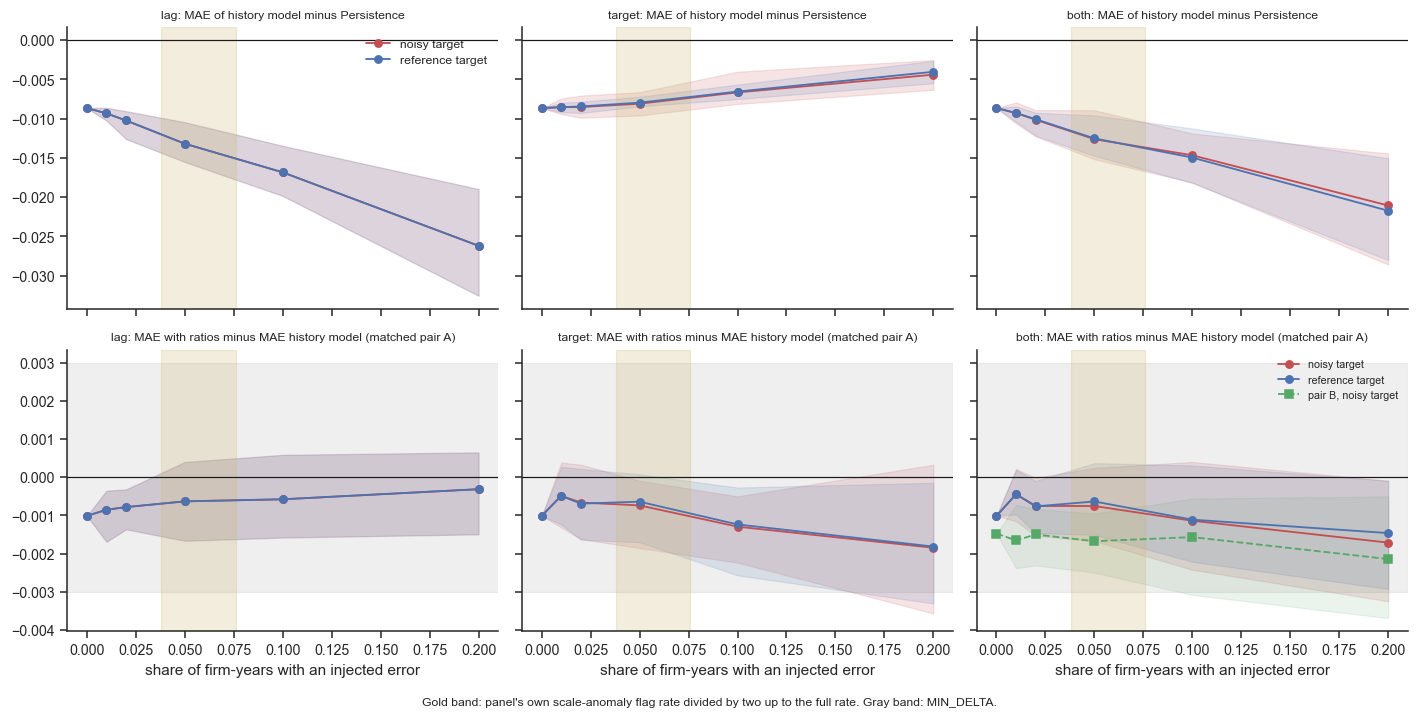

In [60]:
EI_DF2 = _flat(EI_RESULTS2)
def _with_modes(df):
    base = df[(df["share"] == 0) & (~df["filt"]) & (~df["retune"]) & (df["variant"] == "main")]
    return pd.concat([df] + [base.assign(mode=m) for m in ("lag", "target")], ignore_index=True)
_pa = _with_modes(EI_DF2[EI_DF2["pair"] == "A"])
EI_MAIN_A = _pa[(_pa["variant"] == "main") & (_pa["mix"] == "main") & (~_pa["filt"]) & (~_pa["retune"])]
_pb = EI_DF2[(EI_DF2["pair"] == "B") & (EI_DF2["variant"] == "main") & (~EI_DF2["retune"])]
EI_SUM_A = summarize(EI_MAIN_A, ["mode", "eval", "share"])
EI_SUM_B = summarize(_pb, ["eval", "share"])
print(f"Pair A ({EI_PAIRS['A'][0]} vs {EI_PAIRS['A'][1]}), main mix, observed panel plus noise; means over repetitions, 2.5 to 97.5 percent range, modal labels:")
display(EI_SUM_A.round(4))
print(f"Pair B ({EI_PAIRS['B'][0]} vs {EI_PAIRS['B'][1]}), mode both:")
display(EI_SUM_B.round(4))
EI_CHANGE_A = change_points(EI_SUM_A)
print("Change points, pair A:")
display(EI_CHANGE_A)

# Ratio contribution at each share: first run (unmatched) versus the two matched pairs, mode both, noisy target
_cmp = pd.DataFrame({
    "first run (unmatched models)": EI_SUM.loc[("both", "noisy")]["ratio_contrib"],
    "pair A": EI_SUM_A.loc[("both", "noisy")]["ratio_contrib"],
    "pair B": EI_SUM_B.loc["noisy"]["ratio_contrib"]}).reindex(EI_SHARES)
_lab = pd.DataFrame({"pair A label": EI_SUM_A.loc[("both", "noisy")]["lab_hc_hist"], "pair B label": EI_SUM_B.loc["noisy"]["lab_hc_hist"]}).reindex(EI_SHARES)
EI_PAIR_COMPARISON = _cmp.join(_lab)
print("MAE with ratios minus MAE history model, mode both, noisy target:")
display(EI_PAIR_COMPARISON.round(4))

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True, sharey="row")
xs = EI_SHARES
for j, mode in enumerate(EI_MODES):
    for row, (col, lo_c, hi_c, title) in enumerate((("gap_hist", "gap_hist_lo", "gap_hist_hi", "MAE of history model minus Persistence"),
                                                    ("ratio_contrib", "rc_lo", "rc_hi", "MAE with ratios minus MAE history model (matched pair A)"))):
        ax = axes[row, j]
        for ev, color in (("noisy", PALETTE["red"]), ("ref", PALETTE["blue"])):
            sub = EI_SUM_A.loc[(mode, ev)].reindex(xs)
            ax.plot(xs, sub[col], marker="o", color=color, label="noisy target" if ev == "noisy" else "reference target")
            ax.fill_between(xs, sub[lo_c], sub[hi_c], color=color, alpha=0.15)
        if row == 1 and mode == "both":
            sb = EI_SUM_B.loc["noisy"].reindex(xs)
            ax.plot(xs, sb["ratio_contrib"], marker="s", ls="--", color=PALETTE["green"], label="pair B, noisy target")
            ax.fill_between(xs, sb["rc_lo"], sb["rc_hi"], color=PALETTE["green"], alpha=0.12)
            ax.legend(frameon=False, fontsize=7)
        ax.axhline(0, color="k", lw=0.8)
        if row == 1:
            ax.axhspan(-MIN_DELTA["MAE"], MIN_DELTA["MAE"], color="gray", alpha=0.12)
        ax.axvspan(EI_REAL_FLAG_RATE / 2, EI_REAL_FLAG_RATE, color=PALETTE["gold"], alpha=0.25)
        ax.set_title(f"{mode}: {title}", fontsize=8)
        if row == 1:
            ax.set_xlabel("share of firm-years with an injected error")
axes[0, 0].legend(frameon=False, fontsize=8)
fig.text(0.5, 0.005, "Gold band: panel's own scale-anomaly flag rate divided by two up to the full rate. Gray band: MIN_DELTA.", ha="center", fontsize=8)
plt.tight_layout(rect=(0, 0.02, 1, 1)); plt.show()

for name_, t_ in (("error_injection_matched_summary_pair_A.csv", EI_SUM_A), ("error_injection_matched_summary_pair_B.csv", EI_SUM_B),
                  ("error_injection_matched_change_points_pair_A.csv", EI_CHANGE_A), ("error_injection_matched_comparison_with_first_run.csv", EI_PAIR_COMPARISON)):
    t_.to_csv(os.path.join(RESULTS_DIR, name_))

In [61]:
# Robustness of the matched-pair result (pair A, mode both)
_s = EI_DF2[(EI_DF2["pair"] == "A") & (EI_DF2["variant"] == "main") & (EI_DF2["mode"] == "both") & (~EI_DF2["filt"]) & (~EI_DF2["retune"]) & (EI_DF2["share"].isin([0.0] + EI_SENS_SHARES))]
EI_SENS2 = summarize(_s, ["mix", "eval", "share"])
print("Sensitivity to the error mix, including the joint scale variant (the 0% row belongs to the main mix only):")
display(EI_SENS2.round(4))

EI_REFVAR2 = summarize(EI_DF2[(EI_DF2["pair"] == "A") & (EI_DF2["variant"] == "ref") & (~EI_DF2["filt"]) & (~EI_DF2["retune"])], ["eval", "share"])
print("Reference panel variant (flagged firm-years set to missing), pair A:")
display(EI_REFVAR2.round(4))

_rt = EI_DF2[(EI_DF2["variant"] == "main") & (EI_DF2["mix"] == "main") & (EI_DF2["mode"] == "both") & (EI_DF2["share"] == EI_RETUNE_SHARE) & (~EI_DF2["filt"]) &
             (EI_DF2["seed"] < EI_SEED0 + EI_RETUNE_SEEDS)]
_rt = _rt.assign(tuning=np.where(_rt["retune"], "retuned on the corrupted panel", "cached hyperparameters"))
EI_RETUNE2 = _rt.groupby(["pair", "tuning", "eval"]).agg(reps=("seed", "nunique"), gap_hist=("gap_hist", "mean"), ratio_contrib=("ratio_contrib", "mean"),
                                                          lab_hist_pers=("lab_hist_pers", modal), lab_hc_hist=("lab_hc_hist", modal))
print(f"Retuning check at {100 * EI_RETUNE_SHARE:.0f}% (mode both):")
display(EI_RETUNE2.round(4))

# Filtering: share of the drift of the gain that dropping flagged firm-years removes
_fu = EI_DF2[(EI_DF2["pair"] == "A") & (EI_DF2["variant"] == "main") & (EI_DF2["mix"] == "main") & (EI_DF2["mode"] == "both") & (~EI_DF2["retune"]) &
             (EI_DF2["share"].isin([0.0] + EI_FILTER_SHARES)) & (EI_DF2["eval"] == "noisy")]
rows = []
for s in [0.0] + EI_FILTER_SHARES:
    u, f = _fu[(~_fu["filt"]) & (_fu["share"] == s)], _fu[(_fu["filt"]) & (_fu["share"] == s)]
    rows.append({"share": s, "gap unfiltered": u["gap_hist"].mean(), "gap filtered": f["gap_hist"].mean(),
                 "ratio contribution unfiltered": u["ratio_contrib"].mean(), "ratio contribution filtered": f["ratio_contrib"].mean(),
                 "test rows unfiltered": u["n"].mean(), "test rows filtered": f["n"].mean(),
                 "firm-years dropped (%)": 100 * np.mean([r["dropped_share_firm_years"] for r in EI_RESULTS2 if r["job"]["filt"] and r["job"]["share"] == s and r["job"]["pair"] == "A"])})
EI_FILTER2 = pd.DataFrame(rows).set_index("share")
_b = EI_FILTER2.loc[0.0]
EI_FILTER2["drift of gap, unfiltered"] = EI_FILTER2["gap unfiltered"] - _b["gap unfiltered"]
EI_FILTER2["drift of gap, filtered"] = EI_FILTER2["gap filtered"] - _b["gap filtered"]
EI_FILTER2["share of drift removed"] = 1 - EI_FILTER2["drift of gap, filtered"].abs() / EI_FILTER2["drift of gap, unfiltered"].abs().replace(0, np.nan)
EI_FILTER2["baseline gain removed by filtering (0% run)"] = 1 - _b["gap filtered"] / _b["gap unfiltered"]
print("Dropping firm-years flagged by the identity rule or the TA jump rule (mode both, noisy target). Drift is the change of the gain against the 0% run in the same setting:")
display(EI_FILTER2.round(4))

for name_, t_ in (("error_injection_matched_sensitivity_mix.csv", EI_SENS2), ("error_injection_matched_reference_variant.csv", EI_REFVAR2),
                  ("error_injection_matched_retune.csv", EI_RETUNE2), ("error_injection_matched_filtering_drift.csv", EI_FILTER2)):
    t_.to_csv(os.path.join(RESULTS_DIR, name_))

Sensitivity to the error mix, including the joint scale variant (the 0% row belongs to the main mix only):


reps  gap_hist  gap_hist_lo  gap_hist_hi  gap_hc  ratio_contrib   rc_lo   rc_hi lab_hist_pers        lab_hc_hist  share_hist_better  share_hc_equivalent
mix            eval  share                                                                                                                                                          
alternative    noisy 0.05     10   -0.0138      -0.0181      -0.0111 -0.0149        -0.0011 -0.0027  0.0001        better         equivalent                1.0                 0.70
                     0.10     10   -0.0178      -0.0215      -0.0142 -0.0193        -0.0015 -0.0025 -0.0001        better    slightly better                1.0                 0.30
                     0.20     10   -0.0264      -0.0313      -0.0234 -0.0279        -0.0016 -0.0037 -0.0002        better  indistinguishable                1.0                 0.30
               ref   0.05     10   -0.0136      -0.0176      -0.0106 -0.0147        -0.0011 -0.0027  0.0000        better         equivalent                1.0                 0.60
                     0.10     10   -0.0176      -0.0198      -0.0144 -0.0190        -0.0014 -0.0026  0.0000        better  indistinguishable                1.0                 0.30
                     0.20     10   -0.0270      -0.0319      -0.0234 -0.0282        -0.0012 -0.0038  0.0003        better         equivalent                1.0                 0.70
joint_scale    noisy 0.05     10   -0.0114      -0.0142      -0.0088 -0.0123        -0.0009 -0.0014 -0.0004        better         equivalent                1.0                 0.90
                     0.10     10   -0.0137      -0.0183      -0.0097 -0.0149        -0.0012 -0.0019 -0.0009        better  indistinguishable                1.0                 0.40
                     0.20     10   -0.0196      -0.0224      -0.0163 -0.0212        -0.0015 -0.0023 -0.0009        better  indistinguishable                1.0                 0.30
               ref   0.05     10   -0.0114      -0.0137      -0.0098 -0.0122        -0.0009 -0.0015 -0.0004        better         equivalent                1.0                 0.80
                     0.10     10   -0.0131      -0.0162      -0.0099 -0.0143        -0.0012 -0.0018 -0.0007        better         equivalent                1.0                 0.50
                     0.20     10   -0.0193      -0.0219      -0.0173 -0.0207        -0.0014 -0.0026 -0.0008        better  indistinguishable                1.0                 0.30
main           noisy 0.00      1   -0.0087      -0.0087      -0.0087 -0.0097        -0.0010 -0.0010 -0.0010        better         equivalent                1.0                 1.00
                     0.05     20   -0.0126      -0.0152      -0.0089 -0.0134        -0.0008 -0.0017  0.0002        better         equivalent                1.0                 0.85
                     0.10     20   -0.0147      -0.0181      -0.0119 -0.0158        -0.0011 -0.0024  0.0004        better         equivalent                1.0                 0.50
                     0.20     20   -0.0211      -0.0286      -0.0144 -0.0228        -0.0017 -0.0032 -0.0001        better    slightly better                1.0                 0.25
               ref   0.00      1   -0.0087      -0.0087      -0.0087 -0.0097        -0.0010 -0.0010 -0.0010        better         equivalent                1.0                 1.00
                     0.05     20   -0.0125      -0.0147      -0.0096 -0.0132        -0.0006 -0.0015  0.0004        better         equivalent                1.0                 0.80
                     0.10     20   -0.0150      -0.0182      -0.0113 -0.0161        -0.0011 -0.0022  0.0003        better         equivalent                1.0                 0.55
                     0.20     20   -0.0217      -0.0280      -0.0151 -0.0232        -0.0015 -0.0029 -0.0001        better  indistinguishable                1.0                 0.30
non_scale_only noisy 0.05     10   -0.0114    

Reference panel variant (flagged firm-years set to missing), pair A:


reps  gap_hist  gap_hist_lo  gap_hist_hi  gap_hc  ratio_contrib   rc_lo   rc_hi      lab_hist_pers      lab_hc_hist  share_hist_better  share_hc_equivalent
eval  share                                                                                                                                                             
noisy 0.00      1    0.0005       0.0005       0.0005 -0.0024        -0.0029 -0.0029 -0.0029  indistinguishable  slightly better                0.0                  0.0
      0.01     10    0.0002      -0.0015       0.0015 -0.0025        -0.0028 -0.0038 -0.0016  indistinguishable  slightly better                0.0                  0.0
      0.02     10   -0.0006      -0.0021       0.0018 -0.0034        -0.0028 -0.0044 -0.0018  indistinguishable  slightly better                0.0                  0.0
      0.05     10   -0.0030      -0.0064      -0.0008 -0.0061        -0.0031 -0.0044 -0.0018  indistinguishable           better                0.0                  0.0
      0.10     10   -0.0061      -0.0100      -0.0029 -0.0094        -0.0033 -0.0049 -0.0012  indistinguishable           better                0.2                  0.0
      0.20     10   -0.0132      -0.0219      -0.0058 -0.0173        -0.0041 -0.0064 -0.0029             better           better                0.6                  0.0
ref   0.00      1    0.0005       0.0005       0.0005 -0.0024        -0.0029 -0.0029 -0.0029  indistinguishable  slightly better                0.0                  0.0
      0.01     10    0.0005      -0.0007       0.0015 -0.0021        -0.0026 -0.0034 -0.0016  indistinguishable  slightly better                0.0                  0.0
      0.02     10   -0.0004      -0.0023       0.0018 -0.0032        -0.0028 -0.0043 -0.0017  indistinguishable  slightly better                0.0                  0.0
      0.05     10   -0.0031      -0.0061      -0.0008 -0.0063        -0.0032 -0.0042 -0.0018  indistinguishable           better                0.0                  0.0
      0.10     10   -0.0057      -0.0098      -0.0027 -0.0089        -0.0033 -0.0047 -0.0013  indistinguishable           better                0.2                  0.0
      0.20     10   -0.0121      -0.0183      -0.0047 -0.0162        -0.0041 -0.0064 -0.0027             better           better                0.7                  0.0

Retuning check at 5% (mode both):


reps  gap_hist  ratio_contrib lab_hist_pers        lab_hc_hist
pair tuning                         eval                                                                 
A    cached hyperparameters         noisy     3   -0.0127        -0.0006        better         equivalent
                                    ref       3   -0.0121        -0.0004        better         equivalent
     retuned on the corrupted panel noisy     3   -0.0133        -0.0001        better         equivalent
                                    ref       3   -0.0127         0.0000        better         equivalent
B    cached hyperparameters         noisy     3   -0.0144        -0.0015        better  indistinguishable
                                    ref       3   -0.0139        -0.0015        better  indistinguishable
     retuned on the corrupted panel noisy     3   -0.0144        -0.0015        better  indistinguishable
                                    ref       3   -0.0139        -0.0015        better  indistinguishable

Dropping firm-years flagged by the identity rule or the TA jump rule (mode both, noisy target). Drift is the change of the gain against the 0% run in the same setting:


,gap unfiltered,gap filtered,ratio contribution unfiltered,ratio contribution filtered,test rows unfiltered,test rows filtered,firm-years dropped (%),"drift of gap, unfiltered","drift of gap, filtered",share of drift removed,baseline gain removed by filtering (0% run)
share,,,,,,,,,,,
0.00,-0.0087,0.0005,-0.0010,-0.0029,1662.00,1033.0,33.9400,0.0000,0.0000,NaN,1.058
0.05,-0.0126,-0.0002,-0.0008,-0.0032,1627.70,923.2,37.5525,-0.0040,-0.0008,0.8107,1.058
0.10,-0.0147,-0.0005,-0.0011,-0.0028,1590.00,824.6,41.1030,-0.0060,-0.0010,0.8400,1.058
0.20,-0.0211,-0.0038,-0.0017,-0.0040,1523.95,644.8,47.8370,-0.0124,-0.0043,0.6568,1.058


## 24. Multicollinearity and Feature Redundancy

Ratio pairs with |Spearman| > 0.9 (training rows, pairwise complete): 9
  X4 <-> X46: 0.958
  X20 <-> X47: 0.955
  X28 <-> X54: 0.928
  X8 <-> X10: 0.928
  X53 <-> X54: 0.926
  X3 <-> X28: 0.924
  X4 <-> X50: 0.916
  X40 <-> X46: 0.911
  X3 <-> X4: 0.905


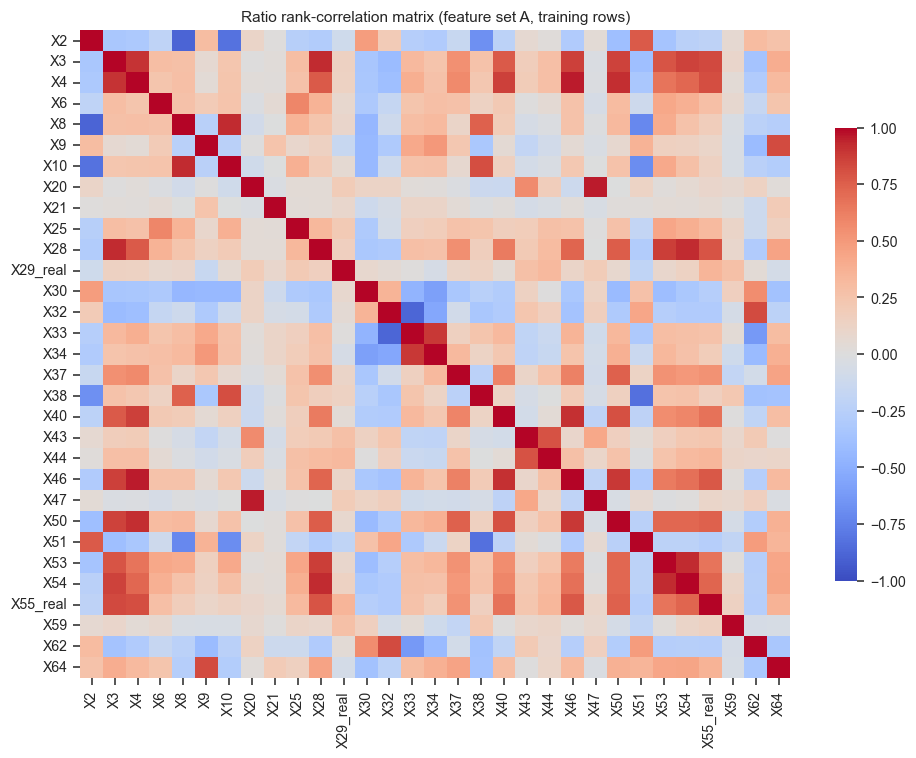

In [62]:
corr_signed = TRAIN_DF[RATIO_A].corr(method="spearman")
corr_matrix = corr_signed.abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
pairs = upper.stack()
high_corr = pairs[pairs > 0.9].sort_values(ascending=False)
print(f"Ratio pairs with |Spearman| > 0.9 (training rows, pairwise complete): {len(high_corr)}")
for (c1, c2), val in high_corr.items():
    print(f"  {c1} <-> {c2}: {val:.3f}")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_signed, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": 0.7})
ax.set_title("Ratio rank-correlation matrix (feature set A, training rows)")
plt.tight_layout(); plt.show()


## 25. Robustness Analysis

In [63]:
best_tmpl = TUNED[BEST_NAME].best_estimator_
ar_tmpl = build_benchmarks()["AR1"]

def _true(d):
    return pd.Series(True, index=d.index)

ROBUST_ARMS = {
    "Full sample": _true,
    "Row-level High confidence (t, t+1)": lambda d: (d["data_reliability_class"] == "High confidence") & (d["rel_class_t1"] == "High confidence"),
    "Clean extraction tier (t, t+1)": lambda d: d["extraction_tier"].isin(CLEAN_TIERS) & d["extraction_tier_t1"].isin(CLEAN_TIERS),
    "No scale-anomaly flag (t, t+1)": lambda d: (~d["ocr_anomaly_flag"].astype(bool)) & (~d["ocr_flag_t1"].astype(bool)),
    f"TA(t) and TA(t+1) >= {TA_FLOOR_SENSITIVITY:,} EUR": lambda d: (d["TA"] >= TA_FLOOR_SENSITIVITY) & (d["TA_t1"] >= TA_FLOOR_SENSITIVITY),
    "Lag observed (ROA_t not missing)": lambda d: d["ROA_t"].notna(),
}
if not FULLY_BALANCED:
    ROBUST_ARMS["Balanced firms only"] = lambda d: d["gemh_id"].isin(set(balanced_ids))
else:
    print("Balanced-panel arm not run: the panel is fully balanced, so it would be identical to the full sample.")

rob_rows = []
for label, fn in ROBUST_ARMS.items():
    tr_m = fn(TRVAL_DF).fillna(False).astype(bool).values
    te_m = fn(TEST_DF).fillna(False).astype(bool).values
    if tr_m.sum() < 200 or te_m.sum() < 50:
        rob_rows.append(dict(arm=label, n_train=int(tr_m.sum()), n_test=int(te_m.sum()), note="too few rows"))
        continue
    trd, ted = TRVAL_DF[tr_m], TEST_DF[te_m]
    y_s = ted[TARGET].values
    p_best = clone(best_tmpl).fit(trd[BEST_COLS], trd[TARGET]).predict(ted[BEST_COLS])
    p_ar = clone(ar_tmpl).fit(trd[["ROA_t"]], trd[TARGET]).predict(ted[["ROA_t"]])
    p_full = TEST_PRED[BEST_NAME][te_m]
    p_pers = ted["ROA_t"].fillna(trd["ROA_t"].median()).values
    d = paired_delta_ci(y_s, p_best, p_ar, ted["gemh_id"].values)
    d_p = paired_delta_ci(y_s, p_best, p_pers, ted["gemh_id"].values)
    rob_rows.append({
        "arm": label, "n_train": int(tr_m.sum()), "n_test": int(te_m.sum()),
        "share_of_test_%": round(100 * te_m.mean(), 1),
        "micro_%": round(100 * (ted["size_grp"] == "micro").mean(), 1), "large_%": round(100 * (ted["size_grp"] == "large").mean(), 1),
        f"RMSE {BEST_NAME}": rmse(y_s, p_best), f"MAE {BEST_NAME}": mae(y_s, p_best),
        "RMSE AR1": rmse(y_s, p_ar), "MAE AR1": mae(y_s, p_ar),
        "RMSE Persistence": rmse(y_s, p_pers), "MAE Persistence": mae(y_s, p_pers),
        "dRMSE vs AR1 [95% CI]": fmt_ci(d["RMSE"]), "dMAE vs AR1 [95% CI]": fmt_ci(d["MAE"]), "verdict vs AR1": verdict(d),
        "verdict vs Persistence": verdict(d_p),
        "RMSE (unrestricted model)": rmse(y_s, p_full), "MAE raw target": mae(ted[TARGET_RAW].values, p_best),
    })
robustness_table = pd.DataFrame(rob_rows).set_index("arm")
display(robustness_table.round(4))

full_row = robustness_table.loc["Full sample"]
assert abs(full_row[f"RMSE {BEST_NAME}"] - rmse(y_test, TEST_PRED[BEST_NAME])) < 1e-9, \
    "the full-sample arm must reproduce the main test predictions"

Balanced-panel arm not run: the panel is fully balanced, so it would be identical to the full sample.


,n_train,n_test,share_of_test_%,micro_%,large_%,RMSE XGB_Huber_C,MAE XGB_Huber_C,RMSE AR1,MAE AR1,RMSE Persistence,MAE Persistence,dRMSE vs AR1 [95% CI],dMAE vs AR1 [95% CI],verdict vs AR1,verdict vs Persistence,RMSE (unrestricted model),MAE raw target
arm,,,,,,,,,,,,,,,,,
Full sample,13012,1662,100.0,28.0,5.1,0.2134,0.1023,0.2262,0.1144,0.2520,0.1113,"-0.0127 [-0.0220, -0.0041]","-0.0120 [-0.0155, -0.0088]",better,better,0.2134,0.1607
"Row-level High confidence (t, t+1)",8751,1141,68.7,29.4,4.0,0.2051,0.0961,0.2135,0.1059,0.2198,0.0985,"-0.0084 [-0.0180, +0.0008]","-0.0098 [-0.0132, -0.0065]","mixed (RMSE: indistinguishable, MAE: better)",indistinguishable,0.2083,0.1563
"Clean extraction tier (t, t+1)",8286,1143,68.8,30.9,0.2,0.2024,0.0938,0.2073,0.1045,0.2169,0.0974,"-0.0048 [-0.0150, +0.0048]","-0.0108 [-0.0144, -0.0076]","mixed (RMSE: indistinguishable, MAE: better)",indistinguishable,0.2005,0.1523
"No scale-anomaly flag (t, t+1)",11397,1481,89.1,27.7,3.2,0.1897,0.0902,0.2026,0.1019,0.2247,0.0988,"-0.0129 [-0.0225, -0.0039]","-0.0116 [-0.0148, -0.0085]",better,better,0.1931,0.1304
"TA(t) and TA(t+1) >= 10,000 EUR",12216,1566,94.2,27.7,5.4,0.1876,0.0905,0.1999,0.1032,0.2280,0.0999,"-0.0123 [-0.0214, -0.0039]","-0.0127 [-0.0157, -0.0096]",better,better,0.1882,0.1233
Lag observed (ROA_t not missing),11969,1549,93.2,29.2,5.4,0.2067,0.0981,0.2196,0.1113,0.2480,0.1079,"-0.0130 [-0.0229, -0.0039]","-0.0132 [-0.0168, -0.0097]",better,better,0.2085,0.1550


### Does the model ranking depend on data quality?

In [64]:
from scipy.stats import kendalltau
rank_models = [n for n in ALL_NAMES if n != "Mean"]
rm_full = pd.Series({n: rmse(y_test, TEST_PRED[n]) for n in rank_models})
ma_full = pd.Series({n: mae(y_test, TEST_PRED[n]) for n in rank_models})
key_models = ["Persistence", "AR1", "AR1_LAD", "AR1_SECTOR", "ENS_R", "ENS_C"]
rs_rows = []
for label, fn in ROBUST_ARMS.items():
    te_m = fn(TEST_DF).fillna(False).astype(bool).values
    if te_m.sum() < 50:
        continue
    rm = pd.Series({n: rmse(y_test[te_m], TEST_PRED[n][te_m]) for n in rank_models})
    ma = pd.Series({n: mae(y_test[te_m], TEST_PRED[n][te_m]) for n in rank_models})
    row = {"arm": label, "n": int(te_m.sum()), "tau RMSE ranking vs full": kendalltau(rm_full, rm)[0],
           "tau MAE ranking vs full": kendalltau(ma_full, ma)[0], "best by RMSE": rm.idxmin(), "best by MAE": ma.idxmin()}
    for n in key_models:
        row[f"MAE {n}"] = ma[n]
    rs_rows.append(row)
rank_stability = pd.DataFrame(rs_rows).set_index("arm")
display(rank_stability.round(4))

,n,tau RMSE ranking vs full,tau MAE ranking vs full,best by RMSE,best by MAE,MAE Persistence,MAE AR1,MAE AR1_LAD,MAE AR1_SECTOR,MAE ENS_R,MAE ENS_C
arm,,,,,,,,,,,
Full sample,1662,1.0000,1.0000,XGB_L2_C5,XGB_Huber_C3,0.1113,0.1144,0.1103,0.1147,0.1077,0.1024
"Row-level High confidence (t, t+1)",1141,0.8473,0.8473,RF_C,XGB_Huber_C3,0.0985,0.1089,0.1022,0.1100,0.1021,0.0969
"Clean extraction tier (t, t+1)",1143,0.8276,0.9606,ENS_C5,XGB_Huber_C3,0.0974,0.1057,0.1002,0.1062,0.0993,0.0938
"No scale-anomaly flag (t, t+1)",1481,0.9261,0.9803,ENS_C5,XGB_Huber_C3,0.0988,0.1041,0.0994,0.1044,0.0972,0.0918
"TA(t) and TA(t+1) >= 10,000 EUR",1566,0.8966,0.9360,ENS_C5,XGB_Huber_C3,0.0999,0.1027,0.0987,0.1034,0.0954,0.0917
Lag observed (ROA_t not missing),1549,0.9557,0.9310,XGB_L2_C5,XGB_Huber_C3,0.1079,0.1113,0.1068,0.1121,0.1041,0.0993


In [65]:
def segment_table(col):
    rows = []
    for g in sorted(TEST_DF[col].dropna().astype(str).unique()):
        m = (TEST_DF[col].astype(str) == g).values
        if m.sum() == 0:
            continue
        sse_share = 100 * np.sum((y_test[m] - TEST_PRED[BEST_NAME][m]) ** 2) / np.sum((y_test - TEST_PRED[BEST_NAME]) ** 2)
        rows.append({col: g, "n": int(m.sum()), "share of rows (%)": 100 * m.mean(), "share of squared error (%)": sse_share,
                     f"RMSE {BEST_NAME}": rmse(y_test[m], TEST_PRED[BEST_NAME][m]), f"MAE {BEST_NAME}": mae(y_test[m], TEST_PRED[BEST_NAME][m]),
                     "RMSE AR1": rmse(y_test[m], TEST_PRED["AR1"][m]), "MAE AR1": mae(y_test[m], TEST_PRED["AR1"][m]),
                     "MAE Persistence": mae(y_test[m], TEST_PRED["Persistence"][m])})
    t = pd.DataFrame(rows).set_index(col)
    t["dMAE (best minus AR1)"] = t[f"MAE {BEST_NAME}"] - t["MAE AR1"]
    t["dMAE (best minus Persistence)"] = t[f"MAE {BEST_NAME}"] - t["MAE Persistence"]
    return t

SEGMENTS = {}
for col in ("size_grp", "extraction_tier", "data_reliability_class"):
    SEGMENTS[col] = segment_table(col)
    print(f"\nTest errors by {col} (segments with few rows are noisy):")
    display(SEGMENTS[col].round(4))


Test errors by size_grp (segments with few rows are noisy):


,n,share of rows (%),share of squared error (%),RMSE XGB_Huber_C,MAE XGB_Huber_C,RMSE AR1,MAE AR1,MAE Persistence,dMAE (best minus AR1),dMAE (best minus Persistence)
size_grp,,,,,,,,,,
large,84,5.0542,4.4544,0.2004,0.1005,0.2337,0.1118,0.1073,-0.0113,-0.0069
medium,134,8.0626,6.6430,0.1937,0.0902,0.2349,0.1124,0.1276,-0.0223,-0.0374
micro,465,27.9783,54.2477,0.2972,0.1611,0.3112,0.1764,0.1759,-0.0152,-0.0148
small,854,51.3839,25.1782,0.1494,0.0687,0.1505,0.0773,0.0698,-0.0085,-0.0011
unknown,125,7.5211,9.4768,0.2396,0.1276,0.2629,0.1410,0.1399,-0.0135,-0.0124



Test errors by extraction_tier (segments with few rows are noisy):


,n,share of rows (%),share of squared error (%),RMSE XGB_Huber_C,MAE XGB_Huber_C,RMSE AR1,MAE AR1,MAE Persistence,dMAE (best minus AR1),dMAE (best minus Persistence)
extraction_tier,,,,,,,,,,
gemini_vision,423,25.4513,27.0572,0.2201,0.1121,0.2451,0.1260,0.1347,-0.0139,-0.0226
pdfplumber,1239,74.5487,72.9428,0.2111,0.0990,0.2193,0.1104,0.1034,-0.0114,-0.0044



Test errors by data_reliability_class (segments with few rows are noisy):


,n,share of rows (%),share of squared error (%),RMSE XGB_Huber_C,MAE XGB_Huber_C,RMSE AR1,MAE AR1,MAE Persistence,dMAE (best minus AR1),dMAE (best minus Persistence)
data_reliability_class,,,,,,,,,,
High confidence,1250,75.2106,70.9797,0.2074,0.0974,0.2170,0.1089,0.1007,-0.0114,-0.0033
Low confidence,73,4.3923,4.2926,0.2110,0.0880,0.2192,0.0996,0.0836,-0.0115,0.0045
Moderate confidence,73,4.3923,4.6399,0.2194,0.1041,0.2299,0.1186,0.1101,-0.0145,-0.0060
Severe inconsistency,159,9.5668,10.4266,0.2228,0.1197,0.2705,0.1429,0.1852,-0.0233,-0.0655
Unknown,107,6.4380,9.6613,0.2615,0.1427,0.2585,0.1435,0.1459,-0.0008,-0.0033


## 26. Error Analysis and Model Diagnostics

Largest 10 absolute errors:


,gemh_id,year,size_grp,extraction_tier,data_reliability_class,ROA_t1,ROA_t1_raw,pred,abs_error,sq_error
674,138667303000,2024,micro,pdfplumber,High confidence,-1.342809,-5.405930,0.262591,1.605400,2.577309
615,136346007000,2024,micro,pdfplumber,High confidence,-1.342809,-6.202635,0.138253,1.481061,2.193543
405,125745401000,2024,small,pdfplumber,High confidence,-1.342809,-2.096430,0.098186,1.440994,2.076465
983,35846916000,2024,unknown,pdfplumber,Unknown,-1.342809,-5.063594,0.043015,1.385823,1.920506
1553,84223602000,2024,micro,pdfplumber,High confidence,-1.342809,-10.252364,-0.012544,1.330265,1.769605
577,134188813000,2024,micro,pdfplumber,High confidence,-1.342809,-1.795879,-0.020412,1.322396,1.748732
445,127720116000,2024,large,gemini_vision,Moderate confidence,-1.342809,-5.771740,-0.029703,1.313106,1.724247
697,139541901000,2024,micro,gemini_vision,High confidence,-1.342809,-5.491634,-0.045232,1.297576,1.683705
754,140990101000,2024,medium,gemini_vision,High confidence,-1.342809,-2.145797,-0.105115,1.237694,1.531887
727,140374901000,2024,micro,pdfplumber,High confidence,-1.342809,-15.117654,-0.157657,1.185151,1.404584



Share of total squared error from the 10 largest errors: 24.6%  |  from the largest 1% (17 rows): 36.0%
Test rows whose raw target lies beyond the winsorisation bounds: 41 (2.47%), carrying 45.8% of squared error


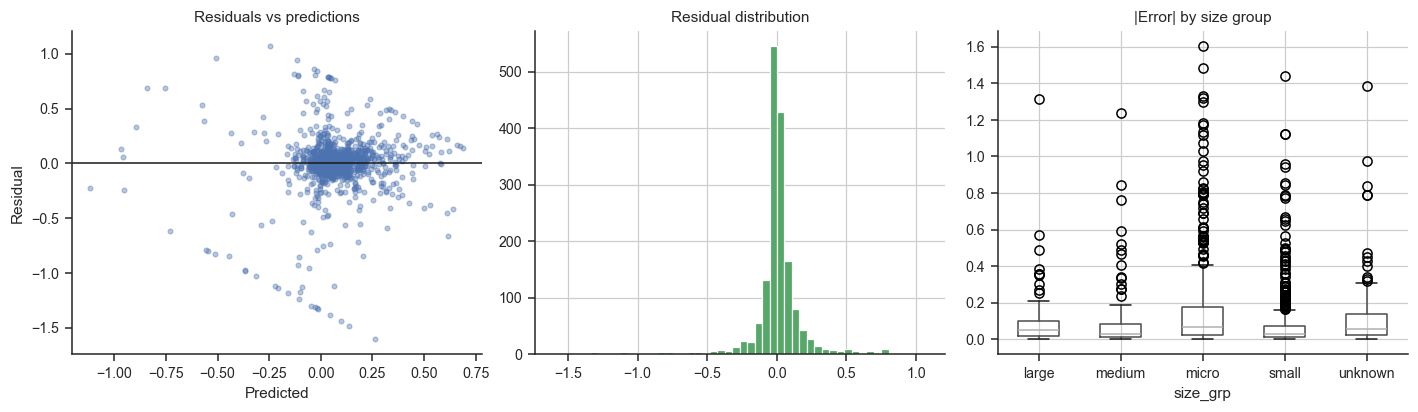

Levene test for equal error variance across size groups: stat = 16.059, p = 0.0000; effect size: mean |error| from 0.0687 (small) to 0.1611 (micro), ratio 2.34


In [66]:
err_df = TEST_DF[["gemh_id", "year", "size_grp", "extraction_tier", "data_reliability_class", TARGET, TARGET_RAW]].copy()
err_df["pred"] = TEST_PRED[BEST_NAME]
err_df["abs_error"] = (err_df[TARGET] - err_df["pred"]).abs()
err_df["sq_error"] = err_df["abs_error"] ** 2

print("Largest 10 absolute errors:")
display(err_df.sort_values("abs_error", ascending=False).head(10))

sse = err_df["sq_error"].sum()
k1 = max(1, int(round(0.01 * len(err_df))))
top10 = err_df["sq_error"].nlargest(10).sum() / sse
top1pct = err_df["sq_error"].nlargest(k1).sum() / sse
print(f"\nShare of total squared error from the 10 largest errors: {100*top10:.1f}%  |  from the largest 1% ({k1} rows): {100*top1pct:.1f}%")
at_bound_test = (err_df[TARGET_RAW] <= ROA_LO) | (err_df[TARGET_RAW] >= ROA_HI)
print(f"Test rows whose raw target lies beyond the winsorisation bounds: {int(at_bound_test.sum())} ({100*at_bound_test.mean():.2f}%), "
      f"carrying {100*err_df.loc[at_bound_test, 'sq_error'].sum()/sse:.1f}% of squared error")

residuals = err_df[TARGET] - err_df["pred"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].scatter(err_df["pred"], residuals, s=10, alpha=0.4, color=PALETTE["blue"])
axes[0].axhline(0, color="k", lw=1); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Residual"); axes[0].set_title("Residuals vs predictions")
residuals.hist(bins=50, ax=axes[1], color=PALETTE["green"]); axes[1].set_title("Residual distribution")
err_df.boxplot(column="abs_error", by="size_grp", ax=axes[2]); axes[2].set_title("|Error| by size group"); plt.suptitle("")
plt.tight_layout(); plt.show()

lev_groups = [g["abs_error"].values for _, g in err_df.groupby("size_grp") if len(g) >= 5]
if len(lev_groups) > 1:
    stat, p = levene(*lev_groups)
    mae_grp = err_df.groupby("size_grp")["abs_error"].mean()
    print(f"Levene test for equal error variance across size groups: stat = {stat:.3f}, p = {p:.4f}; effect size: mean |error| from "
          f"{mae_grp.min():.4f} ({mae_grp.idxmin()}) to {mae_grp.max():.4f} ({mae_grp.idxmax()}), ratio {mae_grp.max() / mae_grp.min():.2f}")

In [67]:
# Mapping of features to economic constructs (categories of the feature dictionary), shared by the SHAP summaries
cat_map = dict(zip(FEATURE_DICTIONARY["Variable"], FEATURE_DICTIONARY["Category"]))
cat_map.update({"X29_real": "Size", "X55_real": "Liquidity", "ROA_t": "Lagged ROA", "firm_age": "Firm characteristics",
                "isBranch": "Firm characteristics",
                # retained earnings over assets is a stock of all past profits, so it is a profit-history construct, not leverage;
                # asset turnover is an efficiency ratio
                "X6": "Accumulated earnings", "X25": "Accumulated earnings", "X9": "Efficiency",
                "ROA_lag1": "ROA history", "ROA_lag2": "ROA history", "ROA_mean3": "ROA history", "ROA_min3": "ROA history",
                "ROA_lag3": "ROA history", "ROA_lag4": "ROA history", "ROA_mean5": "ROA history", "ROA_min5": "ROA history", "ROA_std5": "ROA history"})
def construct_of(f):
    if f in cat_map:
        return cat_map[f]
    if f.startswith(("legalType_", "region_group_", "size_category_", "sector_")):
        return "Firm characteristics"
    return "Other"

## 26b. Loss Prediction (Sign of Next-Year ROA)

Loss share (ROA(t+1) < 0.0): train 0.341, test 0.273
XGB_R: temporal-CV log loss = 0.5162
XGB_C: temporal-CV log loss = 0.4842
XGB_R3: temporal-CV log loss = 0.4861
XGB_C3: temporal-CV log loss = 0.4722
XGB_R5: temporal-CV log loss = 0.4845
XGB_C5: temporal-CV log loss = 0.4729

LOSS PREDICTION, test year (n = 1,662, loss share 0.273):


,AUC,PR-AUC,captured in top 10% (%),precision in top 10% (%),Brier,log loss,accuracy@0.5
model,,,,,,,
Rule: loss if ROA_t < 0,0.8161,0.6250,26.0486,70.6587,NaN,NaN,0.8303
Logit_ROA,0.8161,0.6250,26.0486,70.6587,0.1685,0.5222,0.7551
Logit_SPLINE,0.8143,0.6349,26.0486,70.6587,0.1402,0.4445,0.8291
Logit_C,0.8008,0.6202,28.0353,76.0479,0.1559,0.4882,0.7810
XGB_R,0.8203,0.6310,26.9316,73.0539,0.1347,0.4323,0.8303
XGB_C,0.8638,0.7425,31.7881,86.2275,0.1229,0.3947,0.8357
XGB_R3,0.8665,0.7168,29.5806,80.2395,0.1234,0.3971,0.8315
XGB_C3,0.8772,0.7474,30.9051,83.8323,0.1189,0.3841,0.8448
XGB_R5,0.8713,0.7232,30.0221,81.4371,0.1222,0.3911,0.8339


,dAUC [95% CI],verdict (AUC),dPR-AUC [95% CI],"dTop-10% capture, pp [95% CI]",dBrier [95% CI] (negative = first better)
comparison,,,,,
C family vs R family,"+0.0539 [+0.0395, +0.0674]",better,"+0.1325 [+0.0954, +0.1656]","+6.8 [+4.0, +9.2]","-0.0147 [-0.0188, -0.0104]"
C family vs spline logit,"+0.0518 [+0.0365, +0.0668]",better,"+0.1082 [+0.0709, +0.1449]","+6.2 [+3.5, +8.8]","-0.0177 [-0.0222, -0.0129]"
R family vs spline logit,"-0.0021 [-0.0128, +0.0084]",indistinguishable,"-0.0243 [-0.0595, +0.0107]","-0.7 [-3.0, +1.8]","-0.0030 [-0.0063, +0.0001]"
XGB_C vs XGB_R,"+0.0435 [+0.0296, +0.0567]",better,"+0.1116 [+0.0785, +0.1464]","+4.9 [+2.3, +7.6]","-0.0118 [-0.0157, -0.0074]"
RF_C vs RF_R,"+0.0596 [+0.0444, +0.0745]",better,"+0.1388 [+0.1025, +0.1723]","+6.6 [+3.7, +9.1]","-0.0193 [-0.0239, -0.0147]"
C family vs linear logit,"+0.0500 [+0.0361, +0.0650]",better,"+0.1181 [+0.0776, +0.1562]","+6.2 [+3.5, +8.8]","-0.0460 [-0.0529, -0.0393]"
C3 family vs R3 family (ratios beyond the profit history),"+0.0094 [+0.0033, +0.0150]",slightly better,"+0.0338 [+0.0162, +0.0521]","+0.9 [-0.2, +3.2]","-0.0047 [-0.0072, -0.0022]"
R3 family vs R family (history alone),"+0.0560 [+0.0409, +0.0720]",better,"+0.1032 [+0.0623, +0.1379]","+4.4 [+1.4, +7.1]","-0.0141 [-0.0185, -0.0096]"
C3 family vs C family,"+0.0115 [+0.0024, +0.0208]",better,"+0.0045 [-0.0081, +0.0164]","-1.5 [-2.6, +0.2]","-0.0042 [-0.0071, -0.0014]"


Loss framing, descriptive test year: lag LOSS_INCREMENTAL; 3-year history LOSS_SMALL_RATIO_CONTRIBUTION_BEYOND_HISTORY; 5-year history LOSS_SMALL_RATIO_CONTRIBUTION_BEYOND_HISTORY
Loss framing on the test year: LOSS_INCREMENTAL


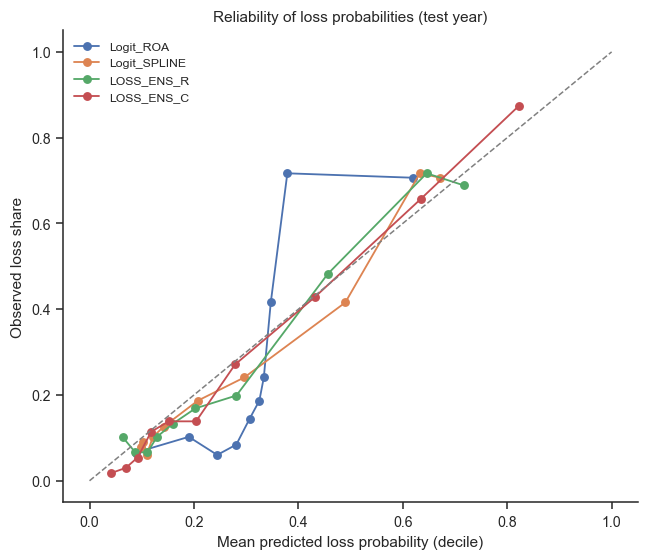

In [68]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss, average_precision_score
from sklearn.preprocessing import SplineTransformer
from xgboost import XGBClassifier

def loss_label(df, thr=LOSS_THRESHOLD):
    return (df[TARGET_RAW] < thr).astype(int).values

def top_capture(y, s, q=0.10):
    # Share of all losses that fall in the top q of predicted risk
    y, s = np.asarray(y), np.asarray(s, float)
    k = max(1, int(np.ceil(q * len(y))))
    return float(y[np.argsort(-s, kind="stable")[:k]].sum() / max(y.sum(), 1))

def top_precision(y, s, q=0.10):
    y, s = np.asarray(y), np.asarray(s, float)
    k = max(1, int(np.ceil(q * len(y))))
    return float(y[np.argsort(-s, kind="stable")[:k]].mean())

yl_train, yl_trval, yl_test = loss_label(TRAIN_DF), loss_label(TRVAL_DF), loss_label(TEST_DF)
print(f"Loss share (ROA(t+1) < {LOSS_THRESHOLD}): train {yl_train.mean():.3f}, test {yl_test.mean():.3f}")

def build_logit_roa():
    return Pipeline([("sel", ColumnTransformer([("roa", "passthrough", ["ROA_t"])])), ("imp", make_imputer()),
                     ("m", LogisticRegression(C=1e6, max_iter=2000))])

def build_logit_spline():
    return Pipeline([("sel", ColumnTransformer([("roa", "passthrough", ["ROA_t"])])), ("imp", make_imputer()),
                     ("spl", SplineTransformer(n_knots=7, degree=3, knots="quantile")),
                     ("m", LogisticRegression(C=1.0, max_iter=3000))])

def build_logit_ridge():
    return Pipeline([("clip", QuantileClipper(*WINSOR_Q)), ("imp", make_imputer()), ("sc", StandardScaler()),
                     ("m", LogisticRegression(C=0.05, max_iter=3000))])

def build_xgb_clf():
    return Pipeline([("model", XGBClassifier(tree_method="hist", n_jobs=1, random_state=RANDOM_STATE, verbosity=0, eval_metric="logloss"))])

def build_rf_clf():
    return Pipeline([("imp", make_imputer()),
                     ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features=0.33,
                                                      random_state=RANDOM_STATE, n_jobs=1))])

def fit_loss_search(fs):
    s = RandomizedSearchCV(build_xgb_clf(), XGB_SPACE, n_iter=15, cv=CV_FOLDS, scoring="neg_log_loss", n_jobs=N_JOBS,
                           random_state=RANDOM_STATE, refit=True, error_score="raise")
    s.fit(TRAIN_DF[FEATURE_SETS[fs]], yl_train)
    return types.SimpleNamespace(best_estimator_=s.best_estimator_, best_score_=s.best_score_)

LOSS_XGB = {}
for name, fs in (("XGB_R", "R"), ("XGB_C", "C"), ("XGB_R3", "R3"), ("XGB_C3", "C3"), ("XGB_R5", "R5"), ("XGB_C5", "C5")):
    res = cached(f"loss_xgb_{name}", (CACHE_SIG, "loss_xgb", name, fs, 15), lambda: fit_loss_search(fs))
    LOSS_XGB[name] = (res.best_estimator_, FEATURE_SETS[fs])
    print(f"{name}: temporal-CV log loss = {-res.best_score_:.4f}")

loss_specs = {"Logit_ROA": (build_logit_roa(), ["ROA_t"]), "Logit_SPLINE": (build_logit_spline(), ["ROA_t"]),
              "Logit_C": (build_logit_ridge(), FEATURE_SETS["C"]),
              "XGB_R": LOSS_XGB["XGB_R"], "XGB_C": LOSS_XGB["XGB_C"],
              "XGB_R3": LOSS_XGB["XGB_R3"], "XGB_C3": LOSS_XGB["XGB_C3"], "XGB_R5": LOSS_XGB["XGB_R5"], "XGB_C5": LOSS_XGB["XGB_C5"],
              "RF_R": (build_rf_clf(), ["ROA_t"]), "RF_C": (build_rf_clf(), FEATURE_SETS["C"]),
              "RF_R3": (build_rf_clf(), FEATURE_SETS["R3"]), "RF_C3": (build_rf_clf(), FEATURE_SETS["C3"]),
              "RF_R5": (build_rf_clf(), FEATURE_SETS["R5"]), "RF_C5": (build_rf_clf(), FEATURE_SETS["C5"])}
LOSS_PRED, LOSS_FITTED = {}, {}
for name, (est, cols) in loss_specs.items():
    m = clone(est).fit(TRVAL_DF[cols], yl_trval)
    LOSS_FITTED[name] = m
    LOSS_PRED[name] = m.predict_proba(TEST_DF[cols])[:, 1]
LOSS_PRED["LOSS_ENS_C"] = np.mean([LOSS_PRED["XGB_C"], LOSS_PRED["RF_C"]], axis=0)
LOSS_PRED["LOSS_ENS_R"] = np.mean([LOSS_PRED["XGB_R"], LOSS_PRED["RF_R"]], axis=0)
LOSS_PRED["LOSS_ENS_C3"] = np.mean([LOSS_PRED["XGB_C3"], LOSS_PRED["RF_C3"]], axis=0)
LOSS_PRED["LOSS_ENS_R3"] = np.mean([LOSS_PRED["XGB_R3"], LOSS_PRED["RF_R3"]], axis=0)
LOSS_PRED["LOSS_ENS_C5"] = np.mean([LOSS_PRED["XGB_C5"], LOSS_PRED["RF_C5"]], axis=0)
LOSS_PRED["LOSS_ENS_R5"] = np.mean([LOSS_PRED["XGB_R5"], LOSS_PRED["RF_R5"]], axis=0)
roa_fill = float(np.nanmedian(TRVAL_DF["ROA_t"]))
rule_score = -np.where(TEST_DF["ROA_t"].isna(), roa_fill, TEST_DF["ROA_t"]).astype(float)

loss_rows = [{"model": "Rule: loss if ROA_t < 0", "AUC": roc_auc_score(yl_test, rule_score), "PR-AUC": average_precision_score(yl_test, rule_score),
              "captured in top 10% (%)": 100 * top_capture(yl_test, rule_score), "precision in top 10% (%)": 100 * top_precision(yl_test, rule_score),
              "Brier": np.nan, "log loss": np.nan, "accuracy@0.5": float(np.mean((rule_score > 0).astype(int) == yl_test))}]
for name, pr in LOSS_PRED.items():
    loss_rows.append({"model": name, "AUC": roc_auc_score(yl_test, pr), "PR-AUC": average_precision_score(yl_test, pr),
                      "captured in top 10% (%)": 100 * top_capture(yl_test, pr), "precision in top 10% (%)": 100 * top_precision(yl_test, pr),
                      "Brier": brier_score_loss(yl_test, pr),
                      "log loss": log_loss(yl_test, np.clip(pr, 1e-6, 1 - 1e-6)), "accuracy@0.5": float(np.mean((pr > 0.5).astype(int) == yl_test))})
base_rate = float(yl_trval.mean())
loss_rows.append({"model": "Base rate (training share)", "AUC": 0.5, "PR-AUC": float(yl_test.mean()), "captured in top 10% (%)": 10.0,
                  "precision in top 10% (%)": 100 * float(yl_test.mean()),
                  "Brier": brier_score_loss(yl_test, np.full(len(yl_test), base_rate)),
                  "log loss": log_loss(yl_test, np.full(len(yl_test), base_rate)), "accuracy@0.5": float(np.mean((base_rate > 0.5) == yl_test))})
loss_table = pd.DataFrame(loss_rows).set_index("model")
print(f"\nLOSS PREDICTION, test year (n = {len(yl_test):,}, loss share {yl_test.mean():.3f}):")
display(loss_table.round(4))

def paired_auc_delta(y, s1, s2, n_boot=1000, seed=RANDOM_STATE):
    # One row per firm, so resampling rows is resampling firms.
    y, s1, s2 = np.asarray(y), np.asarray(s1, float), np.asarray(s2, float)
    base = roc_auc_score(y, s1) - roc_auc_score(y, s2)
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        b = rng.integers(0, len(y), len(y))
        if y[b].min() == y[b].max():
            continue
        diffs.append(roc_auc_score(y[b], s1[b]) - roc_auc_score(y[b], s2[b]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return float(base), float(lo), float(hi)

def paired_metric_delta(y, s1, s2, fn, n_boot=1000, seed=RANDOM_STATE):
    y, s1, s2 = np.asarray(y), np.asarray(s1, float), np.asarray(s2, float)
    base = fn(y, s1) - fn(y, s2)
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        b = rng.integers(0, len(y), len(y))
        if y[b].min() == y[b].max():
            continue
        diffs.append(fn(y[b], s1[b]) - fn(y[b], s2[b]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return float(base), float(lo), float(hi)

def paired_brier_delta(y, p1, p2, n_boot=1000, seed=RANDOM_STATE):
    d = (np.asarray(y, float) - np.asarray(p1, float)) ** 2 - (np.asarray(y, float) - np.asarray(p2, float)) ** 2
    idx = np.random.default_rng(seed).integers(0, len(d), size=(n_boot, len(d)))
    boots = d[idx].mean(axis=1)
    return float(d.mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))

def cluster_auc_delta(y, s1, s2, groups, n_boot=500, seed=RANDOM_STATE):
    # Firms are resampled as clusters (the same firm appears in several nested years).
    y, s1, s2 = np.asarray(y), np.asarray(s1, float), np.asarray(s2, float)
    g = pd.factorize(pd.Series(np.asarray(groups)).astype(str))[0]
    order = np.argsort(g, kind="stable")
    bounds = np.searchsorted(g[order], np.arange(g.max() + 2))
    by_firm = [order[bounds[i]:bounds[i + 1]] for i in range(g.max() + 1)]
    base = roc_auc_score(y, s1) - roc_auc_score(y, s2)
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(by_firm), len(by_firm))
        idx = np.concatenate([by_firm[k] for k in pick])
        if y[idx].min() == y[idx].max():
            continue
        diffs.append(roc_auc_score(y[idx], s1[idx]) - roc_auc_score(y[idx], s2[idx]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return float(base), float(lo), float(hi)

def auc_label(pt, lo, hi):
    if lo > 0 and pt >= MIN_DELTA_AUC: return "better"
    if hi < 0 and pt <= -MIN_DELTA_AUC: return "worse"
    if lo > 0: return "slightly better"
    if hi < 0: return "slightly worse"
    return "indistinguishable"

def loss_framing(d_c_r, d_c_s):
    l_r, l_s = auc_label(*d_c_r), auc_label(*d_c_s)
    if l_r == "better" and l_s == "better":
        return "LOSS_INCREMENTAL"
    if l_r in ("better", "slightly better"):
        return "LOSS_SMALL_INCREMENTAL"
    return "LOSS_NO_INCREMENTAL"

def loss_framing_history(d_c_r, d_c_s):
    key = loss_framing(d_c_r, d_c_s)
    return {"LOSS_INCREMENTAL": "LOSS_RATIOS_ADD_BEYOND_HISTORY", "LOSS_SMALL_INCREMENTAL": "LOSS_SMALL_RATIO_CONTRIBUTION_BEYOND_HISTORY",
            "LOSS_NO_INCREMENTAL": "LOSS_HISTORY_EXPLAINS_GAIN"}[key]

scores = dict(LOSS_PRED)
LOSS_COMPARISONS = [("C family vs R family", "LOSS_ENS_C", "LOSS_ENS_R"),
                    ("C family vs spline logit", "LOSS_ENS_C", "Logit_SPLINE"),
                    ("R family vs spline logit", "LOSS_ENS_R", "Logit_SPLINE"),
                    ("XGB_C vs XGB_R", "XGB_C", "XGB_R"), ("RF_C vs RF_R", "RF_C", "RF_R"),
                    ("C family vs linear logit", "LOSS_ENS_C", "Logit_ROA"),
                    ("C3 family vs R3 family (ratios beyond the profit history)", "LOSS_ENS_C3", "LOSS_ENS_R3"),
                    ("R3 family vs R family (history alone)", "LOSS_ENS_R3", "LOSS_ENS_R"),
                    ("C3 family vs C family", "LOSS_ENS_C3", "LOSS_ENS_C"),
                    ("C family vs R3 family", "LOSS_ENS_C", "LOSS_ENS_R3"),
                    ("C5 family vs R5 family (ratios beyond the 5-year history)", "LOSS_ENS_C5", "LOSS_ENS_R5"),
                    ("R5 family vs R3 family (longer history)", "LOSS_ENS_R5", "LOSS_ENS_R3")]
lc_rows, LOSS_DELTAS, LOSS_VERDICT = [], {}, {}
for label, a, b in LOSS_COMPARISONS:
    d_auc = paired_auc_delta(yl_test, scores[a], scores[b])
    d_br = paired_brier_delta(yl_test, scores[a], scores[b])
    d_pr = paired_metric_delta(yl_test, scores[a], scores[b], average_precision_score)
    d_cap = paired_metric_delta(yl_test, scores[a], scores[b], lambda y, s: 100 * top_capture(y, s))
    LOSS_DELTAS[label], LOSS_VERDICT[label] = d_auc, auc_label(*d_auc)
    lc_rows.append({"comparison": label, "dAUC [95% CI]": f"{d_auc[0]:+.4f} [{d_auc[1]:+.4f}, {d_auc[2]:+.4f}]", "verdict (AUC)": LOSS_VERDICT[label],
                    "dPR-AUC [95% CI]": f"{d_pr[0]:+.4f} [{d_pr[1]:+.4f}, {d_pr[2]:+.4f}]",
                    "dTop-10% capture, pp [95% CI]": f"{d_cap[0]:+.1f} [{d_cap[1]:+.1f}, {d_cap[2]:+.1f}]",
                    "dBrier [95% CI] (negative = first better)": f"{d_br[0]:+.4f} [{d_br[1]:+.4f}, {d_br[2]:+.4f}]"})
loss_cmp = pd.DataFrame(lc_rows).set_index("comparison")
display(loss_cmp)
LOSS_FRAMING_TEST = loss_framing(LOSS_DELTAS["C family vs R family"], LOSS_DELTAS["C family vs spline logit"])
LOSS_HIST_FRAMING_TEST = loss_framing_history(LOSS_DELTAS["C3 family vs R3 family (ratios beyond the profit history)"], LOSS_DELTAS["C family vs spline logit"])
LOSS_H5_FRAMING_TEST = loss_framing_history(LOSS_DELTAS["C5 family vs R5 family (ratios beyond the 5-year history)"], LOSS_DELTAS["C family vs spline logit"])
print(f"Loss framing, descriptive test year: lag {LOSS_FRAMING_TEST}; 3-year history {LOSS_HIST_FRAMING_TEST}; 5-year history {LOSS_H5_FRAMING_TEST}")
print(f"Loss framing on the test year: {LOSS_FRAMING_TEST}")

fig, ax = plt.subplots(figsize=(6, 5.2))
for name in ("Logit_ROA", "Logit_SPLINE", "LOSS_ENS_R", "LOSS_ENS_C"):
    bins = pd.qcut(pd.Series(LOSS_PRED[name]).rank(method="first"), 10, labels=False)
    g = pd.DataFrame({"pred": LOSS_PRED[name], "obs": yl_test, "bin": bins}).groupby("bin").mean()
    ax.plot(g["pred"], g["obs"], marker="o", label=name)
ax.plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
ax.set_xlabel("Mean predicted loss probability (decile)"); ax.set_ylabel("Observed loss share")
ax.set_title("Reliability of loss probabilities (test year)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

In [69]:
# Threshold sensitivity: a "loss" of any size versus a material loss (refit with the tuned XGBoost settings)
thr_rows, THR_VERDICT, THR_HIST_VERDICT, THR_H5_VERDICT = [], {}, {}, {}
for thr in LOSS_THRESHOLDS:
    ytr_t, yte_t = loss_label(TRVAL_DF, thr), loss_label(TEST_DF, thr)
    if yte_t.min() == yte_t.max() or ytr_t.min() == ytr_t.max():
        continue
    pr = {n: clone(LOSS_XGB[n][0]).fit(TRVAL_DF[LOSS_XGB[n][1]], ytr_t).predict_proba(TEST_DF[LOSS_XGB[n][1]])[:, 1] for n in ("XGB_R", "XGB_C", "XGB_R3", "XGB_C3", "XGB_R5", "XGB_C5")}
    spl = clone(loss_specs["Logit_SPLINE"][0]).fit(TRVAL_DF[["ROA_t"]], ytr_t).predict_proba(TEST_DF[["ROA_t"]])[:, 1]
    d_cr = paired_auc_delta(yte_t, pr["XGB_C"], pr["XGB_R"])
    THR_VERDICT[thr] = auc_label(*d_cr)
    d_h = paired_auc_delta(yte_t, pr["XGB_C3"], pr["XGB_R3"])
    THR_HIST_VERDICT[thr] = auc_label(*d_h)
    d_h5 = paired_auc_delta(yte_t, pr["XGB_C5"], pr["XGB_R5"])
    THR_H5_VERDICT[thr] = auc_label(*d_h5)
    thr_rows.append({"loss threshold": thr, "loss share": float(yte_t.mean()), "AUC spline logit": roc_auc_score(yte_t, spl),
                     "AUC XGB_R": roc_auc_score(yte_t, pr["XGB_R"]), "AUC XGB_C": roc_auc_score(yte_t, pr["XGB_C"]),
                     "dAUC C vs R [95% CI]": f"{d_cr[0]:+.4f} [{d_cr[1]:+.4f}, {d_cr[2]:+.4f}]", "verdict": THR_VERDICT[thr],
                     "AUC XGB_R3": roc_auc_score(yte_t, pr["XGB_R3"]), "AUC XGB_C3": roc_auc_score(yte_t, pr["XGB_C3"]),
                     "dAUC C3 vs R3 [95% CI]": f"{d_h[0]:+.4f} [{d_h[1]:+.4f}, {d_h[2]:+.4f}]", "verdict C3 vs R3": THR_HIST_VERDICT[thr],
                     "dAUC C5 vs R5 [95% CI]": f"{d_h5[0]:+.4f} [{d_h5[1]:+.4f}, {d_h5[2]:+.4f}]", "verdict C5 vs R5": THR_H5_VERDICT[thr]})
thr_table = pd.DataFrame(thr_rows).set_index("loss threshold")
print("Threshold sensitivity (test year, XGBoost with the tuned settings):")
display(thr_table.round(4))

# Noise-restricted samples: the same predictions scored on rows of each quality arm (no refit)
lag_obs_l = TEST_DF["ROA_t"].notna().values
lag_clean_l = ((TEST_DF["data_reliability_class"] == "High confidence") & (~TEST_DF["ocr_anomaly_flag"].astype(bool))).values
arm_masks = {label: fn(TEST_DF).fillna(False).astype(bool).values for label, fn in ROBUST_ARMS.items()}
arm_masks["Lag clean (row t)"] = lag_obs_l & lag_clean_l
arm_masks["Lag noisy (row t)"] = lag_obs_l & ~lag_clean_l
arm_rows, ARM_VERDICT, ARM_HIST_VERDICT, ARM_H5_VERDICT = [], {}, {}, {}
for label, m in arm_masks.items():
    ys = yl_test[m]
    if m.sum() < 150 or ys.min() == ys.max():
        continue
    d_cr = paired_auc_delta(ys, LOSS_PRED["LOSS_ENS_C"][m], LOSS_PRED["LOSS_ENS_R"][m])
    d_cs = paired_auc_delta(ys, LOSS_PRED["LOSS_ENS_C"][m], LOSS_PRED["Logit_SPLINE"][m])
    ARM_VERDICT[label] = auc_label(*d_cr)
    d_h = paired_auc_delta(ys, LOSS_PRED["LOSS_ENS_C3"][m], LOSS_PRED["LOSS_ENS_R3"][m])
    ARM_HIST_VERDICT[label] = auc_label(*d_h)
    d_h5 = paired_auc_delta(ys, LOSS_PRED["LOSS_ENS_C5"][m], LOSS_PRED["LOSS_ENS_R5"][m])
    ARM_H5_VERDICT[label] = auc_label(*d_h5)
    arm_rows.append({"arm": label, "n": int(m.sum()), "loss share": float(ys.mean()),
                     "AUC spline logit": roc_auc_score(ys, LOSS_PRED["Logit_SPLINE"][m]),
                     "AUC R family": roc_auc_score(ys, LOSS_PRED["LOSS_ENS_R"][m]),
                     "AUC C family": roc_auc_score(ys, LOSS_PRED["LOSS_ENS_C"][m]),
                     "dAUC C vs R [95% CI]": f"{d_cr[0]:+.4f} [{d_cr[1]:+.4f}, {d_cr[2]:+.4f}]", "verdict C vs R": ARM_VERDICT[label],
                     "verdict C vs spline logit": auc_label(*d_cs),
                     "AUC R3 family": roc_auc_score(ys, LOSS_PRED["LOSS_ENS_R3"][m]), "AUC C3 family": roc_auc_score(ys, LOSS_PRED["LOSS_ENS_C3"][m]),
                     "dAUC C3 vs R3 [95% CI]": f"{d_h[0]:+.4f} [{d_h[1]:+.4f}, {d_h[2]:+.4f}]", "verdict C3 vs R3": ARM_HIST_VERDICT[label],
                     "dAUC C5 vs R5 [95% CI]": f"{d_h5[0]:+.4f} [{d_h5[1]:+.4f}, {d_h5[2]:+.4f}]", "verdict C5 vs R5": ARM_H5_VERDICT[label]})
loss_arms = pd.DataFrame(arm_rows).set_index("arm")
print("\nLoss prediction in noise-restricted samples:")
display(loss_arms.round(4))

# Ablation: the loss classifier without accumulated earnings (X6, X25)
cols_no_re = FEATURE_SETS["C-noRE"]
p_no_re = clone(LOSS_XGB["XGB_C"][0]).fit(TRVAL_DF[cols_no_re], yl_trval).predict_proba(TEST_DF[cols_no_re])[:, 1]
d_a = paired_auc_delta(yl_test, LOSS_PRED["XGB_C"], p_no_re)
d_b = paired_auc_delta(yl_test, p_no_re, LOSS_PRED["XGB_R"])
d_c = paired_auc_delta(yl_test, p_no_re, LOSS_PRED["XGB_R3"])
print(f"\nLoss classifier without X6 and X25: AUC {roc_auc_score(yl_test, p_no_re):.4f} (with them {roc_auc_score(yl_test, LOSS_PRED['XGB_C']):.4f}); "
      f"dAUC with minus without {d_a[0]:+.4f} [{d_a[1]:+.4f}, {d_a[2]:+.4f}]; "
      f"without-X6/X25 minus XGB_R {d_b[0]:+.4f} [{d_b[1]:+.4f}, {d_b[2]:+.4f}]; minus XGB_R3 {d_c[0]:+.4f} [{d_c[1]:+.4f}, {d_c[2]:+.4f}]")
NO_RE_LOSS = dict(auc=float(roc_auc_score(yl_test, p_no_re)), with_minus_without=d_a, vs_R=d_b, vs_R3=d_c)

def auc_gain_diff_ci(y, s_c, s_r, m_a, m_b, groups=None, n_boot=1000, seed=RANDOM_STATE, min_rows=30):
    # AUC gain of s_c over s_r on rows m_a minus the same gain on rows m_b; rows or firms (clusters) are resampled.
    y, s_c, s_r = np.asarray(y), np.asarray(s_c, float), np.asarray(s_r, float)
    m_a, m_b = np.asarray(m_a, bool), np.asarray(m_b, bool)
    def gain(idx, m):
        ii = idx[m[idx]]
        if len(ii) < min_rows or y[ii].min() == y[ii].max():
            return np.nan
        return roc_auc_score(y[ii], s_c[ii]) - roc_auc_score(y[ii], s_r[ii])
    n = len(y)
    all_idx = np.arange(n)
    ga, gb = gain(all_idx, m_a), gain(all_idx, m_b)
    rng = np.random.default_rng(seed)
    if groups is not None:
        g = pd.factorize(pd.Series(np.asarray(groups)).astype(str))[0]
        order = np.argsort(g, kind="stable")
        bounds = np.searchsorted(g[order], np.arange(g.max() + 2))
        by_firm = [order[bounds[i]:bounds[i + 1]] for i in range(g.max() + 1)]
    diffs = []
    for _ in range(n_boot):
        if groups is None:
            idx = rng.integers(0, n, n)
        else:
            idx = np.concatenate([by_firm[k] for k in rng.integers(0, len(by_firm), len(by_firm))])
        d = gain(idx, m_a) - gain(idx, m_b)
        if np.isfinite(d):
            diffs.append(d)
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return float(ga), float(gb), float(ga - gb), float(lo), float(hi)

lag_obs_i = TEST_DF["ROA_t"].notna().values
lag_clean_i = ((TEST_DF["data_reliability_class"] == "High confidence") & (~TEST_DF["ocr_anomaly_flag"].astype(bool))).values
inter_rows = []
for lab, c_, r_ in (("C vs R (one-year lag)", "LOSS_ENS_C", "LOSS_ENS_R"), ("C3 vs R3", "LOSS_ENS_C3", "LOSS_ENS_R3"), ("C5 vs R5", "LOSS_ENS_C5", "LOSS_ENS_R5")):
    ga, gb, diff, lo, hi = auc_gain_diff_ci(yl_test, LOSS_PRED[c_], LOSS_PRED[r_], lag_obs_i & ~lag_clean_i, lag_obs_i & lag_clean_i)
    inter_rows.append({"comparison": lab, "AUC gain, noisy-lag rows": ga, "AUC gain, clean-lag rows": gb,
                       "difference (noisy minus clean) [95% CI]": f"{diff:+.4f} [{lo:+.4f}, {hi:+.4f}]"})
loss_interaction_test = pd.DataFrame(inter_rows).set_index("comparison")
print("\nDoes the ratios' AUC gain depend on lag quality? Descriptive test year (rows are firms):")
display(loss_interaction_test.round(4))

Threshold sensitivity (test year, XGBoost with the tuned settings):


,loss share,AUC spline logit,AUC XGB_R,AUC XGB_C,dAUC C vs R [95% CI],verdict,AUC XGB_R3,AUC XGB_C3,dAUC C3 vs R3 [95% CI],verdict C3 vs R3,dAUC C5 vs R5 [95% CI],verdict C5 vs R5
loss threshold,,,,,,,,,,,,
0.00,0.2726,0.8143,0.8203,0.8638,"+0.0435 [+0.0296, +0.0567]",better,0.8665,0.8772,"+0.0106 [+0.0052, +0.0157]",better,"+0.0087 [+0.0042, +0.0127]",slightly better
-0.05,0.1252,0.7904,0.8053,0.8445,"+0.0391 [+0.0161, +0.0624]",better,0.8428,0.8560,"+0.0131 [+0.0020, +0.0249]",better,"+0.0048 [-0.0018, +0.0109]",indistinguishable
-0.10,0.0782,0.8102,0.8359,0.8788,"+0.0430 [+0.0152, +0.0715]",better,0.8595,0.8789,"+0.0194 [+0.0027, +0.0371]",better,"+0.0133 [+0.0009, +0.0274]",better



Loss prediction in noise-restricted samples:


,n,loss share,AUC spline logit,AUC R family,AUC C family,dAUC C vs R [95% CI],verdict C vs R,verdict C vs spline logit,AUC R3 family,AUC C3 family,dAUC C3 vs R3 [95% CI],verdict C3 vs R3,dAUC C5 vs R5 [95% CI],verdict C5 vs R5
arm,,,,,,,,,,,,,,
Full sample,1662,0.2726,0.8143,0.8123,0.8661,"+0.0539 [+0.0395, +0.0674]",better,better,0.8683,0.8776,"+0.0094 [+0.0033, +0.0150]",slightly better,"+0.0072 [+0.0025, +0.0117]",slightly better
"Row-level High confidence (t, t+1)",1141,0.2875,0.8191,0.8177,0.8737,"+0.0560 [+0.0383, +0.0745]",better,better,0.8706,0.8814,"+0.0108 [+0.0038, +0.0187]",better,"+0.0064 [+0.0010, +0.0121]",slightly better
"Clean extraction tier (t, t+1)",1143,0.2572,0.8173,0.8224,0.8773,"+0.0550 [+0.0379, +0.0721]",better,better,0.8860,0.8940,"+0.0080 [+0.0015, +0.0147]",slightly better,"+0.0067 [+0.0016, +0.0117]",slightly better
"No scale-anomaly flag (t, t+1)",1481,0.2647,0.8135,0.8130,0.8683,"+0.0553 [+0.0400, +0.0717]",better,better,0.8700,0.8801,"+0.0101 [+0.0040, +0.0165]",better,"+0.0066 [+0.0017, +0.0114]",slightly better
"TA(t) and TA(t+1) >= 10,000 EUR",1566,0.2650,0.8183,0.8153,0.8706,"+0.0554 [+0.0406, +0.0709]",better,better,0.8703,0.8800,"+0.0097 [+0.0035, +0.0162]",slightly better,"+0.0071 [+0.0024, +0.0118]",slightly better
Lag observed (ROA_t not missing),1549,0.2737,0.8227,0.8179,0.8725,"+0.0546 [+0.0401, +0.0689]",better,better,0.8720,0.8814,"+0.0095 [+0.0032, +0.0155]",slightly better,"+0.0069 [+0.0020, +0.0113]",slightly better
Lag clean (row t),1141,0.2743,0.8223,0.8192,0.8736,"+0.0544 [+0.0375, +0.0735]",better,better,0.8733,0.8817,"+0.0084 [+0.0011, +0.0158]",slightly better,"+0.0047 [-0.0006, +0.0100]",indistinguishable
Lag noisy (row t),408,0.2721,0.8245,0.8142,0.8701,"+0.0559 [+0.0302, +0.0805]",better,better,0.8673,0.8823,"+0.0150 [+0.0039, +0.0256]",better,"+0.0149 [+0.0066, +0.0249]",better



Loss classifier without X6 and X25: AUC 0.8591 (with them 0.8638); dAUC with minus without +0.0046 [-0.0011, +0.0100]; without-X6/X25 minus XGB_R +0.0389 [+0.0268, +0.0505]; minus XGB_R3 -0.0074 [-0.0200, +0.0041]

Does the ratios' AUC gain depend on lag quality? Descriptive test year (rows are firms):


,"AUC gain, noisy-lag rows","AUC gain, clean-lag rows",difference (noisy minus clean) [95% CI]
comparison,,,
C vs R (one-year lag),0.0559,0.0544,"+0.0015 [-0.0282, +0.0327]"
C3 vs R3,0.0150,0.0084,"+0.0067 [-0.0070, +0.0198]"
C5 vs R5,0.0149,0.0047,"+0.0102 [+0.0000, +0.0210]"


In [70]:
# Nested rolling-origin evaluation of loss prediction: hyper-parameters of each forecast year are tuned only on earlier years.
def nested_tune_clf(cols, tr, ytr, folds):
    s = RandomizedSearchCV(build_xgb_clf(), XGB_SPACE, n_iter=NESTED_SEARCH_N_ITER, cv=folds, scoring="neg_log_loss", n_jobs=N_JOBS,
                           random_state=RANDOM_STATE, refit=True, error_score="raise")
    s.fit(tr[cols], ytr)
    return s.best_estimator_

NL_XGB_V9 = (("XGB_R", "R"), ("XGB_C", "C"), ("XGB_R3", "R3"), ("XGB_C3", "C3"))
NL_RF_V9 = (("RF_R", "R"), ("RF_C", "C"), ("RF_R3", "R3"), ("RF_C3", "C3"))
NL_XGB_NEW = (("XGB_R5", "R5"), ("XGB_C5", "C5"))
NL_RF_NEW = (("RF_R5", "R5"), ("RF_C5", "C5"))

def nested_loss_year_frame(y, xgb_list, rf_list, with_base=True):
    tr = model_df[model_df["year"] <= y - 1].reset_index(drop=True)
    te = model_df[model_df["year"] == y].reset_index(drop=True)
    inner_years = [t for t in range(y - NESTED_INNER_FOLDS, y) if t - 1 >= min(YEARS)]
    folds = temporal_folds(tr, inner_years)
    ytr, yte = loss_label(tr), loss_label(te)
    if len(te) == 0 or len(folds) < 2 or yte.min() == yte.max():
        return None
    out = {"gemh_id": te["gemh_id"].values, "feature_year": y}
    if with_base:
        out.update({"target_year": y + 1, "y": yte})
        out["Logit_ROA"] = clone(build_logit_roa()).fit(tr[["ROA_t"]], ytr).predict_proba(te[["ROA_t"]])[:, 1]
        out["Logit_SPLINE"] = clone(build_logit_spline()).fit(tr[["ROA_t"]], ytr).predict_proba(te[["ROA_t"]])[:, 1]
    for name, fs in xgb_list:
        cols_m = FEATURE_SETS[fs]
        out[name] = nested_tune_clf(cols_m, tr, ytr, folds).predict_proba(te[cols_m])[:, 1]
    for name, fs in rf_list:
        cols_m = FEATURE_SETS[fs]
        out[name] = clone(build_rf_clf()).fit(tr[cols_m], ytr).predict_proba(te[cols_m])[:, 1]
    return pd.DataFrame(out)

nl_frames = []
for y in NESTED_YEARS:
    t0 = time.time()
    frame = cached(f"nested_loss_{y}", (CACHE_SIG, "nested_loss", y, NESTED_INNER_FOLDS, NESTED_SEARCH_N_ITER, NL_XGB_V9, NL_RF_V9),
                   lambda: nested_loss_year_frame(y, NL_XGB_V9, NL_RF_V9))
    if frame is None:
        print(f"feature year {y}: skipped")
        continue
    extra = cached(f"nested_loss_new_{y}", (CACHE_SIG, "nested_loss_new", y, NESTED_INNER_FOLDS, NESTED_SEARCH_N_ITER, NL_XGB_NEW, NL_RF_NEW),
                   lambda: nested_loss_year_frame(y, NL_XGB_NEW, NL_RF_NEW, with_base=False))
    frame = frame.merge(extra, on=["gemh_id", "feature_year"], how="left", validate="one_to_one")
    nl_frames.append(frame)
    print(f"feature year {y} (target {y+1}): {len(frame):,} test rows, {time.time()-t0:.0f}s")

NESTED_LOSS_DF = pd.concat(nl_frames, ignore_index=True)
for fam, members in {"NL_C": ["XGB_C", "RF_C"], "NL_R": ["XGB_R", "RF_R"], "NL_C3": ["XGB_C3", "RF_C3"], "NL_R3": ["XGB_R3", "RF_R3"],
                     "NL_C5": ["XGB_C5", "RF_C5"], "NL_R5": ["XGB_R5", "RF_R5"]}.items():
    NESTED_LOSS_DF[fam] = NESTED_LOSS_DF[members].mean(axis=1)

nl_rows = []
for ty, g in NESTED_LOSS_DF.groupby("target_year"):
    d = paired_auc_delta(g["y"].values, g["NL_C"].values, g["NL_R"].values, n_boot=500)
    d3 = paired_auc_delta(g["y"].values, g["NL_C3"].values, g["NL_R3"].values, n_boot=500)
    d5 = paired_auc_delta(g["y"].values, g["NL_C5"].values, g["NL_R5"].values, n_boot=500)
    nl_rows.append({"target_year": ty, "n": len(g), "loss share": float(g["y"].mean()),
                    "AUC spline logit": roc_auc_score(g["y"], g["Logit_SPLINE"]), "AUC NL_R": roc_auc_score(g["y"], g["NL_R"]),
                    "AUC NL_C": roc_auc_score(g["y"], g["NL_C"]), "dAUC C vs R [95% CI]": f"{d[0]:+.4f} [{d[1]:+.4f}, {d[2]:+.4f}]",
                    "verdict": auc_label(*d),
                    "AUC NL_R3": roc_auc_score(g["y"], g["NL_R3"]), "AUC NL_C3": roc_auc_score(g["y"], g["NL_C3"]),
                    "dAUC C3 vs R3 [95% CI]": f"{d3[0]:+.4f} [{d3[1]:+.4f}, {d3[2]:+.4f}]", "verdict C3 vs R3": auc_label(*d3),
                    "AUC NL_R5": roc_auc_score(g["y"], g["NL_R5"]), "AUC NL_C5": roc_auc_score(g["y"], g["NL_C5"]),
                    "dAUC C5 vs R5 [95% CI]": f"{d5[0]:+.4f} [{d5[1]:+.4f}, {d5[2]:+.4f}]", "verdict C5 vs R5": auc_label(*d5)})
nested_loss_year = pd.DataFrame(nl_rows).set_index("target_year")
print("\nNested loss prediction by target year:")
display(nested_loss_year.round(4))

yv, gv = NESTED_LOSS_DF["y"].values, NESTED_LOSS_DF["gemh_id"].values
pool_cmp = [("NL_C vs NL_R", "NL_C", "NL_R"), ("NL_C vs spline logit", "NL_C", "Logit_SPLINE"), ("NL_R vs spline logit", "NL_R", "Logit_SPLINE"),
            ("NL_C3 vs NL_R3 (ratios beyond the 3-year history)", "NL_C3", "NL_R3"), ("NL_R3 vs NL_R (3-year history alone)", "NL_R3", "NL_R"),
            ("NL_C3 vs NL_C", "NL_C3", "NL_C"), ("NL_C3 vs spline logit", "NL_C3", "Logit_SPLINE"),
            ("NL_C5 vs NL_R5 (ratios beyond the 5-year history)", "NL_C5", "NL_R5"), ("NL_R5 vs NL_R3 (longer history)", "NL_R5", "NL_R3"),
            ("NL_C5 vs spline logit", "NL_C5", "Logit_SPLINE")]
NL_DELTAS, nlp_rows = {}, []
for label, a, b in pool_cmp:
    d = cluster_auc_delta(yv, NESTED_LOSS_DF[a].values, NESTED_LOSS_DF[b].values, gv)
    NL_DELTAS[label] = d
    nlp_rows.append({"comparison": label, "dAUC [95% CI]": f"{d[0]:+.4f} [{d[1]:+.4f}, {d[2]:+.4f}]", "verdict": auc_label(*d)})
nested_loss_pooled = pd.DataFrame(nlp_rows).set_index("comparison")
print(f"POOLED over {len(NESTED_YEARS)} forecast years ({len(NESTED_LOSS_DF):,} firm-years; firms resampled as clusters):")
display(nested_loss_pooled)
LOSS_FRAMING_NESTED = loss_framing(NL_DELTAS["NL_C vs NL_R"], NL_DELTAS["NL_C vs spline logit"])
LOSS_HIST_FRAMING_NESTED = loss_framing_history(NL_DELTAS["NL_C3 vs NL_R3 (ratios beyond the 3-year history)"], NL_DELTAS["NL_C3 vs spline logit"])
LOSS_H5_FRAMING_NESTED = loss_framing_history(NL_DELTAS["NL_C5 vs NL_R5 (ratios beyond the 5-year history)"], NL_DELTAS["NL_C5 vs spline logit"])
LOSS_FRAMING_PRIMARY = {"3": LOSS_HIST_FRAMING_NESTED, "5": LOSS_H5_FRAMING_NESTED}[PRIMARY_HISTORY_SET]
print(f"Loss framing, pooled nested: lag {LOSS_FRAMING_NESTED}; 3-year history {LOSS_HIST_FRAMING_NESTED}; 5-year history {LOSS_H5_FRAMING_NESTED}")
print(f"PRIMARY LOSS FRAMING (nested, ROA history of {PRIMARY_HISTORY_SET} years): {LOSS_FRAMING_PRIMARY}")
print("Years with C better than R:", int(nested_loss_year['verdict'].isin(['better', 'slightly better']).sum()),
      "; C3 over R3:", int(nested_loss_year['verdict C3 vs R3'].isin(['better', 'slightly better']).sum()),
      "; C5 over R5:", int(nested_loss_year['verdict C5 vs R5'].isin(['better', 'slightly better']).sum()), "of", len(nested_loss_year))

# Decomposition of the loss gain into the history part and the ratio part (AUC, pooled nested and descriptive test year)
decomp_loss = pd.DataFrame([
    {"step": "total: C vs R", "test AUC delta [95% CI]": "%+.4f [%+.4f, %+.4f]" % LOSS_DELTAS["C family vs R family"],
     "nested AUC delta [95% CI]": "%+.4f [%+.4f, %+.4f]" % NL_DELTAS["NL_C vs NL_R"]},
    {"step": "history part: R3 vs R", "test AUC delta [95% CI]": "%+.4f [%+.4f, %+.4f]" % LOSS_DELTAS["R3 family vs R family (history alone)"],
     "nested AUC delta [95% CI]": "%+.4f [%+.4f, %+.4f]" % NL_DELTAS["NL_R3 vs NL_R (3-year history alone)"]},
    {"step": "ratio part beyond 3-year history: C3 vs R3", "test AUC delta [95% CI]": "%+.4f [%+.4f, %+.4f]" % LOSS_DELTAS["C3 family vs R3 family (ratios beyond the profit history)"],
     "nested AUC delta [95% CI]": "%+.4f [%+.4f, %+.4f]" % NL_DELTAS["NL_C3 vs NL_R3 (ratios beyond the 3-year history)"]},
    {"step": "longer history: R5 vs R3", "test AUC delta [95% CI]": "%+.4f [%+.4f, %+.4f]" % LOSS_DELTAS["R5 family vs R3 family (longer history)"],
     "nested AUC delta [95% CI]": "%+.4f [%+.4f, %+.4f]" % NL_DELTAS["NL_R5 vs NL_R3 (longer history)"]},
    {"step": "ratio part beyond 5-year history: C5 vs R5", "test AUC delta [95% CI]": "%+.4f [%+.4f, %+.4f]" % LOSS_DELTAS["C5 family vs R5 family (ratios beyond the 5-year history)"],
     "nested AUC delta [95% CI]": "%+.4f [%+.4f, %+.4f]" % NL_DELTAS["NL_C5 vs NL_R5 (ratios beyond the 5-year history)"]},
]).set_index("step")
print("\nLoss decomposition:")
display(decomp_loss)

_fl = NESTED_LOSS_DF.merge(model_df[["gemh_id", "year", "data_reliability_class", "ocr_anomaly_flag", "ROA_t"]].rename(columns={"year": "feature_year"}),
                           on=["gemh_id", "feature_year"], how="left", validate="one_to_one")
_obs = _fl["ROA_t"].notna().values
_clean = ((_fl["data_reliability_class"] == "High confidence") & (~_fl["ocr_anomaly_flag"].astype(bool))).values
inter_n = []
for lab, c_, r_ in (("C vs R (one-year lag)", "NL_C", "NL_R"), ("C3 vs R3", "NL_C3", "NL_R3"), ("C5 vs R5", "NL_C5", "NL_R5")):
    ga, gb, diff, lo, hi = auc_gain_diff_ci(_fl["y"].values, _fl[c_].values, _fl[r_].values, _obs & ~_clean, _obs & _clean,
                                             groups=_fl["gemh_id"].values, n_boot=500)
    inter_n.append({"comparison": lab, "AUC gain, noisy-lag rows": ga, "AUC gain, clean-lag rows": gb,
                    "difference (noisy minus clean) [95% CI]": f"{diff:+.4f} [{lo:+.4f}, {hi:+.4f}]"})
loss_interaction_nested = pd.DataFrame(inter_n).set_index("comparison")
print("\nAUC gain of the ratios by lag quality, pooled nested (firms resampled as clusters):")
display(loss_interaction_nested.round(4))
LOSS_SUMMARY = {"AUC_test": loss_table["AUC"].round(4).to_dict(), "verdicts_test": LOSS_VERDICT, "framing_test": LOSS_FRAMING_TEST,
                "framing_test_history": LOSS_HIST_FRAMING_TEST, "framing_test_history5": LOSS_H5_FRAMING_TEST,
                "threshold_verdicts": {str(k): v_ for k, v_ in THR_VERDICT.items()}, "threshold_verdicts_history": {str(k): v_ for k, v_ in THR_HIST_VERDICT.items()},
                "threshold_verdicts_history5": {str(k): v_ for k, v_ in THR_H5_VERDICT.items()},
                "noise_arm_verdicts": ARM_VERDICT, "noise_arm_verdicts_history": ARM_HIST_VERDICT, "noise_arm_verdicts_history5": ARM_H5_VERDICT,
                "framing_nested": LOSS_FRAMING_NESTED, "framing_nested_history": LOSS_HIST_FRAMING_NESTED, "framing_nested_history5": LOSS_H5_FRAMING_NESTED,
                "framing_primary": LOSS_FRAMING_PRIMARY,
                "nested_pooled": nested_loss_pooled["verdict"].to_dict()}

feature year 2019 (target 2020): 1,626 test rows, 72s
feature year 2020 (target 2021): 1,646 test rows, 107s
feature year 2021 (target 2022): 1,621 test rows, 145s
feature year 2022 (target 2023): 1,626 test rows, 135s
feature year 2023 (target 2024): 1,622 test rows, 167s
feature year 2024 (target 2025): 1,662 test rows, 194s

Nested loss prediction by target year:


,n,loss share,AUC spline logit,AUC NL_R,AUC NL_C,dAUC C vs R [95% CI],verdict,AUC NL_R3,AUC NL_C3,dAUC C3 vs R3 [95% CI],verdict C3 vs R3,AUC NL_R5,AUC NL_C5,dAUC C5 vs R5 [95% CI],verdict C5 vs R5
target_year,,,,,,,,,,,,,,,
2020,1626,0.4188,0.7519,0.7448,0.7766,"+0.0318 [+0.0179, +0.0482]",better,0.7757,0.7872,"+0.0114 [+0.0032, +0.0191]",better,0.7753,0.7859,"+0.0106 [+0.0031, +0.0186]",better
2021,1646,0.3104,0.7496,0.7535,0.8121,"+0.0586 [+0.0469, +0.0735]",better,0.8232,0.8330,"+0.0098 [+0.0010, +0.0180]",slightly better,0.8240,0.8327,"+0.0087 [+0.0010, +0.0174]",slightly better
2022,1621,0.2887,0.7844,0.7780,0.8279,"+0.0498 [+0.0348, +0.0653]",better,0.8329,0.8419,"+0.0090 [+0.0020, +0.0159]",slightly better,0.8392,0.8445,"+0.0053 [-0.0006, +0.0110]",indistinguishable
2023,1626,0.2780,0.8134,0.8070,0.8580,"+0.0510 [+0.0359, +0.0659]",better,0.8596,0.8741,"+0.0145 [+0.0073, +0.0221]",better,0.8649,0.8756,"+0.0107 [+0.0048, +0.0164]",better
2024,1622,0.2719,0.8348,0.8336,0.8671,"+0.0335 [+0.0186, +0.0474]",better,0.8690,0.8719,"+0.0029 [-0.0043, +0.0100]",indistinguishable,0.8779,0.8776,"-0.0003 [-0.0056, +0.0045]",indistinguishable
2025,1662,0.2726,0.8143,0.8120,0.8661,"+0.0541 [+0.0400, +0.0684]",better,0.8681,0.8791,"+0.0110 [+0.0051, +0.0173]",better,0.8745,0.8820,"+0.0075 [+0.0028, +0.0125]",slightly better


POOLED over 6 forecast years (9,803 firm-years; firms resampled as clusters):


,dAUC [95% CI],verdict
comparison,,
NL_C vs NL_R,"+0.0462 [+0.0403, +0.0515]",better
NL_C vs spline logit,"+0.0421 [+0.0363, +0.0478]",better
NL_R vs spline logit,"-0.0041 [-0.0084, +0.0003]",indistinguishable
NL_C3 vs NL_R3 (ratios beyond the 3-year history),"+0.0106 [+0.0075, +0.0133]",better
NL_R3 vs NL_R (3-year history alone),"+0.0460 [+0.0395, +0.0523]",better
NL_C3 vs NL_C,"+0.0104 [+0.0064, +0.0140]",better
NL_C3 vs spline logit,"+0.0525 [+0.0455, +0.0597]",better
NL_C5 vs NL_R5 (ratios beyond the 5-year history),"+0.0087 [+0.0062, +0.0114]",slightly better
NL_R5 vs NL_R3 (longer history),"+0.0032 [+0.0010, +0.0055]",slightly better


Loss framing, pooled nested: lag LOSS_INCREMENTAL; 3-year history LOSS_RATIOS_ADD_BEYOND_HISTORY; 5-year history LOSS_SMALL_RATIO_CONTRIBUTION_BEYOND_HISTORY
PRIMARY LOSS FRAMING (nested, ROA history of 5 years): LOSS_SMALL_RATIO_CONTRIBUTION_BEYOND_HISTORY
Years with C better than R: 6 ; C3 over R3: 5 ; C5 over R5: 4 of 6

Loss decomposition:


,test AUC delta [95% CI],nested AUC delta [95% CI]
step,,
total: C vs R,"+0.0539 [+0.0395, +0.0674]","+0.0462 [+0.0403, +0.0515]"
history part: R3 vs R,"+0.0560 [+0.0409, +0.0720]","+0.0460 [+0.0395, +0.0523]"
ratio part beyond 3-year history: C3 vs R3,"+0.0094 [+0.0033, +0.0150]","+0.0106 [+0.0075, +0.0133]"
longer history: R5 vs R3,"+0.0051 [-0.0024, +0.0119]","+0.0032 [+0.0010, +0.0055]"
ratio part beyond 5-year history: C5 vs R5,"+0.0072 [+0.0025, +0.0117]","+0.0087 [+0.0062, +0.0114]"



AUC gain of the ratios by lag quality, pooled nested (firms resampled as clusters):


,"AUC gain, noisy-lag rows","AUC gain, clean-lag rows",difference (noisy minus clean) [95% CI]
comparison,,,
C vs R (one-year lag),0.0478,0.0480,"-0.0002 [-0.0144, +0.0152]"
C3 vs R3,0.0097,0.0097,"-0.0001 [-0.0067, +0.0062]"
C5 vs R5,0.0057,0.0083,"-0.0026 [-0.0086, +0.0032]"


### Which ratios drive the loss forecast? (SHAP by construct)

XGB_C: additivity check, max |base value + sum of SHAP - model output| = 1.79e-06
RF_C: additivity check, max |base value + sum of SHAP - model output| = 2.69e-14
XGB_C3: additivity check, max |base value + sum of SHAP - model output| = 2.15e-06
XGB_C5: additivity check, max |base value + sum of SHAP - model output| = 2.62e-06

Share of total mean |SHAP| by construct in the loss classifiers (%):


,XGB_C,RF_C,XGB_C3,XGB_C5
Lagged ROA,39.3,45.3,31.3,27.1
Leverage,18.3,10.4,8.8,7.3
Efficiency,16.1,21.4,11.5,9.7
Accumulated earnings,10.8,12.3,4.7,3.5
Liquidity,5.3,4.2,3.3,2.1
Firm characteristics,4.6,3.0,1.8,1.2
Size,3.4,2.5,1.4,1.3
Growth,2.1,1.0,0.6,0.4
ROA history,0.0,0.0,36.7,47.5


Top 6 features per classifier:
  XGB_C: ROA_t, X6, X30, X9, X29_real, firm_age
  RF_C: ROA_t, X9, X6, X25, X64, X29_real
  XGB_C3: ROA_t, ROA_min3, ROA_lag1, ROA_mean3, X9, ROA_lag2
  XGB_C5: ROA_t, ROA_min3, ROA_lag4, ROA_lag1, ROA_mean3, X9


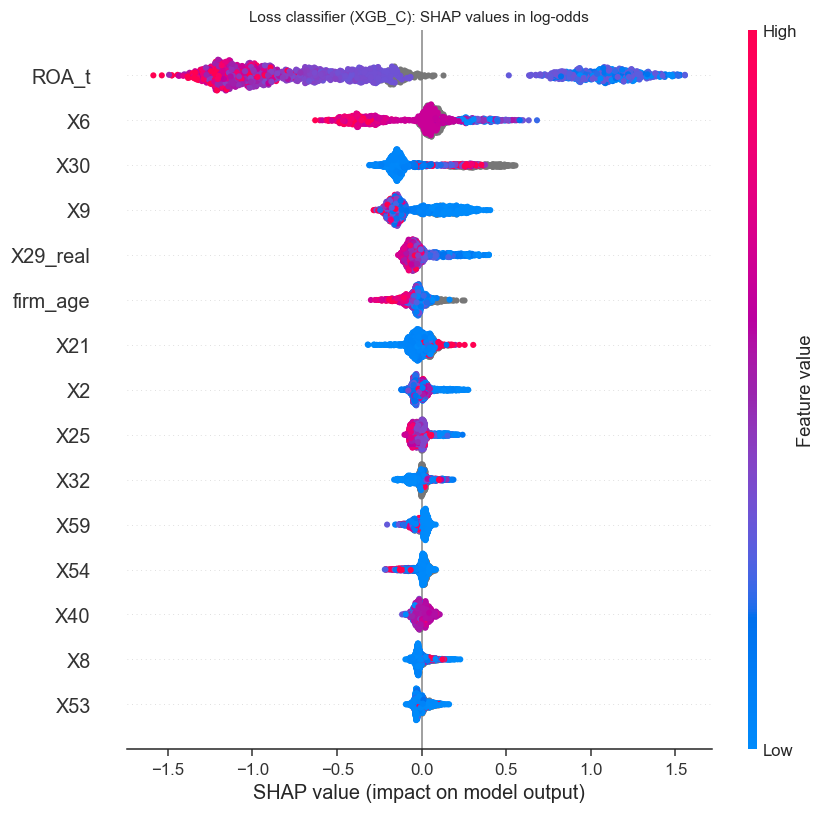

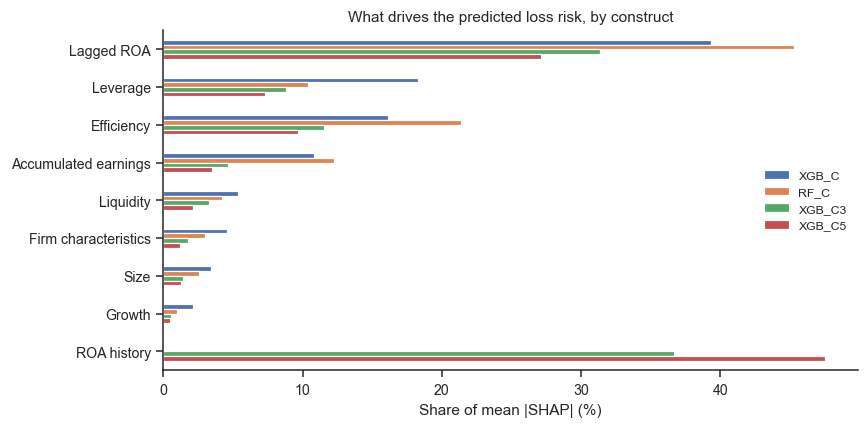

In [71]:
import shap

def tree_shap(est_, Xt_, is_clf=False):
    # Standard shap.TreeExplainer plus an additivity check (base value + sum of SHAP values must reproduce the model output).
    explainer = shap.TreeExplainer(est_)
    sv = explainer.shap_values(Xt_)
    if isinstance(sv, list):
        sv = sv[1]
    elif getattr(sv, "ndim", 2) == 3:
        sv = sv[:, :, 1]
    ev = np.ravel(explainer.expected_value)
    if isinstance(est_, (XGBClassifier, XGBRegressor)):
        ref = est_.predict(Xt_, output_margin=True) if is_clf else est_.predict(Xt_)
        recon = ev[0] + sv.sum(axis=1)
    else:
        ref = est_.predict_proba(Xt_.values)[:, 1] if is_clf else est_.predict(Xt_.values)
        recon = ev[-1] + sv.sum(axis=1)
    return sv, float(np.max(np.abs(recon - ref)))

def loss_shap(name):
    m = LOSS_FITTED[name]
    cols_ = loss_specs[name][1]
    X_ = TEST_DF[cols_]
    Xt_ = X_.copy() if len(m.steps) == 1 else pd.DataFrame(m[:-1].transform(X_), columns=cols_, index=X_.index)
    sv, gap = tree_shap(m.steps[-1][1], Xt_, is_clf=True)
    return sv, Xt_, gap

loss_shap_rows, loss_top = {}, {}
LOSS_SHAP = {}
for name in ("XGB_C", "RF_C", "XGB_C3", "XGB_C5"):
    sv, Xt_, gap = loss_shap(name)
    LOSS_SHAP[name] = (sv, Xt_)
    s = pd.Series(np.abs(sv).mean(axis=0), index=Xt_.columns)
    loss_shap_rows[name] = s.groupby(s.index.map(construct_of)).sum()
    loss_top[name] = ", ".join(s.sort_values(ascending=False).head(6).index)
    print(f"{name}: additivity check, max |base value + sum of SHAP - model output| = {gap:.2e}")
loss_shap_share = pd.DataFrame(loss_shap_rows).fillna(0)
loss_shap_share = (loss_shap_share / loss_shap_share.sum() * 100).sort_values("XGB_C", ascending=False)
print("\nShare of total mean |SHAP| by construct in the loss classifiers (%):")
display(loss_shap_share.round(1))
print("Top 6 features per classifier:")
for k, vv in loss_top.items():
    print(f"  {k}: {vv}")

sv_x, Xt_x = LOSS_SHAP["XGB_C"]
shap.summary_plot(sv_x, Xt_x, show=False, max_display=15)
plt.title("Loss classifier (XGB_C): SHAP values in log-odds", fontsize=10)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
loss_shap_share.plot(kind="barh", ax=ax)
ax.invert_yaxis(); ax.set_xlabel("Share of mean |SHAP| (%)"); ax.set_title("What drives the predicted loss risk, by construct")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 27. SHAP Explainability

Additivity check (base value + sum of SHAP values versus the model output): max deviation 1.31e-06


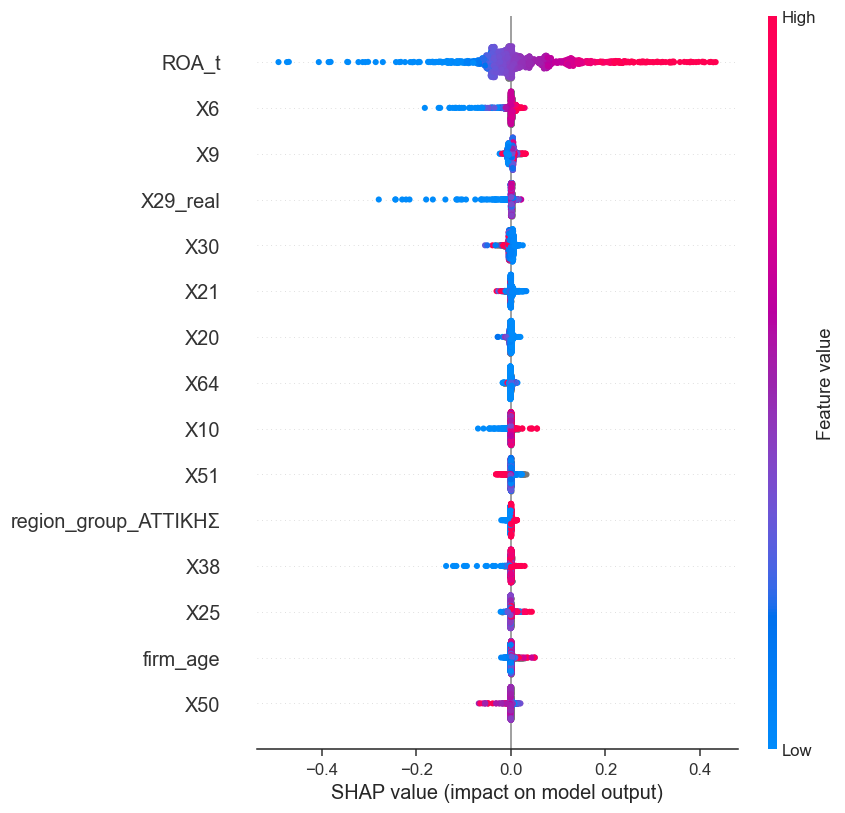

Selected model: XGB_Huber_C
Top 3 features by mean |SHAP|: ['ROA_t', 'X6', 'X9']


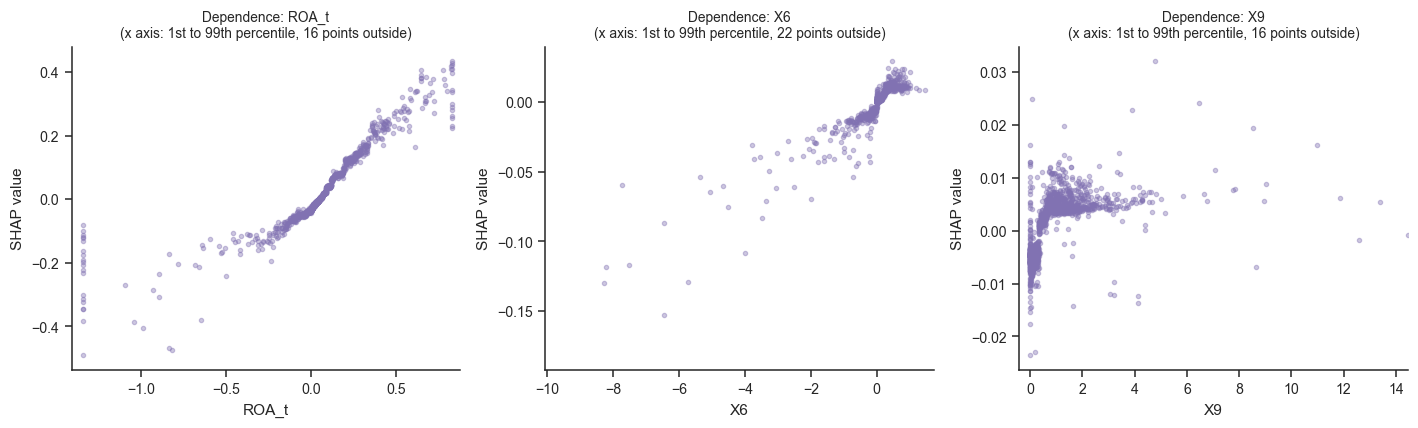


=== Highest predicted profitability (test row 432) ===
Actual ROA(t+1): 0.8268 | Predicted: 0.6888
Top 3 SHAP contributors: {'ROA_t': 0.3973, 'X10': 0.0453, 'X25': 0.0445}

=== Lowest predicted profitability (test row 485) ===
Actual ROA(t+1): -1.3428 | Predicted: -1.1160
Top 3 SHAP contributors: {'ROA_t': -0.4914, 'X38': -0.1369, 'X29_real': -0.1144}

=== Median prediction (row nearest the median forecast) (test row 1015) ===
Actual ROA(t+1): 0.0424 | Predicted: 0.0387
Top 3 SHAP contributors: {'ROA_t': -0.0085, 'X9': 0.0038, 'X20': -0.002}

=== Typical error (row nearest the median absolute error) (test row 298) ===
Actual ROA(t+1): 0.0393 | Predicted: 0.0019
Top 3 SHAP contributors: {'ROA_t': -0.0351, 'X9': -0.0052, 'X30': -0.0043}

=== Largest error (test row 674) ===
Actual ROA(t+1): -1.3428 | Predicted: 0.2626
Top 3 SHAP contributors: {'ROA_t': 0.1739, 'X9': 0.0241, 'X29_real': -0.0204}


In [72]:
import xgboost as xgb
import shap

final_pipe = FINAL[BEST_NAME]
X_te = TEST_DF[BEST_COLS]
if len(final_pipe.steps) == 1:
    Xt = X_te.copy()
else:
    Xt = pd.DataFrame(final_pipe[:-1].transform(X_te), columns=BEST_COLS, index=X_te.index)
final_est = final_pipe.steps[-1][1]

if isinstance(final_est, Ridge):
    explainer = shap.LinearExplainer(final_est, shap.maskers.Independent(Xt, max_samples=len(Xt)))
    shap_values = explainer.shap_values(Xt)
    recon = np.ravel(explainer.expected_value)[0] + shap_values.sum(axis=1)
    additivity_gap = float(np.max(np.abs(recon - final_est.predict(Xt))))
else:
    shap_values, additivity_gap = tree_shap(final_est, Xt, is_clf=False)
print(f"Additivity check (base value + sum of SHAP values versus the model output): max deviation {additivity_gap:.2e}")

shap.summary_plot(shap_values, Xt, show=False, max_display=15)
plt.tight_layout(); plt.show()

mean_abs_shap = pd.Series(np.abs(shap_values).mean(axis=0), index=Xt.columns).sort_values(ascending=False)
top3 = mean_abs_shap.head(3).index.tolist()
print(f"Selected model: {BEST_NAME}")
print("Top 3 features by mean |SHAP|:", top3)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, feat in zip(axes, top3):
    xv = Xt[feat].values.astype(float)
    ax.scatter(xv, shap_values[:, Xt.columns.get_loc(feat)], s=8, alpha=0.4, color=PALETTE["purple"])
    lo_x, hi_x = np.nanpercentile(xv, [1, 99])
    n_out = 0
    if hi_x > lo_x:
        pad = 0.03 * (hi_x - lo_x)
        ax.set_xlim(lo_x - pad, hi_x + pad)
        n_out = int(((xv < lo_x) | (xv > hi_x)).sum())
    ax.set_xlabel(feat)
    ax.set_ylabel("SHAP value")
    ax.set_title(f"Dependence: {feat}\n(x axis: 1st to 99th percentile, {n_out} points outside)", fontsize=9)
plt.tight_layout(); plt.show()

local_idx = {
    "Highest predicted profitability": int(err_df["pred"].values.argmax()),
    "Lowest predicted profitability": int(err_df["pred"].values.argmin()),
    "Median prediction (row nearest the median forecast)": int(np.abs(err_df["pred"].values - np.median(err_df["pred"].values)).argmin()),
    "Typical error (row nearest the median absolute error)": int(np.abs(err_df["abs_error"].values - np.median(err_df["abs_error"].values)).argmin()),
    "Largest error": int(err_df["abs_error"].values.argmax()),
}
for label, pos in local_idx.items():
    print(f"\n=== {label} (test row {pos}) ===")
    print(f"Actual ROA(t+1): {err_df[TARGET].iloc[pos]:.4f} | Predicted: {err_df['pred'].iloc[pos]:.4f}")
    row_shap = pd.Series(shap_values[pos], index=Xt.columns).sort_values(key=abs, ascending=False)
    print("Top 3 SHAP contributors:", {k: round(float(v), 4) for k, v in row_shap.head(3).items()})

### SHAP aggregated by construct, for the top learners of feature set C

Share of total mean |SHAP| by construct (%), columns = learners:


,XGB_Huber_C,RF_C,XGB_L2_C,XGB_L2_C3,XGB_L2_C5
Lagged ROA,56.7,50.0,51.6,36.4,28.6
Leverage,11.6,13.1,12.7,6.2,5.7
Efficiency,11.4,12.8,12.6,7.2,5.4
Accumulated earnings,6.7,7.7,8.5,4.8,3.2
Liquidity,4.6,5.1,4.3,3.1,2.9
Size,3.7,4.6,4.9,2.6,2.0
Firm characteristics,3.2,4.8,3.5,1.3,0.8
Growth,2.1,1.9,2.0,0.2,0.2
ROA history,0.0,0.0,0.0,38.3,51.2


Top 5 features per learner:
  XGB_Huber_C: ROA_t, X6, X9, X29_real, X30
  RF_C: ROA_t, X6, X9, X29_real, X10
  XGB_L2_C: ROA_t, X6, X29_real, X9, X10
  XGB_L2_C3: ROA_t, ROA_mean3, ROA_lag1, ROA_min3, X6
  XGB_L2_C5: ROA_t, ROA_mean3, ROA_mean5, ROA_min3, ROA_lag1


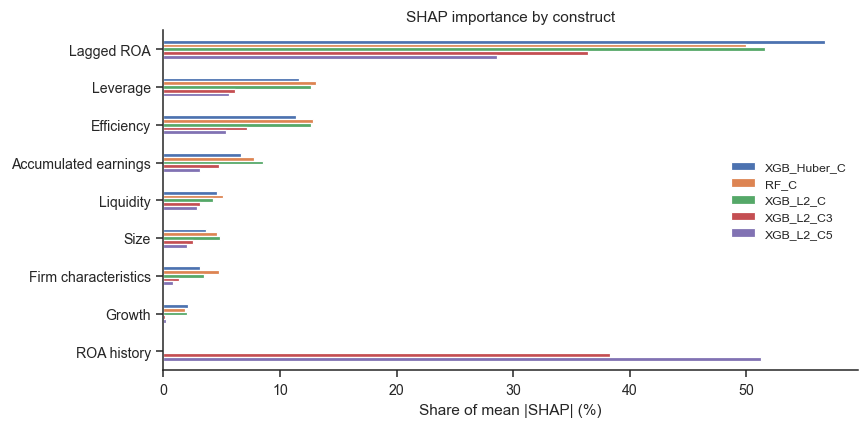

In [73]:
def shap_mean_abs(name):
    if name == BEST_NAME:
        return mean_abs_shap
    pipe = FINAL[name]
    cols_ = FEATURE_SETS[MODEL_SPECS[name]["feats"]]
    X_ = TEST_DF[cols_]
    Xt_ = X_.copy() if len(pipe.steps) == 1 else pd.DataFrame(pipe[:-1].transform(X_), columns=cols_, index=X_.index)
    est_ = pipe.steps[-1][1]
    if isinstance(est_, Ridge):
        sv = shap.LinearExplainer(est_, shap.maskers.Independent(Xt_, max_samples=len(Xt_))).shap_values(Xt_)
    else:
        sv, gap_ = tree_shap(est_, Xt_, is_clf=False)
    return pd.Series(np.abs(sv).mean(axis=0), index=cols_)

TOP_C = sorted([n for n in ELIGIBLE if n.endswith("_C")], key=lambda n: valid_table.loc[n, SELECTION_METRIC])[:3]
construct_rows, top_feat_rows = {}, {}
for name in TOP_C + ["XGB_L2_C3", "XGB_L2_C5"]:
    s = shap_mean_abs(name)
    if s is None:
        continue
    construct_rows[name] = s.groupby(s.index.map(construct_of)).sum()
    top_feat_rows[name] = ", ".join(s.sort_values(ascending=False).head(5).index)
construct_table = pd.DataFrame(construct_rows).fillna(0)
construct_share = (construct_table / construct_table.sum() * 100).sort_values(TOP_C[0], ascending=False)
print("Share of total mean |SHAP| by construct (%), columns = learners:")
display(construct_share.round(1))
print("Top 5 features per learner:")
for k, vv in top_feat_rows.items():
    print(f"  {k}: {vv}")

fig, ax = plt.subplots(figsize=(8, 4))
construct_share.plot(kind="barh", ax=ax)
ax.invert_yaxis(); ax.set_xlabel("Share of mean |SHAP| (%)"); ax.set_title("SHAP importance by construct")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### Permutation importance by construct

In [74]:
def group_permutation_importance(predict, X, y, groups, score, higher_is_worse, n_repeats=20, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    base = score(y, predict(X))
    rows = []
    for g, cols in groups.items():
        changes = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]
            changes.append((score(y, predict(Xp)) - base) * (1 if higher_is_worse else -1))
        rows.append({"construct": g, "n_features": len(cols), "importance": float(np.mean(changes)), "sd": float(np.std(changes, ddof=1))})
    return pd.DataFrame(rows).set_index("construct").sort_values("importance", ascending=False)

def construct_groups(cols):
    out = {}
    for c in cols:
        out.setdefault(construct_of(c), []).append(c)
    return out

perm_tables = {}
# Regression: increase in test RMSE when a construct is permuted jointly
for name in (BEST_NAME, "XGB_L2_C3"):
    cols_m = FEATURE_SETS[MODEL_SPECS[name]["feats"]]
    pipe = FINAL[name]
    t = group_permutation_importance(lambda X: pipe.predict(X), TEST_DF[cols_m], y_test, construct_groups(cols_m), rmse, True)
    perm_tables[f"{name} (RMSE increase)"] = t
# Loss: decrease in test AUC
for name in ("XGB_C", "XGB_C3"):
    cols_m = loss_specs[name][1]
    m_ = LOSS_FITTED[name]
    t = group_permutation_importance(lambda X: m_.predict_proba(X)[:, 1], TEST_DF[cols_m], yl_test, construct_groups(cols_m),
                                     lambda y, s: roc_auc_score(y, s), False)
    perm_tables[f"{name} loss (AUC decrease)"] = t
for k, t in perm_tables.items():
    print(f"\n{k}:")
    display(t.round(4))

# Agreement with SHAP construct shares (rank correlation) for the two lag-only-history models
def rank_agreement(perm_t, shap_series):
    idx = perm_t.index.intersection(shap_series.index)
    return float(spearmanr(perm_t.loc[idx, "importance"], shap_series.loc[idx])[0]) if len(idx) > 2 else np.nan
print("\nSpearman rank agreement between permutation importance and mean |SHAP| by construct:")
print(f"  {BEST_NAME}: {rank_agreement(perm_tables[f'{BEST_NAME} (RMSE increase)'], mean_abs_shap.groupby(mean_abs_shap.index.map(construct_of)).sum()):.2f}")
print(f"  XGB_C loss: {rank_agreement(perm_tables['XGB_C loss (AUC decrease)'], loss_shap_rows['XGB_C']):.2f}")


XGB_Huber_C (RMSE increase):


,n_features,importance,sd
construct,,,
Lagged ROA,1,0.0545,0.0022
Leverage,9,0.0044,0.0010
Size,1,0.0031,0.0006
Accumulated earnings,2,0.0028,0.0007
Liquidity,8,0.0021,0.0008
Efficiency,10,0.0011,0.0012
Growth,1,0.0008,0.0004
Firm characteristics,44,0.0006,0.0006



XGB_L2_C3 (RMSE increase):


,n_features,importance,sd
construct,,,
Lagged ROA,1,0.0240,0.0013
ROA history,4,0.0235,0.0012
Leverage,9,0.0021,0.0006
Size,1,0.0018,0.0003
Liquidity,8,0.0016,0.0006
Efficiency,10,0.0015,0.0004
Accumulated earnings,2,0.0010,0.0003
Firm characteristics,44,0.0004,0.0002
Growth,1,0.0001,0.0001



XGB_C loss (AUC decrease):


,n_features,importance,sd
construct,,,
Lagged ROA,1,0.1680,0.0119
Leverage,9,0.0181,0.0034
Accumulated earnings,2,0.0143,0.0034
Efficiency,10,0.0090,0.0028
Size,1,0.0045,0.0011
Firm characteristics,44,0.0026,0.0007
Growth,1,0.0023,0.0007
Liquidity,8,0.0015,0.0011



XGB_C3 loss (AUC decrease):


,n_features,importance,sd
construct,,,
ROA history,4,0.0906,0.0131
Lagged ROA,1,0.0510,0.0063
Efficiency,10,0.0070,0.0015
Leverage,9,0.0045,0.0012
Accumulated earnings,2,0.0041,0.0016
Liquidity,8,0.0016,0.0004
Size,1,0.0013,0.0007
Firm characteristics,44,0.0007,0.0003
Growth,1,0.0003,0.0002



Spearman rank agreement between permutation importance and mean |SHAP| by construct:
  XGB_Huber_C: 0.76
  XGB_C loss: 0.81


## 28. Extraction Validation: Precision and Accuracy (Bootstrap)

In [75]:
EV_FIELDS = ["TA", "Sales", "NP", "EQ", "TL", "EBIT"]
EV_TOLERANCE_EUR = 5.0
EV_AVAILABLE = os.path.exists(MANUAL_VALIDATION_CSV)
HIDDEN_NOISE = None
ROA_INPUT_ERROR = None
EV_N = None
EV_ILLUSTRATIVE = None

if not EV_AVAILABLE:
    print(f"Manual validation file not found ({MANUAL_VALIDATION_CSV}); Sections 28-29 skipped.")
else:
    ev_df = pd.read_csv(MANUAL_VALIDATION_CSV, low_memory=False, dtype={"gemh_id": str})
    ev_df = ev_df[ev_df["TA_manual"].notna()].reset_index(drop=True)
    EV_N = len(ev_df)
    EV_ILLUSTRATIVE = EV_N < 100
    print(f"Loaded {EV_N} manually verified rows." + (" ILLUSTRATIVE: n < 100, sample-level findings only." if EV_ILLUSTRATIVE else ""))

    def ev_classify(parser_val, manual_val, tol=EV_TOLERANCE_EUR):
        # Three outcomes (TP / FP / FN); the manual value is always a definite number.
        if pd.isna(manual_val):
            return None
        if pd.isna(parser_val):
            return "FN"
        return "TP" if abs(parser_val - manual_val) <= tol else "FP"

    def ev_field_metrics(data, fields):
        rows = []
        for field in fields:
            outcomes = [ev_classify(p, m) for p, m in zip(data[f"{field}_parser"], data[f"{field}_manual"])]
            outcomes = [o for o in outcomes if o is not None]
            tp, fp, fn = outcomes.count("TP"), outcomes.count("FP"), outcomes.count("FN")
            precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
            recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
            f1 = (2 * precision * recall / (precision + recall)
                  if np.isfinite(precision) and np.isfinite(recall) and (precision + recall) > 0 else np.nan)
            accuracy = tp / len(outcomes) if outcomes else np.nan
            rows.append({"field": field, "n": len(outcomes), "TP": tp, "FP": fp, "FN": fn,
                         "precision": precision, "recall": recall, "f1": f1, "accuracy": accuracy})
        return pd.DataFrame(rows).set_index("field")

    ev_real_metrics = ev_field_metrics(ev_df, EV_FIELDS)
    display(ev_real_metrics.round(3))

Loaded 50 manually verified rows. ILLUSTRATIVE: n < 100, sample-level findings only.


,n,TP,FP,FN,precision,recall,f1,accuracy
field,,,,,,,,
TA,50,35,11,4,0.761,0.897,0.824,0.70
Sales,50,34,10,6,0.773,0.850,0.810,0.68
NP,50,36,10,4,0.783,0.900,0.837,0.72
EQ,50,31,12,7,0.721,0.816,0.765,0.62
TL,50,31,15,4,0.674,0.886,0.765,0.62
EBIT,50,27,17,6,0.614,0.818,0.701,0.54


,n,TP,FP,FN,accuracy,precision,recall,f1,precision_lo,precision_hi,recall_lo,recall_hi,f1_lo,f1_hi,accuracy_lo,accuracy_hi
field,,,,,,,,,,,,,,,,
TA,50,35,11,4,0.70,0.761,0.897,0.824,0.638,0.886,0.795,0.976,0.734,0.901,0.58,0.82
Sales,50,34,10,6,0.68,0.773,0.850,0.810,0.638,0.891,0.725,0.951,0.701,0.901,0.54,0.82
NP,50,36,10,4,0.72,0.783,0.900,0.837,0.660,0.894,0.800,0.976,0.750,0.913,0.60,0.84
EQ,50,31,12,7,0.62,0.721,0.816,0.765,0.581,0.848,0.686,0.927,0.649,0.851,0.48,0.74
TL,50,31,15,4,0.62,0.674,0.886,0.765,0.535,0.804,0.765,0.974,0.649,0.851,0.48,0.74
EBIT,50,27,17,6,0.54,0.614,0.818,0.701,0.475,0.756,0.667,0.941,0.571,0.810,0.40,0.68



=== By extraction tier (precision and accuracy with Wilson 95% intervals) ===

gemini_vision (n = 14):


,n,accuracy,accuracy_wilson_lo,accuracy_wilson_hi,precision,precision_wilson_lo,precision_wilson_hi
field,,,,,,,
TA,14,0.357,0.163,0.612,0.385,0.177,0.645
Sales,14,0.429,0.214,0.674,0.462,0.232,0.709
NP,14,0.357,0.163,0.612,0.357,0.163,0.612
EQ,14,0.357,0.163,0.612,0.385,0.177,0.645
TL,14,0.357,0.163,0.612,0.385,0.177,0.645
EBIT,14,0.286,0.117,0.546,0.333,0.138,0.609



manual_verified (n = 1):


,n,accuracy,accuracy_wilson_lo,accuracy_wilson_hi,precision,precision_wilson_lo,precision_wilson_hi
field,,,,,,,
TA,1,1.0,0.207,1.000,1.0,0.207,1.0
Sales,1,0.0,0.000,0.793,NaN,NaN,NaN
NP,1,0.0,0.000,0.793,NaN,NaN,NaN
EQ,1,1.0,0.207,1.000,1.0,0.207,1.0
TL,1,1.0,0.207,1.000,1.0,0.207,1.0
EBIT,1,0.0,0.000,0.793,NaN,NaN,NaN



pdfplumber (n = 32):


,n,accuracy,accuracy_wilson_lo,accuracy_wilson_hi,precision,precision_wilson_lo,precision_wilson_hi
field,,,,,,,
TA,32,0.875,0.719,0.950,0.903,0.751,0.967
Sales,32,0.844,0.682,0.931,0.900,0.744,0.965
NP,32,0.906,0.758,0.968,0.967,0.833,0.994
EQ,32,0.750,0.579,0.867,0.857,0.685,0.943
TL,32,0.781,0.612,0.890,0.806,0.637,0.908
EBIT,32,0.688,0.514,0.820,0.733,0.556,0.858



scan_unprocessed (n = 3):


,n,accuracy,accuracy_wilson_lo,accuracy_wilson_hi,precision,precision_wilson_lo,precision_wilson_hi
field,,,,,,,
TA,3,0.333,0.061,0.792,1.0,0.207,1.000
Sales,3,0.333,0.061,0.792,1.0,0.207,1.000
NP,3,0.667,0.208,0.939,1.0,0.342,1.000
EQ,3,0.333,0.061,0.792,1.0,0.207,1.000
TL,3,0.000,0.000,0.562,0.0,0.000,0.793
EBIT,3,0.333,0.061,0.792,0.5,0.095,0.905


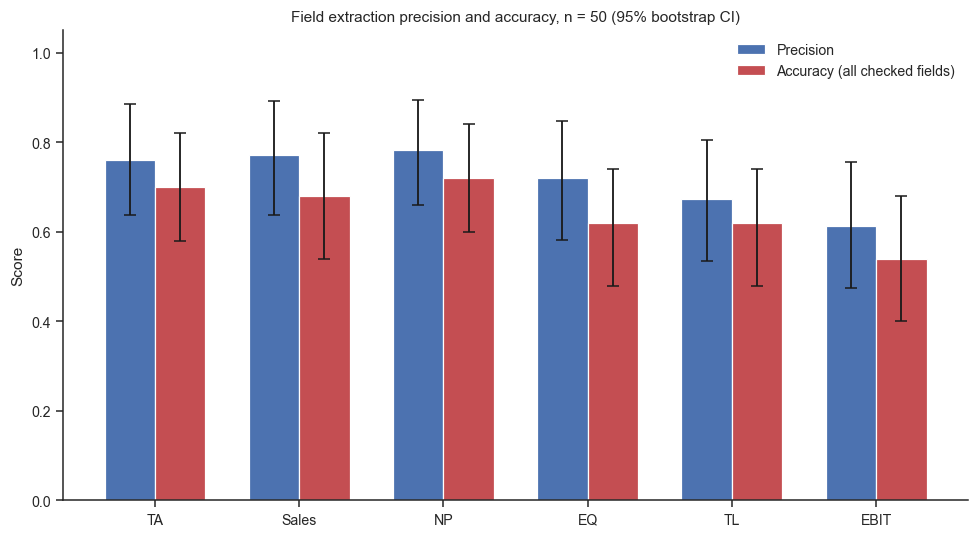


Measured on a stratified random sample of 50 filings; report the sample size next to every percentage.


In [76]:
if EV_AVAILABLE:
    def ev_bootstrap(data, fields, n_boot=1000, seed=RANDOM_STATE):
        # Row-level resampling keeps correlated errors within one messy filing together.
        rng = np.random.default_rng(seed)
        n = len(data)
        boot = {f: {"precision": [], "recall": [], "f1": [], "accuracy": []} for f in fields}
        for _ in range(n_boot):
            m = ev_field_metrics(data.iloc[rng.integers(0, n, size=n)], fields)
            for f in fields:
                for k in ("precision", "recall", "f1", "accuracy"):
                    boot[f][k].append(m.loc[f, k])
        rows = []
        for f in fields:
            row = {"field": f}
            for k in ("precision", "recall", "f1", "accuracy"):
                vals = np.array(boot[f][k], dtype=float)
                vals = vals[~np.isnan(vals)]
                row[f"{k}_lo"] = np.percentile(vals, 2.5) if len(vals) else np.nan
                row[f"{k}_hi"] = np.percentile(vals, 97.5) if len(vals) else np.nan
            rows.append(row)
        return pd.DataFrame(rows).set_index("field")

    ev_ci = ev_bootstrap(ev_df, EV_FIELDS)
    ev_summary = ev_real_metrics[["n", "TP", "FP", "FN", "accuracy", "precision", "recall", "f1"]].join(ev_ci).round(3)
    display(ev_summary)

    print("\n=== By extraction tier (precision and accuracy with Wilson 95% intervals) ===")
    for tier in sorted(ev_df["extraction_tier"].dropna().unique()):
        tier_df = ev_df[ev_df["extraction_tier"] == tier]
        m = ev_field_metrics(tier_df, EV_FIELDS)
        m["precision_wilson_lo"] = [wilson_ci(int(r.TP), int(r.TP + r.FP))[0] for r in m.itertuples()]
        m["precision_wilson_hi"] = [wilson_ci(int(r.TP), int(r.TP + r.FP))[1] for r in m.itertuples()]
        m["accuracy_wilson_lo"] = [wilson_ci(int(r.TP), int(r.n))[0] for r in m.itertuples()]
        m["accuracy_wilson_hi"] = [wilson_ci(int(r.TP), int(r.n))[1] for r in m.itertuples()]
        print(f"\n{tier} (n = {len(tier_df)}):")
        display(m[["n", "accuracy", "accuracy_wilson_lo", "accuracy_wilson_hi", "precision", "precision_wilson_lo", "precision_wilson_hi"]].round(3))

    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(EV_FIELDS)); width = 0.35
    prec = ev_real_metrics.loc[EV_FIELDS, "precision"].values
    rec = ev_real_metrics.loc[EV_FIELDS, "accuracy"].values
    prec_err = [prec - ev_ci.loc[EV_FIELDS, "precision_lo"].values, ev_ci.loc[EV_FIELDS, "precision_hi"].values - prec]
    rec_err = [rec - ev_ci.loc[EV_FIELDS, "accuracy_lo"].values, ev_ci.loc[EV_FIELDS, "accuracy_hi"].values - rec]
    ax.bar(x - width / 2, prec, width, yerr=prec_err, capsize=4, label="Precision", color=PALETTE["blue"])
    ax.bar(x + width / 2, rec, width, yerr=rec_err, capsize=4, label="Accuracy (all checked fields)", color=PALETTE["red"])
    ax.set_xticks(x); ax.set_xticklabels(EV_FIELDS); ax.set_ylim(0, 1.05); ax.set_ylabel("Score")
    ax.set_title(f"Field extraction precision and accuracy, n = {EV_N} (95% bootstrap CI)")
    ax.legend(frameon=False)
    plt.tight_layout(); plt.show()
    print(f"\nMeasured on a stratified random sample of {EV_N} filings; report the sample size next to every percentage.")

In [77]:
if EV_AVAILABLE:
    id_panel = ml_df["accounting_identity_check"].dropna().astype(bool)
    ev_join = ev_df.merge(ml_df[["gemh_id", "year", "accounting_identity_check"]].drop_duplicates(["gemh_id", "year"]),
                          on=["gemh_id", "year"], how="left")
    id_sample = ev_join["accounting_identity_check"].dropna().astype(bool)
    print("Is the manual sample representative of the panel?")
    print(f"  identity failures: {100 * (~id_sample).mean():.1f}% of the sample versus {100 * (~id_panel).mean():.1f}% of the panel")
    mix = pd.DataFrame({"sample (%)": ev_df["extraction_tier"].value_counts(normalize=True).mul(100),
                        "panel (%)": ml_df["extraction_tier"].value_counts(normalize=True).mul(100)}).round(1)
    display(mix)

Is the manual sample representative of the panel?
  identity failures: 38.0% of the sample versus 31.3% of the panel


,sample (%),panel (%)
extraction_tier,,
pdfplumber,64.0,72.1
gemini_vision,28.0,27.8
scan_unprocessed,6.0,0.1
manual_verified,2.0,0.0


## 29. Does Passing the Identity Check Mean the Row Is Correct?

In [78]:
if EV_AVAILABLE:
    EV_KEY_COLS = ["gemh_id", "year"]
    ct_lookup = ml_df[EV_KEY_COLS + ["accounting_identity_check"]].drop_duplicates(subset=EV_KEY_COLS)
    ct_merged = ev_df.merge(ct_lookup, on=EV_KEY_COLS, how="left", validate="one_to_one")
    n_missing = int(ct_merged["accounting_identity_check"].isna().sum())
    if n_missing:
        print(f"WARNING: {n_missing} row(s) had no match in ml_df (gemh_id/year not found).")
    ct_merged = ct_merged.dropna(subset=["accounting_identity_check"])

    for field in EV_FIELDS:
        ct_merged[f"{field}_ok"] = [(not pd.isna(m)) and (not pd.isna(p)) and abs(p - m) <= EV_TOLERANCE_EUR
                                    for p, m in zip(ct_merged[f"{field}_parser"], ct_merged[f"{field}_manual"])]
    ok_cols = [f"{f}_ok" for f in EV_FIELDS]
    ct_merged["manual_verification_passes"] = ct_merged[ok_cols].all(axis=1)
    ct_merged["identity_check_bool"] = ct_merged["accounting_identity_check"].astype(bool)

    cross_tab = pd.crosstab(ct_merged["identity_check_bool"], ct_merged["manual_verification_passes"],
                            rownames=["accounting_identity_check"], colnames=["manual_verification_passes"])
    cross_tab = cross_tab.reindex(index=[True, False], columns=[True, False], fill_value=0)
    display(cross_tab)

    n_ct = len(ct_merged)
    tt, tf = int(cross_tab.loc[True, True]), int(cross_tab.loc[True, False])
    ft, ff = int(cross_tab.loc[False, True]), int(cross_tab.loc[False, False])
    print(f"\nn = {n_ct}")
    print(f"  identity=True,  manual=True  (genuinely clean):   {tt} ({100*tt/n_ct:.1f}%)")
    print(f"  identity=True,  manual=False (hidden noise):      {tf} ({100*tf/n_ct:.1f}%)")
    print(f"  identity=False, manual=True  (false alarm):       {ft} ({100*ft/n_ct:.1f}%)")
    print(f"  identity=False, manual=False (correctly flagged): {ff} ({100*ff/n_ct:.1f}%)")

    n_pass = tt + tf
    if n_pass > 0:
        lo, hi = wilson_ci(tf, n_pass)
        hidden = ct_merged[ct_merged["identity_check_bool"] & ~ct_merged["manual_verification_passes"]]
        direct = hidden[(~hidden["TA_ok"]) | (~hidden["NP_ok"])]
        lo2, hi2 = wilson_ci(len(direct), n_pass)
        HIDDEN_NOISE = (tf, n_pass, lo, hi)
        ROA_INPUT_ERROR = (len(direct), n_pass, lo2, hi2)
        print(f"\nOf {n_pass} identity-passing rows, {tf} ({100*tf/n_pass:.1f}%; Wilson 95% [{100*lo:.0f}%, {100*hi:.0f}%]) "
              f"contain at least one erroneous field.")
        print(f"{len(direct)} ({100*len(direct)/n_pass:.1f}%; Wilson 95% [{100*lo2:.0f}%, {100*hi2:.0f}%]) have the error directly in "
              f"TA or NP, the inputs of ROA; the rest are confined to Sales / EQ / TL / EBIT.")

manual_verification_passes,True,False
accounting_identity_check,,
True,13,18
False,1,18



n = 50
  identity=True,  manual=True  (genuinely clean):   13 (26.0%)
  identity=True,  manual=False (hidden noise):      18 (36.0%)
  identity=False, manual=True  (false alarm):       1 (2.0%)
  identity=False, manual=False (correctly flagged): 18 (36.0%)

Of 31 identity-passing rows, 18 (58.1%; Wilson 95% [41%, 74%]) contain at least one erroneous field.
7 (22.6%; Wilson 95% [11%, 40%]) have the error directly in TA or NP, the inputs of ROA; the rest are confined to Sales / EQ / TL / EBIT.


### Panel-level estimate of the hidden noise (post-stratified by extraction tier)

In [79]:
POSTSTRAT = None
if EV_AVAILABLE and HIDDEN_NOISE:
    panel_pass = ml_df.loc[ml_df["accounting_identity_check"].fillna(False).astype(bool)]
    w_panel = panel_pass["extraction_tier"].value_counts(normalize=True)
    samp = ct_merged[ct_merged["identity_check_bool"]].copy()
    samp["wrong_any"] = ~samp["manual_verification_passes"]
    samp["wrong_TA_NP"] = (~samp["TA_ok"]) | (~samp["NP_ok"])
    tier_tbl = pd.DataFrame({"panel weight (%)": 100 * w_panel,
                             "sample n": samp["extraction_tier"].value_counts(),
                             "share with any wrong field": samp.groupby("extraction_tier")["wrong_any"].mean(),
                             "share wrong in TA or NP": samp.groupby("extraction_tier")["wrong_TA_NP"].mean()}).fillna({"sample n": 0})
    tier_tbl["used in weighted estimate"] = tier_tbl["sample n"] >= MIN_STRATUM_N
    display(tier_tbl.round(3))
    used = tier_tbl.index[tier_tbl["used in weighted estimate"]].tolist()
    cover = float(w_panel.reindex(used).sum())

    def poststrat(flag_col, n_boot=2000, seed=RANDOM_STATE):
        w = w_panel.reindex(used)
        def est(df):
            p_t = df.groupby("extraction_tier")[flag_col].mean().reindex(used)
            return float((w * p_t).sum() / w.sum())
        point = est(samp)
        rng = np.random.default_rng(seed)
        parts = {t: samp[samp["extraction_tier"] == t] for t in used}
        boots = []
        for _ in range(n_boot):
            resampled = pd.concat([g.iloc[rng.integers(0, len(g), len(g))] for g in parts.values()])
            boots.append(est(resampled))
        lo, hi = np.percentile(boots, [2.5, 97.5])
        return point, float(lo), float(hi)

    if used:
        POSTSTRAT = {}
        for label, col in (("any wrong field", "wrong_any"), ("wrong field in TA or NP", "wrong_TA_NP")):
            pt, lo, hi = poststrat(col)
            raw = float(samp[col].mean())
            lower = pt * cover                    # excluded tiers all correct
            upper = pt * cover + (1 - cover)      # excluded tiers all wrong
            POSTSTRAT[label] = dict(raw=raw, weighted=pt, ci=(lo, hi), covered_weight=cover, bounds=(lower, upper), used_tiers=list(used),
                                    illustrative_methodological_demo=True)
            small = tier_tbl.index[(tier_tbl["sample n"] >= 1) & (~tier_tbl["used in weighted estimate"])].tolist()
            w_all = w_panel.reindex(used + small)
            p_all = samp.groupby("extraction_tier")[col].mean().reindex(used + small)
            est_all = float((w_all * p_all).sum() / w_all.sum())
            POSTSTRAT[label].update(illustrative_all_strata=est_all)
            bounds_txt = (f"bounds for the whole panel {100*lower:.0f}% to {100*upper:.0f}% (tiers below the minimum counted as all correct or all wrong)"
                          if cover < 0.95 else "the excluded tiers carry under 5% of the weight, so bounds add little; the interval above is the honest uncertainty")
            print(f"Identity-passing rows with {label}: raw sample share {100*raw:.1f}%, post-stratified {100*pt:.1f}% "
                  f"[bootstrap 95% {100*lo:.0f}%, {100*hi:.0f}%], covering {100*cover:.0f}% of the panel weight; {bounds_txt}. "
                  f"Illustrative estimate that also uses the small strata at their raw rates: {100*est_all:.0f}% (not defensible: strata of "
                  f"{', '.join(str(int(tier_tbl.loc[t, 'sample n'])) for t in small) if small else 'none'} rows).")
    else:
        print("No tier has enough sampled rows for a weighted estimate.")

,panel weight (%),sample n,share with any wrong field,share wrong in TA or NP,used in weighted estimate
extraction_tier,,,,,
gemini_vision,27.796,9,0.889,0.556,False
manual_verified,0.007,1,1.000,1.000,False
pdfplumber,72.197,21,0.429,0.048,True


Identity-passing rows with any wrong field: raw sample share 58.1%, post-stratified 42.9% [bootstrap 95% 19%, 62%], covering 72% of the panel weight; bounds for the whole panel 31% to 59% (tiers below the minimum counted as all correct or all wrong). Illustrative estimate that also uses the small strata at their raw rates: 56% (not defensible: strata of 9, 1 rows).
Identity-passing rows with wrong field in TA or NP: raw sample share 22.6%, post-stratified 4.8% [bootstrap 95% 0%, 14%], covering 72% of the panel weight; bounds for the whole panel 3% to 31% (tiers below the minimum counted as all correct or all wrong). Illustrative estimate that also uses the small strata at their raw rates: 19% (not defensible: strata of 9, 1 rows).


## 30. Economic Interpretation

## 31. Limitations

In [80]:
lines = []
lines.append(f"Primary evidence: nested rolling-origin evaluation with the ratios compared against the {PRIMARY_HISTORY_SET}-year ROA history; framing for the level of ROA "
             f"{FRAMING_PRIMARY_KEY}, for loss {LOSS_FRAMING_PRIMARY}. The single test year is descriptive; multiple comparisons are handled by declaring four primary "
             "hypotheses and Holm-adjusting the primary Diebold-Mariano comparisons.")
lines.append("Exploratory status: the test year was inspected in earlier versions of this notebook and the design was revised afterwards "
             "(benchmarks added, ratios regrouped, duplicates and one tier removed), so the numbers are exploratory; a confirmatory test needs "
             "data no version has seen, or a plan frozen before evaluation.")
lines.append("Survivorship is built into the panel: the sample requires ten consecutive annual filings, so exits, dissolved "
             "firms and late filers are absent. The expected direction is upward for profitability levels and thinner left tails; "
             "its size is not estimable within the sample. Findings apply to continuing filers, not to the population of Greek SMEs.")
lines.append(f"Single test year: all {len(TEST_DF):,} test rows share feature year(s) {sorted(TEST_DF['year'].unique().tolist())} "
             f"(target year {sorted(TEST_DF['year'].unique().tolist())[0]+1}). Intervals describe sampling variation across firms, "
             "not variation across years or regimes; walk-forward results are descriptive.")
lines.append("Selection on target availability: rows whose next-year NP or TA is missing or below the TA floor never enter the "
             "modelling sample (Section 8 reports how many and whether they differ on observables). Missing-not-at-random "
             "mechanisms cannot be tested from observed data.")
lines.append("Target measurement error: ROA is built from parsed PDF values. The identity check does not detect errors in NP or in "
             "offsetting balance-sheet fields" + (
                 f"; in the manual sample, {HIDDEN_NOISE[0]} of {HIDDEN_NOISE[1]} identity-passing rows had at least one wrong "
                 f"field and {ROA_INPUT_ERROR[0]} of {ROA_INPUT_ERROR[1]} had an error in TA or NP (n = {EV_N}; wide intervals, "
                 "sample-level evidence)." if HIDDEN_NOISE else "."))
lines.append("Static registry attributes: `n_persons`, `n_activities`, `meets_threshold`, `isBranch`, `legalType` and `region_group` never "
             "change within a firm in the delivered file, so they describe the registry at collection time. The first three are excluded "
             "from the primary feature sets; the last three stay as structural characteristics and are tested by an ablation. "
             "`size_category` varies over time, but its provenance is unverified, so it is only an ablation arm.")
lines.append("Lagged-profitability ratios are excluded from feature set A by design (not because they leak). Statements about "
             "feature set A answer 'do balance-sheet ratios alone forecast ROA?'; statements about information beyond profitability rely on "
             "the comparison with the ROA-history benchmark (C5 versus R5, and C3 versus R3).")
lines.append("Firm-aware validation (Section 22): " + degradation_message(BEST_NAME) +
             " Static attributes can act as a firm fingerprint, so claims about firms outside the panel need this check.")
lines.append("Benchmarks: least-squares AR(1) shrinks toward the mean and is a weak benchmark for MAE and MedAE. Persistence and AR(1) "
             "with median regression are reported next to it; the nonlinear ROA-only model tests the nonlinear use of the one-year lag, and the "
             "ROA-history models (R3, R5) are the strict benchmark for the claim that the ratios add information.")
lines.append("Tail dependence: a small share of rows (extremely negative ROA, mostly micro firms) carries a large share of squared error "
             "(Section 26), so RMSE conclusions are read together with MAE. Section 20 shows where the gain over AR(1) is located.")
lines.append("Manual validation sample: it is small and not representative of the panel (Section 28 compares its composition), so its "
             "error rates are sample-level findings.")
try:
    ext = tail_table.loc["extreme (top 10%)"]
    mis = tail_table.loc["ROA_t missing"]
    typ = tail_table.loc["typical (|ROA_t| in the bottom 50%)"]
    gcol = "share of squared-error gain over AR1 (%)"
    lines.append(f"Where the gain sits: {ext[gcol]:.0f}% of the squared-error gain over AR(1) comes from the {int(ext['n'])} test rows with "
                 f"extreme |ROA_t|, {mis[gcol]:.0f}% from the {int(mis['n'])} rows without ROA_t (where the baselines fall back to a "
                 f"constant) and {typ[gcol]:.0f}% from the typical half of the rows (median absolute error there: Persistence "
                 f"{typ['MedAE Persistence']:.4f}, {FAM_C} {typ['MedAE ' + FAM_C]:.4f}).")
except KeyError:
    pass
lines.append("Learner dependence: the framing INCREMENTAL_INFORMATION holds for " + (", ".join(c_pass) if c_pass else "no learner") +
             " and SMALL_INCREMENTAL_INFORMATION for " + (", ".join(c_small) if c_small else "no learner") +
             " of feature set C; the selection among the top learners is unresolved on the validation year, so the headline is stated for the family "
             f"({FRAMING_KEY}; single selected learner: {SECONDARY_FRAMING_KEY}).")
lines.append(f"Nested rolling-origin evaluation (hyper-parameters tuned only on earlier years): pooled framing {NESTED_FRAMING_KEY}; "
             "by target year " + ", ".join(f"{k} in {v_} year(s)" for k, v_ in nested_year_verdicts["framing"].value_counts().items()) + ". "
             "Random Forests are not part of the nested loop.")
lines.append(f"Loss prediction (Section 26b): on the test year the C family reaches AUC {LOSS_SUMMARY['AUC_test']['LOSS_ENS_C']:.3f}, against "
             f"{LOSS_SUMMARY['AUC_test']['LOSS_ENS_R']:.3f} for the ROA-only family and {LOSS_SUMMARY['AUC_test']['Logit_SPLINE']:.3f} for a spline logit "
             f"on the lag (framing {LOSS_FRAMING_TEST}); the top 10% of predicted risk of the C family captures {loss_table.loc['LOSS_ENS_C', 'captured in top 10% (%)']:.0f}% of all losses "
             f"(R family {loss_table.loc['LOSS_ENS_R', 'captured in top 10% (%)']:.0f}%, random 10%); pooled nested evaluation: {LOSS_FRAMING_NESTED}; C beats R in "
             f"{sum(v_ in ('better', 'slightly better') for v_ in ARM_VERDICT.values())} of {len(ARM_VERDICT)} noise-restricted samples and in "
             f"{sum(v_ in ('better', 'slightly better') for v_ in THR_VERDICT.values())} of {len(THR_VERDICT)} loss thresholds. "
             "Tree families are averages of an XGBoost tuned on temporal folds and a Random Forest with fixed settings.")
try:
    m0, n0 = NOISE_GAP.iloc[0], nested_noise_gap.iloc[0]
    def _clean_state(r):
        if r["clean_hi"] < 0:
            return "remains clearly negative on clean lags"
        if r["clean_lo"] > 0:
            return "is positive on clean lags"
        return "is not distinguishable from zero on clean lags"
    lines.append(f"Data quality and forecast error (Sections 20b and 23c): the gain of {FAM_C} over Persistence in MAE is {m0['MAE gap, noisy [95% CI]']} in "
                 f"noisy-lag rows and {m0['MAE gap, clean [95% CI]']} in clean-lag rows on the test year (the gain {_clean_state(m0)}); on the pooled nested "
                 f"evaluation it is {n0['MAE gap, noisy [95% CI]']} and {n0['MAE gap, clean [95% CI]']} (the gain {_clean_state(n0)}). The difference between "
                 f"the two groups is {m0['difference in MAE gap [95% CI]']} and {n0['difference in MAE gap [95% CI]']}. The gain is larger where lags are noisy, "
                 "how much remains on clean lags depends on the year, and the flags are indirect measures of noise.")
except (NameError, KeyError):
    pass
def _ci(d, m):
    return f"{d[m][0]:+.4f} [{d[m][1]:+.4f}, {d[m][2]:+.4f}]"
_n5, _n3 = NESTED_DELTAS["NEST_C5 vs NEST_R5"], NESTED_DELTAS["NEST_C3 vs NEST_R3"]
_eq5 = all(abs(_n5[m][1]) < MIN_DELTA[m] and abs(_n5[m][2]) < MIN_DELTA[m] for m in ("RMSE", "MAE"))
lines.append("History control (Sections 20c and 23b), ratios against the ROA history, level of ROA: pooled nested C5 vs R5 RMSE " + _ci(_n5, "RMSE") +
             ", MAE " + _ci(_n5, "MAE") + (" (the whole interval lies inside the MIN_DELTA margin: no effect of material size)" if _eq5 else "") +
             "; C3 vs R3 RMSE " + _ci(_n3, "RMSE") + ", MAE " + _ci(_n3, "MAE") +
             f". Framing: {NESTED_H5_FRAMING_KEY} (5-year history), {NESTED_HIST_FRAMING_KEY} (3-year history); descriptive test year {HIST5_FRAMING_KEY} / {HIST_FRAMING_KEY}; "
             f"test rows with the full history {HIST5_FULL_FRAMING_KEY} / {HIST_FULL_FRAMING_KEY}. History alone against the one-year lag (R3 vs R, test year): {verdict(HIST_DELTAS['R3 vs R (history alone)'])}; "
             f"lengthening the history from 3 to 5 years (R5 vs R3, nested): {verdict(NESTED_DELTAS['NEST_R5 vs NEST_R3 (longer history)'])}.")
_l5, _l3 = NL_DELTAS["NL_C5 vs NL_R5 (ratios beyond the 5-year history)"], NL_DELTAS["NL_C3 vs NL_R3 (ratios beyond the 3-year history)"]
lines.append("Loss prediction against the ROA history: the AUC gain of the ratios shrinks as the history lengthens (one-year lag "
             f"{NL_DELTAS['NL_C vs NL_R'][0]:+.4f}, 3-year history {_l3[0]:+.4f} [{_l3[1]:+.4f}, {_l3[2]:+.4f}], 5-year history {_l5[0]:+.4f} [{_l5[1]:+.4f}, {_l5[2]:+.4f}], pooled nested). "
             f"Framing {LOSS_H5_FRAMING_NESTED} (5-year history, nested) and {LOSS_H5_FRAMING_TEST} (descriptive test year); C5 beats R5 in "
             f"{sum(v_ in ('better', 'slightly better') for v_ in ARM_H5_VERDICT.values())} of {len(ARM_H5_VERDICT)} noise-restricted samples and in "
             f"{sum(v_ in ('better', 'slightly better') for v_ in THR_H5_VERDICT.values())} of {len(THR_H5_VERDICT)} loss thresholds. Without X6 and X25 (accumulated earnings) the "
             f"XGBoost AUC is {NO_RE_LOSS['auc']:.3f} (dAUC with minus without {NO_RE_LOSS['with_minus_without'][0]:+.4f} "
             f"[{NO_RE_LOSS['with_minus_without'][1]:+.4f}, {NO_RE_LOSS['with_minus_without'][2]:+.4f}]).")
_i5 = loss_interaction_nested.loc["C5 vs R5"]
lines.append("Where the ratios help for loss risk: AUC gain of C5 over R5 in noisy-lag rows versus clean-lag rows, pooled nested: "
             f"{_i5['AUC gain, noisy-lag rows']:+.4f} versus {_i5['AUC gain, clean-lag rows']:+.4f}, difference {_i5['difference (noisy minus clean) [95% CI]']} "
             f"(descriptive test year: {loss_interaction_test.loc['C5 vs R5', 'difference (noisy minus clean) [95% CI]']}). Flags are indirect measures of lag noise.")
lines.append("Which ratios matter for the loss forecast (SHAP by construct, share of mean |SHAP|): " +
             "; ".join(f"{k} {loss_shap_share.loc[k, 'XGB_C']:.0f}%" for k in loss_shap_share.index[:4]) + " (XGB_C classifier). SHAP describes the model, not causal effects.")
lines.append("Metrics against Persistence: RMSE differences against identity persistence are dominated by extreme lagged values, so MAE and the "
             "median absolute error are the more informative metrics for that comparison.")
lines.append("Unseen firms against Persistence (Section 22): " + verdict(d_pe) + " (" + fmt_ci(d_pe["MAE"]) + " in MAE).")
if POSTSTRAT:
    a, b_ = POSTSTRAT["any wrong field"], POSTSTRAT["wrong field in TA or NP"]
    lines.append(f"Panel-level noise estimate (post-stratified, tiers used: {', '.join(a['used_tiers'])}, covering {100*a['covered_weight']:.0f}% of the panel weight): "
                 f"{100*a['weighted']:.0f}% of identity-passing rows in those tiers have a wrong field (bootstrap {100*a['ci'][0]:.0f}% to {100*a['ci'][1]:.0f}%) and "
                 f"{100*b_['weighted']:.0f}% have a wrong TA or NP (bootstrap {100*b_['ci'][0]:.0f}% to {100*b_['ci'][1]:.0f}%); bounds for the whole panel "
                 f"{100*a['bounds'][0]:.0f}% to {100*a['bounds'][1]:.0f}% and {100*b_['bounds'][0]:.0f}% to {100*b_['bounds'][1]:.0f}%. "
                 "It assumes that sampled rows are representative within tier; tiers with too few sampled rows are not estimated.")
lines.append("Restricted check on rows with an observed lag: " + "; ".join(f"{k} = {vv}" for k, vv in RESTRICTED_VERDICT.items()) + ".")
weak = [a for a in robustness_table.index if a != "Full sample" and "verdict vs Persistence" in robustness_table.columns
        and robustness_table.loc[a, "verdict vs Persistence"] != "better"]
if weak:
    lines.append("On the test year, in these restricted samples the selected model is not shown to beat Persistence: " + "; ".join(weak) + " (the pooled nested evaluation in the data-quality item is the fuller view). A gain over a "
                 "benchmark that shrinks on cleaner rows is consistent with the model correcting extreme lagged values that are measurement "
                 "errors, which would not be economic information about firms; the data cannot separate the two explanations.")
lines.append(f"Ratio coverage: {64 - len(X_FIELDS)} of the 64 ratios of Zięba et al. (2016) are not computed (those that need "
             "depreciation / EBITDA inputs, which are not among the extracted fields).")
for i, t in enumerate(lines, 1):
    print(f"{i}. {t}\n")

1. Primary evidence: nested rolling-origin evaluation with the ratios compared against the 5-year ROA history; framing for the level of ROA HISTORY_EXPLAINS_GAIN, for loss LOSS_SMALL_RATIO_CONTRIBUTION_BEYOND_HISTORY. The single test year is descriptive; multiple comparisons are handled by declaring four primary hypotheses and Holm-adjusting the primary Diebold-Mariano comparisons.

2. Exploratory status: the test year was inspected in earlier versions of this notebook and the design was revised afterwards (benchmarks added, ratios regrouped, duplicates and one tier removed), so the numbers are exploratory; a confirmatory test needs data no version has seen, or a plan frozen before evaluation.

3. Survivorship is built into the panel: the sample requires ten consecutive annual filings, so exits, dissolved firms and late filers are absent. The expected direction is upward for profitability levels and thinner left tails; its size is not estimable within the sample. Findings apply to cont

## 32. Final Results and Research Summary

In [81]:
print("=" * 78)
print("STATUS: exploratory (the test year was inspected in earlier versions; see the version note in Section 1)")
print("RESEARCH OBJECTIVE")
print(f"  Forecast firm-level ROA(t+1) for {ml_df['gemh_id'].nunique():,} Greek SMEs from information dated t or earlier and test whether")
print("  balance-sheet ratios add information beyond lagged ROA.")
print("\nDATA")
print(f"  {len(ml_df):,} firm-years ({min(YEARS)}-{LAST_PANEL_YEAR}); modelling sample {len(model_df):,} rows with a realised ROA(t+1).")
print(f"  Identity pass rate: {ml_df['identity_pass'].mean()*100:.1f}%; reliability classes (%): "
      f"{ml_df['data_reliability_class'].value_counts(normalize=True).mul(100).round(1).to_dict()}")
print("\nDESIGN")
print(f"  Train: feature years <= {TRAIN_END_YEAR} | selection: {VALID_FEATURE_YEAR} | test: {TEST_FEATURE_YEARS} "
      f"(target year {[y+1 for y in TEST_FEATURE_YEARS]}), n_test = {len(TEST_DF):,}")
print(f"  Target winsorised at training-target bounds [{ROA_LO:.3f}, {ROA_HI:.3f}]; TA floor {TA_FLOOR:,} EUR.")
print(f"  Tuning on expanding temporal folds {CV_VAL_YEARS}; selection on validation {SELECTION_METRIC}.")
print("\nSELECTED MODEL")
print(f"  {BEST_NAME}   (best A: {BEST_A_NAME}, best C: {BEST_C_NAME}, best nonlinear ROA-only: {BEST_R_NAME}); headline claims use the families {list(ENSEMBLES)}")
print("\nTEST LADDER (winsorised target)")
print(test_table[["RMSE", "MAE", "MedAE", "R2_oos", "Spearman", "SignAcc"]].sort_values("RMSE").round(4).to_string())
print("\nPRIMARY COMPARISONS (model minus reference; negative = model better)")
print(primary_table[["dRMSE [95% CI]", "dMAE [95% CI]", "verdict"]].to_string())
print(f"\nPRIMARY FRAMING (nested rolling-origin, ratios against the {PRIMARY_HISTORY_SET}-year ROA history): regression {FRAMING_PRIMARY_KEY}; loss {LOSS_FRAMING_PRIMARY}")
print(f"Secondary, descriptive test year, ratios against the one-year lag: {FRAMING_KEY}")
print("\nWHERE THE GAIN OVER AR(1) SITS (test rows bucketed by |ROA_t|)")
print(tail_table[["n", f"MAE {FAM_C}", "MAE Persistence", "MAE AR1", "share of squared-error gain over AR1 (%)"]].round(4).to_string())
print("\nABLATIONS (arm vs XGB_L2_A)")
for k, vv in ABL_VERDICT.items():
    print(f"  {k:<36s} {vv}")
print(f"\nUNSEEN FIRMS ({BEST_NAME}, unseen vs known): {FIRM_HOLDOUT_VERDICT}")
print("  " + degradation_message(BEST_NAME))
print(f"\nWALK-FORWARD (selected learner): beats AR(1) under the stated decision rule in {n_better} of {len(yr_table)} target years")
print(f"\nNESTED ROLLING-ORIGIN (main evidence): pooled framing {NESTED_FRAMING_KEY}")
print(nested_table.to_string())
print("  years by framing:", nested_year_verdicts["framing"].value_counts().to_dict())
print(f"\nLOSS PREDICTION (test year AUC): {LOSS_SUMMARY['AUC_test']}")
print("  comparisons:", LOSS_SUMMARY["verdicts_test"])
print(f"  framing: test year {LOSS_FRAMING_TEST}; pooled nested {LOSS_FRAMING_NESTED}; nested comparisons {LOSS_SUMMARY['nested_pooled']}")
print(f"  noise-restricted samples (C vs R): {ARM_VERDICT}")
print(f"  loss-threshold sensitivity (C vs R): {LOSS_SUMMARY['threshold_verdicts']}")
print(f"  top-10% risk decile captures (% of all losses): C family {loss_table.loc['LOSS_ENS_C', 'captured in top 10% (%)']:.1f}, "
      f"R family {loss_table.loc['LOSS_ENS_R', 'captured in top 10% (%)']:.1f}, spline logit {loss_table.loc['Logit_SPLINE', 'captured in top 10% (%)']:.1f}; "
      f"PR-AUC C {loss_table.loc['LOSS_ENS_C', 'PR-AUC']:.3f}, R {loss_table.loc['LOSS_ENS_R', 'PR-AUC']:.3f} (loss share {yl_test.mean():.3f})")
print("  loss SHAP by construct (%):", loss_shap_share["XGB_C"].round(1).to_dict())
print(f"\nHISTORY CONTROL (ratios against the multi-year profit history): regression test year {HIST_FRAMING_KEY}, full-history rows {HIST_FULL_FRAMING_KEY}, "
      f"nested pooled {NESTED_HIST_FRAMING_KEY}; loss test year {LOSS_HIST_FRAMING_TEST}, loss nested {LOSS_HIST_FRAMING_NESTED}")
print(f"  loss classifier without X6 and X25: AUC {NO_RE_LOSS['auc']:.4f}; dAUC with minus without {NO_RE_LOSS['with_minus_without'][0]:+.4f}")
print(f"\nNOISE DECOMPOSITION (gain of the family over Persistence, noisy-lag minus clean-lag rows; MAE gap): "
      f"test year {NOISE_GAP.iloc[0]['difference in MAE gap [95% CI]']}; nested pooled {nested_noise_gap.iloc[0]['difference in MAE gap [95% CI]']}")
print(f"\nLEARNER DEPENDENCE (feature set C): INCREMENTAL_INFORMATION {c_pass if c_pass else 'none'}; SMALL_INCREMENTAL_INFORMATION {c_small if c_small else 'none'}")
print(f"FRAMING: families {FRAMING_KEY}; selected learner {SECONDARY_FRAMING_KEY}; rows with observed lag {RESTRICTED_FRAMING_KEY}; nested pooled {NESTED_FRAMING_KEY}")
print(f"\nRESTRICTED TO ROWS WITH AN OBSERVED LAG ({int(obs.sum()):,} of {len(obs):,} test rows)")
for k, vv in RESTRICTED_VERDICT.items():
    print(f"  {k:<24s} {vv}")
print(f"\nSAMPLE: {int((has_target & excluded_tier).sum()):,} rows with a target were excluded for extraction tier {EXCLUDE_TIERS}")
print("\nROBUSTNESS (selected model vs AR1, restricted samples)")
print(robustness_table[["n_test", "verdict vs AR1", "verdict vs Persistence"]].to_string()
      if "verdict vs AR1" in robustness_table else robustness_table.to_string())
print("\nMOST IMPORTANT PREDICTORS (mean |SHAP|):", ", ".join(top3))
if HIDDEN_NOISE:
    print(f"\nDATA-QUALITY FINDING (n = {EV_N}): {HIDDEN_NOISE[0]}/{HIDDEN_NOISE[1]} identity-passing rows contain a wrong field; "
          f"{ROA_INPUT_ERROR[0]}/{ROA_INPUT_ERROR[1]} in TA or NP.")
print("\nSURVIVORSHIP: built into the panel by the ten-year filing requirement; not estimable within the sample (Section 12).")
print("=" * 78)

STATUS: exploratory (the test year was inspected in earlier versions; see the version note in Section 1)
RESEARCH OBJECTIVE
  Forecast firm-level ROA(t+1) for 2,000 Greek SMEs from information dated t or earlier and test whether
  balance-sheet ratios add information beyond lagged ROA.

DATA
  20,000 firm-years (2016-2025); modelling sample 14,674 rows with a realised ROA(t+1).
  Identity pass rate: 70.7%; reliability classes (%): {'High confidence': 70.7, 'Unknown': 10.8, 'Severe inconsistency': 9.3, 'Low confidence': 5.5, 'Moderate confidence': 3.7}

DESIGN
  Train: feature years <= 2022 | selection: 2023 | test: [2024] (target year [2025]), n_test = 1,662
  Target winsorised at training-target bounds [-1.343, 0.827]; TA floor 1,000 EUR.
  Tuning on expanding temporal folds [2019, 2020, 2021, 2022]; selection on validation RMSE.

SELECTED MODEL
  XGB_Huber_C   (best A: RF_A, best C: XGB_Huber_C, best nonlinear ROA-only: XGB_Huber_R); headline claims use the families ['ENS_C', 'ENS_A'

In [82]:
# Supplementary numbers cited in the thesis text (no refitting)
from scipy import stats

# 1. Year-level t-intervals for C5 vs R5 (Section 4.3)
mae_y, auc_y = [], []
for ty, g in NESTED_DF.groupby("target_year"):
    ok = np.isfinite(g["y"]) & np.isfinite(g["NEST_C5"]) & np.isfinite(g["NEST_R5"])
    g = g[ok]
    mae_y.append(np.mean(np.abs(g["y"] - g["NEST_C5"])) - np.mean(np.abs(g["y"] - g["NEST_R5"])))
for ty, g in NESTED_LOSS_DF.groupby("target_year"):
    auc_y.append(roc_auc_score(g["y"], g["NL_C5"]) - roc_auc_score(g["y"], g["NL_R5"]))
for name, v in (("dMAE C5 - R5", mae_y), ("dAUC C5 - R5", auc_y)):
    v = np.array(v)
    m, se = v.mean(), v.std(ddof=1) / np.sqrt(len(v))
    t = stats.t.ppf(0.975, len(v) - 1)
    print(f"{name} by year: {np.round(v, 4)}; mean {m:+.4f}, t-interval [{m - t * se:+.4f}, {m + t * se:+.4f}]")

# 2. Test rows removed by filtering flagged firm-years (Sections 4.6, 5.3)
n0 = EI_FILTER2.loc[0.0, "test rows unfiltered"]
n1 = EI_FILTER2.loc[0.0, "test rows filtered"]
print(f"Test rows: {n0:.0f} -> {n1:.0f}, removed {100 * (1 - n1 / n0):.1f}%")

# 3. Top-decile ceiling and capture difference C5 vs R5 (Section 4.4)
k = int(np.ceil(0.10 * len(yl_test)))
print(f"Top decile: {k} of {len(yl_test)} test rows, {int(np.sum(yl_test))} losses; "
      f"maximum possible capture {100 * k / np.sum(yl_test):.1f}%")
print("C5 vs R5, top-10% capture, pp:",
      loss_cmp.loc["C5 family vs R5 family (ratios beyond the 5-year history)", "dTop-10% capture, pp [95% CI]"])

# 4. Full five-year history (Sections 3.3, 4.3)
full5 = ml_df[["ROA_t", "ROA_lag1", "ROA_lag2", "ROA_lag3", "ROA_lag4"]].notna().all(axis=1)
print(f"Full five-year history: {100 * full5.mean():.1f}% of all rows")
keys = ml_df.loc[full5, ["gemh_id", "year"]].rename(columns={"year": "feature_year"}).assign(full5=True)
nd = NESTED_DF.merge(keys, on=["gemh_id", "feature_year"], how="left")
m = nd["full5"].fillna(False).astype(bool).values
d5 = paired_delta_ci(nd["y"].values[m], nd["NEST_C5"].values[m], nd["NEST_R5"].values[m], nd["gemh_id"].values[m])
print(f"C5 vs R5 on {m.sum():,} rows with a full five-year history: "
      f"RMSE {fmt_ci(d5['RMSE'])}, MAE {fmt_ci(d5['MAE'])} -> {verdict(d5)}")

# 5. Loss-threshold sensitivity (Section 4.4)
display(thr_table.round(4))

dMAE C5 - R5 by year: [-0.0008 -0.0014  0.0002  0.0012 -0.0009 -0.0004]; mean -0.0003, t-interval [-0.0013, +0.0006]
dAUC C5 - R5 by year: [ 0.0106  0.0087  0.0053  0.0107 -0.0003  0.0075]; mean +0.0071, t-interval [+0.0027, +0.0115]
Test rows: 1662 -> 1033, removed 37.8%
Top decile: 167 of 1662 test rows, 453 losses; maximum possible capture 36.9%
C5 vs R5, top-10% capture, pp: +1.3 [+0.0, +3.2]
Full five-year history: 37.5% of all rows
C5 vs R5 on 5,907 rows with a full five-year history: RMSE -0.0007 [-0.0029, +0.0016], MAE +0.0001 [-0.0008, +0.0010] -> equivalent


,loss share,AUC spline logit,AUC XGB_R,AUC XGB_C,dAUC C vs R [95% CI],verdict,AUC XGB_R3,AUC XGB_C3,dAUC C3 vs R3 [95% CI],verdict C3 vs R3,dAUC C5 vs R5 [95% CI],verdict C5 vs R5
loss threshold,,,,,,,,,,,,
0.00,0.2726,0.8143,0.8203,0.8638,"+0.0435 [+0.0296, +0.0567]",better,0.8665,0.8772,"+0.0106 [+0.0052, +0.0157]",better,"+0.0087 [+0.0042, +0.0127]",slightly better
-0.05,0.1252,0.7904,0.8053,0.8445,"+0.0391 [+0.0161, +0.0624]",better,0.8428,0.8560,"+0.0131 [+0.0020, +0.0249]",better,"+0.0048 [-0.0018, +0.0109]",indistinguishable
-0.10,0.0782,0.8102,0.8359,0.8788,"+0.0430 [+0.0152, +0.0715]",better,0.8595,0.8789,"+0.0194 [+0.0027, +0.0371]",better,"+0.0133 [+0.0009, +0.0274]",better


In [83]:
# Export of objects used by thesis_tables.ipynb (no refitting)
import pickle

_tiers = {}
if EV_AVAILABLE:
    for _tier in sorted(ev_df["extraction_tier"].dropna().unique()):
        _m = ev_field_metrics(ev_df[ev_df["extraction_tier"] == _tier], EV_FIELDS)
        _m["accuracy_wilson_lo"] = [wilson_ci(int(r.TP), int(r.n))[0] for r in _m.itertuples()]
        _m["accuracy_wilson_hi"] = [wilson_ci(int(r.TP), int(r.n))[1] for r in _m.itertuples()]
        _tiers[_tier] = _m

_ml_cols = ["gemh_id", "year", "extraction_tier", "data_reliability_class", "ocr_anomaly_flag", "size_grp",
            "ROA_t", "ROA_lag1", "ROA_lag2", "ROA_lag3", "ROA_lag4", TARGET, TARGET_RAW]
_nd_cols = [c for c in ["gemh_id", "feature_year", "target_year", "y", "NEST_C5", "NEST_R5", "NEST_C3", "NEST_R3"] if c in NESTED_DF.columns]
_nl_cols = [c for c in ["gemh_id", "feature_year", "target_year", "y", "NL_C5", "NL_R5"] if c in NESTED_LOSS_DF.columns]

THESIS_EXPORT = {
    "TARGET": TARGET, "BEST_NAME": BEST_NAME,
    "ml_df": ml_df[[c for c in _ml_cols if c in ml_df.columns]].copy(),
    "n_target": int(has_target.sum()), "n_model": len(model_df),
    "n_train": len(TRAIN_DF), "n_train_firms": int(TRAIN_DF["gemh_id"].nunique()),
    "n_valid": len(VALID_DF), "n_test": len(TEST_DF),
    "feature_set_sizes": {k: len(v) for k, v in FEATURE_SETS.items()},
    "test_table": test_table, "wf_model": WF[(BEST_NAME, "expanding")][0], "wf_ar1": WF[("AR1", "expanding")][0],
    "yr_table": yr_table, "dm_table": dm_table, "robustness_table": robustness_table,
    "nested_table": nested_table, "nested_year_verdicts": nested_year_verdicts,
    "nested_loss_year": nested_loss_year, "nested_loss_pooled": nested_loss_pooled,
    "loss_interaction_nested": loss_interaction_nested, "loss_table": loss_table, "loss_cmp": loss_cmp,
    "thr_table": globals().get("thr_table"),
    "gap_table": gap_table, "nested_noise_gap": nested_noise_gap, "nested_noise_by_year": nested_noise_by_year,
    "EI_SUM": EI_SUM, "EI_SUM_A": EI_SUM_A, "EI_SUM_B": EI_SUM_B, "EI_PAIR_COMPARISON": EI_PAIR_COMPARISON,
    "EI_SENS2": EI_SENS2, "EI_REFVAR2": EI_REFVAR2, "EI_RETUNE2": EI_RETUNE2, "EI_FILTER2": EI_FILTER2,
    "EI_DET_BOTH": EI_DET_BOTH, "EI_DET_FIELD": EI_DET_FIELD, "EI_DET_PATTERN": EI_DET_PATTERN,
    "ev_summary": ev_summary if EV_AVAILABLE else None, "ev_tiers": _tiers,
    "spaces": {"Ridge": repr(RIDGE_SPACE), "RF": repr(RF_SPACE), "XGB": repr(XGB_SPACE), "XGB_Huber": repr(XGB_HUBER_SPACE)},
    "NESTED_DF": NESTED_DF[_nd_cols].copy(), "NESTED_LOSS_DF": NESTED_LOSS_DF[_nl_cols].copy(),
    "yl_test": np.asarray(yl_test),
}
THESIS_EXPORT.update({k: globals().get(k) for k in ("SCALE_LOG", "SCALE_REVIEW", "PDF_TABLE", "PDF_YEAR_TABLE")})
# One file for both notebooks: keep the registry part if it is already there
EXPORT_PATH = "thesis_objects.pkl"
try:
    with open(EXPORT_PATH, "rb") as _f:
        _old = pickle.load(_f)
except FileNotFoundError:
    _old = {}
if "registry" in _old:
    THESIS_EXPORT["registry"] = _old["registry"]
with open(EXPORT_PATH, "wb") as _f:
    pickle.dump(THESIS_EXPORT, _f)
print(f"Saved {EXPORT_PATH}; registry part included: {'registry' in THESIS_EXPORT}")

Saved thesis_objects.pkl; registry part included: False


## 33. Reproducibility and Export

In [84]:
import platform, sklearn, xgboost, scipy

def save(df, name, index=True):
    df.to_csv(os.path.join(RESULTS_DIR, name), index=index)

def block_of(n):
    if n in ("Mean", "Persistence", "AR1", "AR1_LAD", "AR1_SECTOR"):
        return "benchmark"
    if n.endswith("_A") or n == "ENS_A":
        return "ratios only"
    if n.endswith("_R") or n == "ENS_R":
        return "one-year lag"
    if n.endswith("_C") or n == "ENS_C":
        return "ratios + one-year lag"
    if n.endswith("_R3") or n.endswith("_R5") or n in ("ENS_R3", "ENS_R5"):
        return "ROA history"
    return "ratios + ROA history"

env = {"python": sys.version, "platform": platform.platform(), "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
       "scipy": scipy.__version__, "xgboost": xgboost.__version__, "shap": shap.__version__, "joblib": joblib.__version__,
       "random_state": RANDOM_STATE, "cache_signature": _sig(*CACHE_SIG), "run_finished": datetime.now().isoformat(timespec="seconds")}
with open(os.path.join(RESULTS_DIR, "environment.json"), "w", encoding="utf-8") as f:
    json.dump(env, f, indent=2)
print({k: env[k] for k in ("python", "numpy", "pandas", "scikit-learn", "xgboost", "shap")})

main_test = test_table.copy()
main_test.insert(0, "block", [block_of(n) for n in main_test.index])
tables = {
    "main_validation_table.csv": valid_table, "main_test_table.csv": main_test, "main_test_table_raw_target.csv": test_table_raw,
    "main_primary_comparisons.csv": primary_table.join(dm_table), "secondary_selected_learners.csv": secondary_table,
    "all_models_vs_ar1.csv": vs_ar1_table, "history_control_test_year.csv": pd.DataFrame(
        [{"comparison": k, "dRMSE": fmt_ci(v_["RMSE"]), "dMAE": fmt_ci(v_["MAE"]), "verdict": verdict(v_)} for k, v_ in HIST_DELTAS.items()]).set_index("comparison"),
    "history_control_full_history_rows.csv": pd.DataFrame(
        [{"comparison": k, "dRMSE": fmt_ci(v_["RMSE"]), "dMAE": fmt_ci(v_["MAE"]), "verdict": verdict(v_)} for k, v_ in HIST_FULL_DELTAS.items()]).set_index("comparison"),
    "decomposition_test_year.csv": decomp_test, "decomposition_nested.csv": decomp_nested, "decomposition_loss.csv": decomp_loss,
    "nested_pooled_table.csv": nested_table, "nested_by_target_year.csv": nested_year_table, "nested_year_verdicts.csv": nested_year_verdicts,
    "noise_decomposition_test_year.csv": NOISE_GAP.drop(columns=["clean_lo", "clean_hi"]),
    "noise_decomposition_nested_pooled.csv": nested_noise_gap.drop(columns=["clean_lo", "clean_hi"]),
    "noise_decomposition_nested_by_year.csv": nested_noise_by_year,
    "noise_decomposition_history_models_test_year.csv": noise_models_test, "noise_decomposition_history_models_nested.csv": noise_models_nested,
    "loss_prediction.csv": loss_table, "loss_comparisons.csv": loss_cmp, "loss_threshold_sensitivity.csv": thr_table,
    "loss_noise_restricted_samples.csv": loss_arms, "loss_nested_by_year.csv": nested_loss_year, "loss_nested_pooled.csv": nested_loss_pooled,
    "loss_shap_by_construct.csv": loss_shap_share, "shap_by_construct.csv": construct_share,
    "loss_auc_gain_by_lag_quality_test_year.csv": loss_interaction_test, "loss_auc_gain_by_lag_quality_nested.csv": loss_interaction_nested,
    "ablation_arms.csv": abl_table, "ablation_arms_on_lag_model.csv": abl_c_table, "firm_holdout.csv": fa_table,
    "robustness_results.csv": robustness_table, "ranking_stability_across_arms.csv": rank_stability,
    "gain_by_roa_bucket.csv": tail_table, "lag_target_quality_decomposition.csv": dq_table, "restricted_lag_observed.csv": restricted_table,
    "feature_set_C_learners_vs_benchmarks.csv": c_table, "walk_forward_by_year_vs_ar1.csv": yr_table,
}
for k, t in perm_tables.items():
    tables["permutation_importance_" + re.sub(r"[^A-Za-z0-9]+", "_", k).strip("_") + ".csv"] = t
for name_, t in tables.items():
    save(t, name_)
for col, t in SEGMENTS.items():
    save(t, f"segments_by_{col}.csv")
if EV_AVAILABLE:
    save(ev_summary, "manual_validation.csv")
    if POSTSTRAT:
        save(pd.DataFrame({k: {kk: (str(vv) if isinstance(vv, (tuple, list)) else vv) for kk, vv in d.items()} for k, d in POSTSTRAT.items()}).T,
             "manual_validation_poststratified_illustrative.csv")
save(FEATURE_DICTIONARY, "feature_dictionary.csv", index=False)
save(NESTED_DF, "nested_predictions.csv", index=False)
save(NESTED_LOSS_DF, "nested_loss_predictions.csv", index=False)

pred_out = TEST_DF[["gemh_id", "year", TARGET, TARGET_RAW]].copy()
for n in ALL_NAMES:
    pred_out[f"pred_{n}"] = TEST_PRED[n]
save(pred_out, "test_predictions.csv", index=False)

summary = {
    "status": PLAN["status"], "primary_evidence": PLAN["primary_evidence"], "primary_history_set": PRIMARY_HISTORY_SET,
    "framing_primary_regression": FRAMING_PRIMARY_KEY, "framing_primary_loss": LOSS_FRAMING_PRIMARY,
    "framing_descriptive_test_year_one_year_lag": FRAMING_KEY, "framing_selected_learner": SECONDARY_FRAMING_KEY,
    "framing_restricted_lag": RESTRICTED_FRAMING_KEY, "framing_nested_by_history": {"lag": NESTED_FRAMING_KEY, "3y": NESTED_HIST_FRAMING_KEY, "5y": NESTED_H5_FRAMING_KEY},
    "history_control_test_year": {"3y": HIST_FRAMING_KEY, "5y": HIST5_FRAMING_KEY, "3y_full_history_rows": HIST_FULL_FRAMING_KEY, "5y_full_history_rows": HIST5_FULL_FRAMING_KEY},
    "loss_prediction": LOSS_SUMMARY, "selected_model": BEST_NAME, "best_A": BEST_A_NAME, "best_C": BEST_C_NAME, "best_R": BEST_R_NAME,
    "primary_verdicts_test_year": {k: verdict(d) for k, d in PRIMARY_DELTAS.items()}, "holm_adjusted_p": dm_table["p (Holm)"].round(6).to_dict(),
    "incremental_rule_holds_for": c_pass, "small_incremental_for": c_small,
    "poststratified_noise": {k: {kk: (list(vv) if isinstance(vv, tuple) else vv) for kk, vv in d.items()} for k, d in (POSTSTRAT or {}).items()},
    "manual_validation_illustrative": EV_ILLUSTRATIVE, "ablation_verdicts": ABL_VERDICT, "firm_holdout_verdict": FIRM_HOLDOUT_VERDICT,
    "split_feature_years": PLAN["split_feature_years"], "n_test": int(len(TEST_DF)), "winsor_bounds": [ROA_LO, ROA_HI],
}
with open(os.path.join(RESULTS_DIR, "results_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False, default=str)
PLAN["outcome"] = {"framing_primary_regression": FRAMING_PRIMARY_KEY, "framing_primary_loss": LOSS_FRAMING_PRIMARY}
PLAN["environment"] = env
with open(os.path.join(RESULTS_DIR, "analysis_plan.json"), "w", encoding="utf-8") as f:
    json.dump(PLAN, f, indent=2, ensure_ascii=False, default=str)
print(f"Saved {len(tables) + len(SEGMENTS) + 6} files to {RESULTS_DIR}/")

{'python': '3.10.20 | packaged by Anaconda, Inc. | (main, Jun 11 2026, 15:13:20) [MSC v.1942 64 bit (AMD64)]', 'numpy': '2.2.6', 'pandas': '2.3.3', 'scikit-learn': '1.7.2', 'xgboost': '3.0.5', 'shap': '0.49.1'}
Saved 52 files to results/
